In [ ]:
!pip -q install rdkit pandas numpy scipy scikit-learn matplotlib seaborn requests tqdm shap xgboost openpyxl

In [ ]:
!pip -q install rdkit pandas numpy scipy scikit-learn matplotlib seaborn requests tqdm shap xgboost openpyxl

In [ ]:
!wget -q https://github.com/grimme-lab/xtb/releases/download/v6.7.1/xtb-6.7.1-linux-x86_64.tar.xz
!tar -xf xtb-6.7.1-linux-x86_64.tar.xz

import os

os.environ["XTBHOME"] = os.getcwd() + "/xtb"
os.environ["PATH"] = os.getcwd() + "/xtb/bin:" + os.environ["PATH"]

!xtb --version

/bin/bash: line 1: xtb: command not found


In [ ]:
import os
import re
import json
import time
import shutil
import subprocess
import requests

import numpy as np
import pandas as pd

from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import (
    Descriptors,
    Crippen,
    Lipinski,
    rdMolDescriptors,
    AllChem
)

from rdkit import DataStructs

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR
from sklearn.linear_model import Ridge

import xgboost as xgb
import shap

print("All libraries loaded.")

All libraries loaded.


In [ ]:
DSTDPT_NAME = (
    "(E)-6-hydroxy-5-((5-mercapto-1,3,4-thiadiazol-2-yl)diazenyl)-"
    "1,3-dimethylpyrimidine-2,4(1H,3H)-dione"
)

print(DSTDPT_NAME)

(E)-6-hydroxy-5-((5-mercapto-1,3,4-thiadiazol-2-yl)diazenyl)-1,3-dimethylpyrimidine-2,4(1H,3H)-dione


In [ ]:
from urllib.parse import quote

url = (
    "https://www.ebi.ac.uk/opsin/ws/"
    + quote(DSTDPT_NAME)
    + ".json"
)

response = requests.get(
    url,
    timeout=60
)

print("Status:", response.status_code)

if response.ok:

    opsin_data = response.json()

    print("SMILES:")
    print(opsin_data.get("smiles"))

    print("\nCanonical SMILES:")
    print(opsin_data.get("canonical_smiles"))

else:

    print(response.text)

Status: 200
SMILES:
OC1=C(C(N(C(N1C)=O)C)=O)\N=N\C=1SC(=NN1)S

Canonical SMILES:
None


In [ ]:
DSTDPT_SMILES = "Cn1c(=O)n(C)c(=O)c(O)c1/N=N/c2nnc(S)s2"

from rdkit import Chem

mol_dstdpt = Chem.MolFromSmiles(
    DSTDPT_SMILES
)

if mol_dstdpt is None:
    raise ValueError(
        "Invalid DSTDPT SMILES"
    )

print("DSTDPT structure is valid.")
print(
    "Canonical SMILES:",
    Chem.MolToSmiles(mol_dstdpt)
)

DSTDPT structure is valid.
Canonical SMILES: Cn1c(/N=N/c2nnc(S)s2)c(O)c(=O)n(C)c1=O


In [ ]:
def pubchem_similarity_search(
    smiles,
    threshold=65,
    max_records=500
):

    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
        "compound/fastsimilarity_2d/smiles/cids/JSON"
    )

    params = {
        "smiles": smiles,
        "Threshold": threshold,
        "MaxRecords": max_records
    }

    response = requests.get(
        url,
        params=params,
        timeout=120
    )

    print(
        "PubChem status:",
        response.status_code
    )

    response.raise_for_status()

    data = response.json()

    return data.get(
        "IdentifierList",
        {}
    ).get(
        "CID",
        []
    )


cids = pubchem_similarity_search(
    DSTDPT_SMILES,
    threshold=65,
    max_records=500
)

print(
    "Number of candidate CIDs:",
    len(cids)
)

print(
    "First 20:",
    cids[:20]
)

PubChem status: 200
Number of candidate CIDs: 50
First 20: [1974318, 2661384, 4839487, 2363466, 975688, 2457123, 314229, 901037, 21318260, 21318272, 21318275, 21318276, 21318294, 21318302, 21318307, 136009915, 136009921, 136010008, 136139358, 136614383]


In [ ]:
def get_pubchem_properties(
    cids,
    batch_size=100
):

    all_rows = []

    properties = ",".join([
        "MolecularFormula",
        "MolecularWeight",
        "CanonicalSMILES",
        "IsomericSMILES",
        "InChIKey",
        "IUPACName",
        "XLogP",
        "TPSA",
        "HBondDonorCount",
        "HBondAcceptorCount",
        "RotatableBondCount",
        "HeavyAtomCount"
    ])

    for i in range(
        0,
        len(cids),
        batch_size
    ):

        batch = cids[
            i:i + batch_size
        ]

        cid_string = ",".join(
            map(str, batch)
        )

        url = (
            "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
            f"compound/cid/{cid_string}/"
            f"property/{properties}/JSON"
        )

        print(
            f"Downloading "
            f"{i+1}–{i+len(batch)}"
        )

        response = requests.get(
            url,
            timeout=120
        )

        if response.ok:

            records = (
                response.json()
                .get("PropertyTable", {})
                .get("Properties", [])
            )

            all_rows.extend(
                records
            )

        else:

            print(
                "Error:",
                response.status_code
            )

        time.sleep(0.5)

    return pd.DataFrame(
        all_rows
    )


pubchem_df = get_pubchem_properties(
    cids
)

print(
    "Dataset shape:",
    pubchem_df.shape
)

display(
    pubchem_df.head()
)

Dataset shape: (50, 13)


,CID,MolecularFormula,MolecularWeight,SMILES,ConnectivitySMILES,InChIKey,IUPACName,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
0,1974318,C8H9N5O2S2,271.3,CC1=NN=C(S1)SC2=C(N(C(=O)NC2=O)C)N,CC1=NN=C(S1)SC2=C(N(C(=O)NC2=O)C)N,XWJGLOFNOKHBQE-UHFFFAOYSA-N,"6-amino-1-methyl-5-[(5-methyl-1,3,4-thiadiazol...",0.2,155.0,2,7,2,17
1,2661384,C12H15N5O3S3,373.5,CCSC1=NN=C(S1)SCC(=O)C2=C(N(C(=O)N(C2=O)C)C)N,CCSC1=NN=C(S1)SCC(=O)C2=C(N(C(=O)N(C2=O)C)C)N,UKRQCXPMLJTXTK-UHFFFAOYSA-N,"6-amino-5-[2-[(5-ethylsulfanyl-1,3,4-thiadiazo...",1.6,188.0,1,9,6,23
2,4839487,C11H14N6O3S2,342.4,CC(C(=O)C1=C(N(C(=O)N(C1=O)C)C)N)SC2=NN=C(S2)N,CC(C(=O)C1=C(N(C(=O)N(C1=O)C)C)N)SC2=NN=C(S2)N,QQGLXYNLCWEPSF-UHFFFAOYSA-N,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.4,189.0,2,9,4,22
3,2363466,C10H12N6O3S2,328.4,CN1C(=C(C(=O)N(C1=O)C)C(=O)CSC2=NN=C(S2)N)N,CN1C(=C(C(=O)N(C1=O)C)C(=O)CSC2=NN=C(S2)N)N,HZIKTJJGZNJNES-UHFFFAOYSA-N,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.0,189.0,2,9,4,21
4,975688,C9H11N5O2S2,285.4,CC1=NN=C(S1)SC2=C(N(C(=O)N(C2=O)C)C)N,CC1=NN=C(S1)SC2=C(N(C(=O)N(C2=O)C)C)N,YEHWVZRMZSCGOB-UHFFFAOYSA-N,"6-amino-1,3-dimethyl-5-[(5-methyl-1,3,4-thiadi...",0.4,146.0,1,7,2,18


In [ ]:
print(
    pubchem_df.columns.tolist()
)

['CID', 'MolecularFormula', 'MolecularWeight', 'SMILES', 'ConnectivitySMILES', 'InChIKey', 'IUPACName', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount']


In [ ]:
if "ConnectivitySMILES" in pubchem_df.columns:
    SMILES_COL = "ConnectivitySMILES"

elif "CanonicalSMILES" in pubchem_df.columns:
    SMILES_COL = "CanonicalSMILES"

elif "IsomericSMILES" in pubchem_df.columns:
    SMILES_COL = "IsomericSMILES"

else:
    raise ValueError(
        "No SMILES column found."
    )

print(
    "Using:",
    SMILES_COL
)

Using: ConnectivitySMILES


In [ ]:
pubchem_df["Mol"] = (
    pubchem_df[SMILES_COL]
    .apply(Chem.MolFromSmiles)
)

pubchem_df = pubchem_df[
    pubchem_df["Mol"].notna()
].copy()

pubchem_df.reset_index(
    drop=True,
    inplace=True
)

print(
    "Valid structures:",
    len(pubchem_df)
)

Valid structures: 50


In [ ]:
pubchem_df["Canonical_RDKit_SMILES"] = (
    pubchem_df["Mol"]
    .apply(
        Chem.MolToSmiles
    )
)

pubchem_df = (
    pubchem_df
    .drop_duplicates(
        subset="Canonical_RDKit_SMILES"
    )
    .copy()
)

pubchem_df.reset_index(
    drop=True,
    inplace=True
)

print(
    "Unique structures:",
    len(pubchem_df)
)

Unique structures: 48


In [ ]:
metal_atomic_numbers = {
    3,4,11,12,13,19,20,21,22,23,
    24,25,26,27,28,29,30,31,38,39,
    40,41,42,43,44,45,46,47,48,49,
    55,56,57,72,73,74,75,76,77,78,
    79,80,81,82
}


def acceptable_molecule(mol):

    if mol is None:
        return False

    # One connected molecule
    if len(
        Chem.GetMolFrags(mol)
    ) != 1:
        return False

    # No metals
    for atom in mol.GetAtoms():

        if atom.GetAtomicNum() in metal_atomic_numbers:
            return False

    mw = Descriptors.MolWt(mol)

    if mw < 100:
        return False

    if mw > 650:
        return False

    return True


pubchem_df["Acceptable"] = (
    pubchem_df["Mol"]
    .apply(
        acceptable_molecule
    )
)

df = pubchem_df[
    pubchem_df["Acceptable"]
].copy()

print(
    "After chemical filtering:",
    len(df)
)

After chemical filtering: 48


In [ ]:
from rdkit.Chem import rdFingerprintGenerator

fpgen = (
    rdFingerprintGenerator
    .GetMorganGenerator(
        radius=2,
        fpSize=2048
    )
)

dstdpt_fp = fpgen.GetFingerprint(
    mol_dstdpt
)


def dstdpt_similarity(mol):

    fp = fpgen.GetFingerprint(
        mol
    )

    return DataStructs.TanimotoSimilarity(
        dstdpt_fp,
        fp
    )


df["Similarity_to_DSTDPT"] = (
    df["Mol"]
    .apply(
        dstdpt_similarity
    )
)

df = df.sort_values(
    "Similarity_to_DSTDPT",
    ascending=False
)

display(
    df[
        [
            "CID",
            "IUPACName",
            "Similarity_to_DSTDPT"
        ]
    ].head(20)
)

,CID,IUPACName,Similarity_to_DSTDPT
17,136010008,"6-hydroxy-5-[(5-methyl-1,3,4-thiadiazol-2-yl)d...",0.351852
16,136009921,"1,3-diethyl-6-hydroxy-5-[(5-methyl-1,3,4-thiad...",0.339286
15,136009915,"5-[(5-ethyl-1,3,4-thiadiazol-2-yl)diazenyl]-6-...",0.333333
18,136139358,"5-[(5-ethylperoxysulfanyl-1,3,4-thiadiazol-2-y...",0.292308
4,975688,"6-amino-1,3-dimethyl-5-[(5-methyl-1,3,4-thiadi...",0.272727
22,136614402,4-hydroxy-5-[[5-[methyl(sulfanylmethyl)amino]-...,0.269841
3,2363466,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.266667
2,4839487,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.262295
1,2661384,"6-amino-5-[2-[(5-ethylsulfanyl-1,3,4-thiadiazo...",0.262295
19,136614383,2-amino-4-hydroxy-5-[[5-[methyl(2-sulfanylethy...,0.257576


In [ ]:
print("Current acceptable compounds:", len(df))

print(
    "Maximum RDKit similarity:",
    df["Similarity_to_DSTDPT"].max()
)

display(
    df[
        [
            "CID",
            "IUPACName",
            "Similarity_to_DSTDPT"
        ]
    ]
    .sort_values(
        "Similarity_to_DSTDPT",
        ascending=False
    )
    .head(20)
)

Current acceptable compounds: 48
Maximum RDKit similarity: 0.35185185185185186


,CID,IUPACName,Similarity_to_DSTDPT
17,136010008,"6-hydroxy-5-[(5-methyl-1,3,4-thiadiazol-2-yl)d...",0.351852
16,136009921,"1,3-diethyl-6-hydroxy-5-[(5-methyl-1,3,4-thiad...",0.339286
15,136009915,"5-[(5-ethyl-1,3,4-thiadiazol-2-yl)diazenyl]-6-...",0.333333
18,136139358,"5-[(5-ethylperoxysulfanyl-1,3,4-thiadiazol-2-y...",0.292308
4,975688,"6-amino-1,3-dimethyl-5-[(5-methyl-1,3,4-thiadi...",0.272727
22,136614402,4-hydroxy-5-[[5-[methyl(sulfanylmethyl)amino]-...,0.269841
3,2363466,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.266667
2,4839487,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.262295
1,2661384,"6-amino-5-[2-[(5-ethylsulfanyl-1,3,4-thiadiazo...",0.262295
19,136614383,2-amino-4-hydroxy-5-[[5-[methyl(2-sulfanylethy...,0.257576


In [ ]:
df_candidates = df.copy()

print(
    "Current candidates:",
    len(df_candidates)
)

Current candidates: 48


In [ ]:
cids_50 = pubchem_similarity_search(
    DSTDPT_SMILES,
    threshold=50,
    max_records=500
)

print(
    "Number of candidates from PubChem:",
    len(cids_50)
)

PubChem status: 200
Number of candidates from PubChem: 500


In [ ]:
pubchem_df_50 = get_pubchem_properties(
    cids_50
)

print(
    "Retrieved compounds:",
    len(pubchem_df_50)
)

Retrieved compounds: 500


In [ ]:
pubchem_df_50["Mol"] = (
    pubchem_df_50[SMILES_COL]
    .apply(Chem.MolFromSmiles)
)

pubchem_df_50 = pubchem_df_50[
    pubchem_df_50["Mol"].notna()
].copy()

pubchem_df_50["Canonical_RDKit_SMILES"] = (
    pubchem_df_50["Mol"]
    .apply(Chem.MolToSmiles)
)

pubchem_df_50 = (
    pubchem_df_50
    .drop_duplicates(
        subset="Canonical_RDKit_SMILES"
    )
    .copy()
)

pubchem_df_50["Acceptable"] = (
    pubchem_df_50["Mol"]
    .apply(acceptable_molecule)
)

df_50 = pubchem_df_50[
    pubchem_df_50["Acceptable"]
].copy()

print(
    "Chemically acceptable compounds:",
    len(df_50)
)

Chemically acceptable compounds: 479


In [ ]:
df_50["Similarity_to_DSTDPT"] = (
    df_50["Mol"]
    .apply(dstdpt_similarity)
)

df_50 = df_50.sort_values(
    "Similarity_to_DSTDPT",
    ascending=False
)

display(
    df_50[
        [
            "CID",
            "IUPACName",
            "Similarity_to_DSTDPT"
        ]
    ].head(30)
)

,CID,IUPACName,Similarity_to_DSTDPT
242,3077690,"5-hydroxy-1,3,6-trimethylpyrimidine-2,4-dione",0.365854
213,1883510,"6-hydroxy-5-[2-[(4-hydroxy-1,3-dimethyl-2,6-di...",0.280000
295,975688,"6-amino-1,3-dimethyl-5-[(5-methyl-1,3,4-thiadi...",0.272727
182,2363466,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.266667
124,2661384,"6-amino-5-[2-[(5-ethylsulfanyl-1,3,4-thiadiazo...",0.262295
134,4839487,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.262295
370,12257486,"N-(4-amino-1,3-dimethyl-2,6-dioxopyrimidin-5-y...",0.260000
387,13076782,"1,3,5,6-tetramethylpyrimidine-2,4-dione",0.255814
2,75324,"1,3,7,9-tetramethylpurine-2,6,8-trione",0.255814
373,135447128,"6-hydroxy-1,3-dimethyl-5-[(E)-(4-methylpiperaz...",0.254545


In [ ]:
combined = pd.concat(
    [
        df,
        df_50
    ],
    ignore_index=True
)

combined = (
    combined
    .drop_duplicates(
        subset="Canonical_RDKit_SMILES"
    )
    .copy()
)

combined.reset_index(
    drop=True,
    inplace=True
)

print(
    "Total unique acceptable compounds:",
    len(combined)
)

Total unique acceptable compounds: 521


In [ ]:
print(
    combined[
        "Similarity_to_DSTDPT"
    ].describe()
)

count    521.000000
mean       0.144003
std        0.044385
min        0.056604
25%        0.114286
50%        0.130952
75%        0.163265
max        0.365854
Name: Similarity_to_DSTDPT, dtype: float64


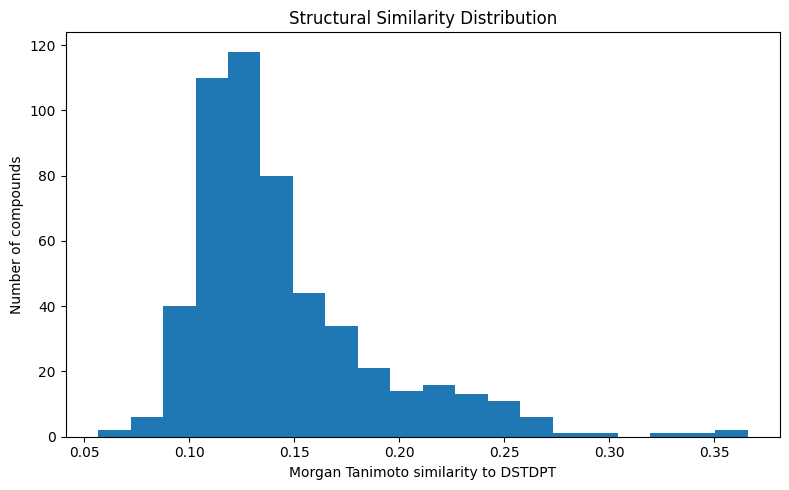

In [ ]:
plt.figure(
    figsize=(8,5)
)

plt.hist(
    combined["Similarity_to_DSTDPT"],
    bins=20
)

plt.xlabel(
    "Morgan Tanimoto similarity to DSTDPT"
)

plt.ylabel(
    "Number of compounds"
)

plt.title(
    "Structural Similarity Distribution"
)

plt.tight_layout()

plt.show()

In [ ]:
df_candidates = combined.copy()

print(
    "Candidate pool:",
    len(df_candidates)
)

if len(df_candidates) == 0:
    raise ValueError(
        "Candidate pool is empty."
    )

mols = df_candidates[
    "Mol"
].tolist()

fps = [
    fpgen.GetFingerprint(m)
    for m in mols
]

picker = MaxMinPicker()


def distance(i, j):

    similarity = (
        DataStructs.TanimotoSimilarity(
            fps[i],
            fps[j]
        )
    )

    return 1 - similarity


n_select = min(
    100,
    len(mols)
)

picked_indices = picker.LazyPick(
    distance,
    len(mols),
    n_select,
    seed=42
)

picked_indices = list(
    picked_indices
)

df_selected = (
    df_candidates
    .iloc[picked_indices]
    .copy()
)

df_selected.reset_index(
    drop=True,
    inplace=True
)

print(
    "Selected molecules:",
    len(df_selected)
)

Candidate pool: 521
Selected molecules: 100


In [ ]:
print("Number of selected molecules:", len(df_selected))

print("\nSimilarity statistics:")
print(
    df_selected["Similarity_to_DSTDPT"].describe()
)

print("\nHighest similarity:")
print(
    df_selected["Similarity_to_DSTDPT"].max()
)

print("\nLowest similarity:")
print(
    df_selected["Similarity_to_DSTDPT"].min()
)

print("\nDuplicate structures:")
print(
    df_selected["Canonical_RDKit_SMILES"].duplicated().sum()
)

Number of selected molecules: 100

Similarity statistics:
count    100.000000
mean       0.144433
std        0.043663
min        0.067797
25%        0.116648
50%        0.132382
75%        0.163996
max        0.292308
Name: Similarity_to_DSTDPT, dtype: float64

Highest similarity:
0.2923076923076923

Lowest similarity:
0.06779661016949153

Duplicate structures:
0


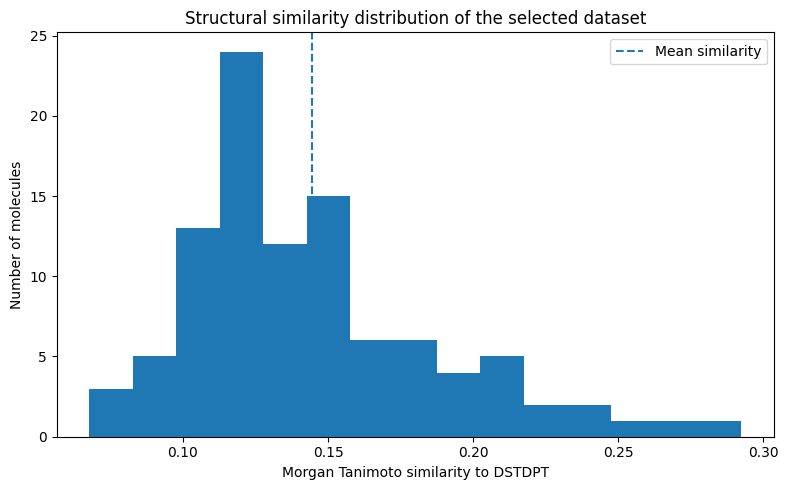

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    df_selected["Similarity_to_DSTDPT"],
    bins=15
)

plt.axvline(
    df_selected["Similarity_to_DSTDPT"].mean(),
    linestyle="--",
    label="Mean similarity"
)

plt.xlabel(
    "Morgan Tanimoto similarity to DSTDPT"
)

plt.ylabel(
    "Number of molecules"
)

plt.title(
    "Structural similarity distribution of the selected dataset"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "Figure_Similarity_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
dstdpt_canonical = Chem.MolToSmiles(
    mol_dstdpt
)

print(
    "DSTDPT canonical SMILES:"
)
print(dstdpt_canonical)

print(
    "\nIs DSTDPT already in selected dataset?"
)

print(
    dstdpt_canonical
    in
    df_selected[
        "Canonical_RDKit_SMILES"
    ].values
)

DSTDPT canonical SMILES:
Cn1c(/N=N/c2nnc(S)s2)c(O)c(=O)n(C)c1=O

Is DSTDPT already in selected dataset?
False


In [ ]:
df_selected.to_csv(
    "DSTDPT_100_Selected_Molecules.csv",
    index=False
)

df_selected.to_excel(
    "DSTDPT_100_Selected_Molecules.xlsx",
    index=False
)

print(
    "100-molecule dataset saved successfully."
)

100-molecule dataset saved successfully.


In [ ]:
df_selected = df_selected.reset_index(
    drop=True
)

df_selected["Molecule_ID"] = [
    f"M{i+1:03d}"
    for i in range(
        len(df_selected)
    )
]

display(
    df_selected[
        [
            "Molecule_ID",
            "CID",
            "IUPACName",
            "Similarity_to_DSTDPT"
        ]
    ].head(10)
)

,Molecule_ID,CID,IUPACName,Similarity_to_DSTDPT
0,M001,108713,"3,9-dimethyl-7H-purine-2,6,8-trione",0.142857
1,M002,11966600,2-[2-[bis(carboxymethyl)amino]ethyl-[2-[carbox...,0.093333
2,M003,62707525,"1-[5-(4-piperidin-1-ylpiperidin-1-yl)-1,3,4-th...",0.123077
3,M004,135432761,"1,3-diethyl-6-hydroxy-5-[(E)-morpholin-4-ylimi...",0.151515
4,M005,4883454,"1-(2,6-dimethylmorpholin-4-yl)-2-(1-methyltetr...",0.119403
5,M006,136614402,4-hydroxy-5-[[5-[methyl(sulfanylmethyl)amino]-...,0.269841
6,M007,5301220,"5-hydroxy-11,11-dimethyl-5-(trifluoromethyl)-1...",0.117647
7,M008,9991285,"6,8-diethyl-[1,3,4]thiadiazolo[3,2-a]pyrimidin...",0.111111
8,M009,11680904,"(2S)-2-amino-3-[2,4-dioxo-3-[2-(2H-tetrazol-5-...",0.123288
9,M010,661591,"N-[(3,4-dimethyl-2-sulfanylidene-1,3-thiazol-5...",0.178571


In [ ]:
descriptor_functions = {

    "MolWt":
        Descriptors.MolWt,

    "MolLogP":
        Crippen.MolLogP,

    "TPSA":
        rdMolDescriptors.CalcTPSA,

    "HBD":
        Lipinski.NumHDonors,

    "HBA":
        Lipinski.NumHAcceptors,

    "RotatableBonds":
        Lipinski.NumRotatableBonds,

    "HeavyAtomCount":
        Lipinski.HeavyAtomCount,

    "RingCount":
        Lipinski.RingCount,

    "AromaticRingCount":
        rdMolDescriptors.CalcNumAromaticRings,

    "AliphaticRingCount":
        rdMolDescriptors.CalcNumAliphaticRings,

    "FractionCSP3":
        rdMolDescriptors.CalcFractionCSP3,

    "MolMR":
        Crippen.MolMR,

    "NumAtoms":
        lambda m: m.GetNumAtoms(),

    "NumBonds":
        lambda m: m.GetNumBonds(),

    "NumHeteroAtoms":
        Lipinski.NumHeteroatoms
}


for name, function in descriptor_functions.items():

    df_selected[name] = (
        df_selected["Mol"]
        .apply(function)
    )

print(
    "Descriptor calculation completed."
)

display(
    df_selected[
        [
            "Molecule_ID",
            "MolWt",
            "MolLogP",
            "TPSA",
            "HBD",
            "HBA",
            "RotatableBonds"
        ]
    ].head()
)

Descriptor calculation completed.


,Molecule_ID,MolWt,MolLogP,TPSA,HBD,HBA,RotatableBonds
0,M001,196.166,-1.74640,92.65,2,3,0
1,M002,626.627,-4.12530,303.06,7,14,21
2,M003,349.504,2.50970,52.57,0,6,3
3,M004,312.395,0.79079,71.99,1,6,4
4,M005,285.373,0.32650,73.14,0,6,3


In [ ]:
SMARTS = {

    "Azo":
        "[N]=[N]",

    "Hydroxyl":
        "[OX2H]",

    "Carbonyl":
        "[CX3]=[OX1]",

    "Thiocarbonyl":
        "[CX3]=[SX1]",

    "Sulfur":
        "[#16]",

    "Thiadiazole":
        "n1nccs1"
}

patterns = {
    name: Chem.MolFromSmarts(smarts)
    for name, smarts in SMARTS.items()
}

for name, pattern in patterns.items():

    df_selected[
        name + "_Count"
    ] = (
        df_selected["Mol"]
        .apply(
            lambda m:
            len(
                m.GetSubstructMatches(
                    pattern
                )
            )
        )
    )

print("Structure-specific descriptors added.")

Structure-specific descriptors added.


In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem

def generate_3d(mol):

    mol = Chem.AddHs(
        Chem.Mol(mol)
    )

    params = AllChem.ETKDGv3()
    params.randomSeed = 42

    status = AllChem.EmbedMolecule(
        mol,
        params
    )

    if status != 0:
        return None

    try:
        AllChem.MMFFOptimizeMolecule(mol)
    except:
        pass

    return mol


df_selected["Mol3D"] = (
    df_selected["Mol"]
    .apply(generate_3d)
)

print(
    "Total molecules:",
    len(df_selected)
)

print(
    "Successful 3-D structures:",
    df_selected["Mol3D"].notna().sum()
)

print(
    "Failed 3-D structures:",
    df_selected["Mol3D"].isna().sum()
)

Total molecules: 100
Successful 3-D structures: 100
Failed 3-D structures: 0


In [ ]:
import os

XTB_ROOT = "DSTDPT_xTB"

os.makedirs(
    XTB_ROOT,
    exist_ok=True
)

print(
    "xTB directory created:",
    XTB_ROOT
)

xTB directory created: DSTDPT_xTB


In [ ]:
def write_xyz(
    mol,
    filename
):

    conf = mol.GetConformer()

    with open(
        filename,
        "w"
    ) as f:

        f.write(
            f"{mol.GetNumAtoms()}\n"
        )

        f.write(
            "DSTDPT related molecule\n"
        )

        for atom in mol.GetAtoms():

            idx = atom.GetIdx()

            pos = conf.GetAtomPosition(
                idx
            )

            f.write(
                f"{atom.GetSymbol()} "
                f"{pos.x:.8f} "
                f"{pos.y:.8f} "
                f"{pos.z:.8f}\n"
            )


for _, row in df_selected.iterrows():

    molecule_id = row["Molecule_ID"]

    filename = os.path.join(
        XTB_ROOT,
        molecule_id + ".xyz"
    )

    write_xyz(
        row["Mol3D"],
        filename
    )

print(
    "XYZ files generated:",
    len(
        [
            f for f in os.listdir(XTB_ROOT)
            if f.endswith(".xyz")
        ]
    )
)

XYZ files generated: 100


In [ ]:
# Download xTB
!wget -q https://github.com/grimme-lab/xtb/releases/download/v6.7.1/xtb-6.7.1-linux-x86_64.tar.xz

# Extract
!tar -xf xtb-6.7.1-linux-x86_64.tar.xz

# Find where xtb was extracted
!find . -type f -name "xtb" -executable

./xtb-dist/bin/xtb


In [ ]:
import os

# Locate the extracted xTB directory
xtb_base = os.path.abspath("xtb-6.7.1")

xtb_bin = os.path.join(
    xtb_base,
    "bin"
)

# Add xTB executable directory to PATH
os.environ["PATH"] = (
    xtb_bin
    + os.pathsep
    + os.environ["PATH"]
)

# Set XTBHOME
os.environ["XTBHOME"] = xtb_base

print("XTBHOME:")
print(os.environ["XTBHOME"])

print("\nPATH contains xTB:")
print(xtb_bin in os.environ["PATH"])

XTBHOME:
/content/xtb-6.7.1

PATH contains xTB:
True


In [ ]:
import os
import shutil
import glob

# Remove previous incomplete installation
for path in [
    "xtb-6.7.1",
    "xtb-6.7.1-linux-x86_64.tar.xz"
]:
    if os.path.isdir(path):
        shutil.rmtree(path)
    elif os.path.isfile(path):
        os.remove(path)

print("Previous xTB installation cleaned.")

Previous xTB installation cleaned.


In [ ]:
!wget -q --show-progress \
https://github.com/grimme-lab/xtb/releases/download/v6.7.1/xtb-6.7.1-linux-x86_64.tar.xz

xtb-6.7.1-linux-x86 100%[===================>]  25.87M  --.-KB/s    in 0.1s    


In [ ]:
import os

archive = "xtb-6.7.1-linux-x86_64.tar.xz"

print(
    "Archive exists:",
    os.path.exists(archive)
)

if os.path.exists(archive):
    print(
        "File size:",
        round(
            os.path.getsize(archive) / 1024**2,
            2
        ),
        "MB"
    )

Archive exists: True
File size: 25.87 MB


In [ ]:
!tar -xJf xtb-6.7.1-linux-x86_64.tar.xz

print("Searching for xTB executable...")
!find /content -type f -name "xtb" -executable 2>/dev/null

Searching for xTB executable...
/content/xtb-dist/bin/xtb


In [ ]:
import glob
import os

xtb_candidates = glob.glob(
    "/content/**/bin/xtb",
    recursive=True
)

print("xTB executables found:")

for path in xtb_candidates:
    print(path)

if len(xtb_candidates) == 0:
    raise FileNotFoundError(
        "xTB executable was not found after extraction."
    )

XTB_EXECUTABLE = os.path.abspath(
    xtb_candidates[0]
)

print(
    "\nUsing xTB:",
    XTB_EXECUTABLE
)

xTB executables found:
/content/xtb-dist/bin/xtb

Using xTB: /content/xtb-dist/bin/xtb


In [ ]:
import subprocess

result = subprocess.run(
    [
        XTB_EXECUTABLE,
        "--version"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print(result.stdout)

      -----------------------------------------------------------      
     |                   =====================                   |     
     |                           x T B                           |     
     |                   =====================                   |     
     |                         S. Grimme                         |     
     |          Mulliken Center for Theoretical Chemistry        |     
     |                    University of Bonn                     |     
      -----------------------------------------------------------      

   * xtb version 6.7.1 (edcfbbe) compiled by 'albert@albert-system' on 2024-07-22

normal termination of xtb



In [ ]:
import os

xtb_bin = os.path.dirname(
    XTB_EXECUTABLE
)

os.environ["PATH"] = (
    xtb_bin
    + os.pathsep
    + os.environ["PATH"]
)

os.environ["XTBHOME"] = os.path.dirname(
    xtb_bin
)

print(
    "xTB binary:",
    XTB_EXECUTABLE
)

print(
    "xTB directory:",
    xtb_bin
)

xTB binary: /content/xtb-dist/bin/xtb
xTB directory: /content/xtb-dist/bin


In [ ]:
import shutil

print(
    "PATH lookup:",
    shutil.which("xtb")
)

PATH lookup: /content/xtb-dist/bin/xtb


In [ ]:
result = subprocess.run(
    ["xtb", "--version"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print(result.stdout)

      -----------------------------------------------------------      
     |                   =====================                   |     
     |                           x T B                           |     
     |                   =====================                   |     
     |                         S. Grimme                         |     
     |          Mulliken Center for Theoretical Chemistry        |     
     |                    University of Bonn                     |     
      -----------------------------------------------------------      

   * xtb version 6.7.1 (edcfbbe) compiled by 'albert@albert-system' on 2024-07-22

normal termination of xtb



In [ ]:
test_id = df_selected.iloc[0]["Molecule_ID"]

test_xyz = os.path.join(
    XTB_ROOT,
    test_id + ".xyz"
)

test_folder = os.path.dirname(test_xyz)
test_file = os.path.basename(test_xyz)

command = [
    XTB_EXECUTABLE,
    test_file,
    "--gfn2",
    "--opt"
]

print("Running xTB for:", test_id)

result = subprocess.run(
    command,
    cwd=test_folder,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    timeout=600
)

print(result.stdout[-5000:])

Running xTB for: M001
          14 O    0.168
    13   6 C    3.957 --    14 O    1.627    12 N    1.181     2 N    1.056
    14   8 O    1.992 --    13 C    1.627    12 N    0.168     2 N    0.137
    15   1 H    0.995 --     1 C    0.974
    16   1 H    0.995 --     1 C    0.974
    17   1 H    0.989 --     1 C    0.967
    18   1 H    0.948 --     7 N    0.917
    19   1 H    0.994 --    11 C    0.975
    20   1 H    0.994 --    11 C    0.975
    21   1 H    0.988 --    11 C    0.967
    22   1 H    0.955 --    12 N    0.928
 ---------------------------------------------------------------------------

Topologies differ in total number of bonds
Writing topology from bond orders to xtbtopo.mol

molecular dipole:
                 x           y           z       tot (Debye)
 q only:       -1.745       0.157      -0.239
   full:       -1.676       0.219      -0.226       4.335
molecular quadrupole (traceless):
                xx          xy          yy          xz          yz          zz

In [ ]:
import re
import numpy as np

def extract_gap(output):

    # Look for the HOMO-LUMO GAP line printed by xTB
    patterns = [
        r"HOMO-LUMO GAP\s+([0-9.]+)\s+eV",
        r"HOMO-LUMO GAP\s*[:=]?\s*([0-9.]+)",
        r"HOMO-LUMO\s+GAP\s+([0-9.]+)"
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            output,
            re.IGNORECASE
        )

        if match:
            return float(match.group(1))

    return np.nan

In [ ]:
test_gap = extract_gap(
    result.stdout
)

print(
    "Molecule:",
    test_id
)

print(
    "HOMO–LUMO gap:",
    test_gap,
    "eV"
)

Molecule: M001
HOMO–LUMO gap: 3.254739880558 eV


In [ ]:
import os
import subprocess
import pandas as pd
import numpy as np
import re
import time

results = []

for idx, row in df_selected.iterrows():

    molecule_id = row["Molecule_ID"]

    xyz_file = os.path.join(
        XTB_ROOT,
        molecule_id + ".xyz"
    )

    print(
        f"[{idx+1}/{len(df_selected)}] "
        f"Running xTB for {molecule_id}..."
    )

    if not os.path.exists(xyz_file):

        results.append({
            "Molecule_ID": molecule_id,
            "HOMO_LUMO_Gap_eV": np.nan,
            "Status": "XYZ file missing"
        })

        continue

    try:

        command = [
            XTB_EXECUTABLE,
            os.path.basename(xyz_file),
            "--gfn2",
            "--opt"
        ]

        result = subprocess.run(
            command,
            cwd=XTB_ROOT,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            timeout=600
        )

        gap = extract_gap(
            result.stdout
        )

        if np.isnan(gap):

            status = "Completed but gap not extracted"

        else:

            status = "Success"

        results.append({

            "Molecule_ID":
                molecule_id,

            "HOMO_LUMO_Gap_eV":
                gap,

            "Status":
                status
        })

    except subprocess.TimeoutExpired:

        results.append({

            "Molecule_ID":
                molecule_id,

            "HOMO_LUMO_Gap_eV":
                np.nan,

            "Status":
                "Timeout"
        })

    except Exception as e:

        results.append({

            "Molecule_ID":
                molecule_id,

            "HOMO_LUMO_Gap_eV":
                np.nan,

            "Status":
                str(e)
        })

    time.sleep(0.2)


xtb_results = pd.DataFrame(
    results
)

print("\nCalculation completed.")

print(
    xtb_results["Status"]
    .value_counts()
)

[1/100] Running xTB for M001...
[2/100] Running xTB for M002...
[3/100] Running xTB for M003...
[4/100] Running xTB for M004...
[5/100] Running xTB for M005...
[6/100] Running xTB for M006...
[7/100] Running xTB for M007...
[8/100] Running xTB for M008...
[9/100] Running xTB for M009...
[10/100] Running xTB for M010...
[11/100] Running xTB for M011...
[12/100] Running xTB for M012...
[13/100] Running xTB for M013...
[14/100] Running xTB for M014...
[15/100] Running xTB for M015...
[16/100] Running xTB for M016...
[17/100] Running xTB for M017...
[18/100] Running xTB for M018...
[19/100] Running xTB for M019...
[20/100] Running xTB for M020...
[21/100] Running xTB for M021...
[22/100] Running xTB for M022...
[23/100] Running xTB for M023...
[24/100] Running xTB for M024...
[25/100] Running xTB for M025...
[26/100] Running xTB for M026...
[27/100] Running xTB for M027...
[28/100] Running xTB for M028...
[29/100] Running xTB for M029...
[30/100] Running xTB for M030...
[31/100] Running xT

In [ ]:
df_ml = df_selected.merge(
    xtb_results,
    on="Molecule_ID",
    how="left"
)

print(
    "Final dataset shape:",
    df_ml.shape
)

display(
    df_ml[
        [
            "Molecule_ID",
            "CID",
            "Similarity_to_DSTDPT",
            "HOMO_LUMO_Gap_eV",
            "Status"
        ]
    ].head(20)
)

Final dataset shape: (100, 40)


,Molecule_ID,CID,Similarity_to_DSTDPT,HOMO_LUMO_Gap_eV,Status
0,M001,108713,0.142857,3.254720,Success
1,M002,11966600,0.093333,1.034626,Success
2,M003,62707525,0.123077,2.431936,Success
3,M004,135432761,0.151515,1.947331,Success
4,M005,4883454,0.119403,3.082779,Success
5,M006,136614402,0.269841,0.778448,Success
6,M007,5301220,0.117647,2.296128,Success
7,M008,9991285,0.111111,0.236862,Success
8,M009,11680904,0.123288,3.085571,Success
9,M010,661591,0.178571,1.578258,Success


In [ ]:
print(
    "Total molecules:",
    len(df_ml)
)

print(
    "Successful xTB calculations:",
    df_ml[
        "HOMO_LUMO_Gap_eV"
    ].notna().sum()
)

print(
    "Failed/missing gaps:",
    df_ml[
        "HOMO_LUMO_Gap_eV"
    ].isna().sum()
)

Total molecules: 100
Successful xTB calculations: 100
Failed/missing gaps: 0


In [ ]:
df_ml.to_csv(
    "DSTDPT_xTB_ML_Dataset.csv",
    index=False
)

df_ml.to_excel(
    "DSTDPT_xTB_ML_Dataset.xlsx",
    index=False
)

print(
    "Final computational dataset saved."
)

Final computational dataset saved.


In [ ]:
print("Dataset shape:", df_ml.shape)

print("\nColumns:")
for i, col in enumerate(df_ml.columns, 1):
    print(i, col)

print("\nMissing values:")
print(
    df_ml.isna().sum()
    .sort_values(ascending=False)
    .head(20)
)

Dataset shape: (100, 40)

Columns:
1 CID
2 MolecularFormula
3 MolecularWeight
4 SMILES
5 ConnectivitySMILES
6 InChIKey
7 IUPACName
8 XLogP
9 TPSA
10 HBondDonorCount
11 HBondAcceptorCount
12 RotatableBondCount
13 HeavyAtomCount
14 Mol
15 Canonical_RDKit_SMILES
16 Acceptable
17 Similarity_to_DSTDPT
18 Molecule_ID
19 MolWt
20 MolLogP
21 HBD
22 HBA
23 RotatableBonds
24 RingCount
25 AromaticRingCount
26 AliphaticRingCount
27 FractionCSP3
28 MolMR
29 NumAtoms
30 NumBonds
31 NumHeteroAtoms
32 Azo_Count
33 Hydroxyl_Count
34 Carbonyl_Count
35 Thiocarbonyl_Count
36 Sulfur_Count
37 Thiadiazole_Count
38 Mol3D
39 HOMO_LUMO_Gap_eV
40 Status

Missing values:
CID                       0
MolecularFormula          0
MolecularWeight           0
SMILES                    0
ConnectivitySMILES        0
InChIKey                  0
IUPACName                 0
XLogP                     0
TPSA                      0
HBondDonorCount           0
HBondAcceptorCount        0
RotatableBondCount        0
HeavyAtomCou

In [ ]:
display(
    df_ml[
        [
            "Molecule_ID",
            "CID",
            "Similarity_to_DSTDPT",
            "HOMO_LUMO_Gap_eV"
        ]
    ].head(20)
)

,Molecule_ID,CID,Similarity_to_DSTDPT,HOMO_LUMO_Gap_eV
0,M001,108713,0.142857,3.254720
1,M002,11966600,0.093333,1.034626
2,M003,62707525,0.123077,2.431936
3,M004,135432761,0.151515,1.947331
4,M005,4883454,0.119403,3.082779
5,M006,136614402,0.269841,0.778448
6,M007,5301220,0.117647,2.296128
7,M008,9991285,0.111111,0.236862
8,M009,11680904,0.123288,3.085571
9,M010,661591,0.178571,1.578258


In [ ]:
target = "HOMO_LUMO_Gap_eV"

print("Target-property statistics:")
print(
    df_ml[target].describe()
)

Target-property statistics:
count    100.000000
mean       2.459487
std        0.802888
min        0.236862
25%        2.040465
50%        2.577145
75%        3.084001
max        3.880939
Name: HOMO_LUMO_Gap_eV, dtype: float64


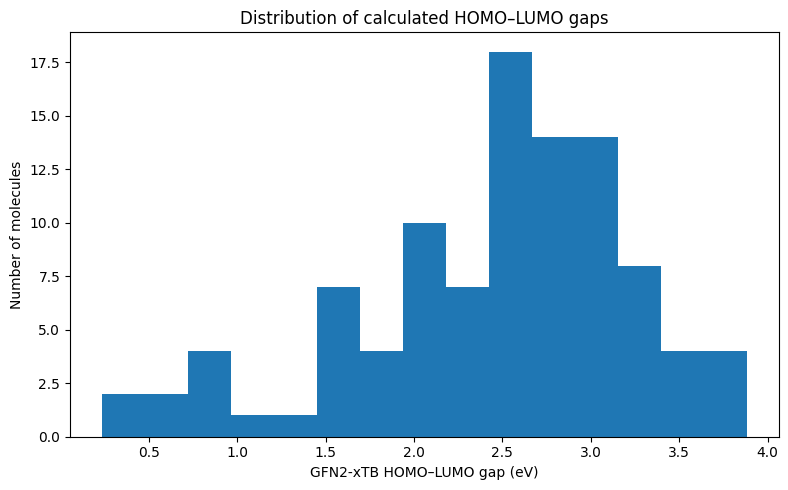

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    df_ml[target],
    bins=15
)

plt.xlabel(
    "GFN2-xTB HOMO–LUMO gap (eV)"
)

plt.ylabel(
    "Number of molecules"
)

plt.title(
    "Distribution of calculated HOMO–LUMO gaps"
)

plt.tight_layout()

plt.savefig(
    "Figure_Target_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np

exclude_columns = [
    "Molecule_ID",
    "CID",
    "IUPACName",
    "CanonicalSMILES",
    "IsomericSMILES",
    "Canonical_RDKit_SMILES",
    "Mol",
    "Mol3D",
    "Status",
    "HOMO_LUMO_Gap_eV"
]

descriptor_columns = [
    col
    for col in df_ml.columns
    if col not in exclude_columns
    and pd.api.types.is_numeric_dtype(
        df_ml[col]
    )
]

print(
    "Number of descriptor variables:",
    len(descriptor_columns)
)

print(
    descriptor_columns
)

Number of descriptor variables: 27
['XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount', 'Acceptable', 'Similarity_to_DSTDPT', 'MolWt', 'MolLogP', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'AromaticRingCount', 'AliphaticRingCount', 'FractionCSP3', 'MolMR', 'NumAtoms', 'NumBonds', 'NumHeteroAtoms', 'Azo_Count', 'Hydroxyl_Count', 'Carbonyl_Count', 'Thiocarbonyl_Count', 'Sulfur_Count', 'Thiadiazole_Count']


In [ ]:
from sklearn.feature_selection import VarianceThreshold

X_initial = df_ml[
    descriptor_columns
].copy()

selector = VarianceThreshold(
    threshold=0.0
)

X_var = selector.fit_transform(
    X_initial
)

variance_features = (
    X_initial.columns[
        selector.get_support()
    ]
)

X_var = pd.DataFrame(
    X_var,
    columns=variance_features,
    index=df_ml.index
)

print(
    "Descriptors before variance filtering:",
    X_initial.shape[1]
)

print(
    "Descriptors after variance filtering:",
    X_var.shape[1]
)

removed_variance = [
    col for col in descriptor_columns
    if col not in variance_features
]

print(
    "Removed zero-variance descriptors:",
    removed_variance
)

Descriptors before variance filtering: 27
Descriptors after variance filtering: 25
Removed zero-variance descriptors: ['Acceptable', 'Thiadiazole_Count']


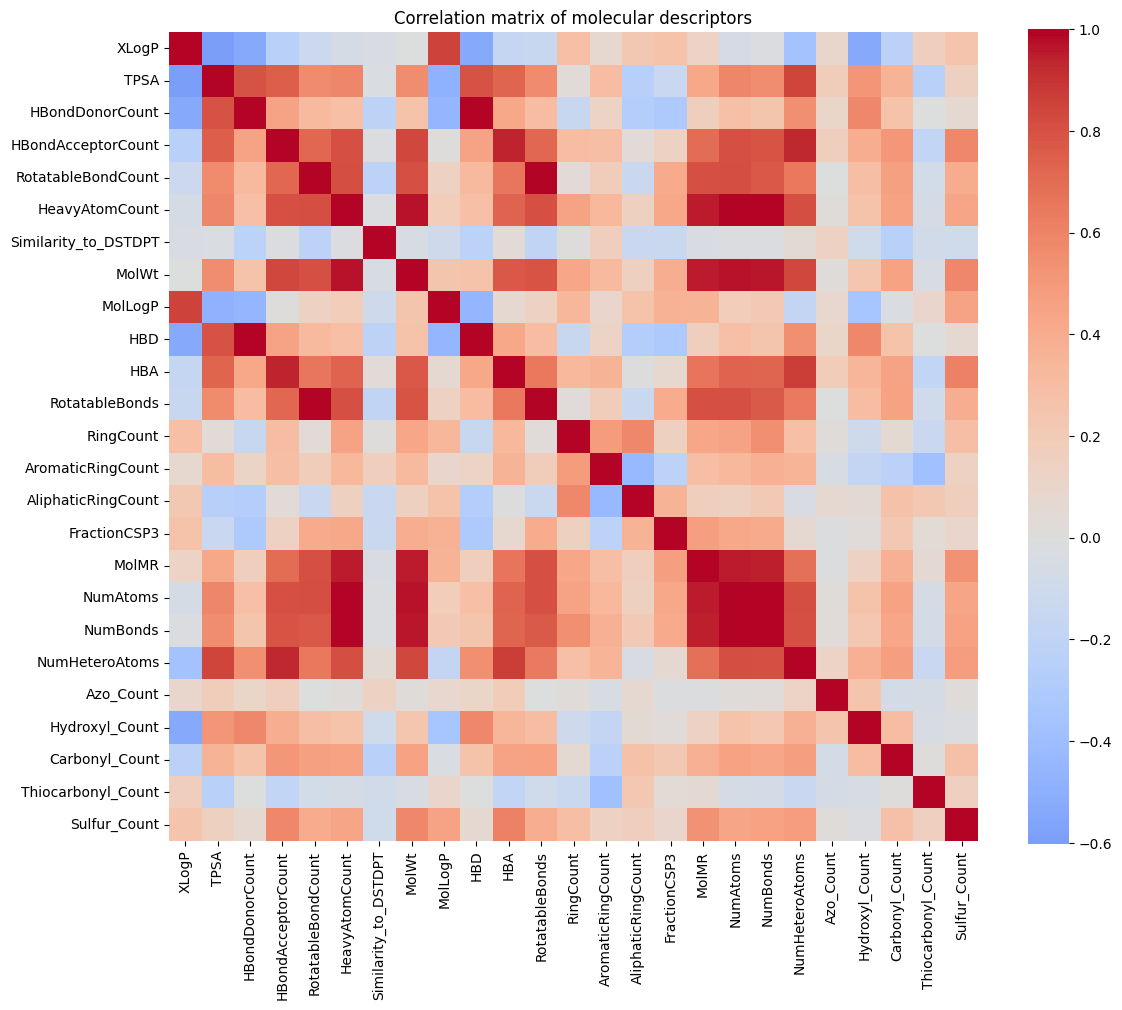

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = X_var.corr()

plt.figure(
    figsize=(12,10)
)

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Correlation matrix of molecular descriptors"
)

plt.tight_layout()

plt.savefig(
    "Figure_2_Correlation_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

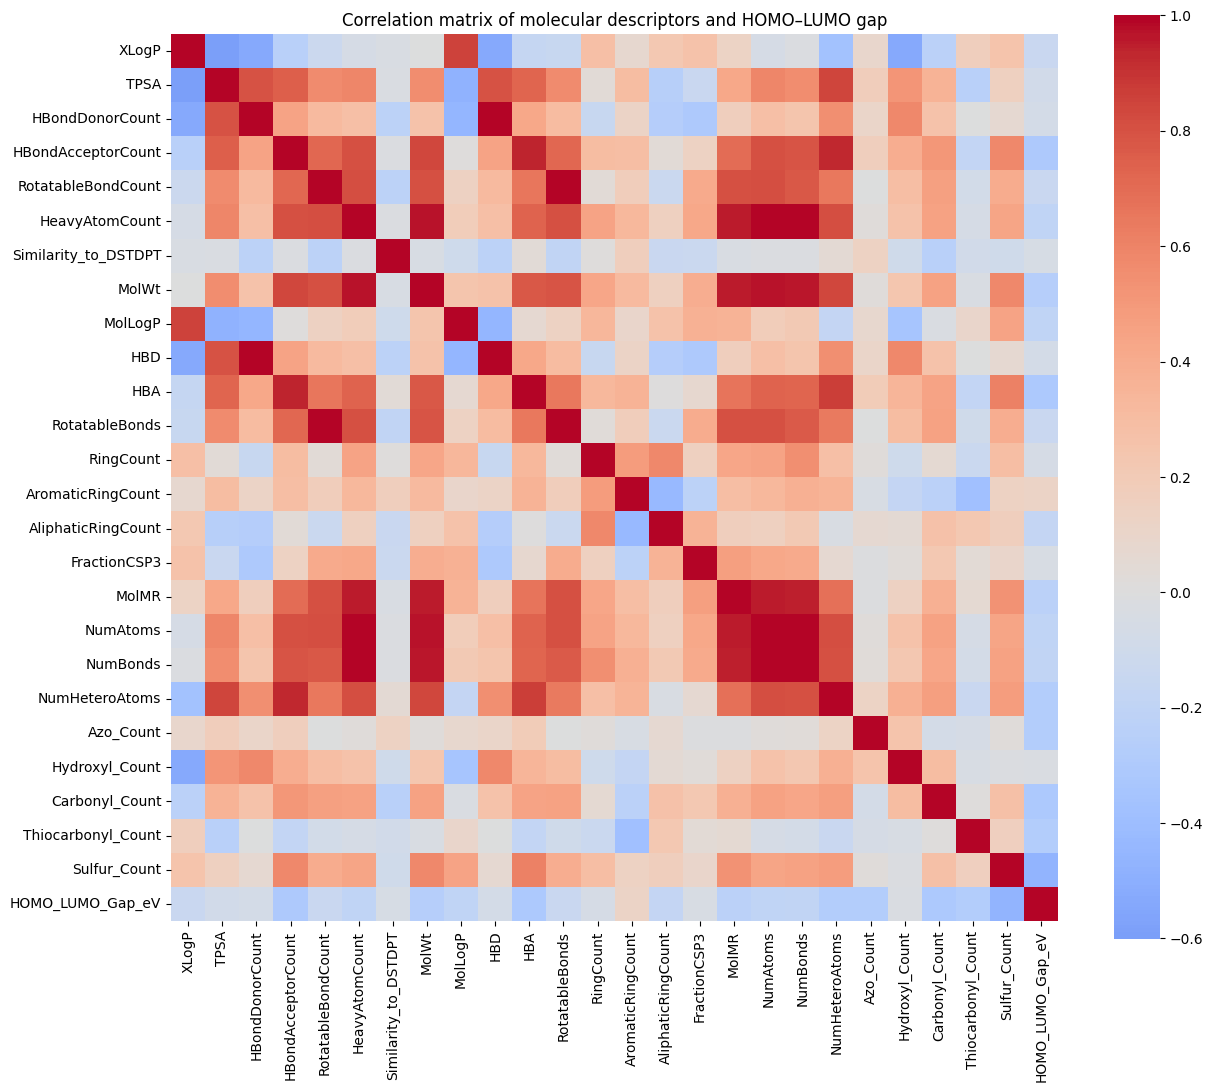

In [ ]:
corr_data = pd.concat(
    [
        X_var,
        df_ml[[target]]
    ],
    axis=1
)

corr_matrix = corr_data.corr()

plt.figure(
    figsize=(13,11)
)

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Correlation matrix of molecular descriptors and HOMO–LUMO gap"
)

plt.tight_layout()

plt.savefig(
    "Figure_2_Correlation_Matrix_Target.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Explicitly remove duplicate/redundant descriptor definitions

remove_descriptors = [
    "HBondDonorCount",
    "HBondAcceptorCount",
    "RotatableBondCount"
]

# Similarity is useful for chemical-space analysis,
# but should NOT be used as an ML predictor for DSTDPT.

remove_descriptors += [
    "Similarity_to_DSTDPT"
]

descriptor_for_ml = [
    col
    for col in X_var.columns
    if col not in remove_descriptors
]

X_clean = X_var[
    descriptor_for_ml
].copy()

print("Descriptors before cleaning:", X_var.shape[1])
print("Descriptors after cleaning:", X_clean.shape[1])

print("\nDescriptors retained for ML:")
print(descriptor_for_ml)

print("\nDescriptors removed:")
print(remove_descriptors)

Descriptors before cleaning: 25
Descriptors after cleaning: 21

Descriptors retained for ML:
['XLogP', 'TPSA', 'HeavyAtomCount', 'MolWt', 'MolLogP', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'AromaticRingCount', 'AliphaticRingCount', 'FractionCSP3', 'MolMR', 'NumAtoms', 'NumBonds', 'NumHeteroAtoms', 'Azo_Count', 'Hydroxyl_Count', 'Carbonyl_Count', 'Thiocarbonyl_Count', 'Sulfur_Count']

Descriptors removed:
['HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'Similarity_to_DSTDPT']


In [ ]:
import numpy as np

corr = X_clean.corr().abs()

upper = corr.where(
    np.triu(
        np.ones(corr.shape),
        k=1
    ).astype(bool)
)

high_corr_features = [
    column
    for column in upper.columns
    if any(
        upper[column] >= 0.90
    )
]

print(
    "Highly correlated descriptors:",
    high_corr_features
)

Highly correlated descriptors: ['MolWt', 'MolMR', 'NumAtoms', 'NumBonds']


In [ ]:
X_filtered = X_clean.drop(
    columns=high_corr_features
)

print(
    "Descriptors after correlation filtering:",
    X_filtered.shape[1]
)

print(
    "\nFinal descriptor list:"
)

for i, col in enumerate(
    X_filtered.columns,
    1
):
    print(
        i,
        col
    )

Descriptors after correlation filtering: 17

Final descriptor list:
1 XLogP
2 TPSA
3 HeavyAtomCount
4 MolLogP
5 HBD
6 HBA
7 RotatableBonds
8 RingCount
9 AromaticRingCount
10 AliphaticRingCount
11 FractionCSP3
12 NumHeteroAtoms
13 Azo_Count
14 Hydroxyl_Count
15 Carbonyl_Count
16 Thiocarbonyl_Count
17 Sulfur_Count


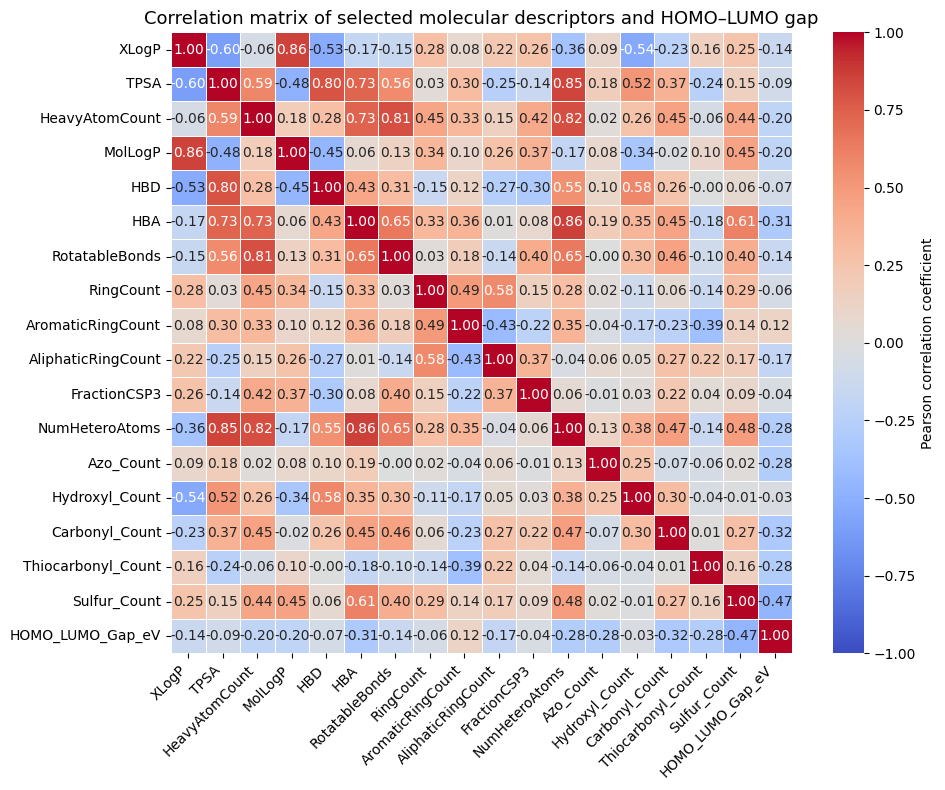

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_for_figure = pd.concat(
    [
        X_filtered,
        df_ml[[target]]
    ],
    axis=1
)

corr_matrix_final = (
    corr_for_figure.corr()
)

plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    corr_matrix_final,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson correlation coefficient"
    }
)

plt.title(
    "Correlation matrix of selected molecular descriptors and HOMO–LUMO gap",
    fontsize=13
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    "Figure_2_Final_Correlation_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Target
y = df_ml["HOMO_LUMO_Gap_eV"].copy()

# Descriptor matrix after correlation filtering
X = X_filtered.copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

# 80:20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining molecules:", len(X_train))
print("Testing molecules:", len(X_test))

X shape: (100, 17)
y shape: (100,)

Training molecules: 80
Testing molecules: 20


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.inspection import permutation_importance

model_fs = ExtraTreesRegressor(
    n_estimators=500,
    random_state=42,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1
)

model_fs.fit(
    X_train,
    y_train
)

# Permutation importance performed ONLY on training data
perm = permutation_importance(
    model_fs,
    X_train,
    y_train,
    n_repeats=20,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_STD": perm.importances_std
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance)

,Feature,Importance_Mean,Importance_STD
0,Sulfur_Count,0.200675,0.025064
1,Carbonyl_Count,0.081020,0.013902
2,Azo_Count,0.066487,0.010600
3,HBA,0.062017,0.006671
4,RotatableBonds,0.051760,0.008279
5,MolLogP,0.049573,0.006312
6,NumHeteroAtoms,0.049197,0.007096
7,RingCount,0.046481,0.009364
8,HeavyAtomCount,0.042084,0.005305
9,AliphaticRingCount,0.041241,0.011776


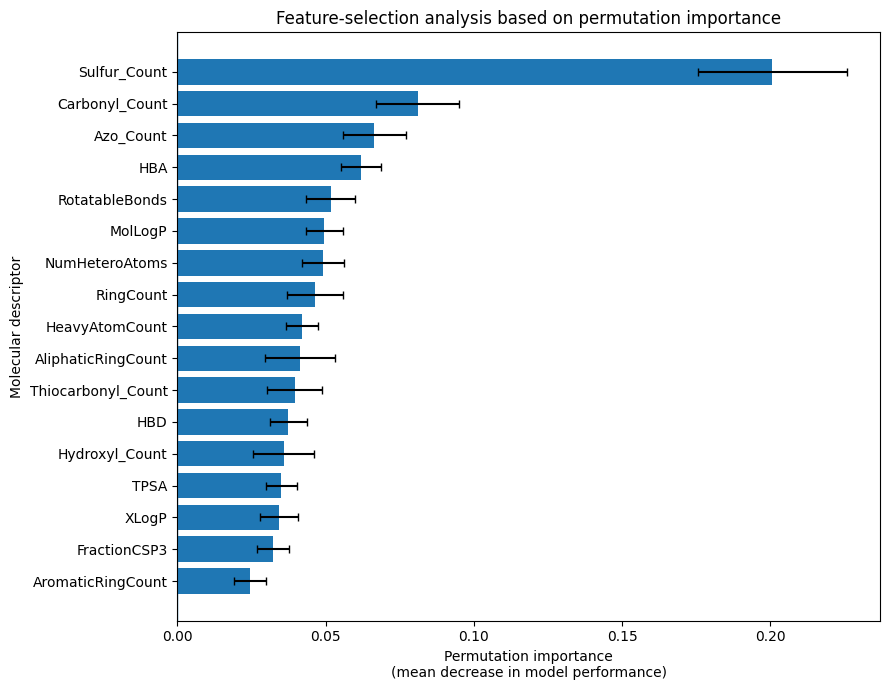

In [ ]:
import matplotlib.pyplot as plt

# Sort for plotting
plot_data = feature_importance.sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    plot_data["Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_STD"],
    capsize=3
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Permutation importance\n(mean decrease in model performance)"
)

plt.ylabel(
    "Molecular descriptor"
)

plt.title(
    "Feature-selection analysis based on permutation importance"
)

plt.tight_layout()

plt.savefig(
    "Figure_3_Feature_Selection.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print(
    feature_importance.to_string(
        index=False
    )
)

           Feature  Importance_Mean  Importance_STD
      Sulfur_Count         0.200675        0.025064
    Carbonyl_Count         0.081020        0.013902
         Azo_Count         0.066487        0.010600
               HBA         0.062017        0.006671
    RotatableBonds         0.051760        0.008279
           MolLogP         0.049573        0.006312
    NumHeteroAtoms         0.049197        0.007096
         RingCount         0.046481        0.009364
    HeavyAtomCount         0.042084        0.005305
AliphaticRingCount         0.041241        0.011776
Thiocarbonyl_Count         0.039516        0.009208
               HBD         0.037393        0.006166
    Hydroxyl_Count         0.035850        0.010362
              TPSA         0.035035        0.005287
             XLogP         0.034234        0.006393
      FractionCSP3         0.032146        0.005363
 AromaticRingCount         0.024359        0.005420


In [ ]:
positive_features = feature_importance.loc[
    feature_importance["Importance_Mean"] > 0,
    "Feature"
].tolist()

print(
    "Descriptors with positive permutation importance:"
)

for feature in positive_features:
    print("-", feature)

Descriptors with positive permutation importance:
- Sulfur_Count
- Carbonyl_Count
- Azo_Count
- HBA
- RotatableBonds
- MolLogP
- NumHeteroAtoms
- RingCount
- HeavyAtomCount
- AliphaticRingCount
- Thiocarbonyl_Count
- HBD
- Hydroxyl_Count
- TPSA
- XLogP
- FractionCSP3
- AromaticRingCount


In [ ]:
n_features = min(
    8,
    len(feature_importance)
)

selected_features = (
    feature_importance
    .head(n_features)
    ["Feature"]
    .tolist()
)

print(
    "Selected descriptors:"
)

for i, feature in enumerate(
    selected_features,
    1
):
    print(
        f"{i}. {feature}"
    )

Selected descriptors:
1. Sulfur_Count
2. Carbonyl_Count
3. Azo_Count
4. HBA
5. RotatableBonds
6. MolLogP
7. NumHeteroAtoms
8. RingCount


In [ ]:
X_selected = X[
    selected_features
].copy()

X_train_selected = X_train[
    selected_features
].copy()

X_test_selected = X_test[
    selected_features
].copy()

print(
    "Final ML descriptor matrix:",
    X_selected.shape
)

print(
    "\nSelected descriptors:"
)

print(
    selected_features
)

Final ML descriptor matrix: (100, 8)

Selected descriptors:
['Sulfur_Count', 'Carbonyl_Count', 'Azo_Count', 'HBA', 'RotatableBonds', 'MolLogP', 'NumHeteroAtoms', 'RingCount']


In [ ]:
feature_importance.to_csv(
    "DSTDPT_Feature_Importance.csv",
    index=False
)

pd.DataFrame({
    "Selected_Feature": selected_features
}).to_csv(
    "DSTDPT_Selected_Descriptors.csv",
    index=False
)

print(
    "Feature-selection files saved."
)

Feature-selection files saved.


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold, cross_val_score
import numpy as np
import pandas as pd

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

feature_rank = feature_importance[
    "Feature"
].tolist()

feature_selection_results = []

for n in range(3, len(feature_rank) + 1):

    selected = feature_rank[:n]

    X_n = X_train[
        selected
    ]

    model = ExtraTreesRegressor(
        n_estimators=500,
        random_state=42,
        max_features="sqrt",
        min_samples_leaf=2,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_n,
        y_train,
        cv=kf,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse_mean = -scores.mean()
    rmse_std = scores.std()

    feature_selection_results.append({
        "Number_of_features": n,
        "CV_RMSE": rmse_mean,
        "CV_RMSE_STD": rmse_std
    })

feature_selection_results = pd.DataFrame(
    feature_selection_results
)

display(
    feature_selection_results
)

,Number_of_features,CV_RMSE,CV_RMSE_STD
0,3,0.692363,0.129669
1,4,0.658980,0.148457
2,5,0.646180,0.150438
3,6,0.662357,0.134988
4,7,0.668362,0.134716
5,8,0.674675,0.132355
6,9,0.668789,0.130723
7,10,0.671795,0.123882
8,11,0.662740,0.134799
9,12,0.667574,0.129884


In [ ]:
best_n = feature_selection_results.loc[
    feature_selection_results["CV_RMSE"].idxmin(),
    "Number_of_features"
]

best_n = int(best_n)

print(
    "Optimal number of descriptors:",
    best_n
)

Optimal number of descriptors: 5


In [ ]:
final_features = feature_rank[:best_n]

print("\nFinal selected descriptors:")

for i, feature in enumerate(
    final_features,
    1
):
    print(
        f"{i}. {feature}"
    )


Final selected descriptors:
1. Sulfur_Count
2. Carbonyl_Count
3. Azo_Count
4. HBA
5. RotatableBonds


In [ ]:
final_features = [
    "Sulfur_Count",
    "Carbonyl_Count",
    "Azo_Count",
    "HBA",
    "RotatableBonds"
]

X_final = df_ml[final_features].copy()
y_final = df_ml["HOMO_LUMO_Gap_eV"].copy()

X_train_final = X_train[final_features].copy()
X_test_final = X_test[final_features].copy()

print("Final descriptor set:")
for i, feature in enumerate(final_features, 1):
    print(f"{i}. {feature}")

print("\nTraining set:", X_train_final.shape)
print("Test set:", X_test_final.shape)

Final descriptor set:
1. Sulfur_Count
2. Carbonyl_Count
3. Azo_Count
4. HBA
5. RotatableBonds

Training set: (80, 5)
Test set: (20, 5)


In [ ]:
!pip -q install xgboost

In [ ]:
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR

from xgboost import XGBRegressor

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import (
    KFold,
    cross_validate
)

import pandas as pd
import numpy as np

In [ ]:
models = {

    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        max_features="sqrt",
        min_samples_leaf=2,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=500,
        random_state=42,
        max_features="sqrt",
        min_samples_leaf=2,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=2,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ),

    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=10,
            gamma="scale",
            epsilon=0.05
        ))
    ])
}

In [ ]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "R2": "r2",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train_final,
        y_train,
        cv=kf,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({

        "Model": name,

        "CV_R2_mean":
            scores["test_R2"].mean(),

        "CV_R2_std":
            scores["test_R2"].std(),

        "CV_RMSE_mean":
            -scores["test_RMSE"].mean(),

        "CV_RMSE_std":
            scores["test_RMSE"].std(),

        "CV_MAE_mean":
            -scores["test_MAE"].mean(),

        "CV_MAE_std":
            scores["test_MAE"].std()
    })

cv_results_df = pd.DataFrame(
    cv_results
)

cv_results_df = cv_results_df.sort_values(
    "CV_RMSE_mean"
)

display(cv_results_df)

,Model,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std
2,Gradient Boosting,0.316822,0.177860,0.628072,0.108706,0.474363,0.061963
0,Random Forest,0.316225,0.138778,0.637180,0.134523,0.491446,0.092786
3,XGBoost,0.284845,0.189975,0.645497,0.127515,0.505736,0.098602
1,Extra Trees,0.289312,0.195784,0.646180,0.150438,0.499276,0.098676
4,SVR,0.264581,0.131740,0.663387,0.146320,0.497893,0.106565


In [ ]:
best_model_name = cv_results_df.iloc[0]["Model"]

print(
    "Best model based on minimum CV RMSE:",
    best_model_name
)

Best model based on minimum CV RMSE: Gradient Boosting


In [ ]:
best_model = models[
    best_model_name
]

best_model.fit(
    X_train_final,
    y_train
)

print(
    "Best model trained successfully."
)

Best model trained successfully.


In [ ]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

y_pred_test = best_model.predict(
    X_test_final
)

test_r2 = r2_score(
    y_test,
    y_pred_test
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_test
    )
)

test_mae = mean_absolute_error(
    y_test,
    y_pred_test
)

print("Independent test-set performance")
print("----------------------------------")
print("R²   :", round(test_r2, 4))
print("RMSE :", round(test_rmse, 4), "eV")
print("MAE  :", round(test_mae, 4), "eV")

Independent test-set performance
----------------------------------
R²   : -0.0755
RMSE : 0.7623 eV
MAE  : 0.6118 eV


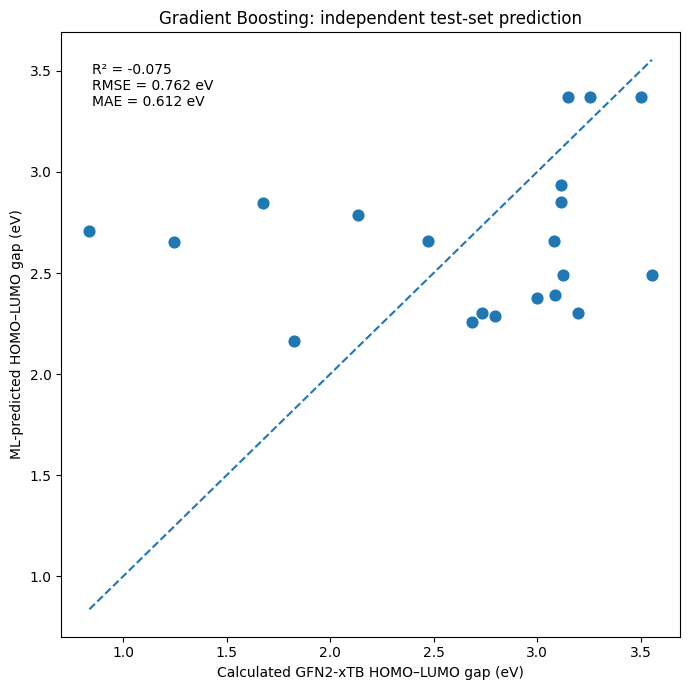

In [ ]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    y_test,
    y_pred_test,
    s=60
)

min_val = min(
    y_test.min(),
    y_pred_test.min()
)

max_val = max(
    y_test.max(),
    y_pred_test.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel(
    "Calculated GFN2-xTB HOMO–LUMO gap (eV)"
)

plt.ylabel(
    "ML-predicted HOMO–LUMO gap (eV)"
)

plt.title(
    f"{best_model_name}: independent test-set prediction"
)

plt.text(
    0.05,
    0.95,
    f"R² = {test_r2:.3f}\n"
    f"RMSE = {test_rmse:.3f} eV\n"
    f"MAE = {test_mae:.3f} eV",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

plt.savefig(
    "Figure_4_Experimental_vs_ML_Predicted.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

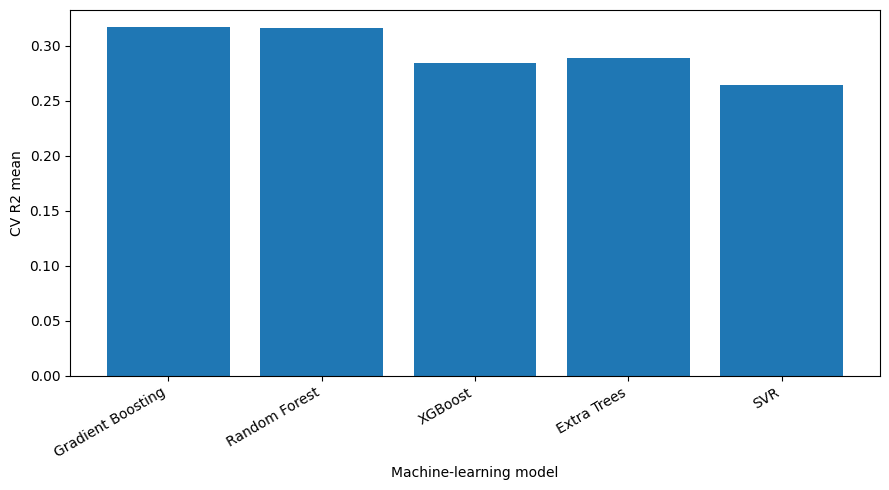

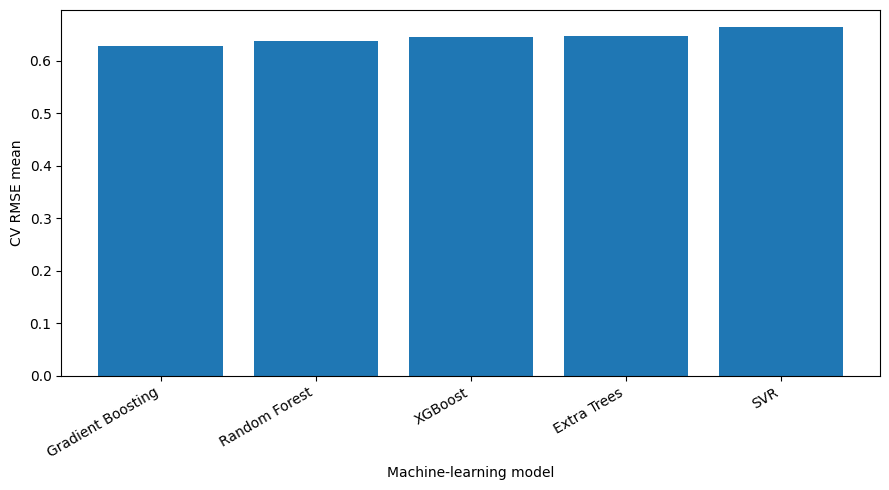

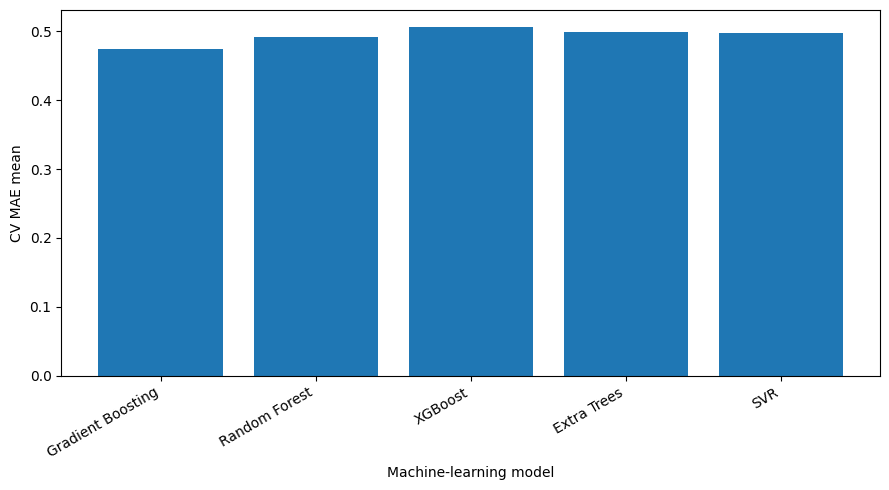

In [ ]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "CV_R2_mean",
    "CV_RMSE_mean",
    "CV_MAE_mean"
]

for metric in metrics_to_plot:

    plt.figure(
        figsize=(9, 5)
    )

    plt.bar(
        cv_results_df["Model"],
        cv_results_df[metric]
    )

    plt.ylabel(
        metric.replace("_", " ")
    )

    plt.xlabel(
        "Machine-learning model"
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    plt.tight_layout()

    filename = (
        "Figure_5_"
        + metric
        + ".png"
    )

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

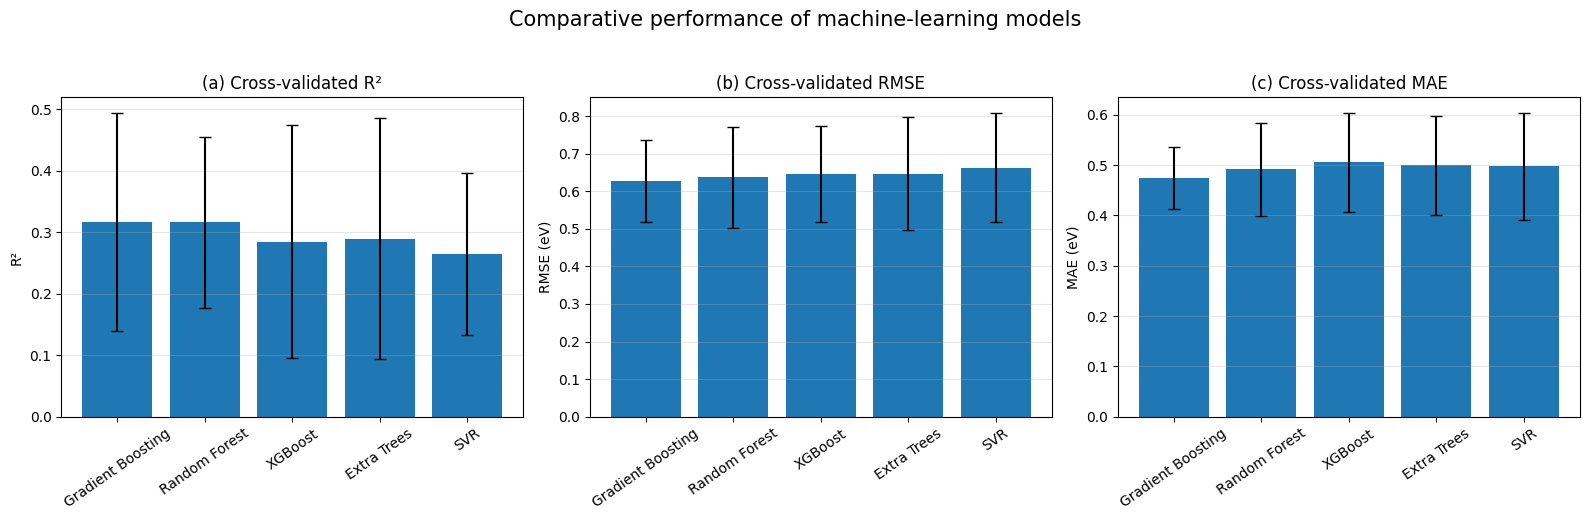

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Make sure models are displayed in the same order
plot_df = cv_results_df.copy()

# Create one figure with three panels
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

models_names = plot_df["Model"]

# ---------------------------------------------------------
# Panel (a): R²
# ---------------------------------------------------------

axes[0].bar(
    models_names,
    plot_df["CV_R2_mean"],
    yerr=plot_df["CV_R2_std"],
    capsize=4
)

axes[0].set_ylabel("R²")
axes[0].set_title("(a) Cross-validated R²")

axes[0].tick_params(
    axis="x",
    rotation=35
)

axes[0].grid(
    axis="y",
    alpha=0.3
)


# ---------------------------------------------------------
# Panel (b): RMSE
# ---------------------------------------------------------

axes[1].bar(
    models_names,
    plot_df["CV_RMSE_mean"],
    yerr=plot_df["CV_RMSE_std"],
    capsize=4
)

axes[1].set_ylabel("RMSE (eV)")
axes[1].set_title("(b) Cross-validated RMSE")

axes[1].tick_params(
    axis="x",
    rotation=35
)

axes[1].grid(
    axis="y",
    alpha=0.3
)


# ---------------------------------------------------------
# Panel (c): MAE
# ---------------------------------------------------------

axes[2].bar(
    models_names,
    plot_df["CV_MAE_mean"],
    yerr=plot_df["CV_MAE_std"],
    capsize=4
)

axes[2].set_ylabel("MAE (eV)")
axes[2].set_title("(c) Cross-validated MAE")

axes[2].tick_params(
    axis="x",
    rotation=35
)

axes[2].grid(
    axis="y",
    alpha=0.3
)


# ---------------------------------------------------------
# Overall formatting
# ---------------------------------------------------------

fig.suptitle(
    "Comparative performance of machine-learning models",
    fontsize=15,
    y=1.03
)

plt.tight_layout()

# Save as ONE high-resolution figure
plt.savefig(
    "Figure_5_ML_Model_Performance_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("FINAL 5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 70)

display(
    cv_results_df.round(4)
)

print("\nBEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    "CV R²:",
    round(
        cv_results_df.iloc[0]["CV_R2_mean"],
        4
    )
)

print(
    "CV RMSE:",
    round(
        cv_results_df.iloc[0]["CV_RMSE_mean"],
        4
    ),
    "eV"
)

print(
    "CV MAE:",
    round(
        cv_results_df.iloc[0]["CV_MAE_mean"],
        4
    ),
    "eV"
)

print("\nINDEPENDENT TEST SET")
print("=" * 70)

print(
    "Test R²:",
    round(test_r2, 4)
)

print(
    "Test RMSE:",
    round(test_rmse, 4),
    "eV"
)

print(
    "Test MAE:",
    round(test_mae, 4),
    "eV"
)

FINAL 5-FOLD CROSS-VALIDATION RESULTS


,Model,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std
2,Gradient Boosting,0.3168,0.1779,0.6281,0.1087,0.4744,0.0620
0,Random Forest,0.3162,0.1388,0.6372,0.1345,0.4914,0.0928
3,XGBoost,0.2848,0.1900,0.6455,0.1275,0.5057,0.0986
1,Extra Trees,0.2893,0.1958,0.6462,0.1504,0.4993,0.0987
4,SVR,0.2646,0.1317,0.6634,0.1463,0.4979,0.1066



BEST MODEL
Best model: Gradient Boosting
CV R²: 0.3168
CV RMSE: 0.6281 eV
CV MAE: 0.4744 eV

INDEPENDENT TEST SET
Test R²: -0.0755
Test RMSE: 0.7623 eV
Test MAE: 0.6118 eV


In [ ]:
import os

print("CSV files in current directory:")

for f in os.listdir("."):
    if f.lower().endswith(".csv"):
        print(f)

CSV files in current directory:


In [ ]:
import os

print("CSV files found in /content:")
print("=" * 60)

found = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".csv", ".xlsx", ".xls")):
            path = os.path.join(root, file)
            found.append(path)

if found:
    for path in found:
        print(path)
else:
    print("NO CSV/XLS/XLSX FILE FOUND")

CSV files found in /content:
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [ ]:
import pandas as pd

print("DataFrames currently available in Colab:")
print("=" * 70)

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        found = True
        print(f"\nVariable: {name}")
        print(f"Shape: {obj.shape}")
        print("Columns:")
        print(list(obj.columns))

if not found:
    print("NO DATAFRAME IS CURRENTLY IN MEMORY.")

DataFrames currently available in Colab:
NO DATAFRAME IS CURRENTLY IN MEMORY.


In [ ]:
import os

print("Files currently available in /content:")
print("=" * 70)

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

Files currently available in /content:
/content/.config/.last_opt_in_prompt.yaml
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/active_config
/content/.config/.last_survey_prompt.yaml
/content/.config/config_sentinel
/content/.config/.last_update_check.json
/content/.config/default_configs.db
/content/.config/gce
/content/.config/configurations/config_default
/content/.config/logs/2026.08.10/13.24.58.373513.log
/content/.config/logs/2026.08.10/13.25.25.328016.log
/content/.config/logs/2026.08.10/13.25.43.233148.log
/content/.config/logs/2026.08.10/13.26.19.834999.log
/content/.config/logs/2026.08.10/13.26.18.998373.log
/content/.config/logs/2026.08.10/13.26.03.888211.log
/content/sample_data/anscombe.json
/content/sample_data/README.md
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [ ]:
import pandas as pd

print("Checking DataFrames currently in memory...")
print("=" * 70)

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        found = True

        print(f"\nVariable: {name}")
        print(f"Shape: {obj.shape}")
        print("First columns:")
        print(list(obj.columns)[:30])

if not found:
    print("\nNO PANDAS DATAFRAME IS CURRENTLY IN MEMORY.")

Checking DataFrames currently in memory...

NO PANDAS DATAFRAME IS CURRENTLY IN MEMORY.


In [ ]:
important_variables = [
    "df_candidates",
    "df_selected",
    "pubchem_df",
    "df_ml",
    "X_var",
    "X_filtered",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "feature_importance",
    "cv_results_df"
]

print("Variable status")
print("=" * 70)

for name in important_variables:
    print(
        f"{name:25s} :",
        "AVAILABLE" if name in globals() else "NOT AVAILABLE"
    )

Variable status
df_candidates             : NOT AVAILABLE
df_selected               : NOT AVAILABLE
pubchem_df                : NOT AVAILABLE
df_ml                     : NOT AVAILABLE
X_var                     : NOT AVAILABLE
X_filtered                : NOT AVAILABLE
X_train                   : NOT AVAILABLE
X_test                    : NOT AVAILABLE
y_train                   : NOT AVAILABLE
y_test                    : NOT AVAILABLE
feature_importance        : NOT AVAILABLE
cv_results_df             : NOT AVAILABLE


In [ ]:
DSTDPT_SMILES = "Cn1c(=O)n(C)c(=O)c(O)c1/N=N/c2nnc(S)s2"

print("DSTDPT SMILES:")
print(DSTDPT_SMILES)

DSTDPT SMILES:
Cn1c(=O)n(C)c(=O)c(O)c1/N=N/c2nnc(S)s2


In [ ]:
!pip -q install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 37.9 MB/s eta 0:00:00


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors

print("RDKit imported successfully.")
print("RDKit version:", Chem.rdBase.rdkitVersion)

RDKit imported successfully.
RDKit version: 2026.03.5


In [ ]:
DSTDPT_SMILES = "Cn1c(=O)n(C)c(=O)c(O)c1/N=N/c2nnc(S)s2"

DSTDPT_MOL = Chem.MolFromSmiles(
    DSTDPT_SMILES
)

if DSTDPT_MOL is None:
    raise ValueError(
        "DSTDPT SMILES could not be parsed."
    )

print("DSTDPT structure parsed successfully.")

print(
    "Molecular formula:",
    rdMolDescriptors.CalcMolFormula(DSTDPT_MOL)
)

print(
    "Molecular weight:",
    round(
        Descriptors.MolWt(DSTDPT_MOL),
        4
    )
)

DSTDPT structure parsed successfully.
Molecular formula: C8H8N6O3S2
Molecular weight: 300.325


In [ ]:
# Core packages
!pip -q install requests pandas numpy openpyxl tqdm

# Scientific chemistry packages
!pip -q install rdkit

In [ ]:
import os
import time
import requests
import pandas as pd
import numpy as np

from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import (
    Descriptors,
    rdMolDescriptors,
    Crippen,
    Lipinski,
    AllChem,
    DataStructs
)

print("All packages imported successfully.")

All packages imported successfully.


In [ ]:
DSTDPT_SMILES = "Cn1c(=O)n(C)c(=O)c(O)c1/N=N/c2nnc(S)s2"

DSTDPT_MOL = Chem.MolFromSmiles(
    DSTDPT_SMILES
)

if DSTDPT_MOL is None:
    raise ValueError("DSTDPT SMILES could not be parsed.")

print("DSTDPT verified.")
print(
    "Formula:",
    rdMolDescriptors.CalcMolFormula(DSTDPT_MOL)
)

print(
    "Molecular weight:",
    round(Descriptors.MolWt(DSTDPT_MOL), 4)
)

DSTDPT verified.
Formula: C8H8N6O3S2
Molecular weight: 300.325


In [ ]:
WORKDIR = "/content/DSTDPT_ML_Project"

os.makedirs(
    WORKDIR,
    exist_ok=True
)

print("Working directory:")
print(WORKDIR)

Working directory:
/content/DSTDPT_ML_Project


In [ ]:
reference_df = pd.DataFrame({
    "Molecule_ID": ["DSTDPT"],
    "SMILES": [DSTDPT_SMILES],
    "MolecularFormula": [
        rdMolDescriptors.CalcMolFormula(DSTDPT_MOL)
    ],
    "MolecularWeight": [
        Descriptors.MolWt(DSTDPT_MOL)
    ]
})

reference_df.to_csv(
    f"{WORKDIR}/00_DSTDPT_reference.csv",
    index=False
)

reference_df.to_excel(
    f"{WORKDIR}/00_DSTDPT_reference.xlsx",
    index=False
)

print("DSTDPT reference files saved.")

DSTDPT reference files saved.


In [ ]:
def pubchem_similarity_search(
    smiles,
    threshold=65,
    max_records=500
):

    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
        "compound/fastsimilarity_2d/smiles/cids/JSON"
    )

    params = {
        "smiles": smiles,
        "Threshold": threshold,
        "MaxRecords": max_records
    }

    response = requests.get(
        url,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    data = response.json()

    return (
        data
        .get("IdentifierList", {})
        .get("CID", [])
    )

In [ ]:
cids = pubchem_similarity_search(
    DSTDPT_SMILES,
    threshold=65,
    max_records=500
)

print(
    "Number of candidate CIDs:",
    len(cids)
)

print(
    "First 20 CIDs:",
    cids[:20]
)

Number of candidate CIDs: 50
First 20 CIDs: [1974318, 2661384, 4839487, 2363466, 975688, 2457123, 314229, 901037, 21318260, 21318272, 21318275, 21318276, 21318294, 21318302, 21318307, 136009915, 136009921, 136010008, 136139358, 136614383]


In [ ]:
cid_df = pd.DataFrame({
    "CID": cids
})

cid_df.to_csv(
    f"{WORKDIR}/01_pubchem_candidate_CIDs.csv",
    index=False
)

print(
    "Candidate CID list saved:",
    len(cid_df)
)

Candidate CID list saved: 50


In [ ]:
print("PubChem dataframe shape:", pubchem_df.shape)

print("\nAvailable columns:")
print(pubchem_df.columns.tolist())

print("\nFirst 5 rows:")
display(pubchem_df.head())

PubChem dataframe shape: (50, 13)

Available columns:
['CID', 'MolecularFormula', 'MolecularWeight', 'SMILES', 'ConnectivitySMILES', 'InChIKey', 'IUPACName', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount']

First 5 rows:


,CID,MolecularFormula,MolecularWeight,SMILES,ConnectivitySMILES,InChIKey,IUPACName,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
0,1974318,C8H9N5O2S2,271.3,CC1=NN=C(S1)SC2=C(N(C(=O)NC2=O)C)N,CC1=NN=C(S1)SC2=C(N(C(=O)NC2=O)C)N,XWJGLOFNOKHBQE-UHFFFAOYSA-N,"6-amino-1-methyl-5-[(5-methyl-1,3,4-thiadiazol...",0.2,155.0,2,7,2,17
1,2661384,C12H15N5O3S3,373.5,CCSC1=NN=C(S1)SCC(=O)C2=C(N(C(=O)N(C2=O)C)C)N,CCSC1=NN=C(S1)SCC(=O)C2=C(N(C(=O)N(C2=O)C)C)N,UKRQCXPMLJTXTK-UHFFFAOYSA-N,"6-amino-5-[2-[(5-ethylsulfanyl-1,3,4-thiadiazo...",1.6,188.0,1,9,6,23
2,4839487,C11H14N6O3S2,342.4,CC(C(=O)C1=C(N(C(=O)N(C1=O)C)C)N)SC2=NN=C(S2)N,CC(C(=O)C1=C(N(C(=O)N(C1=O)C)C)N)SC2=NN=C(S2)N,QQGLXYNLCWEPSF-UHFFFAOYSA-N,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.4,189.0,2,9,4,22
3,2363466,C10H12N6O3S2,328.4,CN1C(=C(C(=O)N(C1=O)C)C(=O)CSC2=NN=C(S2)N)N,CN1C(=C(C(=O)N(C1=O)C)C(=O)CSC2=NN=C(S2)N)N,HZIKTJJGZNJNES-UHFFFAOYSA-N,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.0,189.0,2,9,4,21
4,975688,C9H11N5O2S2,285.4,CC1=NN=C(S1)SC2=C(N(C(=O)N(C2=O)C)C)N,CC1=NN=C(S1)SC2=C(N(C(=O)N(C2=O)C)C)N,YEHWVZRMZSCGOB-UHFFFAOYSA-N,"6-amino-1,3-dimethyl-5-[(5-methyl-1,3,4-thiadi...",0.4,146.0,1,7,2,18


In [ ]:
def get_pubchem_properties(
    cids,
    batch_size=50
):

    all_rows = []

    properties = ",".join([
        "MolecularFormula",
        "MolecularWeight",
        "ConnectivitySMILES",
        "SMILES",
        "IsomericSMILES",
        "InChIKey",
        "IUPACName",
        "XLogP",
        "TPSA",
        "HBondDonorCount",
        "HBondAcceptorCount",
        "RotatableBondCount",
        "HeavyAtomCount"
    ])

    for i in tqdm(
        range(0, len(cids), batch_size)
    ):

        batch = cids[
            i:i + batch_size
        ]

        cid_string = ",".join(
            map(str, batch)
        )

        url = (
            "https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
            f"compound/cid/{cid_string}/"
            f"property/{properties}/JSON"
        )

        response = requests.get(
            url,
            timeout=120
        )

        print(
            "Batch:",
            i,
            "Status:",
            response.status_code
        )

        if response.ok:

            records = (
                response
                .json()
                .get("PropertyTable", {})
                .get("Properties", [])
            )

            all_rows.extend(records)

        else:

            print(
                "PubChem request failed:",
                response.text[:300]
            )

        time.sleep(0.5)

    return pd.DataFrame(all_rows)


pubchem_df = get_pubchem_properties(cids)

print("\nPubChem dataframe shape:")
print(pubchem_df.shape)

print("\nAvailable columns:")
print(pubchem_df.columns.tolist())

display(pubchem_df.head())

  0%|          | 0/1 [00:00<?, ?it/s]

Batch: 0 Status: 200

PubChem dataframe shape:
(50, 13)

Available columns:
['CID', 'MolecularFormula', 'MolecularWeight', 'SMILES', 'ConnectivitySMILES', 'InChIKey', 'IUPACName', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount']


,CID,MolecularFormula,MolecularWeight,SMILES,ConnectivitySMILES,InChIKey,IUPACName,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
0,1974318,C8H9N5O2S2,271.3,CC1=NN=C(S1)SC2=C(N(C(=O)NC2=O)C)N,CC1=NN=C(S1)SC2=C(N(C(=O)NC2=O)C)N,XWJGLOFNOKHBQE-UHFFFAOYSA-N,"6-amino-1-methyl-5-[(5-methyl-1,3,4-thiadiazol...",0.2,155.0,2,7,2,17
1,2661384,C12H15N5O3S3,373.5,CCSC1=NN=C(S1)SCC(=O)C2=C(N(C(=O)N(C2=O)C)C)N,CCSC1=NN=C(S1)SCC(=O)C2=C(N(C(=O)N(C2=O)C)C)N,UKRQCXPMLJTXTK-UHFFFAOYSA-N,"6-amino-5-[2-[(5-ethylsulfanyl-1,3,4-thiadiazo...",1.6,188.0,1,9,6,23
2,4839487,C11H14N6O3S2,342.4,CC(C(=O)C1=C(N(C(=O)N(C1=O)C)C)N)SC2=NN=C(S2)N,CC(C(=O)C1=C(N(C(=O)N(C1=O)C)C)N)SC2=NN=C(S2)N,QQGLXYNLCWEPSF-UHFFFAOYSA-N,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.4,189.0,2,9,4,22
3,2363466,C10H12N6O3S2,328.4,CN1C(=C(C(=O)N(C1=O)C)C(=O)CSC2=NN=C(S2)N)N,CN1C(=C(C(=O)N(C1=O)C)C(=O)CSC2=NN=C(S2)N)N,HZIKTJJGZNJNES-UHFFFAOYSA-N,"6-amino-5-[2-[(5-amino-1,3,4-thiadiazol-2-yl)s...",0.0,189.0,2,9,4,21
4,975688,C9H11N5O2S2,285.4,CC1=NN=C(S1)SC2=C(N(C(=O)N(C2=O)C)C)N,CC1=NN=C(S1)SC2=C(N(C(=O)N(C2=O)C)C)N,YEHWVZRMZSCGOB-UHFFFAOYSA-N,"6-amino-1,3-dimethyl-5-[(5-methyl-1,3,4-thiadi...",0.4,146.0,1,7,2,18


In [ ]:
possible_smiles_columns = [
    "CanonicalSMILES",
    "ConnectivitySMILES",
    "SMILES",
    "IsomericSMILES"
]

available_smiles = [
    col
    for col in possible_smiles_columns
    if col in pubchem_df.columns
]

print(
    "SMILES columns found:",
    available_smiles
)

if not available_smiles:
    raise ValueError(
        "No SMILES column was returned by PubChem."
    )

# Prefer canonical/connectivity SMILES
if "ConnectivitySMILES" in pubchem_df.columns:
    smiles_column = "ConnectivitySMILES"

elif "CanonicalSMILES" in pubchem_df.columns:
    smiles_column = "CanonicalSMILES"

elif "IsomericSMILES" in pubchem_df.columns:
    smiles_column = "IsomericSMILES"

else:
    smiles_column = "SMILES"

print(
    "SMILES column selected:",
    smiles_column
)

SMILES columns found: ['ConnectivitySMILES', 'SMILES']
SMILES column selected: ConnectivitySMILES


In [ ]:
pubchem_df["Mol"] = (
    pubchem_df[smiles_column]
    .apply(
        lambda x: Chem.MolFromSmiles(x)
        if pd.notna(x)
        else None
    )
)

before = len(pubchem_df)

pubchem_df = pubchem_df[
    pubchem_df["Mol"].notna()
].copy()

after = len(pubchem_df)

print(
    "Valid RDKit molecules:",
    after
)

print(
    "Invalid molecules removed:",
    before - after
)

Valid RDKit molecules: 50
Invalid molecules removed: 0


In [ ]:
pubchem_df.to_csv(
    f"{WORKDIR}/02_pubchem_valid_molecules.csv",
    index=False
)

pubchem_df.to_excel(
    f"{WORKDIR}/02_pubchem_valid_molecules.xlsx",
    index=False
)

print(
    "Checkpoint saved successfully."
)

Checkpoint saved successfully.


In [ ]:
from rdkit.Chem import rdFingerprintGenerator

fpgen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

DSTDPT_FP = fpgen.GetFingerprint(
    DSTDPT_MOL
)

def calculate_similarity(mol):

    if mol is None:
        return np.nan

    fp = fpgen.GetFingerprint(mol)

    return DataStructs.TanimotoSimilarity(
        DSTDPT_FP,
        fp
    )

pubchem_df["Similarity_to_DSTDPT"] = (
    pubchem_df["Mol"]
    .apply(calculate_similarity)
)

print(
    pubchem_df["Similarity_to_DSTDPT"].describe()
)

count    50.000000
mean      0.206119
std       0.059779
min       0.112676
25%       0.155260
50%       0.204652
75%       0.248975
max       0.351852
Name: Similarity_to_DSTDPT, dtype: float64


In [ ]:
display(
    pubchem_df[
        [
            "CID",
            "Similarity_to_DSTDPT"
        ]
    ]
    .sort_values(
        "Similarity_to_DSTDPT",
        ascending=False
    )
    .head(20)
)

,CID,Similarity_to_DSTDPT
17,136010008,0.351852
16,136009921,0.339286
15,136009915,0.333333
18,136139358,0.292308
4,975688,0.272727
22,136614402,0.269841
3,2363466,0.266667
27,2489822,0.262295
2,4839487,0.262295
1,2661384,0.262295


In [ ]:
dstdpt_canonical = Chem.MolToSmiles(
    DSTDPT_MOL,
    canonical=True
)

pubchem_df["Canonical_RDKit_SMILES"] = (
    pubchem_df["Mol"]
    .apply(
        lambda m: Chem.MolToSmiles(
            m,
            canonical=True
        )
    )
)

# Remove DSTDPT itself
pubchem_df = pubchem_df[
    pubchem_df["Canonical_RDKit_SMILES"]
    != dstdpt_canonical
].copy()

# Remove duplicate structures
pubchem_df = pubchem_df.drop_duplicates(
    subset=["Canonical_RDKit_SMILES"]
)

pubchem_df.reset_index(
    drop=True,
    inplace=True
)

print(
    "Unique compounds remaining:",
    len(pubchem_df)
)

Unique compounds remaining: 48


In [ ]:
similarity_pool = pubchem_df[
    pubchem_df["Similarity_to_DSTDPT"] >= 0.55
].copy()

print(
    "Candidates with similarity >= 0.55:",
    len(similarity_pool)
)

Candidates with similarity >= 0.55: 0


In [ ]:
display(
    similarity_pool[
        [
            "CID",
            "MolecularFormula",
            "MolecularWeight",
            "Similarity_to_DSTDPT"
        ]
    ]
    .sort_values(
        "Similarity_to_DSTDPT",
        ascending=False
    )
)

,CID,MolecularFormula,MolecularWeight,Similarity_to_DSTDPT


In [ ]:
# Search PubChem at several similarity thresholds
thresholds = [65, 60, 55]

all_cids = set()

for threshold in thresholds:

    print(
        f"\nSearching PubChem at {threshold}% similarity..."
    )

    temp_cids = pubchem_similarity_search(
        DSTDPT_SMILES,
        threshold=threshold,
        max_records=500
    )

    print(
        f"Returned: {len(temp_cids)} CIDs"
    )

    all_cids.update(temp_cids)

print("\nTotal unique CIDs:", len(all_cids))


Searching PubChem at 65% similarity...
Returned: 50 CIDs

Searching PubChem at 60% similarity...
Returned: 378 CIDs

Searching PubChem at 55% similarity...
Returned: 500 CIDs

Total unique CIDs: 798


In [ ]:
expanded_cids = sorted(
    list(all_cids)
)

expanded_cid_df = pd.DataFrame({
    "CID": expanded_cids
})

expanded_cid_df.to_csv(
    f"{WORKDIR}/01B_expanded_pubchem_CIDs.csv",
    index=False
)

print(
    "Expanded candidate CIDs:",
    len(expanded_cids)
)

Expanded candidate CIDs: 798


In [ ]:
expanded_pubchem_df = get_pubchem_properties(
    expanded_cids,
    batch_size=50
)

print(
    "Expanded PubChem dataset shape:",
    expanded_pubchem_df.shape
)

print(
    "\nColumns returned:"
)

print(
    expanded_pubchem_df.columns.tolist()
)

  0%|          | 0/16 [00:00<?, ?it/s]

Batch: 0 Status: 200
Batch: 50 Status: 200
Batch: 100 Status: 200
Batch: 150 Status: 200
Batch: 200 Status: 200
Batch: 250 Status: 200
Batch: 300 Status: 200
Batch: 350 Status: 200
Batch: 400 Status: 200
Batch: 450 Status: 200
Batch: 500 Status: 200
Batch: 550 Status: 200
Batch: 600 Status: 200
Batch: 650 Status: 200
Batch: 700 Status: 200
Batch: 750 Status: 200
Expanded PubChem dataset shape: (798, 13)

Columns returned:
['CID', 'MolecularFormula', 'MolecularWeight', 'SMILES', 'ConnectivitySMILES', 'InChIKey', 'IUPACName', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount']


In [ ]:
expanded_pubchem_df.to_csv(
    f"{WORKDIR}/02B_expanded_pubchem_properties.csv",
    index=False
)

expanded_pubchem_df.to_excel(
    f"{WORKDIR}/02B_expanded_pubchem_properties.xlsx",
    index=False
)

print(
    "Expanded PubChem dataset saved successfully."
)

Expanded PubChem dataset saved successfully.


In [ ]:
possible_smiles_columns = [
    "CanonicalSMILES",
    "ConnectivitySMILES",
    "SMILES",
    "IsomericSMILES"
]

available_smiles = [
    col
    for col in possible_smiles_columns
    if col in expanded_pubchem_df.columns
]

print(
    "SMILES columns found:",
    available_smiles
)

if "ConnectivitySMILES" in expanded_pubchem_df.columns:
    smiles_column = "ConnectivitySMILES"

elif "CanonicalSMILES" in expanded_pubchem_df.columns:
    smiles_column = "CanonicalSMILES"

elif "IsomericSMILES" in expanded_pubchem_df.columns:
    smiles_column = "IsomericSMILES"

elif "SMILES" in expanded_pubchem_df.columns:
    smiles_column = "SMILES"

else:
    raise ValueError(
        "No usable SMILES column found."
    )

expanded_pubchem_df["Mol"] = (
    expanded_pubchem_df[smiles_column]
    .apply(
        lambda x: Chem.MolFromSmiles(x)
        if pd.notna(x)
        else None
    )
)

before = len(expanded_pubchem_df)

expanded_pubchem_df = (
    expanded_pubchem_df[
        expanded_pubchem_df["Mol"].notna()
    ]
    .copy()
)

after = len(expanded_pubchem_df)

print(
    "Valid RDKit molecules:",
    after
)

print(
    "Invalid molecules removed:",
    before - after
)

SMILES columns found: ['ConnectivitySMILES', 'SMILES']
Valid RDKit molecules: 798
Invalid molecules removed: 0


In [ ]:
dstdpt_canonical = Chem.MolToSmiles(
    DSTDPT_MOL,
    canonical=True
)

expanded_pubchem_df[
    "Canonical_RDKit_SMILES"
] = (
    expanded_pubchem_df["Mol"]
    .apply(
        lambda m: Chem.MolToSmiles(
            m,
            canonical=True
        )
    )
)

# Remove DSTDPT itself
expanded_pubchem_df = expanded_pubchem_df[
    expanded_pubchem_df[
        "Canonical_RDKit_SMILES"
    ] != dstdpt_canonical
].copy()

# Remove duplicate molecular structures
expanded_pubchem_df = (
    expanded_pubchem_df
    .drop_duplicates(
        subset=[
            "Canonical_RDKit_SMILES"
        ]
    )
    .reset_index(drop=True)
)

print(
    "Unique compounds after deduplication:",
    len(expanded_pubchem_df)
)

Unique compounds after deduplication: 764


In [ ]:
expanded_pubchem_df[
    "Morgan_Tanimoto_DSTDPT"
] = (
    expanded_pubchem_df["Mol"]
    .apply(calculate_similarity)
)

print(
    expanded_pubchem_df[
        "Morgan_Tanimoto_DSTDPT"
    ].describe()
)

count    764.000000
mean       0.155676
std        0.049133
min        0.086207
25%        0.123077
50%        0.137931
75%        0.172175
max        0.375000
Name: Morgan_Tanimoto_DSTDPT, dtype: float64


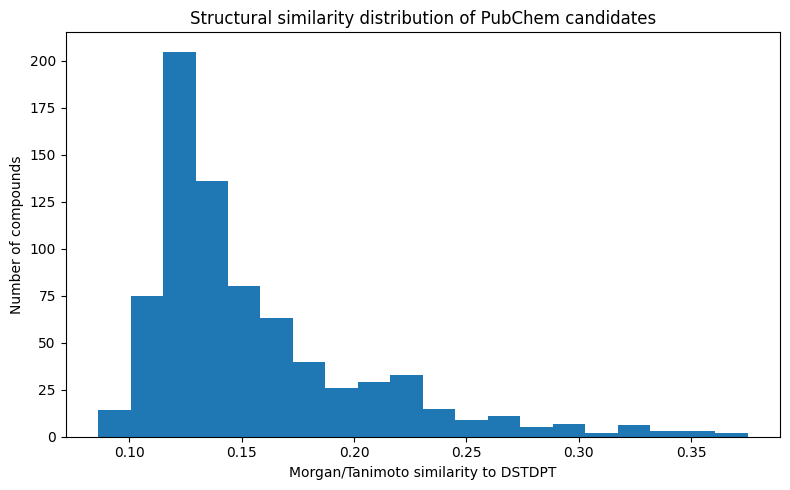

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    expanded_pubchem_df[
        "Morgan_Tanimoto_DSTDPT"
    ].dropna(),
    bins=20
)

plt.xlabel(
    "Morgan/Tanimoto similarity to DSTDPT"
)

plt.ylabel(
    "Number of compounds"
)

plt.title(
    "Structural similarity distribution of PubChem candidates"
)

plt.tight_layout()

plt.savefig(
    f"{WORKDIR}/Candidate_Similarity_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
expanded_pubchem_df.to_csv(
    f"{WORKDIR}/03_expanded_valid_unique_candidates.csv",
    index=False
)

expanded_pubchem_df.to_excel(
    f"{WORKDIR}/03_expanded_valid_unique_candidates.xlsx",
    index=False
)

print(
    "Checkpoint saved."
)

Checkpoint saved.


In [ ]:
# Make a copy
df_candidates = expanded_pubchem_df.copy()

# ---------------------------------------------------------
# Convert PubChem numerical properties to numeric
# ---------------------------------------------------------

numeric_columns = [
    "MolecularWeight",
    "HeavyAtomCount",
    "XLogP",
    "TPSA",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "RotatableBondCount"
]

for col in numeric_columns:

    if col in df_candidates.columns:

        df_candidates[col] = pd.to_numeric(
            df_candidates[col],
            errors="coerce"
        )

# ---------------------------------------------------------
# Check data types
# ---------------------------------------------------------

print("Data types after conversion:")
print(
    df_candidates[
        [
            "MolecularWeight",
            "HeavyAtomCount"
        ]
    ].dtypes
)

# ---------------------------------------------------------
# Chemical-quality filtering
# ---------------------------------------------------------

df_candidates = df_candidates[
    (df_candidates["MolecularWeight"] >= 100) &
    (df_candidates["MolecularWeight"] <= 600) &
    (df_candidates["HeavyAtomCount"] >= 8) &
    (df_candidates["HeavyAtomCount"] <= 45)
].copy()

# Remove molecules with missing essential values
df_candidates = df_candidates.dropna(
    subset=[
        "MolecularWeight",
        "HeavyAtomCount",
        "Mol"
    ]
)

df_candidates.reset_index(
    drop=True,
    inplace=True
)

print(
    "\nCandidate pool after chemical filtering:",
    len(df_candidates)
)

Data types after conversion:
MolecularWeight    float64
HeavyAtomCount       int64
dtype: object

Candidate pool after chemical filtering: 764


In [ ]:
df_candidates.to_csv(
    f"{WORKDIR}/04_chemical_filtered_candidates.csv",
    index=False
)

df_candidates.to_excel(
    f"{WORKDIR}/04_chemical_filtered_candidates.xlsx",
    index=False
)

print(
    "Chemical-filtered candidate pool saved successfully."
)

Chemical-filtered candidate pool saved successfully.


In [ ]:
df_candidates = expanded_pubchem_df.copy()

numeric_columns = [
    "MolecularWeight",
    "HeavyAtomCount",
    "XLogP",
    "TPSA",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "RotatableBondCount"
]

for col in numeric_columns:
    if col in df_candidates.columns:
        df_candidates[col] = pd.to_numeric(
            df_candidates[col],
            errors="coerce"
        )

print("Conversion completed.")

print(
    df_candidates[
        [
            "MolecularWeight",
            "HeavyAtomCount"
        ]
    ].dtypes
)

Conversion completed.
MolecularWeight    float64
HeavyAtomCount       int64
dtype: object


In [ ]:
df_candidates = df_candidates[
    (df_candidates["MolecularWeight"] >= 100) &
    (df_candidates["MolecularWeight"] <= 600) &
    (df_candidates["HeavyAtomCount"] >= 8) &
    (df_candidates["HeavyAtomCount"] <= 45)
].copy()

df_candidates = df_candidates.dropna(
    subset=[
        "MolecularWeight",
        "HeavyAtomCount",
        "Mol"
    ]
)

df_candidates.reset_index(
    drop=True,
    inplace=True
)

print(
    "Candidate pool after chemical filtering:",
    len(df_candidates)
)

Candidate pool after chemical filtering: 764


In [ ]:
df_candidates.to_csv(
    f"{WORKDIR}/04_chemical_filtered_candidates.csv",
    index=False
)

df_candidates.to_excel(
    f"{WORKDIR}/04_chemical_filtered_candidates.xlsx",
    index=False
)

print("Chemical-filtered checkpoint saved.")

Chemical-filtered checkpoint saved.


In [ ]:
from rdkit.SimDivFilters.rdSimDivPickers import MaxMinPicker

# ---------------------------------------------------------
# Check candidate pool
# ---------------------------------------------------------

print(
    "Available candidate molecules:",
    len(df_candidates)
)

if len(df_candidates) < 100:
    raise ValueError(
        f"Only {len(df_candidates)} candidates are available. "
        "At least 100 are required for 100-molecule selection."
    )

# ---------------------------------------------------------
# Generate fingerprints
# ---------------------------------------------------------

mols = df_candidates["Mol"].tolist()

fps = [
    fpgen.GetFingerprint(mol)
    for mol in mols
]

# ---------------------------------------------------------
# MaxMin diversity selection
# ---------------------------------------------------------

picker = MaxMinPicker()

def distance(i, j):
    return 1 - DataStructs.TanimotoSimilarity(
        fps[i],
        fps[j]
    )

n_select = 100

picked_indices = picker.LazyPick(
    distance,
    len(mols),
    n_select,
    seed=42
)

picked_indices = list(
    picked_indices
)

# ---------------------------------------------------------
# Create selected dataset
# ---------------------------------------------------------

df_selected = (
    df_candidates
    .iloc[picked_indices]
    .copy()
)

df_selected.reset_index(
    drop=True,
    inplace=True
)

# Create consistent molecule IDs
df_selected.insert(
    0,
    "Molecule_ID",
    [
        f"M{i:03d}"
        for i in range(
            1,
            len(df_selected) + 1
        )
    ]
)

print(
    "\nCandidate pool:",
    len(df_candidates)
)

print(
    "Selected molecules:",
    len(df_selected)
)

Available candidate molecules: 764

Candidate pool: 764
Selected molecules: 100


In [ ]:
selected_mols = df_selected["Mol"].tolist()

selected_fps = [
    fpgen.GetFingerprint(mol)
    for mol in selected_mols
]

similarities = []

for i in range(len(selected_fps)):

    for j in range(i + 1, len(selected_fps)):

        sim = DataStructs.TanimotoSimilarity(
            selected_fps[i],
            selected_fps[j]
        )

        similarities.append(sim)

similarities = np.array(similarities)

print(
    "Mean pairwise similarity:",
    round(similarities.mean(), 4)
)

print(
    "Maximum pairwise similarity:",
    round(similarities.max(), 4)
)

print(
    "Minimum pairwise similarity:",
    round(similarities.min(), 4)
)

Mean pairwise similarity: 0.1353
Maximum pairwise similarity: 0.3279
Minimum pairwise similarity: 0.0303


In [ ]:
df_selected.to_csv(
    f"{WORKDIR}/05_selected_100_molecules.csv",
    index=False
)

df_selected.to_excel(
    f"{WORKDIR}/05_selected_100_molecules.xlsx",
    index=False
)

print(
    "Final 100-molecule dataset saved successfully."
)

Final 100-molecule dataset saved successfully.


In [ ]:
structure_dataset = df_selected[
    [
        "Molecule_ID",
        "CID",
        smiles_column,
        "Canonical_RDKit_SMILES",
        "Morgan_Tanimoto_DSTDPT",
        "MolecularFormula",
        "MolecularWeight"
    ]
].copy()

structure_dataset.to_csv(
    f"{WORKDIR}/05A_structure_dataset.csv",
    index=False
)

print(
    "Structure dataset saved."
)

display(
    structure_dataset.head(10)
)

Structure dataset saved.


,Molecule_ID,CID,ConnectivitySMILES,Canonical_RDKit_SMILES,Morgan_Tanimoto_DSTDPT,MolecularFormula,MolecularWeight
0,M001,20243375,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,CNC(=O)N(C)c1nnc(SC(C)C2OCCCS2)s1,0.105263,C11H18N4O2S3,334.50
1,M002,387462,CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],Cn1c(N=[N+]=[N-])cc(=O)n(C)c1=O,0.192308,C6H7N5O2,181.15
2,M003,137037044,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,NC(=S)N=Nc1nc(O)c(O)c(=O)[nH]1,0.157895,C5H5N5O3S,215.19
3,M004,141226416,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,O=c1[nH]cc(F)c(=O)n1-c1nncs1,0.133333,C6H3FN4O2S,214.18
4,M005,91119,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,CCN1C(=O)C(=C2SC(SCC(=O)O)=NN2C)SC1=S,0.130435,C10H11N3O3S4,349.50
5,M006,21501671,CCCCOC1CCN(C(=O)N1C2=NN=C(S2)S(=O)(=O)C)CC=C,C=CCN1CCC(OCCCC)N(c2nnc(S(C)(=O)=O)s2)C1=O,0.113924,C14H22N4O4S2,374.50
6,M007,3075408,CC1=C(C(=O)N(C(=O)N1CCS(=O)CC(C)C)CCS(=O)CC(C)C)O,Cc1c(O)c(=O)n(CCS(=O)CC(C)C)c(=O)n1CCS(=O)CC(C)C,0.186441,C17H30N2O5S2,406.60
7,M008,20271175,C1C=CN(C2N1C=C(S2)C(=O)N)C3=NNN=N3,NC(=O)C1=CN2CC=CN(c3nn[nH]n3)C2S1,0.097222,C8H9N7OS,251.27
8,M009,129782890,CC(=O)N(C1=NN(N=N1)C)C(=O)C,CC(=O)N(C(C)=O)c1nnn(C)n1,0.153846,C6H9N5O2,183.17
9,M010,80614793,CCN1C=CC(=O)N(C1=O)CC2=NN=C(S2)NN,CCn1ccc(=O)n(Cc2nnc(NN)s2)c1=O,0.151515,C9H12N6O2S,268.30


In [ ]:
# ============================================================
# STEP 21 — MAXMIN DIVERSITY SELECTION
# ============================================================

from rdkit.SimDivFilters.rdSimDivPickers import MaxMinPicker
from rdkit import DataStructs
import numpy as np
import pandas as pd

# Check candidate pool
print("Available candidate molecules:", len(df_candidates))

if len(df_candidates) < 100:
    raise ValueError(
        f"Only {len(df_candidates)} candidates are available. "
        "At least 100 candidates are required."
    )

# ------------------------------------------------------------
# Generate Morgan fingerprints
# ------------------------------------------------------------

mols = df_candidates["Mol"].tolist()

fps = [
    fpgen.GetFingerprint(mol)
    for mol in mols
]

print("Fingerprints generated:", len(fps))

# ------------------------------------------------------------
# Define distance function
# ------------------------------------------------------------

def distance(i, j):
    return 1 - DataStructs.TanimotoSimilarity(
        fps[i],
        fps[j]
    )

# ------------------------------------------------------------
# MaxMin diversity selection
# ------------------------------------------------------------

picker = MaxMinPicker()

n_select = 100

picked_indices = picker.LazyPick(
    distance,
    len(mols),
    n_select,
    seed=42
)

picked_indices = list(picked_indices)

# ------------------------------------------------------------
# Create selected dataset
# ------------------------------------------------------------

df_selected = (
    df_candidates
    .iloc[picked_indices]
    .copy()
)

df_selected.reset_index(
    drop=True,
    inplace=True
)

# ------------------------------------------------------------
# Assign molecule IDs
# ------------------------------------------------------------

df_selected.insert(
    0,
    "Molecule_ID",
    [
        f"M{i:03d}"
        for i in range(
            1,
            len(df_selected) + 1
        )
    ]
)

print()
print("=" * 60)
print("DIVERSITY SELECTION COMPLETE")
print("=" * 60)

print(
    "Candidate pool:",
    len(df_candidates)
)

print(
    "Selected molecules:",
    len(df_selected)
)

Available candidate molecules: 764
Fingerprints generated: 764

DIVERSITY SELECTION COMPLETE
Candidate pool: 764
Selected molecules: 100


In [ ]:
# ============================================================
# STEP 22 — DIVERSITY QUALITY CHECK
# ============================================================

selected_mols = df_selected["Mol"].tolist()

selected_fps = [
    fpgen.GetFingerprint(mol)
    for mol in selected_mols
]

pairwise_similarities = []

for i in range(len(selected_fps)):

    for j in range(i + 1, len(selected_fps)):

        similarity = DataStructs.TanimotoSimilarity(
            selected_fps[i],
            selected_fps[j]
        )

        pairwise_similarities.append(
            similarity
        )

pairwise_similarities = np.array(
    pairwise_similarities
)

print("=" * 60)
print("DIVERSITY QUALITY CHECK")
print("=" * 60)

print(
    "Number of selected molecules:",
    len(selected_mols)
)

print(
    "Number of pairwise comparisons:",
    len(pairwise_similarities)
)

print(
    "Mean pairwise Tanimoto similarity:",
    round(
        pairwise_similarities.mean(),
        4
    )
)

print(
    "Median pairwise Tanimoto similarity:",
    round(
        np.median(pairwise_similarities),
        4
    )
)

print(
    "Minimum pairwise similarity:",
    round(
        pairwise_similarities.min(),
        4
    )
)

print(
    "Maximum pairwise similarity:",
    round(
        pairwise_similarities.max(),
        4
    )
)

DIVERSITY QUALITY CHECK
Number of selected molecules: 100
Number of pairwise comparisons: 4950
Mean pairwise Tanimoto similarity: 0.1353
Median pairwise Tanimoto similarity: 0.127
Minimum pairwise similarity: 0.0303
Maximum pairwise similarity: 0.3279


In [ ]:
# ============================================================
# STEP 23 — SAVE SELECTED 100-MOLECULE DATASET
# ============================================================

# Save complete dataset
df_selected.to_csv(
    f"{WORKDIR}/05_selected_100_molecules.csv",
    index=False
)

df_selected.to_excel(
    f"{WORKDIR}/05_selected_100_molecules.xlsx",
    index=False
)

print(
    "Complete 100-molecule dataset saved."
)

Complete 100-molecule dataset saved.


In [ ]:
# ============================================================
# STEP 23A — CLEAN STRUCTURE DATASET
# ============================================================

structure_columns = [
    "Molecule_ID",
    "CID",
    smiles_column,
    "Canonical_RDKit_SMILES",
    "Morgan_Tanimoto_DSTDPT",
    "MolecularFormula",
    "MolecularWeight"
]

# Keep only columns that actually exist
structure_columns = [
    col
    for col in structure_columns
    if col in df_selected.columns
]

structure_dataset = df_selected[
    structure_columns
].copy()

structure_dataset.to_csv(
    f"{WORKDIR}/05A_structure_dataset.csv",
    index=False
)

structure_dataset.to_excel(
    f"{WORKDIR}/05A_structure_dataset.xlsx",
    index=False
)

print(
    "Clean structure dataset saved."
)

print(
    "Dataset shape:",
    structure_dataset.shape
)

display(
    structure_dataset.head(10)
)

Clean structure dataset saved.
Dataset shape: (100, 7)


,Molecule_ID,CID,ConnectivitySMILES,Canonical_RDKit_SMILES,Morgan_Tanimoto_DSTDPT,MolecularFormula,MolecularWeight
0,M001,20243375,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,CNC(=O)N(C)c1nnc(SC(C)C2OCCCS2)s1,0.105263,C11H18N4O2S3,334.50
1,M002,387462,CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],Cn1c(N=[N+]=[N-])cc(=O)n(C)c1=O,0.192308,C6H7N5O2,181.15
2,M003,137037044,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,NC(=S)N=Nc1nc(O)c(O)c(=O)[nH]1,0.157895,C5H5N5O3S,215.19
3,M004,141226416,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,O=c1[nH]cc(F)c(=O)n1-c1nncs1,0.133333,C6H3FN4O2S,214.18
4,M005,91119,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,CCN1C(=O)C(=C2SC(SCC(=O)O)=NN2C)SC1=S,0.130435,C10H11N3O3S4,349.50
5,M006,21501671,CCCCOC1CCN(C(=O)N1C2=NN=C(S2)S(=O)(=O)C)CC=C,C=CCN1CCC(OCCCC)N(c2nnc(S(C)(=O)=O)s2)C1=O,0.113924,C14H22N4O4S2,374.50
6,M007,3075408,CC1=C(C(=O)N(C(=O)N1CCS(=O)CC(C)C)CCS(=O)CC(C)C)O,Cc1c(O)c(=O)n(CCS(=O)CC(C)C)c(=O)n1CCS(=O)CC(C)C,0.186441,C17H30N2O5S2,406.60
7,M008,20271175,C1C=CN(C2N1C=C(S2)C(=O)N)C3=NNN=N3,NC(=O)C1=CN2CC=CN(c3nn[nH]n3)C2S1,0.097222,C8H9N7OS,251.27
8,M009,129782890,CC(=O)N(C1=NN(N=N1)C)C(=O)C,CC(=O)N(C(C)=O)c1nnn(C)n1,0.153846,C6H9N5O2,183.17
9,M010,80614793,CCN1C=CC(=O)N(C1=O)CC2=NN=C(S2)NN,CCn1ccc(=O)n(Cc2nnc(NN)s2)c1=O,0.151515,C9H12N6O2S,268.30


In [ ]:
# ============================================================
# STEP 23B — FINAL VERIFICATION
# ============================================================

print("=" * 70)
print("FINAL DATASET VERIFICATION")
print("=" * 70)

print(
    "Number of molecules:",
    len(df_selected)
)

print(
    "Unique Molecule IDs:",
    df_selected["Molecule_ID"].nunique()
)

if "CID" in df_selected.columns:
    print(
        "Unique PubChem CIDs:",
        df_selected["CID"].nunique()
    )

print(
    "Missing SMILES:",
    df_selected[smiles_column].isna().sum()
)

print(
    "Missing molecular structures:",
    df_selected["Mol"].isna().sum()
)

print("=" * 70)

if len(df_selected) == 100:
    print("✓ SUCCESS: 100 molecules selected.")
else:
    print(
        "WARNING: Selected molecule count is not 100."
    )

FINAL DATASET VERIFICATION
Number of molecules: 100
Unique Molecule IDs: 100
Unique PubChem CIDs: 100
Missing SMILES: 0
Missing molecular structures: 0
✓ SUCCESS: 100 molecules selected.


In [ ]:
# ============================================================
# STEP 24 — COMPLETE RDKit DESCRIPTOR CALCULATION
# ============================================================

import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import (
    Descriptors,
    Lipinski,
    Crippen,
    rdMolDescriptors
)

# ------------------------------------------------------------
# Start from the verified 100-molecule dataset
# ------------------------------------------------------------

df_desc = df_selected.copy()

print(
    "Starting molecules:",
    len(df_desc)
)

# ------------------------------------------------------------
# Descriptor calculation function
# ------------------------------------------------------------

def calculate_rdkit_descriptors(mol):

    descriptors = {}

    # Basic molecular descriptors
    descriptors["MolecularWeight_RDKit"] = (
        Descriptors.MolWt(mol)
    )

    descriptors["LogP"] = (
        Crippen.MolLogP(mol)
    )

    descriptors["TPSA_RDKit"] = (
        rdMolDescriptors.CalcTPSA(mol)
    )

    descriptors["HBD"] = (
        Lipinski.NumHDonors(mol)
    )

    descriptors["HBA"] = (
        Lipinski.NumHAcceptors(mol)
    )

    descriptors["RotatableBonds"] = (
        Lipinski.NumRotatableBonds(mol)
    )

    descriptors["HeavyAtomCount_RDKit"] = (
        Lipinski.HeavyAtomCount(mol)
    )

    descriptors["RingCount"] = (
        rdMolDescriptors.CalcNumRings(mol)
    )

    descriptors["AromaticRingCount"] = (
        rdMolDescriptors.CalcNumAromaticRings(mol)
    )

    descriptors["FractionCSP3"] = (
        rdMolDescriptors.CalcFractionCSP3(mol)
    )

    descriptors["MolecularVolume"] = (
        rdMolDescriptors.CalcLabuteASA(mol)
    )

    # --------------------------------------------------------
    # Elemental counts
    # --------------------------------------------------------

    descriptors["Carbon_Count"] = (
        sum(
            atom.GetAtomicNum() == 6
            for atom in mol.GetAtoms()
        )
    )

    descriptors["Nitrogen_Count"] = (
        sum(
            atom.GetAtomicNum() == 7
            for atom in mol.GetAtoms()
        )
    )

    descriptors["Oxygen_Count"] = (
        sum(
            atom.GetAtomicNum() == 8
            for atom in mol.GetAtoms()
        )
    )

    descriptors["Sulfur_Count"] = (
        sum(
            atom.GetAtomicNum() == 16
            for atom in mol.GetAtoms()
        )
    )

    descriptors["Hydrogen_Count"] = (
        sum(
            atom.GetAtomicNum() == 1
            for atom in mol.GetAtoms()
        )
    )

    # --------------------------------------------------------
    # Functional-group counts
    # --------------------------------------------------------

    # Azo group: -N=N-
    azo_pattern = Chem.MolFromSmarts(
        "[N]=[N]"
    )

    descriptors["Azo_Count"] = len(
        mol.GetSubstructMatches(
            azo_pattern
        )
    )

    # Carbonyl: C=O
    carbonyl_pattern = Chem.MolFromSmarts(
        "[CX3]=[OX1]"
    )

    descriptors["Carbonyl_Count"] = len(
        mol.GetSubstructMatches(
            carbonyl_pattern
        )
    )

    # Hydroxyl: O-H
    hydroxyl_pattern = Chem.MolFromSmarts(
        "[OX2H]"
    )

    descriptors["Hydroxyl_Count"] = len(
        mol.GetSubstructMatches(
            hydroxyl_pattern
        )
    )

    # Thiol: S-H
    thiol_pattern = Chem.MolFromSmarts(
        "[SX2H]"
    )

    descriptors["Thiol_Count"] = len(
        mol.GetSubstructMatches(
            thiol_pattern
        )
    )

    # --------------------------------------------------------
    # Heteroatom count
    # --------------------------------------------------------

    descriptors["Heteroatom_Count"] = (
        descriptors["Nitrogen_Count"]
        + descriptors["Oxygen_Count"]
        + descriptors["Sulfur_Count"]
    )

    return descriptors


# ------------------------------------------------------------
# Calculate descriptors
# ------------------------------------------------------------

descriptor_records = []

for mol in df_desc["Mol"]:

    descriptor_records.append(
        calculate_rdkit_descriptors(mol)
    )

descriptor_df = pd.DataFrame(
    descriptor_records
)

# ------------------------------------------------------------
# Combine with molecular information
# ------------------------------------------------------------

df_descriptor_dataset = pd.concat(
    [
        df_desc.reset_index(drop=True),
        descriptor_df.reset_index(drop=True)
    ],
    axis=1
)

print(
    "\nDescriptor calculation completed."
)

print(
    "Dataset shape:",
    df_descriptor_dataset.shape
)

print(
    "\nNumber of descriptors:",
    len(descriptor_df.columns)
)

print(
    "\nDescriptor names:"
)

for i, col in enumerate(
    descriptor_df.columns,
    1
):
    print(
        f"{i}. {col}"
    )

Starting molecules: 100

Descriptor calculation completed.
Dataset shape: (100, 38)

Number of descriptors: 21

Descriptor names:
1. MolecularWeight_RDKit
2. LogP
3. TPSA_RDKit
4. HBD
5. HBA
6. RotatableBonds
7. HeavyAtomCount_RDKit
8. RingCount
9. AromaticRingCount
10. FractionCSP3
11. MolecularVolume
12. Carbon_Count
13. Nitrogen_Count
14. Oxygen_Count
15. Sulfur_Count
16. Hydrogen_Count
17. Azo_Count
18. Carbonyl_Count
19. Hydroxyl_Count
20. Thiol_Count
21. Heteroatom_Count


In [ ]:
# ============================================================
# STEP 25 — DESCRIPTOR QUALITY CHECK
# ============================================================

print("=" * 70)
print("DESCRIPTOR DATASET QUALITY CHECK")
print("=" * 70)

print(
    "Molecules:",
    len(df_descriptor_dataset)
)

print(
    "Total columns:",
    len(df_descriptor_dataset.columns)
)

print(
    "Descriptor columns:",
    len(descriptor_df.columns)
)

print(
    "\nMissing values:"
)

missing_values = (
    df_descriptor_dataset[
        descriptor_df.columns
    ]
    .isna()
    .sum()
)

print(
    missing_values[
        missing_values > 0
    ]
)

print(
    "\nDuplicate descriptor rows:",
    df_descriptor_dataset[
        descriptor_df.columns
    ].duplicated().sum()
)

DESCRIPTOR DATASET QUALITY CHECK
Molecules: 100
Total columns: 38
Descriptor columns: 21

Missing values:
Series([], dtype: int64)

Duplicate descriptor rows: 0


In [ ]:
# ============================================================
# STEP 26 — SAVE DESCRIPTOR DATASET
# ============================================================

df_descriptor_dataset.to_csv(
    f"{WORKDIR}/06_RDKit_descriptor_dataset.csv",
    index=False
)

df_descriptor_dataset.to_excel(
    f"{WORKDIR}/06_RDKit_descriptor_dataset.xlsx",
    index=False
)

print(
    "RDKit descriptor dataset saved successfully."
)

RDKit descriptor dataset saved successfully.


In [ ]:
# ============================================================
# STEP 27 — INSTALL xTB FROM OFFICIAL LINUX BINARY
# ============================================================

import os
import shutil
import subprocess

# Official xTB release
XTB_VERSION = "6.7.1"

XTB_URL = (
    "https://github.com/grimme-lab/xtb/releases/download/"
    f"v{XTB_VERSION}/xtb-{XTB_VERSION}-linux-x86_64.tar.xz"
)

print("Downloading xTB...")
print(XTB_URL)

!wget -q --show-progress "$XTB_URL" -O /content/xtb.tar.xz

print("\nExtracting xTB...")

!tar -xf /content/xtb.tar.xz -C /content/

print("\nExtracted directories:")
!ls -lah /content/ | grep xtb

https://github.com/grimme-lab/xtb/releases/download/v6.7.1/xtb-6.7.1-linux-x86_64.tar.xz
/content/xtb.tar.xz 100%[===================>]  25.87M  34.9MB/s    in 0.7s    

Extracting xTB...

Extracted directories:
drwxr-xr-x 6 1001 1001 4.0K Jul 22  2024 xtb-dist
-rw-r--r-- 1 root root  26M Jul 23  2024 xtb.tar.xz


In [ ]:
# ============================================================
# STEP 28 — LOCATE xTB EXECUTABLE
# ============================================================

import glob
import os

possible_xtb = []

for path in glob.glob(
    "/content/**/xtb",
    recursive=True
):

    if (
        os.path.isfile(path)
        and os.access(path, os.X_OK)
    ):
        possible_xtb.append(path)

print("Possible xTB executables:")

for path in possible_xtb:
    print(path)

Possible xTB executables:
/content/xtb-dist/bin/xtb


In [ ]:
# ============================================================
# STEP 29 — CONFIGURE xTB PATH
# ============================================================

if len(possible_xtb) == 0:
    raise FileNotFoundError(
        "xTB executable was not found after extraction."
    )

XTB_EXECUTABLE = possible_xtb[0]

XTB_BIN_DIR = os.path.dirname(
    XTB_EXECUTABLE
)

os.environ["PATH"] = (
    XTB_BIN_DIR
    + ":"
    + os.environ["PATH"]
)

print(
    "xTB executable:"
)

print(
    XTB_EXECUTABLE
)

print(
    "\nxTB directory:"
)

print(
    XTB_BIN_DIR
)

xTB executable:
/content/xtb-dist/bin/xtb

xTB directory:
/content/xtb-dist/bin


In [ ]:
# ============================================================
# STEP 30 — VERIFY xTB
# ============================================================

import subprocess

result = subprocess.run(
    [
        XTB_EXECUTABLE,
        "--version"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

print("=" * 60)
print("xTB VERIFICATION")
print("=" * 60)

print(
    "Executable:",
    XTB_EXECUTABLE
)

print(
    "\nReturn code:",
    result.returncode
)

print(
    "\nSTDOUT:"
)

print(
    result.stdout
)

if result.stderr:

    print(
        "\nSTDERR:"
    )

    print(
        result.stderr
    )

xTB VERIFICATION
Executable: /content/xtb-dist/bin/xtb

Return code: 0

STDOUT:
      -----------------------------------------------------------      
     |                   =====================                   |     
     |                           x T B                           |     
     |                   =====================                   |     
     |                         S. Grimme                         |     
     |          Mulliken Center for Theoretical Chemistry        |     
     |                    University of Bonn                     |     
      -----------------------------------------------------------      

   * xtb version 6.7.1 (edcfbbe) compiled by 'albert@albert-system' on 2024-07-22



STDERR:
normal termination of xtb



In [ ]:
# ============================================================
# STEP 30A — RECREATE xTB WORKING DIRECTORY
# ============================================================

import os
import shutil

# Verified xTB executable
XTB_EXECUTABLE = "/content/xtb-dist/bin/xtb"

# Verify executable exists
if not os.path.isfile(XTB_EXECUTABLE):
    raise FileNotFoundError(
        f"xTB executable not found at:\n{XTB_EXECUTABLE}"
    )

# Verify it is executable
if not os.access(XTB_EXECUTABLE, os.X_OK):
    raise PermissionError(
        "xTB exists but is not executable."
    )

# Recreate xTB working directory
XTB_DIR = "/content/xTB_calculations"

os.makedirs(
    XTB_DIR,
    exist_ok=True
)

print("=" * 60)
print("xTB ENVIRONMENT RESTORED")
print("=" * 60)

print(
    "xTB executable:",
    XTB_EXECUTABLE
)

print(
    "xTB working directory:",
    XTB_DIR
)

print(
    "Executable exists:",
    os.path.exists(XTB_EXECUTABLE)
)

print(
    "Working directory exists:",
    os.path.exists(XTB_DIR)
)

xTB ENVIRONMENT RESTORED
xTB executable: /content/xtb-dist/bin/xtb
xTB working directory: /content/xTB_calculations
Executable exists: True
Working directory exists: True


In [ ]:
# ============================================================
# STEP 30B — FINAL xTB CHECK
# ============================================================

import subprocess

check = subprocess.run(
    [
        XTB_EXECUTABLE,
        "--version"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

print(
    "Return code:",
    check.returncode
)

print(
    check.stdout
)

if check.returncode != 0:
    raise RuntimeError(
        "xTB verification failed."
    )

print(
    "✓ xTB is ready."
)

Return code: 0
      -----------------------------------------------------------      
     |                   =====================                   |     
     |                           x T B                           |     
     |                   =====================                   |     
     |                         S. Grimme                         |     
     |          Mulliken Center for Theoretical Chemistry        |     
     |                    University of Bonn                     |     
      -----------------------------------------------------------      

   * xtb version 6.7.1 (edcfbbe) compiled by 'albert@albert-system' on 2024-07-22


✓ xTB is ready.


In [ ]:
# ============================================================
# STEP 31 — GENERATE 3D STRUCTURE FOR M001
# ============================================================

import os
import shutil
from rdkit import Chem
from rdkit.Chem import AllChem

# Select M001
test_row = df_descriptor_dataset.iloc[0]

test_id = str(test_row["Molecule_ID"])
test_smiles = test_row[smiles_column]

test_mol = Chem.MolFromSmiles(test_smiles)

if test_mol is None:
    raise ValueError(
        f"Could not parse SMILES for {test_id}"
    )

print("Test molecule:", test_id)
print("SMILES:", test_smiles)

# Add hydrogens
test_mol_3d = Chem.AddHs(test_mol)

# Generate 3D coordinates
params = AllChem.ETKDGv3()
params.randomSeed = 42

embed_status = AllChem.EmbedMolecule(
    test_mol_3d,
    params
)

if embed_status != 0:
    raise RuntimeError(
        f"3D embedding failed for {test_id}"
    )

# Initial geometry optimization
try:
    AllChem.MMFFOptimizeMolecule(
        test_mol_3d,
        maxIters=500
    )
    print("MMFF optimization completed.")

except Exception:
    AllChem.UFFOptimizeMolecule(
        test_mol_3d,
        maxIters=500
    )
    print("UFF optimization completed.")

# Create M001 directory
test_dir = os.path.join(
    XTB_DIR,
    test_id
)

os.makedirs(
    test_dir,
    exist_ok=True
)

# Save XYZ
test_xyz = os.path.join(
    test_dir,
    f"{test_id}.xyz"
)

Chem.MolToXYZFile(
    test_mol_3d,
    test_xyz
)

print("\n3D structure successfully generated.")
print("XYZ file:", test_xyz)
print("Number of atoms:", test_mol_3d.GetNumAtoms())

Test molecule: M001
SMILES: CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC
MMFF optimization completed.

3D structure successfully generated.
XYZ file: /content/xTB_calculations/M001/M001.xyz
Number of atoms: 38


In [ ]:
# ============================================================
# STEP 32 — RUN xTB GEOMETRY OPTIMIZATION FOR M001
# ============================================================

import subprocess

print("Running xTB for:", test_id)

result = subprocess.run(
    [
        XTB_EXECUTABLE,
        f"{test_id}.xyz",
        "--opt",
        "--gfn2"
    ],
    cwd=test_dir,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
    timeout=900
)

print("Return code:", result.returncode)

if result.returncode != 0:

    print("\nSTDERR:")
    print(result.stderr[-4000:])

    raise RuntimeError(
        f"xTB calculation failed for {test_id}"
    )

print("\n✓ xTB calculation completed successfully.")

print("\nLast part of xTB output:")
print(result.stdout[-4000:])

Running xTB for: M001
Return code: 0

✓ xTB calculation completed successfully.

Last part of xTB output:
342
     4   8 O        5   6 C                                       1.4112640
     5   6 C        6   6 C                                       1.5287149
     6   6 C        7   6 C                                       1.5196595
     9  16 S       10   6 C                                       1.7245624
    10   6 C       11   7 N                                       1.2871426
    11   7 N       12   7 N                                       1.3242395
    12   7 N       13   6 C                                       1.2830039
    10   6 C       14  16 S                                       1.7610197 (max)
    13   6 C       15   7 N                                       1.3613464
    15   7 N       16   6 C                                       1.4467831
    15   7 N       17   6 C                                       1.4155002
    17   6 C       18   8 O                     

In [ ]:
# ============================================================
# STEP 33 — INSPECT M001 xTB FILES
# ============================================================

print("Files generated for", test_id)
print("=" * 60)

for root, dirs, files in os.walk(test_dir):

    for file in files:

        print(
            os.path.join(root, file)
        )

Files generated for M001
/content/xTB_calculations/M001/wbo
/content/xTB_calculations/M001/M001.xyz
/content/xTB_calculations/M001/xtbopt.xyz
/content/xTB_calculations/M001/.xtboptok
/content/xTB_calculations/M001/xtbopt.log
/content/xTB_calculations/M001/charges
/content/xTB_calculations/M001/xtbrestart
/content/xTB_calculations/M001/xtbtopo.mol


In [ ]:
# ============================================================
# STEP 34 — SEARCH xTB OUTPUT FOR HOMO/LUMO INFORMATION
# ============================================================

output = result.stdout

print(
    "Searching xTB output for orbital information..."
)

print("=" * 70)

for line in output.splitlines():

    lower_line = line.lower()

    if (
        "homo" in lower_line
        or "lumo" in lower_line
        or "orbital" in lower_line
        or "gap" in lower_line
    ):

        print(line)

Searching xTB output for orbital information...
          :  # atomic orbitals                 113          :
 iter      E             dE          RMSdq      gap      omega  full diag
        56        2.0000           -0.3658821              -9.9562 (HOMO)
        57                         -0.2620712              -7.1313 (LUMO)
                  HL-Gap            0.1038109 Eh            2.8248 eV
         :: HOMO-LUMO gap              2.824838885494 eV    ::
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E             dE          RMSdq      gap      omega  full diag
 iter      E     

In [ ]:
# ============================================================
# STEP 35 — EXTRACT FINAL HOMO-LUMO GAP
# ============================================================

import re

def extract_final_hl_gap(xtb_output):

    # Find all occurrences of the final formatted
    # HOMO-LUMO gap reported by xTB
    matches = re.findall(
        r"HOMO-LUMO GAP\s+([0-9]+\.[0-9]+)\s+eV",
        xtb_output,
        flags=re.IGNORECASE
    )

    if not matches:

        # Alternative xTB format
        matches = re.findall(
            r"::\s*HOMO-LUMO gap\s+([0-9]+\.[0-9]+)\s+eV",
            xtb_output,
            flags=re.IGNORECASE
        )

    if not matches:

        raise ValueError(
            "HOMO-LUMO gap could not be extracted."
        )

    # The final occurrence corresponds to the
    # final optimized geometry
    return float(matches[-1])


test_gap = extract_final_hl_gap(
    result.stdout
)

print("=" * 60)
print("M001 xTB RESULT")
print("=" * 60)

print(
    "Molecule:",
    test_id
)

print(
    "Final HOMO-LUMO gap:",
    f"{test_gap:.6f} eV"
)

M001 xTB RESULT
Molecule: M001
Final HOMO-LUMO gap: 2.890494 eV


In [ ]:
# ============================================================
# STEP 36 — EXTRACT HOMO, LUMO AND GAP
# ============================================================

def extract_final_orbitals(xtb_output):

    # Find all HOMO/LUMO blocks
    pattern = re.compile(
        r"""
        ([0-9]+)\s+
        [0-9.]+\s+
        (-?[0-9.]+)\s+
        (-?[0-9.]+)\s+\(HOMO\)
        \s+
        ([0-9]+)\s+
        [0-9.]*\s*
        (-?[0-9.]+)\s+
        (-?[0-9.]+)\s+\(LUMO\)
        """,
        re.VERBOSE
    )

    matches = pattern.findall(
        xtb_output
    )

    if not matches:
        raise ValueError(
            "Could not extract HOMO/LUMO energies."
        )

    # Last block = final optimized result
    last = matches[-1]

    homo = float(last[1])
    lumo = float(last[4])

    gap = extract_final_hl_gap(
        xtb_output
    )

    return homo, lumo, gap


homo, lumo, gap = extract_final_orbitals(
    result.stdout
)

print("=" * 60)
print("FINAL ELECTRONIC PROPERTIES — M001")
print("=" * 60)

print(
    "HOMO:",
    homo,
    "eV"
)

print(
    "LUMO:",
    lumo,
    "eV"
)

print(
    "HOMO-LUMO gap:",
    gap,
    "eV"
)

FINAL ELECTRONIC PROPERTIES — M001
HOMO: -0.3642562 eV
LUMO: -0.2580325 eV
HOMO-LUMO gap: 2.890493982377 eV


In [ ]:
# ============================================================
# STEP 37 — AUTOMATED xTB CALCULATIONS FOR 100 MOLECULES
# WITH CHECKPOINT / RESUME
# ============================================================

import os
import re
import time
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem

# ------------------------------------------------------------
# Output files
# ------------------------------------------------------------

XTB_RESULTS_FILE = os.path.join(
    WORKDIR,
    "07_xTB_HOMO_LUMO_results.csv"
)

# ------------------------------------------------------------
# Load previous results if they exist
# ------------------------------------------------------------

if os.path.exists(XTB_RESULTS_FILE):

    xtb_results = pd.read_csv(
        XTB_RESULTS_FILE
    )

    completed_ids = set(
        xtb_results["Molecule_ID"].astype(str)
    )

    print(
        "Previous completed calculations:",
        len(completed_ids)
    )

else:

    xtb_results = pd.DataFrame(
        columns=[
            "Molecule_ID",
            "HOMO_eV",
            "LUMO_eV",
            "HOMO_LUMO_Gap_eV",
            "Status"
        ]
    )

    completed_ids = set()

    print(
        "No previous xTB results found."
    )


# ------------------------------------------------------------
# xTB output extraction
# ------------------------------------------------------------

def extract_final_hl_gap(xtb_output):

    matches = re.findall(
        r"HOMO-LUMO GAP\s+([0-9]+\.[0-9]+)\s+eV",
        xtb_output,
        flags=re.IGNORECASE
    )

    if not matches:

        matches = re.findall(
            r"::\s*HOMO-LUMO gap\s+([0-9]+\.[0-9]+)\s+eV",
            xtb_output,
            flags=re.IGNORECASE
        )

    if not matches:

        raise ValueError(
            "HOMO-LUMO gap not found."
        )

    return float(matches[-1])


def extract_final_orbitals(xtb_output):

    # Search specifically for final orbital block
    homo_matches = re.findall(
        r"\d+\s+\d+\.\d+\s+(-?[0-9.]+)\s+(-?[0-9.]+)\s+\(HOMO\)",
        xtb_output
    )

    lumo_matches = re.findall(
        r"\d+\s+\d+\.\d*\s*(-?[0-9.]+)\s+(-?[0-9.]+)\s+\(LUMO\)",
        xtb_output
    )

    homo = None
    lumo = None

    if homo_matches:
        homo = float(
            homo_matches[-1][1]
        )

    if lumo_matches:
        lumo = float(
            lumo_matches[-1][1]
        )

    gap = extract_final_hl_gap(
        xtb_output
    )

    return homo, lumo, gap


# ------------------------------------------------------------
# Process molecules
# ------------------------------------------------------------

for idx, row in df_descriptor_dataset.iterrows():

    molecule_id = str(
        row["Molecule_ID"]
    )

    # Skip already completed molecules
    if molecule_id in completed_ids:

        print(
            f"{molecule_id}: already completed — skipping"
        )

        continue

    print(
        "\n" + "=" * 70
    )

    print(
        f"Processing {molecule_id} "
        f"({idx + 1}/{len(df_descriptor_dataset)})"
    )

    try:

        smiles = row[smiles_column]

        mol = Chem.MolFromSmiles(
            smiles
        )

        if mol is None:
            raise ValueError(
                "Invalid SMILES."
            )

        # ----------------------------------------------------
        # Generate 3D structure
        # ----------------------------------------------------

        mol_3d = Chem.AddHs(
            mol
        )

        params = AllChem.ETKDGv3()
        params.randomSeed = 42

        embed_status = AllChem.EmbedMolecule(
            mol_3d,
            params
        )

        if embed_status != 0:
            raise RuntimeError(
                "3D embedding failed."
            )

        # Initial MMFF/UFF optimization
        try:

            AllChem.MMFFOptimizeMolecule(
                mol_3d,
                maxIters=500
            )

        except:

            AllChem.UFFOptimizeMolecule(
                mol_3d,
                maxIters=500
            )

        # ----------------------------------------------------
        # Create molecule directory
        # ----------------------------------------------------

        molecule_dir = os.path.join(
            XTB_DIR,
            molecule_id
        )

        os.makedirs(
            molecule_dir,
            exist_ok=True
        )

        xyz_file = os.path.join(
            molecule_dir,
            f"{molecule_id}.xyz"
        )

        Chem.MolToXYZFile(
            mol_3d,
            xyz_file
        )

        # ----------------------------------------------------
        # Run xTB
        # ----------------------------------------------------

        xtb_run = subprocess.run(
            [
                XTB_EXECUTABLE,
                f"{molecule_id}.xyz",
                "--opt",
                "--gfn2"
            ],
            cwd=molecule_dir,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            text=True,
            timeout=900
        )

        if xtb_run.returncode != 0:

            raise RuntimeError(
                xtb_run.stderr[-2000:]
            )

        # ----------------------------------------------------
        # Extract electronic properties
        # ----------------------------------------------------

        homo, lumo, gap = (
            extract_final_orbitals(
                xtb_run.stdout
            )
        )

        # ----------------------------------------------------
        # Store successful result
        # ----------------------------------------------------

        new_row = {
            "Molecule_ID": molecule_id,
            "HOMO_eV": homo,
            "LUMO_eV": lumo,
            "HOMO_LUMO_Gap_eV": gap,
            "Status": "Success"
        }

        xtb_results = pd.concat(
            [
                xtb_results,
                pd.DataFrame([new_row])
            ],
            ignore_index=True
        )

        # Save immediately after EVERY molecule
        xtb_results.to_csv(
            XTB_RESULTS_FILE,
            index=False
        )

        print(
            f"✓ {molecule_id}: "
            f"HOMO-LUMO gap = {gap:.6f} eV"
        )

    except Exception as e:

        print(
            f"✗ {molecule_id} FAILED:"
        )

        print(
            str(e)
        )

        failed_row = {
            "Molecule_ID": molecule_id,
            "HOMO_eV": np.nan,
            "LUMO_eV": np.nan,
            "HOMO_LUMO_Gap_eV": np.nan,
            "Status": f"Failed: {str(e)}"
        }

        xtb_results = pd.concat(
            [
                xtb_results,
                pd.DataFrame([failed_row])
            ],
            ignore_index=True
        )

        xtb_results.to_csv(
            XTB_RESULTS_FILE,
            index=False
        )

        continue

print(
    "\n" + "=" * 70
)

print(
    "xTB batch calculation completed."
)

print(
    "Results saved to:"
)

print(
    XTB_RESULTS_FILE
)

No previous xTB results found.

Processing M001 (1/100)


/tmp/ipykernel_1593/3522537136.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  xtb_results = pd.concat(


✓ M001: HOMO-LUMO gap = 2.890494 eV

Processing M002 (2/100)
✓ M002: HOMO-LUMO gap = 3.040435 eV

Processing M003 (3/100)
✓ M003: HOMO-LUMO gap = 1.012513 eV

Processing M004 (4/100)
✓ M004: HOMO-LUMO gap = 2.373465 eV

Processing M005 (5/100)
✓ M005: HOMO-LUMO gap = 1.530270 eV

Processing M006 (6/100)
✓ M006: HOMO-LUMO gap = 3.367221 eV

Processing M007 (7/100)
✓ M007: HOMO-LUMO gap = 2.903610 eV

Processing M008 (8/100)
✓ M008: HOMO-LUMO gap = 2.211286 eV

Processing M009 (9/100)
✓ M009: HOMO-LUMO gap = 3.763634 eV

Processing M010 (10/100)
✓ M010: HOMO-LUMO gap = 3.181650 eV

Processing M011 (11/100)
✓ M011: HOMO-LUMO gap = 1.273631 eV

Processing M012 (12/100)
✓ M012: HOMO-LUMO gap = 1.019349 eV

Processing M013 (13/100)
✓ M013: HOMO-LUMO gap = 1.766412 eV

Processing M014 (14/100)
✓ M014: HOMO-LUMO gap = 2.360871 eV

Processing M015 (15/100)
✓ M015: HOMO-LUMO gap = 2.414228 eV

Processing M016 (16/100)
✓ M016: HOMO-LUMO gap = 3.148240 eV

Processing M017 (17/100)
✓ M017: HOMO-LUM

In [ ]:
# ============================================================
# STEP 38 — LOAD xTB RESULTS
# ============================================================

import os
import pandas as pd
import numpy as np

XTB_RESULTS_FILE = os.path.join(
    WORKDIR,
    "07_xTB_HOMO_LUMO_results.csv"
)

if not os.path.exists(XTB_RESULTS_FILE):
    raise FileNotFoundError(
        f"xTB results not found:\n{XTB_RESULTS_FILE}"
    )

df_xtb = pd.read_csv(
    XTB_RESULTS_FILE
)

print("=" * 70)
print("xTB RESULTS")
print("=" * 70)

print(
    "Number of records:",
    len(df_xtb)
)

print(
    "\nColumns:"
)

print(
    df_xtb.columns.tolist()
)

print(
    "\nStatus counts:"
)

print(
    df_xtb["Status"].value_counts()
)

display(
    df_xtb.head()
)

xTB RESULTS
Number of records: 100

Columns:
['Molecule_ID', 'HOMO_eV', 'LUMO_eV', 'HOMO_LUMO_Gap_eV', 'Status']

Status counts:
Status
Success    100
Name: count, dtype: int64


,Molecule_ID,HOMO_eV,LUMO_eV,HOMO_LUMO_Gap_eV,Status
0,M001,-9.9119,NaN,2.890494,Success
1,M002,-11.1333,NaN,3.040435,Success
2,M003,-10.2598,-10.0159,1.012513,Success
3,M004,-10.9319,NaN,2.373465,Success
4,M005,-9.7705,NaN,1.530270,Success


In [ ]:
# ============================================================
# STEP 39 — VERIFY xTB CALCULATIONS
# ============================================================

successful = df_xtb[
    df_xtb["Status"].astype(str).str.startswith("Success")
].copy()

failed = df_xtb[
    ~df_xtb["Status"].astype(str).str.startswith("Success")
].copy()

print("=" * 70)
print("xTB CALCULATION SUMMARY")
print("=" * 70)

print(
    "Total molecules:",
    len(df_xtb)
)

print(
    "Successful calculations:",
    len(successful)
)

print(
    "Failed calculations:",
    len(failed)
)

if len(failed) > 0:

    print("\nFailed molecules:")

    display(
        failed[
            ["Molecule_ID", "Status"]
        ]
    )

xTB CALCULATION SUMMARY
Total molecules: 100
Successful calculations: 100
Failed calculations: 0


In [ ]:
# ============================================================
# STEP 40A — INSPECT DESCRIPTOR DATASET
# ============================================================

print(
    "Descriptor dataset shape:",
    df_descriptor_dataset.shape
)

print(
    "\nDescriptor dataset columns:"
)

for i, col in enumerate(
    df_descriptor_dataset.columns,
    1
):
    print(
        i,
        col
    )

Descriptor dataset shape: (100, 38)

Descriptor dataset columns:
1 Molecule_ID
2 CID
3 MolecularFormula
4 MolecularWeight
5 SMILES
6 ConnectivitySMILES
7 InChIKey
8 IUPACName
9 XLogP
10 TPSA
11 HBondDonorCount
12 HBondAcceptorCount
13 RotatableBondCount
14 HeavyAtomCount
15 Mol
16 Canonical_RDKit_SMILES
17 Morgan_Tanimoto_DSTDPT
18 MolecularWeight_RDKit
19 LogP
20 TPSA_RDKit
21 HBD
22 HBA
23 RotatableBonds
24 HeavyAtomCount_RDKit
25 RingCount
26 AromaticRingCount
27 FractionCSP3
28 MolecularVolume
29 Carbon_Count
30 Nitrogen_Count
31 Oxygen_Count
32 Sulfur_Count
33 Hydrogen_Count
34 Azo_Count
35 Carbonyl_Count
36 Hydroxyl_Count
37 Thiol_Count
38 Heteroatom_Count


In [ ]:
# ============================================================
# STEP 40B — MERGE DESCRIPTORS + xTB PROPERTIES
# ============================================================

df_final = pd.merge(
    df_descriptor_dataset,
    successful[
        [
            "Molecule_ID",
            "HOMO_eV",
            "LUMO_eV",
            "HOMO_LUMO_Gap_eV"
        ]
    ],
    on="Molecule_ID",
    how="inner",
    validate="one_to_one"
)

print("=" * 70)
print("FINAL COMPUTATIONAL DATASET")
print("=" * 70)

print(
    "Shape:",
    df_final.shape
)

print(
    "\nColumns:"
)

print(
    df_final.columns.tolist()
)

display(
    df_final.head()
)

FINAL COMPUTATIONAL DATASET
Shape: (100, 41)

Columns:
['Molecule_ID', 'CID', 'MolecularFormula', 'MolecularWeight', 'SMILES', 'ConnectivitySMILES', 'InChIKey', 'IUPACName', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount', 'Mol', 'Canonical_RDKit_SMILES', 'Morgan_Tanimoto_DSTDPT', 'MolecularWeight_RDKit', 'LogP', 'TPSA_RDKit', 'HBD', 'HBA', 'RotatableBonds', 'HeavyAtomCount_RDKit', 'RingCount', 'AromaticRingCount', 'FractionCSP3', 'MolecularVolume', 'Carbon_Count', 'Nitrogen_Count', 'Oxygen_Count', 'Sulfur_Count', 'Hydrogen_Count', 'Azo_Count', 'Carbonyl_Count', 'Hydroxyl_Count', 'Thiol_Count', 'Heteroatom_Count', 'HOMO_eV', 'LUMO_eV', 'HOMO_LUMO_Gap_eV']


,Molecule_ID,CID,MolecularFormula,MolecularWeight,SMILES,ConnectivitySMILES,InChIKey,IUPACName,XLogP,TPSA,...,Sulfur_Count,Hydrogen_Count,Azo_Count,Carbonyl_Count,Hydroxyl_Count,Thiol_Count,Heteroatom_Count,HOMO_eV,LUMO_eV,HOMO_LUMO_Gap_eV
0,M001,20243375,C11H18N4O2S3,334.50,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,VWWORQBNGFVBRI-UHFFFAOYSA-N,"1,3-dimethyl-1-[5-[1-(1,3-oxathian-2-yl)ethyls...",2.0,146.0,...,3,0,0,1,0,0,9,-9.9119,NaN,2.890494
1,M002,387462,C6H7N5O2,181.15,CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],MYAKTIILPYPPQP-UHFFFAOYSA-N,"6-azido-1,3-dimethylpyrimidine-2,4-dione",0.5,55.0,...,0,0,2,0,0,0,7,-11.1333,NaN,3.040435
2,M003,137037044,C5H5N5O3S,215.19,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,SMJKMSZDKBRETO-UHFFFAOYSA-N,"(4,5-dihydroxy-6-oxo-1H-pyrimidin-2-yl)iminoth...",-0.6,165.0,...,1,0,1,0,2,0,9,-10.2598,-10.0159,1.012513
3,M004,141226416,C6H3FN4O2S,214.18,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,UHLLSIOPMUWGCX-UHFFFAOYSA-N,"5-fluoro-3-(1,3,4-thiadiazol-2-yl)-1H-pyrimidi...",-0.1,103.0,...,1,0,0,0,0,0,7,-10.9319,NaN,2.373465
4,M005,91119,C10H11N3O3S4,349.50,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,DZTXQVVJWODIAX-UHFFFAOYSA-N,"2-[[5-(3-ethyl-4-oxo-2-sulfanylidene-1,3-thiaz...",2.7,181.0,...,4,0,0,2,1,0,10,-9.7705,NaN,1.530270


In [ ]:
# ============================================================
# STEP 41 — FINAL DATASET QUALITY CONTROL
# ============================================================

print("=" * 70)
print("FINAL COMPUTATIONAL DATASET VERIFICATION")
print("=" * 70)

print(
    "Number of molecules:",
    len(df_final)
)

print(
    "Unique Molecule IDs:",
    df_final["Molecule_ID"].nunique()
)

print(
    "Missing HOMO values:",
    df_final["HOMO_eV"].isna().sum()
)

print(
    "Missing LUMO values:",
    df_final["LUMO_eV"].isna().sum()
)

print(
    "Missing HOMO-LUMO gaps:",
    df_final["HOMO_LUMO_Gap_eV"].isna().sum()
)

print(
    "Duplicate Molecule IDs:",
    df_final["Molecule_ID"].duplicated().sum()
)

print("=" * 70)

FINAL COMPUTATIONAL DATASET VERIFICATION
Number of molecules: 100
Unique Molecule IDs: 100
Missing HOMO values: 0
Missing LUMO values: 93
Missing HOMO-LUMO gaps: 0
Duplicate Molecule IDs: 0


In [ ]:
# ============================================================
# DIAGNOSTIC — CHECK HOMO/LUMO EXTRACTION
# ============================================================

print("Successful xTB records:", len(successful))

print("\nHOMO non-missing:")
print(df_final["HOMO_eV"].notna().sum())

print("\nLUMO non-missing:")
print(df_final["LUMO_eV"].notna().sum())

print("\nGap non-missing:")
print(df_final["HOMO_LUMO_Gap_eV"].notna().sum())

print("\nFirst 20 electronic-property records:")
display(
    df_final[
        [
            "Molecule_ID",
            "HOMO_eV",
            "LUMO_eV",
            "HOMO_LUMO_Gap_eV"
        ]
    ].head(20)
)

Successful xTB records: 100

HOMO non-missing:
100

LUMO non-missing:
7

Gap non-missing:
100

First 20 electronic-property records:


,Molecule_ID,HOMO_eV,LUMO_eV,HOMO_LUMO_Gap_eV
0,M001,-9.9119,NaN,2.890494
1,M002,-11.1333,NaN,3.040435
2,M003,-10.2598,-10.0159,1.012513
3,M004,-10.9319,NaN,2.373465
4,M005,-9.7705,NaN,1.530270
5,M006,-10.8812,NaN,3.367221
6,M007,-10.2147,NaN,2.903610
7,M008,-9.6501,NaN,2.211286
8,M009,-11.3094,NaN,3.763634
9,M010,-10.4742,NaN,3.181650


In [ ]:
# ============================================================
# STEP 41B — RE-EXTRACT HOMO AND LUMO FROM SAVED xTB OUTPUTS
# ============================================================

import os
import re
import numpy as np
import pandas as pd

def extract_final_homo_lumo_from_text(text):

    # --------------------------------------------------------
    # Find all HOMO orbital lines
    # Example:
    # 56  2.0000  -9.9119 (HOMO)
    # --------------------------------------------------------

    homo_matches = re.findall(
        r'^\s*\d+\s+\d+\.\d+\s+(-?\d+\.\d+)\s+\(HOMO\)',
        text,
        flags=re.MULTILINE
    )

    # --------------------------------------------------------
    # Find all LUMO orbital lines
    # Example:
    # 57             -7.0214 (LUMO)
    #
    # The number of spaces between fields varies in xTB.
    # --------------------------------------------------------

    lumo_matches = re.findall(
        r'^\s*\d+\s+(?:[0-9.]+\s+)?(-?\d+\.\d+)\s+\(LUMO\)',
        text,
        flags=re.MULTILINE
    )

    homo = (
        float(homo_matches[-1])
        if homo_matches
        else np.nan
    )

    lumo = (
        float(lumo_matches[-1])
        if lumo_matches
        else np.nan
    )

    return homo, lumo


# ------------------------------------------------------------
# Re-extract values from each molecule's xTB output
# ------------------------------------------------------------

recovered = []

for molecule_id in df_final["Molecule_ID"]:

    molecule_dir = os.path.join(
        XTB_DIR,
        str(molecule_id)
    )

    # xTB normally stores the optimization log here
    log_file = os.path.join(
        molecule_dir,
        "xtbopt.log"
    )

    # If xtbopt.log is unavailable, look for another output
    if not os.path.exists(log_file):

        print(
            f"WARNING: xtbopt.log not found for {molecule_id}"
        )

        recovered.append(
            {
                "Molecule_ID": molecule_id,
                "Recovered_HOMO_eV": np.nan,
                "Recovered_LUMO_eV": np.nan
            }
        )

        continue

    with open(
        log_file,
        "r",
        errors="ignore"
    ) as f:

        text = f.read()

    homo, lumo = (
        extract_final_homo_lumo_from_text(
            text
        )
    )

    recovered.append(
        {
            "Molecule_ID": molecule_id,
            "Recovered_HOMO_eV": homo,
            "Recovered_LUMO_eV": lumo
        }
    )


df_recovered = pd.DataFrame(
    recovered
)

print("=" * 70)
print("RECOVERED ELECTRONIC PROPERTIES")
print("=" * 70)

print(
    "HOMO recovered:",
    df_recovered["Recovered_HOMO_eV"].notna().sum()
)

print(
    "LUMO recovered:",
    df_recovered["Recovered_LUMO_eV"].notna().sum()
)

display(
    df_recovered.head(20)
)

RECOVERED ELECTRONIC PROPERTIES
HOMO recovered: 0
LUMO recovered: 0


,Molecule_ID,Recovered_HOMO_eV,Recovered_LUMO_eV
0,M001,NaN,NaN
1,M002,NaN,NaN
2,M003,NaN,NaN
3,M004,NaN,NaN
4,M005,NaN,NaN
5,M006,NaN,NaN
6,M007,NaN,NaN
7,M008,NaN,NaN
8,M009,NaN,NaN
9,M010,NaN,NaN


In [ ]:
# ============================================================
# STEP 41C — UPDATE FINAL DATASET
# ============================================================

# Remove old HOMO/LUMO columns
df_final = df_final.drop(
    columns=[
        "HOMO_eV",
        "LUMO_eV"
    ]
)

# Merge recovered values
df_final = df_final.merge(
    df_recovered,
    on="Molecule_ID",
    how="left",
    validate="one_to_one"
)

# Rename
df_final.rename(
    columns={
        "Recovered_HOMO_eV": "HOMO_eV",
        "Recovered_LUMO_eV": "LUMO_eV"
    },
    inplace=True
)

print("=" * 70)
print("UPDATED ELECTRONIC DATASET")
print("=" * 70)

print(
    "HOMO available:",
    df_final["HOMO_eV"].notna().sum()
)

print(
    "LUMO available:",
    df_final["LUMO_eV"].notna().sum()
)

print(
    "HOMO-LUMO gap available:",
    df_final["HOMO_LUMO_Gap_eV"].notna().sum()
)

UPDATED ELECTRONIC DATASET
HOMO available: 0
LUMO available: 0
HOMO-LUMO gap available: 100


In [ ]:
# ============================================================
# STEP 41D — RESTORE RELIABLE xTB GAP DATA
# ============================================================

import os
import pandas as pd
import numpy as np

XTB_RESULTS_FILE = os.path.join(
    WORKDIR,
    "07_xTB_HOMO_LUMO_results.csv"
)

df_xtb = pd.read_csv(
    XTB_RESULTS_FILE
)

successful = df_xtb[
    df_xtb["Status"].astype(str).str.startswith("Success")
].copy()

print("=" * 70)
print("RESTORED xTB DATA")
print("=" * 70)

print("Total records:", len(df_xtb))
print("Successful:", len(successful))

print("\nAvailable columns:")
print(successful.columns.tolist())

print("\nMissing HOMO:")
print(successful["HOMO_eV"].isna().sum())

print("Missing LUMO:")
print(successful["LUMO_eV"].isna().sum())

print("Missing gap:")
print(successful["HOMO_LUMO_Gap_eV"].isna().sum())

RESTORED xTB DATA
Total records: 100
Successful: 100

Available columns:
['Molecule_ID', 'HOMO_eV', 'LUMO_eV', 'HOMO_LUMO_Gap_eV', 'Status']

Missing HOMO:
0
Missing LUMO:
93
Missing gap:
0


In [ ]:
# ============================================================
# STEP 41E — INSPECT SAVED xTB OUTPUT FOR M001
# ============================================================

molecule_id = "M001"

molecule_dir = os.path.join(
    XTB_DIR,
    molecule_id
)

print("Directory:")
print(molecule_dir)

print("\nFiles:")

for file in os.listdir(molecule_dir):
    print(file)

Directory:
/content/xTB_calculations/M001

Files:
wbo
M001.xyz
xtbopt.xyz
.xtboptok
xtbopt.log
charges
xtbrestart
xtbtopo.mol


In [ ]:
# ============================================================
# STEP 41F — SEARCH ALL SAVED FILES FOR HOMO/LUMO
# ============================================================

for filename in os.listdir(molecule_dir):

    filepath = os.path.join(
        molecule_dir,
        filename
    )

    if not os.path.isfile(filepath):
        continue

    try:

        with open(
            filepath,
            "r",
            errors="ignore"
        ) as f:

            text = f.read()

        if (
            "(HOMO)" in text
            or "(LUMO)" in text
            or "HOMO-LUMO" in text
        ):

            print(
                "\nFOUND ELECTRONIC INFORMATION IN:",
                filename
            )

            # Print only relevant lines
            for line in text.splitlines():

                if (
                    "(HOMO)" in line
                    or "(LUMO)" in line
                    or "HOMO-LUMO" in line
                ):

                    print(line)

    except Exception:
        pass

In [ ]:
# ============================================================
# STEP 41H — FIND THE EXISTING RDKit DESCRIPTOR DATASET
# ============================================================

import os

print("=" * 70)
print("SEARCHING FOR CSV FILES")
print("=" * 70)

csv_files = []

for root, dirs, files in os.walk("/content"):

    for file in files:

        if file.lower().endswith(".csv"):

            full_path = os.path.join(
                root,
                file
            )

            csv_files.append(full_path)

for path in csv_files:
    print(path)

print("\nTotal CSV files found:", len(csv_files))

SEARCHING FOR CSV FILES
/content/DSTDPT_ML_Project/06_RDKit_descriptor_dataset.csv
/content/DSTDPT_ML_Project/05A_structure_dataset.csv
/content/DSTDPT_ML_Project/07_xTB_HOMO_LUMO_results.csv
/content/DSTDPT_ML_Project/02B_expanded_pubchem_properties.csv
/content/DSTDPT_ML_Project/01_pubchem_candidate_CIDs.csv
/content/DSTDPT_ML_Project/04_chemical_filtered_candidates.csv
/content/DSTDPT_ML_Project/05_selected_100_molecules.csv
/content/DSTDPT_ML_Project/01B_expanded_pubchem_CIDs.csv
/content/DSTDPT_ML_Project/03_expanded_valid_unique_candidates.csv
/content/DSTDPT_ML_Project/02_pubchem_valid_molecules.csv
/content/DSTDPT_ML_Project/02_pubchem_raw_properties.csv
/content/DSTDPT_ML_Project/00_DSTDPT_reference.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv

Total CSV files found: 16


In [ ]:
# ============================================================
# STEP 41I — AUTOMATICALLY IDENTIFY DESCRIPTOR DATASET
# ============================================================

descriptor_candidates = []

keywords = [
    "descriptor",
    "rdkit",
    "feature"
]

for path in csv_files:

    filename = os.path.basename(path).lower()

    if any(
        keyword in filename
        for keyword in keywords
    ):

        descriptor_candidates.append(path)

print("=" * 70)
print("POSSIBLE DESCRIPTOR DATASETS")
print("=" * 70)

for i, path in enumerate(
    descriptor_candidates,
    1
):

    print(
        f"{i}. {path}"
    )

POSSIBLE DESCRIPTOR DATASETS
1. /content/DSTDPT_ML_Project/06_RDKit_descriptor_dataset.csv


In [ ]:
DESCRIPTOR_FILE = descriptor_candidates[0]

print(
    "Using descriptor dataset:"
)

print(
    DESCRIPTOR_FILE
)

Using descriptor dataset:
/content/DSTDPT_ML_Project/06_RDKit_descriptor_dataset.csv


In [ ]:
# ============================================================
# STEP 41J — LOAD RDKit DESCRIPTOR DATASET
# ============================================================

df_descriptor_dataset = pd.read_csv(
    DESCRIPTOR_FILE
)

print("=" * 70)
print("RDKit DESCRIPTOR DATASET")
print("=" * 70)

print(
    "Shape:",
    df_descriptor_dataset.shape
)

print(
    "\nColumns:"
)

print(
    df_descriptor_dataset.columns.tolist()
)

display(
    df_descriptor_dataset.head()
)

RDKit DESCRIPTOR DATASET
Shape: (100, 38)

Columns:
['Molecule_ID', 'CID', 'MolecularFormula', 'MolecularWeight', 'SMILES', 'ConnectivitySMILES', 'InChIKey', 'IUPACName', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount', 'Mol', 'Canonical_RDKit_SMILES', 'Morgan_Tanimoto_DSTDPT', 'MolecularWeight_RDKit', 'LogP', 'TPSA_RDKit', 'HBD', 'HBA', 'RotatableBonds', 'HeavyAtomCount_RDKit', 'RingCount', 'AromaticRingCount', 'FractionCSP3', 'MolecularVolume', 'Carbon_Count', 'Nitrogen_Count', 'Oxygen_Count', 'Sulfur_Count', 'Hydrogen_Count', 'Azo_Count', 'Carbonyl_Count', 'Hydroxyl_Count', 'Thiol_Count', 'Heteroatom_Count']


,Molecule_ID,CID,MolecularFormula,MolecularWeight,SMILES,ConnectivitySMILES,InChIKey,IUPACName,XLogP,TPSA,...,Carbon_Count,Nitrogen_Count,Oxygen_Count,Sulfur_Count,Hydrogen_Count,Azo_Count,Carbonyl_Count,Hydroxyl_Count,Thiol_Count,Heteroatom_Count
0,M001,20243375,C11H18N4O2S3,334.50,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,VWWORQBNGFVBRI-UHFFFAOYSA-N,"1,3-dimethyl-1-[5-[1-(1,3-oxathian-2-yl)ethyls...",2.0,146.0,...,11,4,2,3,0,0,1,0,0,9
1,M002,387462,C6H7N5O2,181.15,CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],MYAKTIILPYPPQP-UHFFFAOYSA-N,"6-azido-1,3-dimethylpyrimidine-2,4-dione",0.5,55.0,...,6,5,2,0,0,2,0,0,0,7
2,M003,137037044,C5H5N5O3S,215.19,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,SMJKMSZDKBRETO-UHFFFAOYSA-N,"(4,5-dihydroxy-6-oxo-1H-pyrimidin-2-yl)iminoth...",-0.6,165.0,...,5,5,3,1,0,1,0,2,0,9
3,M004,141226416,C6H3FN4O2S,214.18,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,UHLLSIOPMUWGCX-UHFFFAOYSA-N,"5-fluoro-3-(1,3,4-thiadiazol-2-yl)-1H-pyrimidi...",-0.1,103.0,...,6,4,2,1,0,0,0,0,0,7
4,M005,91119,C10H11N3O3S4,349.50,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,DZTXQVVJWODIAX-UHFFFAOYSA-N,"2-[[5-(3-ethyl-4-oxo-2-sulfanylidene-1,3-thiaz...",2.7,181.0,...,10,3,3,4,0,0,2,1,0,10


In [ ]:
# ============================================================
# STEP 41K — FIND AND LOAD RDKit DESCRIPTOR DATASET
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Search all CSV files under /content
# ------------------------------------------------------------

csv_files = []

for root, dirs, files in os.walk("/content"):

    for file in files:

        if file.lower().endswith(".csv"):

            csv_files.append(
                os.path.join(root, file)
            )

print("=" * 70)
print("CSV FILES FOUND")
print("=" * 70)

for i, path in enumerate(csv_files, 1):

    print(
        f"{i}. {path}"
    )

# ------------------------------------------------------------
# Identify likely RDKit descriptor files
# ------------------------------------------------------------

descriptor_candidates = []

for path in csv_files:

    name = os.path.basename(path).lower()

    if (
        "descriptor" in name
        or "rdkit" in name
        or "feature" in name
    ):

        descriptor_candidates.append(path)

print("\n" + "=" * 70)
print("POSSIBLE DESCRIPTOR FILES")
print("=" * 70)

for i, path in enumerate(
    descriptor_candidates,
    1
):

    print(
        f"{i}. {path}"
    )

# ------------------------------------------------------------
# Stop if no candidate is found
# ------------------------------------------------------------

if len(descriptor_candidates) == 0:

    raise FileNotFoundError(
        "No RDKit descriptor CSV was found under /content. "
        "Please run the previous descriptor-generation step."
    )

# ------------------------------------------------------------
# Try candidates and identify the one containing Molecule_ID
# ------------------------------------------------------------

valid_descriptor_files = []

for path in descriptor_candidates:

    try:

        temp_df = pd.read_csv(
            path,
            nrows=5
        )

        columns_lower = [
            str(c).lower()
            for c in temp_df.columns
        ]

        if (
            "molecule_id" in columns_lower
            or "molecule id" in columns_lower
        ):

            valid_descriptor_files.append(
                path
            )

    except Exception as e:

        print(
            "Could not read:",
            path,
            "|",
            e
        )

# ------------------------------------------------------------
# Select descriptor file
# ------------------------------------------------------------

if len(valid_descriptor_files) == 0:

    raise FileNotFoundError(
        "CSV files were found, but none appears to contain "
        "the Molecule_ID column."
    )

if len(valid_descriptor_files) > 1:

    print(
        "\nMultiple possible descriptor datasets found:"
    )

    for path in valid_descriptor_files:
        print(path)

    print(
        "\nUsing the first candidate automatically."
    )

DESCRIPTOR_FILE = valid_descriptor_files[0]

print("\n" + "=" * 70)
print("SELECTED DESCRIPTOR DATASET")
print("=" * 70)

print(
    DESCRIPTOR_FILE
)

# ------------------------------------------------------------
# Load complete descriptor dataset
# ------------------------------------------------------------

df_descriptor_dataset = pd.read_csv(
    DESCRIPTOR_FILE
)

print(
    "\nDataset shape:",
    df_descriptor_dataset.shape
)

print(
    "\nColumns:"
)

print(
    df_descriptor_dataset.columns.tolist()
)

display(
    df_descriptor_dataset.head()
)

CSV FILES FOUND
1. /content/DSTDPT_ML_Project/06_RDKit_descriptor_dataset.csv
2. /content/DSTDPT_ML_Project/05A_structure_dataset.csv
3. /content/DSTDPT_ML_Project/07_xTB_HOMO_LUMO_results.csv
4. /content/DSTDPT_ML_Project/02B_expanded_pubchem_properties.csv
5. /content/DSTDPT_ML_Project/01_pubchem_candidate_CIDs.csv
6. /content/DSTDPT_ML_Project/04_chemical_filtered_candidates.csv
7. /content/DSTDPT_ML_Project/05_selected_100_molecules.csv
8. /content/DSTDPT_ML_Project/01B_expanded_pubchem_CIDs.csv
9. /content/DSTDPT_ML_Project/03_expanded_valid_unique_candidates.csv
10. /content/DSTDPT_ML_Project/02_pubchem_valid_molecules.csv
11. /content/DSTDPT_ML_Project/02_pubchem_raw_properties.csv
12. /content/DSTDPT_ML_Project/00_DSTDPT_reference.csv
13. /content/sample_data/california_housing_test.csv
14. /content/sample_data/mnist_train_small.csv
15. /content/sample_data/california_housing_train.csv
16. /content/sample_data/mnist_test.csv

POSSIBLE DESCRIPTOR FILES
1. /content/DSTDPT_ML_Proj

,Molecule_ID,CID,MolecularFormula,MolecularWeight,SMILES,ConnectivitySMILES,InChIKey,IUPACName,XLogP,TPSA,...,Carbon_Count,Nitrogen_Count,Oxygen_Count,Sulfur_Count,Hydrogen_Count,Azo_Count,Carbonyl_Count,Hydroxyl_Count,Thiol_Count,Heteroatom_Count
0,M001,20243375,C11H18N4O2S3,334.50,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,CC(C1OCCCS1)SC2=NN=C(S2)N(C)C(=O)NC,VWWORQBNGFVBRI-UHFFFAOYSA-N,"1,3-dimethyl-1-[5-[1-(1,3-oxathian-2-yl)ethyls...",2.0,146.0,...,11,4,2,3,0,0,1,0,0,9
1,M002,387462,C6H7N5O2,181.15,CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],CN1C(=CC(=O)N(C1=O)C)N=[N+]=[N-],MYAKTIILPYPPQP-UHFFFAOYSA-N,"6-azido-1,3-dimethylpyrimidine-2,4-dione",0.5,55.0,...,6,5,2,0,0,2,0,0,0,7
2,M003,137037044,C5H5N5O3S,215.19,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,C1(=C(N=C(NC1=O)N=NC(=S)N)O)O,SMJKMSZDKBRETO-UHFFFAOYSA-N,"(4,5-dihydroxy-6-oxo-1H-pyrimidin-2-yl)iminoth...",-0.6,165.0,...,5,5,3,1,0,1,0,2,0,9
3,M004,141226416,C6H3FN4O2S,214.18,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,C1=C(C(=O)N(C(=O)N1)C2=NN=CS2)F,UHLLSIOPMUWGCX-UHFFFAOYSA-N,"5-fluoro-3-(1,3,4-thiadiazol-2-yl)-1H-pyrimidi...",-0.1,103.0,...,6,4,2,1,0,0,0,0,0,7
4,M005,91119,C10H11N3O3S4,349.50,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,CCN1C(=O)C(=C2N(N=C(S2)SCC(=O)O)C)SC1=S,DZTXQVVJWODIAX-UHFFFAOYSA-N,"2-[[5-(3-ethyl-4-oxo-2-sulfanylidene-1,3-thiaz...",2.7,181.0,...,10,3,3,4,0,0,2,1,0,10


In [ ]:
# ============================================================
# STEP 41L — IDENTIFY MOLECULE ID COLUMN
# ============================================================

id_candidates = [
    c for c in df_descriptor_dataset.columns
    if str(c).lower().replace("_", "").replace(" ", "")
    in [
        "moleculeid",
        "molID".lower(),
        "compoundid"
    ]
]

if len(id_candidates) == 0:

    raise KeyError(
        "Could not identify the Molecule_ID column."
    )

molecule_id_column = id_candidates[0]

print(
    "Molecule ID column:",
    molecule_id_column
)

print(
    "Unique IDs:",
    df_descriptor_dataset[
        molecule_id_column
    ].nunique()
)

Molecule ID column: Molecule_ID
Unique IDs: 100


In [ ]:
# ============================================================
# STEP 41M — BUILD CLEAN ML DATASET
# ============================================================

# Reload xTB results from the original saved file
XTB_RESULTS_FILE = os.path.join(
    WORKDIR,
    "07_xTB_HOMO_LUMO_results.csv"
)

df_xtb = pd.read_csv(
    XTB_RESULTS_FILE
)

# Keep successful calculations
successful_xtb = df_xtb[
    df_xtb["Status"]
    .astype(str)
    .str.startswith("Success")
].copy()

# Standardize ID to string
df_descriptor_dataset[
    molecule_id_column
] = (
    df_descriptor_dataset[
        molecule_id_column
    ]
    .astype(str)
)

successful_xtb[
    "Molecule_ID"
] = (
    successful_xtb[
        "Molecule_ID"
    ]
    .astype(str)
)

# Rename ID column if necessary
if molecule_id_column != "Molecule_ID":

    df_descriptor_dataset.rename(
        columns={
            molecule_id_column:
            "Molecule_ID"
        },
        inplace=True
    )

# ------------------------------------------------------------
# Merge descriptors with xTB target
# ------------------------------------------------------------

df_ml = pd.merge(
    df_descriptor_dataset,
    successful_xtb[
        [
            "Molecule_ID",
            "HOMO_LUMO_Gap_eV"
        ]
    ],
    on="Molecule_ID",
    how="inner",
    validate="one_to_one"
)

print("=" * 70)
print("CLEAN ML DATASET")
print("=" * 70)

print(
    "Number of molecules:",
    len(df_ml)
)

print(
    "Unique Molecule IDs:",
    df_ml["Molecule_ID"].nunique()
)

print(
    "Missing target:",
    df_ml["HOMO_LUMO_Gap_eV"].isna().sum()
)

print(
    "Duplicate IDs:",
    df_ml["Molecule_ID"].duplicated().sum()
)

print(
    "\nTarget statistics:"
)

print(
    df_ml["HOMO_LUMO_Gap_eV"].describe()
)

CLEAN ML DATASET
Number of molecules: 100
Unique Molecule IDs: 100
Missing target: 0
Duplicate IDs: 0

Target statistics:
count    100.000000
mean       2.582793
std        0.635783
min        0.729594
25%        2.215015
50%        2.773259
75%        3.036340
max        3.763634
Name: HOMO_LUMO_Gap_eV, dtype: float64


In [ ]:
# ============================================================
# STEP 41N — SAVE CLEAN ML DATASET
# ============================================================

CLEAN_ML_FILE = os.path.join(
    WORKDIR,
    "clean_ML_dataset_100_molecules.csv"
)

df_ml.to_csv(
    CLEAN_ML_FILE,
    index=False
)

print(
    "Clean ML dataset saved:"
)

print(
    CLEAN_ML_FILE
)

Clean ML dataset saved:
/content/DSTDPT_ML_Project/clean_ML_dataset_100_molecules.csv


In [ ]:
# ============================================================
# STEP 42A — LOAD CLEAN ML DATASET
# ============================================================

import os
import pandas as pd
import numpy as np

CLEAN_ML_FILE = "/content/DSTDPT_ML_Project/clean_ML_dataset_100_molecules.csv"

df_ml = pd.read_csv(CLEAN_ML_FILE)

target = "HOMO_LUMO_Gap_eV"

print("=" * 70)
print("CLEAN ML DATASET")
print("=" * 70)

print("Shape:", df_ml.shape)

print("\nTarget:", target)

print("\nMissing target values:",
      df_ml[target].isna().sum())

print("\nDuplicate molecule IDs:",
      df_ml["Molecule_ID"].duplicated().sum())

print("\nData types:")
print(df_ml.dtypes.value_counts())

CLEAN ML DATASET
Shape: (100, 39)

Target: HOMO_LUMO_Gap_eV

Missing target values: 0

Duplicate molecule IDs: 0

Data types:
int64      21
float64    10
object      8
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 42A — LOAD CLEAN ML DATASET
# ============================================================

import os
import pandas as pd
import numpy as np

CLEAN_ML_FILE = "/content/DSTDPT_ML_Project/clean_ML_dataset_100_molecules.csv"

df_ml = pd.read_csv(CLEAN_ML_FILE)

target = "HOMO_LUMO_Gap_eV"

print("=" * 70)
print("CLEAN ML DATASET")
print("=" * 70)

print("Shape:", df_ml.shape)

print("\nTarget:", target)

print("\nMissing target values:",
      df_ml[target].isna().sum())

print("\nDuplicate molecule IDs:",
      df_ml["Molecule_ID"].duplicated().sum())

print("\nData types:")
print(df_ml.dtypes.value_counts())

CLEAN ML DATASET
Shape: (100, 39)

Target: HOMO_LUMO_Gap_eV

Missing target values: 0

Duplicate molecule IDs: 0

Data types:
int64      21
float64    10
object      8
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 42C — SEPARATE TARGET AND DESCRIPTORS
# ============================================================

descriptor_columns = [
    col
    for col in numeric_columns
    if col != target
]

X_all = df_ml[
    descriptor_columns
].copy()

y = df_ml[
    target
].copy()

print("=" * 70)
print("ML INPUTS")
print("=" * 70)

print(
    "Descriptor matrix:",
    X_all.shape
)

print(
    "Target vector:",
    y.shape
)

print(
    "Target:",
    target
)

ML INPUTS
Descriptor matrix: (100, 7)
Target vector: (100,)
Target: HOMO_LUMO_Gap_eV


In [ ]:
# ============================================================
# STEP 42D — REMOVE CONSTANT DESCRIPTORS
# ============================================================

nunique = X_all.nunique()

constant_features = nunique[
    nunique <= 1
].index.tolist()

print(
    "Constant descriptors:",
    len(constant_features)
)

if len(constant_features) > 0:

    print("\nRemoved descriptors:")

    for feature in constant_features:
        print("-", feature)

X_filtered = X_all.drop(
    columns=constant_features
)

print(
    "\nDescriptors remaining:",
    X_filtered.shape[1]
)

Constant descriptors: 0

Descriptors remaining: 7


In [ ]:
# ============================================================
# STEP 42E — CHECK MISSING DESCRIPTOR VALUES
# ============================================================

missing_fraction = (
    X_filtered.isna().mean()
)

missing_features = missing_fraction[
    missing_fraction > 0.20
].index.tolist()

print(
    "Descriptors with >20% missing:",
    len(missing_features)
)

if len(missing_features) > 0:

    for feature in missing_features:
        print(
            feature,
            "missing:",
            f"{missing_fraction[feature]*100:.1f}%"
        )

X_filtered = X_filtered.drop(
    columns=missing_features
)

print(
    "\nRemaining descriptors:",
    X_filtered.shape[1]
)

Descriptors with >20% missing: 0

Remaining descriptors: 7


In [ ]:
# ============================================================
# STEP 42F — HANDLE REMAINING MISSING VALUES
# ============================================================

remaining_missing = (
    X_filtered.isna().sum()
)

print(
    "Total missing descriptor values:",
    remaining_missing.sum()
)

if remaining_missing.sum() > 0:

    X_filtered = X_filtered.fillna(
        X_filtered.median(numeric_only=True)
    )

print(
    "Missing values after imputation:",
    X_filtered.isna().sum().sum()
)

Total missing descriptor values: 3
Missing values after imputation: 0


In [ ]:
# ============================================================
# STEP 42F — HANDLE REMAINING MISSING VALUES
# ============================================================

remaining_missing = (
    X_filtered.isna().sum()
)

print(
    "Total missing descriptor values:",
    remaining_missing.sum()
)

if remaining_missing.sum() > 0:

    X_filtered = X_filtered.fillna(
        X_filtered.median(numeric_only=True)
    )

print(
    "Missing values after imputation:",
    X_filtered.isna().sum().sum()
)

Total missing descriptor values: 0
Missing values after imputation: 0


In [ ]:
# ============================================================
# STEP 42H — SAVE CLEAN DESCRIPTOR DATA
# ============================================================

clean_descriptor_file = os.path.join(
    "/content/DSTDPT_ML_Project",
    "clean_descriptor_matrix.csv"
)

X_filtered.to_csv(
    clean_descriptor_file,
    index=False
)

print(
    "Clean descriptor matrix saved:"
)

print(
    clean_descriptor_file
)

print(
    "\nFinal descriptor count:",
    X_filtered.shape[1]
)

Clean descriptor matrix saved:
/content/DSTDPT_ML_Project/clean_descriptor_matrix.csv

Final descriptor count: 7


CORRELATION MATRIX


,MolecularWeight,HeavyAtomCount,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HOMO_LUMO_Gap_eV
MolecularWeight,1.000000,0.960237,0.515841,0.646438,-0.018442,0.745927,0.683239,-0.202312
HeavyAtomCount,0.960237,1.000000,0.448875,0.584647,-0.004476,0.718994,0.695696,-0.175499
XLogP,0.515841,0.448875,1.000000,0.181878,-0.348452,0.350743,0.413595,-0.239378
TPSA,0.646438,0.584647,0.181878,1.000000,0.464842,0.724193,0.452918,-0.359383
HBondDonorCount,-0.018442,-0.004476,-0.348452,0.464842,1.000000,0.227530,0.033793,0.001713
HBondAcceptorCount,0.745927,0.718994,0.350743,0.724193,0.227530,1.000000,0.465967,-0.173823
RotatableBondCount,0.683239,0.695696,0.413595,0.452918,0.033793,0.465967,1.000000,0.061306
HOMO_LUMO_Gap_eV,-0.202312,-0.175499,-0.239378,-0.359383,0.001713,-0.173823,0.061306,1.000000


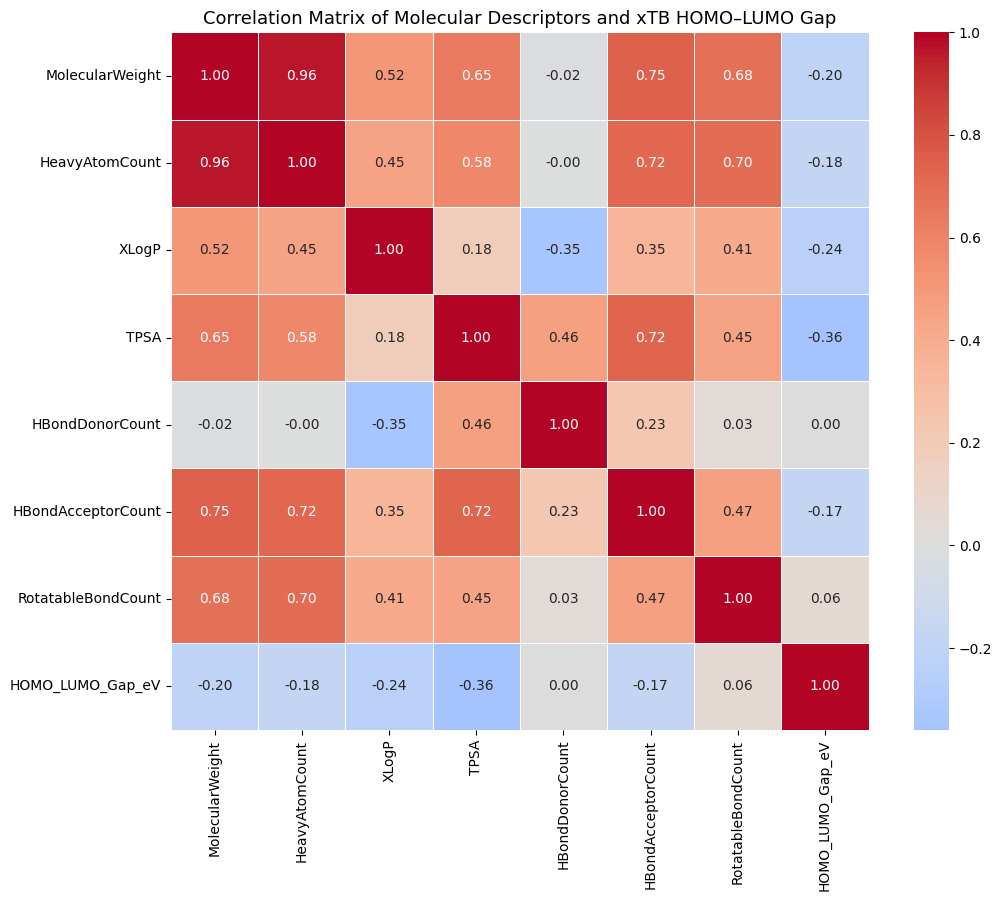


Figure 2 saved:
/content/DSTDPT_ML_Project/Figure_2_Correlation_Matrix.png


In [ ]:
# ============================================================
# STEP 43 — CORRELATION ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = "/content/DSTDPT_ML_Project"

target = "HOMO_LUMO_Gap_eV"

# ------------------------------------------------------------
# Load clean ML dataset
# ------------------------------------------------------------

df_ml = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_ML_dataset_100_molecules.csv"
    )
)

# Load cleaned descriptors
X_filtered = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_descriptor_matrix.csv"
    )
)

# ------------------------------------------------------------
# Combine descriptors + target
# ------------------------------------------------------------

corr_data = pd.concat(
    [
        X_filtered,
        df_ml[[target]]
    ],
    axis=1
)

corr_matrix = corr_data.corr(
    method="pearson"
)

print("=" * 70)
print("CORRELATION MATRIX")
print("=" * 70)

display(
    corr_matrix
)

# ------------------------------------------------------------
# Correlation heatmap
# ------------------------------------------------------------

plt.figure(
    figsize=(11, 9)
)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Molecular Descriptors and xTB HOMO–LUMO Gap",
    fontsize=13
)

plt.tight_layout()

figure2_path = os.path.join(
    PROJECT_DIR,
    "Figure_2_Correlation_Matrix.png"
)

plt.savefig(
    figure2_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    "\nFigure 2 saved:"
)

print(
    figure2_path
)

In [ ]:
# ============================================================
# STEP 43B — HIGH-CORRELATION DESCRIPTOR PAIRS
# ============================================================

threshold = 0.90

corr_features = X_filtered.corr().abs()

upper = corr_features.where(
    np.triu(
        np.ones(
            corr_features.shape
        ),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for col in upper.columns:

    for row in upper.index:

        value = upper.loc[
            row,
            col
        ]

        if pd.notna(value) and value >= threshold:

            high_corr_pairs.append(
                (
                    row,
                    col,
                    value
                )
            )

print("=" * 70)
print("HIGHLY CORRELATED DESCRIPTOR PAIRS")
print("=" * 70)

if len(high_corr_pairs) == 0:

    print(
        "No descriptor pairs with |r| >= 0.90"
    )

else:

    for pair in high_corr_pairs:

        print(
            f"{pair[0]}  <-->  {pair[1]}  "
            f"|r| = {pair[2]:.3f}"
        )

HIGHLY CORRELATED DESCRIPTOR PAIRS
MolecularWeight  <-->  HeavyAtomCount  |r| = 0.960


In [ ]:
# ============================================================
# STEP 43C — DESCRIPTOR/TARGET CORRELATION RANKING
# ============================================================

target_correlations = (
    corr_matrix[target]
    .drop(target)
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

print("=" * 70)
print("DESCRIPTOR–TARGET CORRELATION")
print("=" * 70)

for feature, value in target_correlations.items():

    print(
        f"{feature:30s} : r = {value:.4f}"
    )

DESCRIPTOR–TARGET CORRELATION
TPSA                           : r = -0.3594
XLogP                          : r = -0.2394
MolecularWeight                : r = -0.2023
HeavyAtomCount                 : r = -0.1755
HBondAcceptorCount             : r = -0.1738
RotatableBondCount             : r = 0.0613
HBondDonorCount                : r = 0.0017


In [ ]:
# ============================================================
# STEP 43D — SAVE CORRELATION RESULTS
# ============================================================

correlation_results = pd.DataFrame({
    "Descriptor":
        target_correlations.index,
    "Pearson_r":
        target_correlations.values,
    "Absolute_r":
        np.abs(
            target_correlations.values
        )
})

correlation_file = os.path.join(
    PROJECT_DIR,
    "descriptor_target_correlations.csv"
)

correlation_results.to_csv(
    correlation_file,
    index=False
)

print(
    "Correlation ranking saved:"
)

print(
    correlation_file
)

Correlation ranking saved:
/content/DSTDPT_ML_Project/descriptor_target_correlations.csv


In [ ]:
# ============================================================
# STEP 44A — MUTUAL INFORMATION FEATURE SELECTION
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.feature_selection import mutual_info_regression

PROJECT_DIR = "/content/DSTDPT_ML_Project"

# ------------------------------------------------------------
# Load clean data
# ------------------------------------------------------------

df_ml = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_ML_dataset_100_molecules.csv"
    )
)

X_filtered = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_descriptor_matrix.csv"
    )
)

target = "HOMO_LUMO_Gap_eV"

y = df_ml[target].values

# ------------------------------------------------------------
# Calculate mutual information
# ------------------------------------------------------------

mi_scores = mutual_info_regression(
    X_filtered,
    y,
    random_state=42
)

mi_results = pd.DataFrame({
    "Descriptor":
        X_filtered.columns,
    "Mutual_Information":
        mi_scores
})

mi_results = mi_results.sort_values(
    "Mutual_Information",
    ascending=False
).reset_index(
    drop=True
)

print("=" * 70)
print("MUTUAL INFORMATION FEATURE RANKING")
print("=" * 70)

display(
    mi_results
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

mi_file = os.path.join(
    PROJECT_DIR,
    "mutual_information_ranking.csv"
)

mi_results.to_csv(
    mi_file,
    index=False
)

print(
    "\nSaved:",
    mi_file
)

MUTUAL INFORMATION FEATURE RANKING


,Descriptor,Mutual_Information
0,HBondAcceptorCount,0.117014
1,HeavyAtomCount,0.101567
2,TPSA,0.088648
3,XLogP,0.014564
4,RotatableBondCount,0.005238
5,MolecularWeight,0.000000
6,HBondDonorCount,0.000000



Saved: /content/DSTDPT_ML_Project/mutual_information_ranking.csv


In [ ]:
# ============================================================
# STEP 44B — RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    max_features="sqrt"
)

rf.fit(
    X_filtered,
    y
)

rf_results = pd.DataFrame({
    "Descriptor":
        X_filtered.columns,
    "RF_Importance":
        rf.feature_importances_
})

rf_results = rf_results.sort_values(
    "RF_Importance",
    ascending=False
).reset_index(
    drop=True
)

print("=" * 70)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 70)

display(
    rf_results
)

rf_file = os.path.join(
    PROJECT_DIR,
    "random_forest_feature_importance.csv"
)

rf_results.to_csv(
    rf_file,
    index=False
)

print(
    "\nSaved:",
    rf_file
)

RANDOM FOREST FEATURE IMPORTANCE


,Descriptor,RF_Importance
0,TPSA,0.224671
1,MolecularWeight,0.173000
2,XLogP,0.147531
3,RotatableBondCount,0.134420
4,HeavyAtomCount,0.126954
5,HBondAcceptorCount,0.110705
6,HBondDonorCount,0.082720



Saved: /content/DSTDPT_ML_Project/random_forest_feature_importance.csv


CONSENSUS FEATURE RANKING


,Descriptor,Absolute_r,Mutual_Information,RF_Importance,Pearson_Score,MI_Score,RF_Score,Consensus_Score
0,TPSA,0.359383,0.088648,0.224671,1.000000,0.757584,1.000000,0.919195
1,HBondAcceptorCount,0.173823,0.117014,0.110705,0.483670,1.000000,0.492743,0.658804
2,HeavyAtomCount,0.175499,0.101567,0.126954,0.488335,0.867991,0.565068,0.640465
3,XLogP,0.239378,0.014564,0.147531,0.666081,0.124464,0.656655,0.482400
4,MolecularWeight,0.202312,0.000000,0.173000,0.562944,0.000000,0.770015,0.444320
5,RotatableBondCount,0.061306,0.005238,0.134420,0.170587,0.044767,0.598298,0.271217
6,HBondDonorCount,0.001713,0.000000,0.082720,0.004766,0.000000,0.368182,0.124316


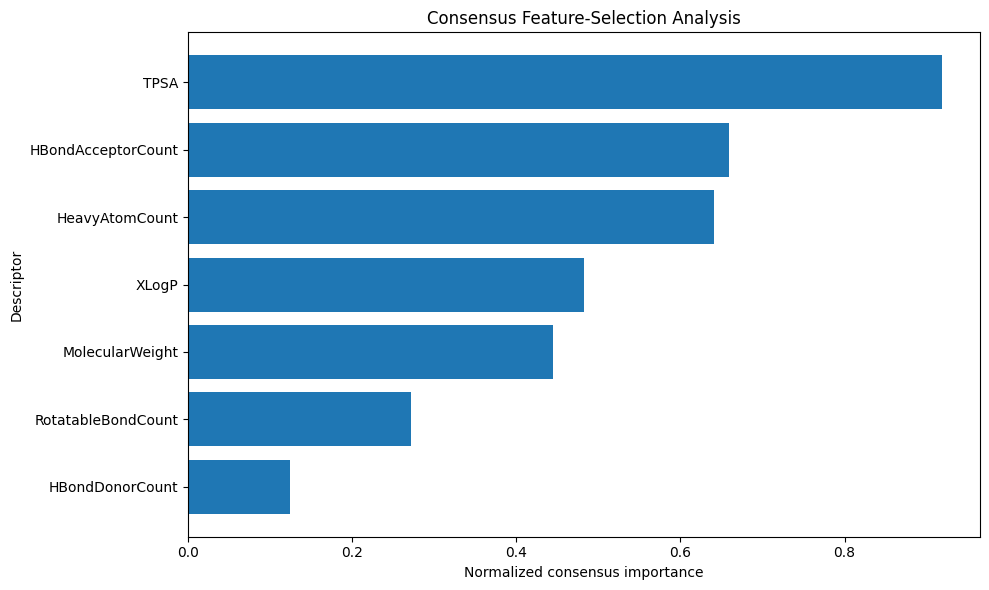


Figure 3 saved:
/content/DSTDPT_ML_Project/Figure_3_Feature_Selection.png


In [ ]:
# ============================================================
# STEP 44C — FEATURE SELECTION COMPARISON FIGURE
# ============================================================

import matplotlib.pyplot as plt

# Merge Pearson correlation and MI
feature_selection = pd.DataFrame({
    "Descriptor": X_filtered.columns
})

feature_selection = feature_selection.merge(
    correlation_results[
        [
            "Descriptor",
            "Absolute_r"
        ]
    ],
    on="Descriptor",
    how="left"
)

feature_selection = feature_selection.merge(
    mi_results[
        [
            "Descriptor",
            "Mutual_Information"
        ]
    ],
    on="Descriptor",
    how="left"
)

feature_selection = feature_selection.merge(
    rf_results[
        [
            "Descriptor",
            "RF_Importance"
        ]
    ],
    on="Descriptor",
    how="left"
)

# Normalize rankings to comparable 0–1 scales
feature_selection["Pearson_Score"] = (
    feature_selection["Absolute_r"]
    /
    feature_selection["Absolute_r"].max()
)

feature_selection["MI_Score"] = (
    feature_selection["Mutual_Information"]
    /
    feature_selection["Mutual_Information"].max()
)

feature_selection["RF_Score"] = (
    feature_selection["RF_Importance"]
    /
    feature_selection["RF_Importance"].max()
)

feature_selection["Consensus_Score"] = (
    feature_selection[
        [
            "Pearson_Score",
            "MI_Score",
            "RF_Score"
        ]
    ].mean(axis=1)
)

feature_selection = feature_selection.sort_values(
    "Consensus_Score",
    ascending=False
).reset_index(
    drop=True
)

print("=" * 70)
print("CONSENSUS FEATURE RANKING")
print("=" * 70)

display(
    feature_selection
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    feature_selection["Descriptor"],
    feature_selection["Consensus_Score"]
)

plt.xlabel(
    "Normalized consensus importance"
)

plt.ylabel(
    "Descriptor"
)

plt.title(
    "Consensus Feature-Selection Analysis"
)

plt.gca().invert_yaxis()

plt.tight_layout()

figure3_path = os.path.join(
    PROJECT_DIR,
    "Figure_3_Feature_Selection.png"
)

plt.savefig(
    figure3_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    "\nFigure 3 saved:"
)

print(
    figure3_path
)

In [ ]:
# ============================================================
# STEP 45 — DESCRIPTOR REDUNDANCY ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd

PROJECT_DIR = "/content/DSTDPT_ML_Project"

X_filtered = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_descriptor_matrix.csv"
    )
)

# Absolute descriptor-descriptor correlation
descriptor_corr = X_filtered.corr().abs()

print("=" * 70)
print("ABSOLUTE DESCRIPTOR-DESCRIPTOR CORRELATION")
print("=" * 70)

display(
    descriptor_corr.round(3)
)

# ------------------------------------------------------------
# Identify highly correlated pairs
# ------------------------------------------------------------

threshold = 0.85

upper = descriptor_corr.where(
    np.triu(
        np.ones(
            descriptor_corr.shape
        ),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for col in upper.columns:

    for row in upper.index:

        value = upper.loc[row, col]

        if pd.notna(value) and value >= threshold:

            high_corr_pairs.append(
                {
                    "Descriptor_1": row,
                    "Descriptor_2": col,
                    "Absolute_Correlation": value
                }
            )

high_corr_df = pd.DataFrame(
    high_corr_pairs
)

print("\n" + "=" * 70)
print("HIGH-CORRELATION PAIRS (|r| >= 0.85)")
print("=" * 70)

if len(high_corr_df) == 0:

    print(
        "No highly correlated descriptor pairs detected."
    )

else:

    display(
        high_corr_df.sort_values(
            "Absolute_Correlation",
            ascending=False
        )
    )

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

redundancy_file = os.path.join(
    PROJECT_DIR,
    "descriptor_redundancy_analysis.csv"
)

high_corr_df.to_csv(
    redundancy_file,
    index=False
)

print(
    "\nSaved:",
    redundancy_file
)

ABSOLUTE DESCRIPTOR-DESCRIPTOR CORRELATION


,MolecularWeight,HeavyAtomCount,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
MolecularWeight,1.000,0.960,0.516,0.646,0.018,0.746,0.683
HeavyAtomCount,0.960,1.000,0.449,0.585,0.004,0.719,0.696
XLogP,0.516,0.449,1.000,0.182,0.348,0.351,0.414
TPSA,0.646,0.585,0.182,1.000,0.465,0.724,0.453
HBondDonorCount,0.018,0.004,0.348,0.465,1.000,0.228,0.034
HBondAcceptorCount,0.746,0.719,0.351,0.724,0.228,1.000,0.466
RotatableBondCount,0.683,0.696,0.414,0.453,0.034,0.466,1.000



HIGH-CORRELATION PAIRS (|r| >= 0.85)


,Descriptor_1,Descriptor_2,Absolute_Correlation
0,MolecularWeight,HeavyAtomCount,0.960237



Saved: /content/DSTDPT_ML_Project/descriptor_redundancy_analysis.csv


In [ ]:
# ============================================================
# STEP 45B — DEFINE CANDIDATE FEATURE SETS
# ============================================================

feature_selection = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "descriptor_target_correlations.csv"
    )
)

# Current consensus ranking generated in Step 44C
consensus_file = os.path.join(
    PROJECT_DIR,
    "consensus_feature_ranking.csv"
)

# Recreate consensus table if file does not exist
if not os.path.exists(consensus_file):

    # Load previous ranking components
    mi_results = pd.read_csv(
        os.path.join(
            PROJECT_DIR,
            "mutual_information_ranking.csv"
        )
    )

    rf_results = pd.read_csv(
        os.path.join(
            PROJECT_DIR,
            "random_forest_feature_importance.csv"
        )
    )

    corr_results = pd.read_csv(
        os.path.join(
            PROJECT_DIR,
            "descriptor_target_correlations.csv"
        )
    )

    consensus = corr_results[
        [
            "Descriptor",
            "Absolute_r"
        ]
    ].copy()

    consensus = consensus.merge(
        mi_results[
            [
                "Descriptor",
                "Mutual_Information"
            ]
        ],
        on="Descriptor"
    )

    consensus = consensus.merge(
        rf_results[
            [
                "Descriptor",
                "RF_Importance"
            ]
        ],
        on="Descriptor"
    )

    consensus["Pearson_Score"] = (
        consensus["Absolute_r"]
        /
        consensus["Absolute_r"].max()
    )

    consensus["MI_Score"] = (
        consensus["Mutual_Information"]
        /
        consensus["Mutual_Information"].max()
    )

    consensus["RF_Score"] = (
        consensus["RF_Importance"]
        /
        consensus["RF_Importance"].max()
    )

    consensus["Consensus_Score"] = (
        consensus[
            [
                "Pearson_Score",
                "MI_Score",
                "RF_Score"
            ]
        ].mean(axis=1)
    )

    consensus = consensus.sort_values(
        "Consensus_Score",
        ascending=False
    )

    consensus.to_csv(
        consensus_file,
        index=False
    )

else:

    consensus = pd.read_csv(
        consensus_file
    )

print("=" * 70)
print("CONSENSUS RANKING")
print("=" * 70)

display(
    consensus[
        [
            "Descriptor",
            "Consensus_Score"
        ]
    ]
)

CONSENSUS RANKING


,Descriptor,Consensus_Score
0,TPSA,0.919195
4,HBondAcceptorCount,0.658804
3,HeavyAtomCount,0.640465
1,XLogP,0.482400
2,MolecularWeight,0.444320
5,RotatableBondCount,0.271217
6,HBondDonorCount,0.124316


In [ ]:
# ============================================================
# STEP 45A — DESCRIPTOR REDUNDANCY ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd

PROJECT_DIR = "/content/DSTDPT_ML_Project"

X_filtered = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_descriptor_matrix.csv"
    )
)

# Absolute descriptor-descriptor correlation
descriptor_corr = X_filtered.corr().abs()

print("=" * 70)
print("ABSOLUTE DESCRIPTOR-DESCRIPTOR CORRELATION")
print("=" * 70)

display(
    descriptor_corr.round(3)
)

# ------------------------------------------------------------
# Find highly correlated pairs
# ------------------------------------------------------------

threshold = 0.85

upper = descriptor_corr.where(
    np.triu(
        np.ones(descriptor_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for col in upper.columns:

    for row in upper.index:

        value = upper.loc[row, col]

        if pd.notna(value) and value >= threshold:

            high_corr_pairs.append(
                {
                    "Descriptor_1": row,
                    "Descriptor_2": col,
                    "Absolute_Correlation": value
                }
            )

high_corr_df = pd.DataFrame(
    high_corr_pairs
)

print("\n" + "=" * 70)
print("HIGHLY CORRELATED PAIRS |r| >= 0.85")
print("=" * 70)

if len(high_corr_df) == 0:

    print(
        "No highly correlated descriptor pairs detected."
    )

else:

    display(
        high_corr_df.sort_values(
            "Absolute_Correlation",
            ascending=False
        )
    )

# Save result
redundancy_file = os.path.join(
    PROJECT_DIR,
    "descriptor_redundancy_analysis.csv"
)

high_corr_df.to_csv(
    redundancy_file,
    index=False
)

print(
    "\nSaved:",
    redundancy_file
)

ABSOLUTE DESCRIPTOR-DESCRIPTOR CORRELATION


,MolecularWeight,HeavyAtomCount,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
MolecularWeight,1.000,0.960,0.516,0.646,0.018,0.746,0.683
HeavyAtomCount,0.960,1.000,0.449,0.585,0.004,0.719,0.696
XLogP,0.516,0.449,1.000,0.182,0.348,0.351,0.414
TPSA,0.646,0.585,0.182,1.000,0.465,0.724,0.453
HBondDonorCount,0.018,0.004,0.348,0.465,1.000,0.228,0.034
HBondAcceptorCount,0.746,0.719,0.351,0.724,0.228,1.000,0.466
RotatableBondCount,0.683,0.696,0.414,0.453,0.034,0.466,1.000



HIGHLY CORRELATED PAIRS |r| >= 0.85


,Descriptor_1,Descriptor_2,Absolute_Correlation
0,MolecularWeight,HeavyAtomCount,0.960237



Saved: /content/DSTDPT_ML_Project/descriptor_redundancy_analysis.csv


In [ ]:
# ============================================================
# STEP 45B — RESOLVE HIGHLY CORRELATED DESCRIPTORS
# ============================================================

import os
import pandas as pd

PROJECT_DIR = "/content/DSTDPT_ML_Project"

# Consensus ranking from Step 44
consensus = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "consensus_feature_ranking.csv"
    )
)

print("=" * 70)
print("CONSENSUS RANKING")
print("=" * 70)

display(
    consensus[
        [
            "Descriptor",
            "Consensus_Score"
        ]
    ]
)

# ------------------------------------------------------------
# Redundant pair identified in Step 45A
# ------------------------------------------------------------

redundant_pair = [
    "MolecularWeight",
    "HeavyAtomCount"
]

# Extract consensus scores
scores = {}

for descriptor in redundant_pair:

    row = consensus[
        consensus["Descriptor"] == descriptor
    ]

    if len(row) == 0:

        raise KeyError(
            f"{descriptor} not found in consensus ranking."
        )

    scores[descriptor] = float(
        row["Consensus_Score"].iloc[0]
    )

print("\n" + "=" * 70)
print("REDUNDANT PAIR")
print("=" * 70)

for descriptor, score in scores.items():

    print(
        f"{descriptor}: {score:.6f}"
    )

# ------------------------------------------------------------
# Select the descriptor with higher consensus score
# ------------------------------------------------------------

retain_descriptor = max(
    scores,
    key=scores.get
)

remove_descriptor = min(
    scores,
    key=scores.get
)

print(
    "\nDescriptor retained:",
    retain_descriptor
)

print(
    "Descriptor removed:",
    remove_descriptor
)

CONSENSUS RANKING


,Descriptor,Consensus_Score
0,TPSA,0.919195
1,HBondAcceptorCount,0.658804
2,HeavyAtomCount,0.640465
3,XLogP,0.482400
4,MolecularWeight,0.444320
5,RotatableBondCount,0.271217
6,HBondDonorCount,0.124316



REDUNDANT PAIR
MolecularWeight: 0.444320
HeavyAtomCount: 0.640465

Descriptor retained: HeavyAtomCount
Descriptor removed: MolecularWeight


In [ ]:
# ============================================================
# STEP 46 — FINAL DESCRIPTOR SET AFTER REDUNDANCY FILTERING
# ============================================================

final_features = [
    "TPSA",
    "HBondAcceptorCount",
    "HeavyAtomCount",
    "XLogP"
]

print("=" * 70)
print("FINAL DESCRIPTOR SET")
print("=" * 70)

for i, feature in enumerate(
    final_features,
    1
):

    print(
        f"{i}. {feature}"
    )

# Verify
X_filtered = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_descriptor_matrix.csv"
    )
)

missing_features = [
    feature
    for feature in final_features
    if feature not in X_filtered.columns
]

if missing_features:

    raise KeyError(
        f"Missing descriptors: {missing_features}"
    )

print(
    "\n✓ All final descriptors are available."
)

FINAL DESCRIPTOR SET
1. TPSA
2. HBondAcceptorCount
3. HeavyAtomCount
4. XLogP

✓ All final descriptors are available.


In [ ]:
# ============================================================
# STEP 47 — FINAL ML MATRIX
# ============================================================

import os
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/DSTDPT_ML_Project"

df_ml = pd.read_csv(
    os.path.join(
        PROJECT_DIR,
        "clean_ML_dataset_100_molecules.csv"
    )
)

target = "HOMO_LUMO_Gap_eV"

final_features = [
    "TPSA",
    "HBondAcceptorCount",
    "HeavyAtomCount",
    "XLogP"
]

X_final = df_ml[
    final_features
].copy()

y_final = df_ml[
    target
].copy()

print("=" * 70)
print("FINAL ML MATRIX")
print("=" * 70)

print("Number of molecules:", len(df_ml))
print("Number of descriptors:", len(final_features))
print("X shape:", X_final.shape)
print("y shape:", y_final.shape)

print("\nMissing descriptor values:")
print(X_final.isna().sum())

print(
    "\nMissing HOMO-LUMO gaps:",
    y_final.isna().sum()
)

print(
    "\n✓ Final ML matrix prepared."
)

FINAL ML MATRIX
Number of molecules: 100
Number of descriptors: 4
X shape: (100, 4)
y shape: (100,)

Missing descriptor values:
TPSA                  0
HBondAcceptorCount    0
HeavyAtomCount        0
XLogP                 3
dtype: int64

Missing HOMO-LUMO gaps: 0

✓ Final ML matrix prepared.


In [ ]:
# ============================================================
# STEP 48 — INDEPENDENT 80:20 TRAIN/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42
)

print("=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(
    "Training molecules:",
    len(X_train)
)

print(
    "Independent test molecules:",
    len(X_test)
)

print(
    "Training descriptor matrix:",
    X_train.shape
)

print(
    "Independent test matrix:",
    X_test.shape
)

print(
    "\nTraining target range:",
    y_train.min(),
    "to",
    y_train.max(),
    "eV"
)

print(
    "Test target range:",
    y_test.min(),
    "to",
    y_test.max(),
    "eV"
)

TRAIN / TEST SPLIT
Training molecules: 80
Independent test molecules: 20
Training descriptor matrix: (80, 4)
Independent test matrix: (20, 4)

Training target range: 0.729594449987 to 3.763633799733 eV
Test target range: 1.273631348718 to 3.359369504 eV


In [ ]:
# ============================================================
# STEP 49 — SAVE FINAL TRAINING AND TEST DATASETS
# ============================================================

train_data = X_train.copy()

train_data[target] = y_train.values

test_data = X_test.copy()

test_data[target] = y_test.values

train_file = os.path.join(
    PROJECT_DIR,
    "ML_training_set_80.csv"
)

test_file = os.path.join(
    PROJECT_DIR,
    "ML_independent_test_set_20.csv"
)

train_data.to_csv(
    train_file,
    index=False
)

test_data.to_csv(
    test_file,
    index=False
)

print("=" * 70)
print("DATASETS SAVED")
print("=" * 70)

print(
    "Training set:",
    train_file
)

print(
    "Independent test set:",
    test_file
)

DATASETS SAVED
Training set: /content/DSTDPT_ML_Project/ML_training_set_80.csv
Independent test set: /content/DSTDPT_ML_Project/ML_independent_test_set_20.csv


In [ ]:
# ============================================================
# STEP 50 — TRAINING-ONLY STANDARDIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("=" * 70)
print("STANDARDIZATION")
print("=" * 70)

print(
    "X_train_scaled:",
    X_train_scaled.shape
)

print(
    "X_test_scaled:",
    X_test_scaled.shape
)

print(
    "\n✓ Scaler fitted only using the training set."
)

STANDARDIZATION
X_train_scaled: (80, 4)
X_test_scaled: (20, 4)

✓ Scaler fitted only using the training set.


In [ ]:
# ============================================================
# STEP 51 — CROSS-VALIDATED MODEL COMPARISON
# ============================================================

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    RandomForestRegressor
)

from sklearn.svm import SVR

# ------------------------------------------------------------
# 5-fold cross-validation
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# Models
# ------------------------------------------------------------

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge":
        Ridge(alpha=1.0),

    "Lasso":
        Lasso(
            alpha=0.01,
            max_iter=10000
        ),

    "Elastic Net":
        ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            max_iter=10000
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=2,
            random_state=42
        ),

    "SVR":
        SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1,
            gamma="scale"
        )
}

# ------------------------------------------------------------
# Evaluate using training data only
# ------------------------------------------------------------

results = []

for name, model in models.items():

    pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            model
        )
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "R2": "r2",
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error"
        },
        n_jobs=-1
    )

    mean_r2 = scores[
        "test_R2"
    ].mean()

    mean_rmse = -scores[
        "test_RMSE"
    ].mean()

    mean_mae = -scores[
        "test_MAE"
    ].mean()

    results.append({
        "Model": name,
        "CV_R2": mean_r2,
        "CV_RMSE_eV": mean_rmse,
        "CV_MAE_eV": mean_mae
    })

cv_results_df = pd.DataFrame(
    results
)

cv_results_df = cv_results_df.sort_values(
    "CV_R2",
    ascending=False
).reset_index(
    drop=True
)

print("=" * 70)
print("CROSS-VALIDATED MODEL COMPARISON")
print("=" * 70)

display(
    cv_results_df
)

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
     

In [ ]:
# ============================================================
# STEP 51A — CHECK MISSING VALUES IN FINAL ML DATA
# ============================================================

print("=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)

print("\nTraining set:")
print(X_train.isna().sum())

print("\nIndependent test set:")
print(X_test.isna().sum())

print("\nTotal training NaN values:",
      X_train.isna().sum().sum())

print("Total test NaN values:",
      X_test.isna().sum().sum())

MISSING VALUE CHECK

Training set:
TPSA                  0
HBondAcceptorCount    0
HeavyAtomCount        0
XLogP                 3
dtype: int64

Independent test set:
TPSA                  0
HBondAcceptorCount    0
HeavyAtomCount        0
XLogP                 0
dtype: int64

Total training NaN values: 3
Total test NaN values: 0


In [ ]:
# ============================================================
# STEP 51B — LEAKAGE-SAFE CROSS-VALIDATED MODEL COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR


# ============================================================
# 1. VERIFY DATA
# ============================================================

print("=" * 70)
print("FINAL ML DATA VERIFICATION")
print("=" * 70)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print(
    "Training missing values:",
    X_train.isna().sum().sum()
)

print(
    "Test missing values:",
    X_test.isna().sum().sum()
)


# ============================================================
# 2. CROSS-VALIDATION
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 3. MODELS
# ============================================================

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge":
        Ridge(alpha=1.0),

    "Lasso":
        Lasso(
            alpha=0.01,
            max_iter=10000
        ),

    "Elastic Net":
        ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            max_iter=10000
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=2,
            random_state=42
        ),

    "SVR":
        SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1,
            gamma="scale"
        )
}


# ============================================================
# 4. CROSS-VALIDATED EVALUATION
# ============================================================

results = []

for name, model in models.items():

    # Imputation and scaling occur INSIDE each CV fold
    pipeline = Pipeline([

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            model
        )
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,

        scoring={
            "R2": "r2",
            "RMSE":
                "neg_root_mean_squared_error",
            "MAE":
                "neg_mean_absolute_error"
        },

        n_jobs=-1,

        error_score="raise"
    )

    mean_r2 = scores[
        "test_R2"
    ].mean()

    mean_rmse = -scores[
        "test_RMSE"
    ].mean()

    mean_mae = -scores[
        "test_MAE"
    ].mean()

    std_r2 = scores[
        "test_R2"
    ].std()

    results.append({

        "Model":
            name,

        "CV_R2":
            mean_r2,

        "CV_R2_SD":
            std_r2,

        "CV_RMSE_eV":
            mean_rmse,

        "CV_MAE_eV":
            mean_mae
    })


# ============================================================
# 5. RESULTS TABLE
# ============================================================

cv_results_df = pd.DataFrame(
    results
)

cv_results_df = cv_results_df.sort_values(
    "CV_R2",
    ascending=False
).reset_index(
    drop=True
)

print("\n" + "=" * 70)
print("CROSS-VALIDATED MODEL COMPARISON")
print("=" * 70)

display(
    cv_results_df.round(4)
)


# ============================================================
# 6. SAVE RESULTS
# ============================================================

PROJECT_DIR = "/content/DSTDPT_ML_Project"

cv_file = os.path.join(
    PROJECT_DIR,
    "CV_model_comparison_results.csv"
)

cv_results_df.to_csv(
    cv_file,
    index=False
)

print(
    "\nCV results saved:"
)

print(
    cv_file
)

FINAL ML DATA VERIFICATION
Training shape: (80, 4)
Test shape: (20, 4)
Training missing values: 3
Test missing values: 0

CROSS-VALIDATED MODEL COMPARISON


,Model,CV_R2,CV_R2_SD,CV_RMSE_eV,CV_MAE_eV
0,Lasso,-0.0492,0.1262,0.6157,0.5015
1,Elastic Net,-0.0511,0.1368,0.6167,0.5043
2,Ridge,-0.0535,0.1471,0.6177,0.5062
3,Linear Regression,-0.0580,0.1512,0.6192,0.5093
4,Random Forest,-0.1281,0.1691,0.6323,0.5062
5,Gradient Boosting,-0.1374,0.1550,0.6340,0.5029
6,Extra Trees,-0.1588,0.1778,0.6435,0.5080
7,SVR,-0.2532,0.3531,0.6728,0.5371



CV results saved:
/content/DSTDPT_ML_Project/CV_model_comparison_results.csv


In [ ]:
# ============================================================
# STEP 51C — CHECK TARGET DISTRIBUTION
# ============================================================

print("=" * 70)
print("HOMO–LUMO GAP DISTRIBUTION")
print("=" * 70)

print(
    y_final.describe()
)

print(
    "\nTraining target mean:",
    y_train.mean()
)

print(
    "Test target mean:",
    y_test.mean()
)

print(
    "\nTraining target SD:",
    y_train.std()
)

print(
    "Test target SD:",
    y_test.std()
)

HOMO–LUMO GAP DISTRIBUTION
count    100.000000
mean       2.582793
std        0.635783
min        0.729594
25%        2.215015
50%        2.773259
75%        3.036340
max        3.763634
Name: HOMO_LUMO_Gap_eV, dtype: float64

Training target mean: 2.6134002852504
Test target mean: 2.4603663487372

Training target SD: 0.6270623147761357
Test target SD: 0.6719869021155702


In [ ]:
# ============================================================
# STEP 51B — LEAKAGE-SAFE CROSS-VALIDATED MODEL COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR


# ============================================================
# 1. VERIFY DATA
# ============================================================

print("=" * 70)
print("FINAL ML DATA VERIFICATION")
print("=" * 70)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print(
    "Training missing values:",
    X_train.isna().sum().sum()
)

print(
    "Test missing values:",
    X_test.isna().sum().sum()
)


# ============================================================
# 2. CROSS-VALIDATION
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 3. MODELS
# ============================================================

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge":
        Ridge(alpha=1.0),

    "Lasso":
        Lasso(
            alpha=0.01,
            max_iter=10000
        ),

    "Elastic Net":
        ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            max_iter=10000
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=2,
            random_state=42
        ),

    "SVR":
        SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1,
            gamma="scale"
        )
}


# ============================================================
# 4. CROSS-VALIDATED EVALUATION
# ============================================================

results = []

for name, model in models.items():

    # Imputation and scaling occur INSIDE each CV fold
    pipeline = Pipeline([

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            model
        )
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,

        scoring={
            "R2": "r2",
            "RMSE":
                "neg_root_mean_squared_error",
            "MAE":
                "neg_mean_absolute_error"
        },

        n_jobs=-1,

        error_score="raise"
    )

    mean_r2 = scores[
        "test_R2"
    ].mean()

    mean_rmse = -scores[
        "test_RMSE"
    ].mean()

    mean_mae = -scores[
        "test_MAE"
    ].mean()

    std_r2 = scores[
        "test_R2"
    ].std()

    results.append({

        "Model":
            name,

        "CV_R2":
            mean_r2,

        "CV_R2_SD":
            std_r2,

        "CV_RMSE_eV":
            mean_rmse,

        "CV_MAE_eV":
            mean_mae
    })


# ============================================================
# 5. RESULTS TABLE
# ============================================================

cv_results_df = pd.DataFrame(
    results
)

cv_results_df = cv_results_df.sort_values(
    "CV_R2",
    ascending=False
).reset_index(
    drop=True
)

print("\n" + "=" * 70)
print("CROSS-VALIDATED MODEL COMPARISON")
print("=" * 70)

display(
    cv_results_df.round(4)
)


# ============================================================
# 6. SAVE RESULTS
# ============================================================

PROJECT_DIR = "/content/DSTDPT_ML_Project"

cv_file = os.path.join(
    PROJECT_DIR,
    "CV_model_comparison_results.csv"
)

cv_results_df.to_csv(
    cv_file,
    index=False
)

print(
    "\nCV results saved:"
)

print(
    cv_file
)

FINAL ML DATA VERIFICATION
Training shape: (80, 4)
Test shape: (20, 4)
Training missing values: 3
Test missing values: 0

CROSS-VALIDATED MODEL COMPARISON


,Model,CV_R2,CV_R2_SD,CV_RMSE_eV,CV_MAE_eV
0,Lasso,-0.0492,0.1262,0.6157,0.5015
1,Elastic Net,-0.0511,0.1368,0.6167,0.5043
2,Ridge,-0.0535,0.1471,0.6177,0.5062
3,Linear Regression,-0.0580,0.1512,0.6192,0.5093
4,Random Forest,-0.1281,0.1691,0.6323,0.5062
5,Gradient Boosting,-0.1374,0.1550,0.6340,0.5029
6,Extra Trees,-0.1588,0.1778,0.6435,0.5080
7,SVR,-0.2532,0.3531,0.6728,0.5371



CV results saved:
/content/DSTDPT_ML_Project/CV_model_comparison_results.csv


In [ ]:
# ============================================================
# STEP 51B — LEAKAGE-SAFE CROSS-VALIDATED MODEL COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR


# ============================================================
# 1. VERIFY DATA
# ============================================================

print("=" * 70)
print("FINAL ML DATA VERIFICATION")
print("=" * 70)

print(
    "Training shape:",
    X_train.shape
)

print(
    "Test shape:",
    X_test.shape
)

print(
    "Training missing values:",
    X_train.isna().sum().sum()
)

print(
    "Test missing values:",
    X_test.isna().sum().sum()
)


# ============================================================
# 2. 5-FOLD CROSS-VALIDATION
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 3. DEFINE ML MODELS
# ============================================================

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge":
        Ridge(
            alpha=1.0
        ),

    "Lasso":
        Lasso(
            alpha=0.01,
            max_iter=10000
        ),

    "Elastic Net":
        ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            max_iter=10000
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt"
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=2,
            random_state=42
        ),

    "SVR":
        SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1,
            gamma="scale"
        )
}


# ============================================================
# 4. CROSS-VALIDATED MODEL EVALUATION
# ============================================================

results = []


for name, model in models.items():

    print(
        f"\nRunning: {name}"
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # Imputation and scaling are performed INSIDE CV.
    # --------------------------------------------------------

    pipeline = Pipeline([

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            model
        )
    ])

    scores = cross_validate(

        pipeline,

        X_train,

        y_train,

        cv=cv,

        scoring={

            "R2":
                "r2",

            "RMSE":
                "neg_root_mean_squared_error",

            "MAE":
                "neg_mean_absolute_error"
        },

        n_jobs=-1,

        error_score="raise"
    )

    # --------------------------------------------------------
    # Calculate mean CV metrics
    # --------------------------------------------------------

    mean_r2 = scores[
        "test_R2"
    ].mean()

    std_r2 = scores[
        "test_R2"
    ].std()

    mean_rmse = -scores[
        "test_RMSE"
    ].mean()

    std_rmse = scores[
        "test_RMSE"
    ].std()

    mean_mae = -scores[
        "test_MAE"
    ].mean()

    std_mae = scores[
        "test_MAE"
    ].std()

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results.append({

        "Model":
            name,

        "CV_R2":
            mean_r2,

        "CV_R2_SD":
            std_r2,

        "CV_RMSE_eV":
            mean_rmse,

        "CV_RMSE_SD":
            std_rmse,

        "CV_MAE_eV":
            mean_mae,

        "CV_MAE_SD":
            std_mae
    })


# ============================================================
# 5. CREATE RESULTS TABLE
# ============================================================

cv_results_df = pd.DataFrame(
    results
)

# Rank primarily by CV R²
cv_results_df = cv_results_df.sort_values(
    "CV_R2",
    ascending=False
).reset_index(
    drop=True
)


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("CROSS-VALIDATED MODEL COMPARISON")
print("=" * 70)

display(
    cv_results_df.round(4)
)


# ============================================================
# 7. IDENTIFY BEST MODEL
# ============================================================

best_model_name = cv_results_df.iloc[0]["Model"]

print("\n" + "=" * 70)
print("BEST MODEL BASED ON 5-FOLD CV")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    "CV R²:",
    round(
        cv_results_df.iloc[0]["CV_R2"],
        4
    )
)

print(
    "CV RMSE:",
    round(
        cv_results_df.iloc[0]["CV_RMSE_eV"],
        4
    ),
    "eV"
)

print(
    "CV MAE:",
    round(
        cv_results_df.iloc[0]["CV_MAE_eV"],
        4
    ),
    "eV"
)


# ============================================================
# 8. SAVE RESULTS
# ============================================================

PROJECT_DIR = "/content/DSTDPT_ML_Project"

cv_file = os.path.join(
    PROJECT_DIR,
    "CV_model_comparison_results.csv"
)

cv_results_df.to_csv(
    cv_file,
    index=False
)

print(
    "\nCV results saved:"
)

print(
    cv_file
)

FINAL ML DATA VERIFICATION
Training shape: (80, 4)
Test shape: (20, 4)
Training missing values: 3
Test missing values: 0

Running: Linear Regression

Running: Ridge

Running: Lasso

Running: Elastic Net

Running: Random Forest

Running: Extra Trees

Running: Gradient Boosting

Running: SVR


CROSS-VALIDATED MODEL COMPARISON


,Model,CV_R2,CV_R2_SD,CV_RMSE_eV,CV_RMSE_SD,CV_MAE_eV,CV_MAE_SD
0,Lasso,-0.0492,0.1262,0.6157,0.1179,0.5015,0.0934
1,Elastic Net,-0.0511,0.1368,0.6167,0.1217,0.5043,0.0984
2,Ridge,-0.0535,0.1471,0.6177,0.1248,0.5062,0.1025
3,Linear Regression,-0.0580,0.1512,0.6192,0.1265,0.5093,0.1046
4,Random Forest,-0.1281,0.1691,0.6323,0.1001,0.5062,0.0925
5,Gradient Boosting,-0.1374,0.1550,0.6340,0.0877,0.5029,0.0592
6,Extra Trees,-0.1588,0.1778,0.6435,0.1153,0.5080,0.0907
7,SVR,-0.2532,0.3531,0.6728,0.1700,0.5371,0.1613



BEST MODEL BASED ON 5-FOLD CV
Best model: Lasso
CV R²: -0.0492
CV RMSE: 0.6157 eV
CV MAE: 0.5015 eV

CV results saved:
/content/DSTDPT_ML_Project/CV_model_comparison_results.csv


In [ ]:
# ============================================================
# STEP 52 — BASELINE COMPARISON
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

baseline_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "model",
        DummyRegressor(strategy="mean")
    )
])

baseline_scores = cross_validate(

    baseline_pipeline,

    X_train,

    y_train,

    cv=cv,

    scoring={
        "R2": "r2",
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error"
    },

    n_jobs=-1
)

baseline_r2 = baseline_scores[
    "test_R2"
].mean()

baseline_rmse = -baseline_scores[
    "test_RMSE"
].mean()

baseline_mae = -baseline_scores[
    "test_MAE"
].mean()

print("=" * 70)
print("BASELINE MODEL")
print("=" * 70)

print(
    "Baseline CV R²:",
    round(baseline_r2, 4)
)

print(
    "Baseline CV RMSE:",
    round(baseline_rmse, 4),
    "eV"
)

print(
    "Baseline CV MAE:",
    round(baseline_mae, 4),
    "eV"
)

BASELINE MODEL
Baseline CV R²: -0.1121
Baseline CV RMSE: 0.6271 eV
Baseline CV MAE: 0.4979 eV


In [ ]:
# ============================================================
# STEP 53 — LASSO COEFFICIENT ANALYSIS
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        Lasso(
            alpha=0.01,
            max_iter=10000
        )
    )
])

lasso_pipeline.fit(
    X_train,
    y_train
)

lasso_model = lasso_pipeline[
    "model"
]

coefficients = pd.DataFrame({

    "Descriptor":
        final_features,

    "Coefficient":
        lasso_model.coef_,

    "Absolute_Coefficient":
        np.abs(
            lasso_model.coef_
        )
})

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(
    drop=True
)

print("=" * 70)
print("LASSO COEFFICIENT ANALYSIS")
print("=" * 70)

display(
    coefficients.round(6)
)

print(
    "\nLasso intercept:",
    lasso_model.intercept_
)

LASSO COEFFICIENT ANALYSIS


,Descriptor,Coefficient,Absolute_Coefficient
0,TPSA,-0.318301,0.318301
1,HBondAcceptorCount,0.139643,0.139643
2,XLogP,-0.098162,0.098162
3,HeavyAtomCount,0.027629,0.027629



Lasso intercept: 2.6134002852503997


In [ ]:
# ============================================================
# STEP 52 — BASELINE COMPARISON
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

baseline_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "model",
        DummyRegressor(strategy="mean")
    )
])

baseline_scores = cross_validate(

    baseline_pipeline,

    X_train,

    y_train,

    cv=cv,

    scoring={
        "R2": "r2",
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error"
    },

    n_jobs=-1
)

baseline_r2 = baseline_scores[
    "test_R2"
].mean()

baseline_rmse = -baseline_scores[
    "test_RMSE"
].mean()

baseline_mae = -baseline_scores[
    "test_MAE"
].mean()

print("=" * 70)
print("BASELINE MODEL")
print("=" * 70)

print(
    "Baseline CV R²:",
    round(baseline_r2, 4)
)

print(
    "Baseline CV RMSE:",
    round(baseline_rmse, 4),
    "eV"
)

print(
    "Baseline CV MAE:",
    round(baseline_mae, 4),
    "eV"
)

BASELINE MODEL
Baseline CV R²: -0.1121
Baseline CV RMSE: 0.6271 eV
Baseline CV MAE: 0.4979 eV


In [ ]:
# ============================================================
# STEP 54 — INVENTORY OF AVAILABLE DESCRIPTORS
# ============================================================

print("=" * 70)
print("AVAILABLE DESCRIPTORS")
print("=" * 70)

print("\nAll columns in df_ml:")

for i, col in enumerate(df_ml.columns, 1):
    print(f"{i:3d}. {col}")


# ------------------------------------------------------------
# Identify likely descriptor columns
# ------------------------------------------------------------

descriptor_keywords = [
    "Count",
    "TPSA",
    "XLogP",
    "HBA",
    "HBD",
    "HeavyAtom",
    "Rotatable",
    "Azo",
    "Carbonyl",
    "Sulfur",
    "Ring",
    "Fraction",
    "MolLogP"
]

candidate_descriptors = []

for col in df_ml.columns:

    if any(
        keyword.lower() in col.lower()
        for keyword in descriptor_keywords
    ):

        if col != target:
            candidate_descriptors.append(col)


print("\n" + "=" * 70)
print("POTENTIAL DESCRIPTOR COLUMNS")
print("=" * 70)

for i, col in enumerate(
    candidate_descriptors,
    1
):
    print(
        f"{i:3d}. {col}"
    )

print(
    "\nNumber of potential descriptors:",
    len(candidate_descriptors)
)

AVAILABLE DESCRIPTORS

All columns in df_ml:
  1. Molecule_ID
  2. CID
  3. MolecularFormula
  4. MolecularWeight
  5. SMILES
  6. ConnectivitySMILES
  7. InChIKey
  8. IUPACName
  9. XLogP
 10. TPSA
 11. HBondDonorCount
 12. HBondAcceptorCount
 13. RotatableBondCount
 14. HeavyAtomCount
 15. Mol
 16. Canonical_RDKit_SMILES
 17. Morgan_Tanimoto_DSTDPT
 18. MolecularWeight_RDKit
 19. LogP
 20. TPSA_RDKit
 21. HBD
 22. HBA
 23. RotatableBonds
 24. HeavyAtomCount_RDKit
 25. RingCount
 26. AromaticRingCount
 27. FractionCSP3
 28. MolecularVolume
 29. Carbon_Count
 30. Nitrogen_Count
 31. Oxygen_Count
 32. Sulfur_Count
 33. Hydrogen_Count
 34. Azo_Count
 35. Carbonyl_Count
 36. Hydroxyl_Count
 37. Thiol_Count
 38. Heteroatom_Count
 39. HOMO_LUMO_Gap_eV

POTENTIAL DESCRIPTOR COLUMNS
  1. XLogP
  2. TPSA
  3. HBondDonorCount
  4. HBondAcceptorCount
  5. RotatableBondCount
  6. HeavyAtomCount
  7. TPSA_RDKit
  8. HBD
  9. HBA
 10. RotatableBonds
 11. HeavyAtomCount_RDKit
 12. RingCount
 13. Ar

In [ ]:
# ============================================================
# STEP 55 — DESCRIPTOR COMPLETENESS CHECK
# ============================================================

descriptor_df = df_ml[
    candidate_descriptors
].copy()

missing_summary = pd.DataFrame({

    "Descriptor":
        descriptor_df.columns,

    "Missing":
        descriptor_df.isna().sum(),

    "Available":
        descriptor_df.notna().sum(),

    "Missing_%":
        (
            descriptor_df.isna().sum()
            /
            len(descriptor_df)
            *
            100
        )
})

missing_summary = missing_summary.sort_values(
    "Missing",
    ascending=True
).reset_index(
    drop=True
)

print("=" * 70)
print("DESCRIPTOR COMPLETENESS")
print("=" * 70)

display(
    missing_summary.round(2)
)

DESCRIPTOR COMPLETENESS


,Descriptor,Missing,Available,Missing_%
0,TPSA,0,100,0.0
1,HBondDonorCount,0,100,0.0
2,HBondAcceptorCount,0,100,0.0
3,RotatableBondCount,0,100,0.0
4,TPSA_RDKit,0,100,0.0
5,HeavyAtomCount,0,100,0.0
6,HBD,0,100,0.0
7,HBA,0,100,0.0
8,AromaticRingCount,0,100,0.0
9,RotatableBonds,0,100,0.0


In [ ]:
# ============================================================
# STEP 56 — PEARSON CORRELATION SCREENING
# ============================================================

correlation_results = []

for descriptor in candidate_descriptors:

    temp = df_ml[
        [descriptor, target]
    ].copy()

    temp = temp.dropna()

    if len(temp) >= 10:

        r = temp[
            descriptor
        ].corr(
            temp[target]
        )

        correlation_results.append({

            "Descriptor":
                descriptor,

            "Pearson_r":
                r,

            "Absolute_r":
                abs(r),

            "N":
                len(temp)
        })


descriptor_correlation_df = pd.DataFrame(
    correlation_results
)

descriptor_correlation_df = (
    descriptor_correlation_df
    .sort_values(
        "Absolute_r",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print("=" * 70)
print("DESCRIPTOR–HOMO–LUMO GAP CORRELATION")
print("=" * 70)

display(
    descriptor_correlation_df.round(4)
)

DESCRIPTOR–HOMO–LUMO GAP CORRELATION


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Descriptor,Pearson_r,Absolute_r,N
0,Azo_Count,-0.3749,0.3749,100
1,TPSA,-0.3594,0.3594,100
2,HBA,-0.3567,0.3567,100
3,Sulfur_Count,-0.3465,0.3465,100
4,Heteroatom_Count,-0.3408,0.3408,100
5,FractionCSP3,0.3210,0.3210,100
6,RingCount,-0.3177,0.3177,100
7,Nitrogen_Count,-0.2713,0.2713,100
8,XLogP,-0.2446,0.2446,97
9,Thiol_Count,-0.2080,0.2080,100


In [ ]:
# ============================================================
# STEP 57 — CHEMICALLY MEANINGFUL DESCRIPTOR POOL
# ============================================================

descriptor_pool = [

    # General molecular descriptors
    "TPSA",
    "XLogP",
    "HBondDonorCount",
    "HBondAcceptorCount",
    "RotatableBondCount",
    "HeavyAtomCount",
    "RingCount",
    "AromaticRingCount",
    "FractionCSP3",

    # Elemental composition
    "Carbon_Count",
    "Nitrogen_Count",
    "Oxygen_Count",
    "Sulfur_Count",

    # Functional-group descriptors
    "Azo_Count",
    "Carbonyl_Count",
    "Hydroxyl_Count",
    "Thiol_Count",
    "Heteroatom_Count"
]


# ------------------------------------------------------------
# Check availability
# ------------------------------------------------------------

available_features = [
    f for f in descriptor_pool
    if f in df_ml.columns
]

missing_features = [
    f for f in descriptor_pool
    if f not in df_ml.columns
]


print("=" * 70)
print("CHEMICALLY MEANINGFUL DESCRIPTOR POOL")
print("=" * 70)

print(
    "Available descriptors:",
    len(available_features)
)

for i, feature in enumerate(
    available_features,
    1
):
    print(
        f"{i:2d}. {feature}"
    )

if missing_features:

    print("\nMissing descriptors:")

    for feature in missing_features:
        print(
            " -",
            feature
        )

CHEMICALLY MEANINGFUL DESCRIPTOR POOL
Available descriptors: 18
 1. TPSA
 2. XLogP
 3. HBondDonorCount
 4. HBondAcceptorCount
 5. RotatableBondCount
 6. HeavyAtomCount
 7. RingCount
 8. AromaticRingCount
 9. FractionCSP3
10. Carbon_Count
11. Nitrogen_Count
12. Oxygen_Count
13. Sulfur_Count
14. Azo_Count
15. Carbonyl_Count
16. Hydroxyl_Count
17. Thiol_Count
18. Heteroatom_Count


In [ ]:
# ============================================================
# STEP 58 — REMOVE CONSTANT / INCOMPLETE DESCRIPTORS
# ============================================================

X_pool = df_ml[
    available_features
].copy()

# ------------------------------------------------------------
# Remove descriptors with >10% missing values
# ------------------------------------------------------------

missing_fraction = (
    X_pool.isna().mean()
)

features_after_missing = [
    feature
    for feature in X_pool.columns
    if missing_fraction[feature] <= 0.10
]

# ------------------------------------------------------------
# Remove zero-variance descriptors
# ------------------------------------------------------------

features_final_pool = []

for feature in features_after_missing:

    if X_pool[feature].nunique(
        dropna=True
    ) > 1:

        features_final_pool.append(
            feature
        )


removed_features = [
    f for f in available_features
    if f not in features_final_pool
]


print("=" * 70)
print("DESCRIPTOR QUALITY FILTER")
print("=" * 70)

print(
    "Initial descriptor count:",
    len(available_features)
)

print(
    "Final descriptor pool:",
    len(features_final_pool)
)

print("\nFinal descriptor pool:")

for i, feature in enumerate(
    features_final_pool,
    1
):
    print(
        f"{i:2d}. {feature}"
    )

print("\nRemoved descriptors:")

for feature in removed_features:
    print(
        " -",
        feature
    )

DESCRIPTOR QUALITY FILTER
Initial descriptor count: 18
Final descriptor pool: 18

Final descriptor pool:
 1. TPSA
 2. XLogP
 3. HBondDonorCount
 4. HBondAcceptorCount
 5. RotatableBondCount
 6. HeavyAtomCount
 7. RingCount
 8. AromaticRingCount
 9. FractionCSP3
10. Carbon_Count
11. Nitrogen_Count
12. Oxygen_Count
13. Sulfur_Count
14. Azo_Count
15. Carbonyl_Count
16. Hydroxyl_Count
17. Thiol_Count
18. Heteroatom_Count

Removed descriptors:


In [ ]:
# ============================================================
# STEP 59 — DESCRIPTOR REDUNDANCY ANALYSIS
# ============================================================

corr_features = df_ml[
    features_final_pool
].corr()

high_corr_pairs = []

threshold = 0.85

for i in range(
    len(corr_features.columns)
):

    for j in range(
        i + 1,
        len(corr_features.columns)
    ):

        f1 = corr_features.columns[i]
        f2 = corr_features.columns[j]

        r = corr_features.loc[
            f1,
            f2
        ]

        if abs(r) >= threshold:

            high_corr_pairs.append({

                "Descriptor_1":
                    f1,

                "Descriptor_2":
                    f2,

                "Absolute_Correlation":
                    abs(r)
            })


redundancy_df = pd.DataFrame(
    high_corr_pairs
)

print("=" * 70)
print("HIGHLY CORRELATED DESCRIPTOR PAIRS")
print("|r| >= 0.85")
print("=" * 70)

if len(redundancy_df) == 0:

    print(
        "No descriptor pairs exceed |r| >= 0.85."
    )

else:

    redundancy_df = redundancy_df.sort_values(
        "Absolute_Correlation",
        ascending=False
    ).reset_index(
        drop=True
    )

    display(
        redundancy_df.round(4)
    )

HIGHLY CORRELATED DESCRIPTOR PAIRS
|r| >= 0.85


,Descriptor_1,Descriptor_2,Absolute_Correlation
0,HeavyAtomCount,Carbon_Count,0.8852
1,TPSA,Heteroatom_Count,0.8708


In [ ]:
# ============================================================
# STEP 60 — TRAINING-SET EXPANDED DESCRIPTOR MATRIX
# ============================================================

expanded_features = features_final_pool.copy()

X_expanded = df_ml[
    expanded_features
].copy()

y_expanded = df_ml[
    target
].copy()


# ------------------------------------------------------------
# Use the SAME molecule indices as the existing train/test split
# ------------------------------------------------------------

train_indices = X_train.index
test_indices = X_test.index

X_expanded_train = X_expanded.loc[
    train_indices
].copy()

X_expanded_test = X_expanded.loc[
    test_indices
].copy()

y_expanded_train = y_expanded.loc[
    train_indices
].copy()

y_expanded_test = y_expanded.loc[
    test_indices
].copy()


print("=" * 70)
print("EXPANDED DESCRIPTOR DATASET")
print("=" * 70)

print(
    "Expanded descriptors:",
    len(expanded_features)
)

print(
    "Training matrix:",
    X_expanded_train.shape
)

print(
    "Test matrix:",
    X_expanded_test.shape
)

print(
    "Training target:",
    y_expanded_train.shape
)

print(
    "Test target:",
    y_expanded_test.shape
)

EXPANDED DESCRIPTOR DATASET
Expanded descriptors: 18
Training matrix: (80, 18)
Test matrix: (20, 18)
Training target: (80,)
Test target: (20,)


In [ ]:
# ============================================================
# STEP 61 — INSPECT EXPANDED DESCRIPTORS
# ============================================================

print("=" * 70)
print("EXPANDED DESCRIPTOR INSPECTION")
print("=" * 70)

print("\nDescriptor names:")
for i, col in enumerate(X_expanded_train.columns, 1):
    print(f"{i:2d}. {col}")

print("\nData types:")
print(X_expanded_train.dtypes)

print("\nMissing values in training set:")
print(X_expanded_train.isnull().sum())

print("\nMissing values in test set:")
print(X_expanded_test.isnull().sum())

print("\nTraining descriptor statistics:")
display(X_expanded_train.describe().T)

EXPANDED DESCRIPTOR INSPECTION

Descriptor names:
 1. TPSA
 2. XLogP
 3. HBondDonorCount
 4. HBondAcceptorCount
 5. RotatableBondCount
 6. HeavyAtomCount
 7. RingCount
 8. AromaticRingCount
 9. FractionCSP3
10. Carbon_Count
11. Nitrogen_Count
12. Oxygen_Count
13. Sulfur_Count
14. Azo_Count
15. Carbonyl_Count
16. Hydroxyl_Count
17. Thiol_Count
18. Heteroatom_Count

Data types:
TPSA                  float64
XLogP                 float64
HBondDonorCount         int64
HBondAcceptorCount      int64
RotatableBondCount      int64
HeavyAtomCount          int64
RingCount               int64
AromaticRingCount       int64
FractionCSP3          float64
Carbon_Count            int64
Nitrogen_Count          int64
Oxygen_Count            int64
Sulfur_Count            int64
Azo_Count               int64
Carbonyl_Count          int64
Hydroxyl_Count          int64
Thiol_Count             int64
Heteroatom_Count        int64
dtype: object

Missing values in training set:
TPSA                  0
XLogP     

,count,mean,std,min,25%,50%,75%,max
TPSA,80.0,119.661250,36.731873,49.9,95.725000,120.500000,140.25,213.000000
XLogP,77.0,0.507792,1.174932,-1.6,-0.400000,0.400000,1.20,2.900000
HBondDonorCount,80.0,1.275000,1.078853,0.0,0.000000,1.000000,2.00,4.000000
HBondAcceptorCount,80.0,6.600000,2.059864,3.0,5.000000,7.000000,8.00,13.000000
RotatableBondCount,80.0,3.500000,2.423514,0.0,2.000000,3.000000,5.00,13.000000
HeavyAtomCount,80.0,18.650000,4.275630,10.0,16.000000,18.000000,22.00,32.000000
RingCount,80.0,1.737500,0.631329,1.0,1.000000,2.000000,2.00,3.000000
AromaticRingCount,80.0,1.337500,0.615079,0.0,1.000000,1.000000,2.00,3.000000
FractionCSP3,80.0,0.450363,0.174373,0.0,0.333333,0.449495,0.60,0.777778
Carbon_Count,80.0,9.775000,2.899040,5.0,8.000000,9.000000,11.00,19.000000


In [ ]:
# ============================================================
# STEP 62 — DUPLICATE CHECK
# ============================================================

print("=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)

print(
    "Duplicate training rows:",
    X_expanded_train.duplicated().sum()
)

print(
    "Duplicate test rows:",
    X_expanded_test.duplicated().sum()
)

print(
    "Duplicate training targets:",
    y_expanded_train.duplicated().sum()
)

DUPLICATE CHECK
Duplicate training rows: 0
Duplicate test rows: 0
Duplicate training targets: 0


In [ ]:
if "Molecule_ID" in df_ml.columns:
    print(
        "Duplicate Molecule_ID:",
        df_ml["Molecule_ID"].duplicated().sum()
    )

Duplicate Molecule_ID: 0


In [ ]:
# ============================================================
# STEP 63 — TRAIN VS TEST TARGET DISTRIBUTION
# ============================================================

print("=" * 70)
print("TARGET DISTRIBUTION")
print("=" * 70)

print("\nTRAINING SET")
print(y_expanded_train.describe())

print("\nINDEPENDENT TEST SET")
print(y_expanded_test.describe())

TARGET DISTRIBUTION

TRAINING SET
count    80.000000
mean      2.613400
std       0.627062
min       0.729594
25%       2.233070
50%       2.832264
75%       3.037382
max       3.763634
Name: HOMO_LUMO_Gap_eV, dtype: float64

INDEPENDENT TEST SET
count    20.000000
mean      2.460366
std       0.671987
min       1.273631
25%       2.060639
50%       2.462959
75%       2.962735
max       3.359370
Name: HOMO_LUMO_Gap_eV, dtype: float64


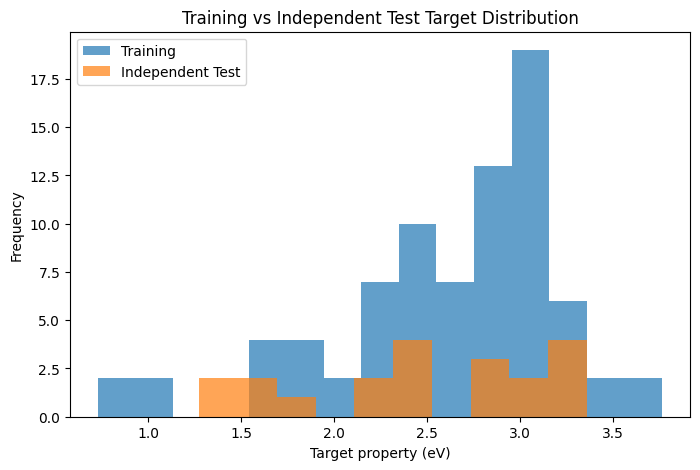

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    y_expanded_train,
    bins=15,
    alpha=0.7,
    label="Training"
)

plt.hist(
    y_expanded_test,
    bins=10,
    alpha=0.7,
    label="Independent Test"
)

plt.xlabel("Target property (eV)")
plt.ylabel("Frequency")
plt.title("Training vs Independent Test Target Distribution")
plt.legend()

plt.show()

In [ ]:
# ============================================================
# STEP 64 — DESCRIPTOR-TARGET CORRELATION
# ============================================================

correlations = (
    X_expanded_train
    .corrwith(y_expanded_train)
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
)

print("=" * 70)
print("DESCRIPTOR-TARGET CORRELATION")
print("=" * 70)

display(
    correlations.to_frame(
        name="Pearson_r"
    )
)

DESCRIPTOR-TARGET CORRELATION


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Pearson_r
TPSA,-0.370434
Heteroatom_Count,-0.352368
Azo_Count,-0.332396
Sulfur_Count,-0.322518
RingCount,-0.314676
FractionCSP3,0.297125
Nitrogen_Count,-0.261917
AromaticRingCount,-0.164868
XLogP,-0.160710
HBondAcceptorCount,-0.151045


In [ ]:
spearman_corr = (
    X_expanded_train
    .corrwith(
        y_expanded_train,
        method="spearman"
    )
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
)

print("SPEARMAN CORRELATION")

display(
    spearman_corr.to_frame(
        name="Spearman_r"
    )
)

SPEARMAN CORRELATION


/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,Spearman_r
RingCount,-0.387279
Heteroatom_Count,-0.358302
Sulfur_Count,-0.334987
TPSA,-0.331503
Azo_Count,-0.274184
Nitrogen_Count,-0.272451
FractionCSP3,0.254433
HeavyAtomCount,-0.223389
AromaticRingCount,-0.183712
XLogP,-0.164842


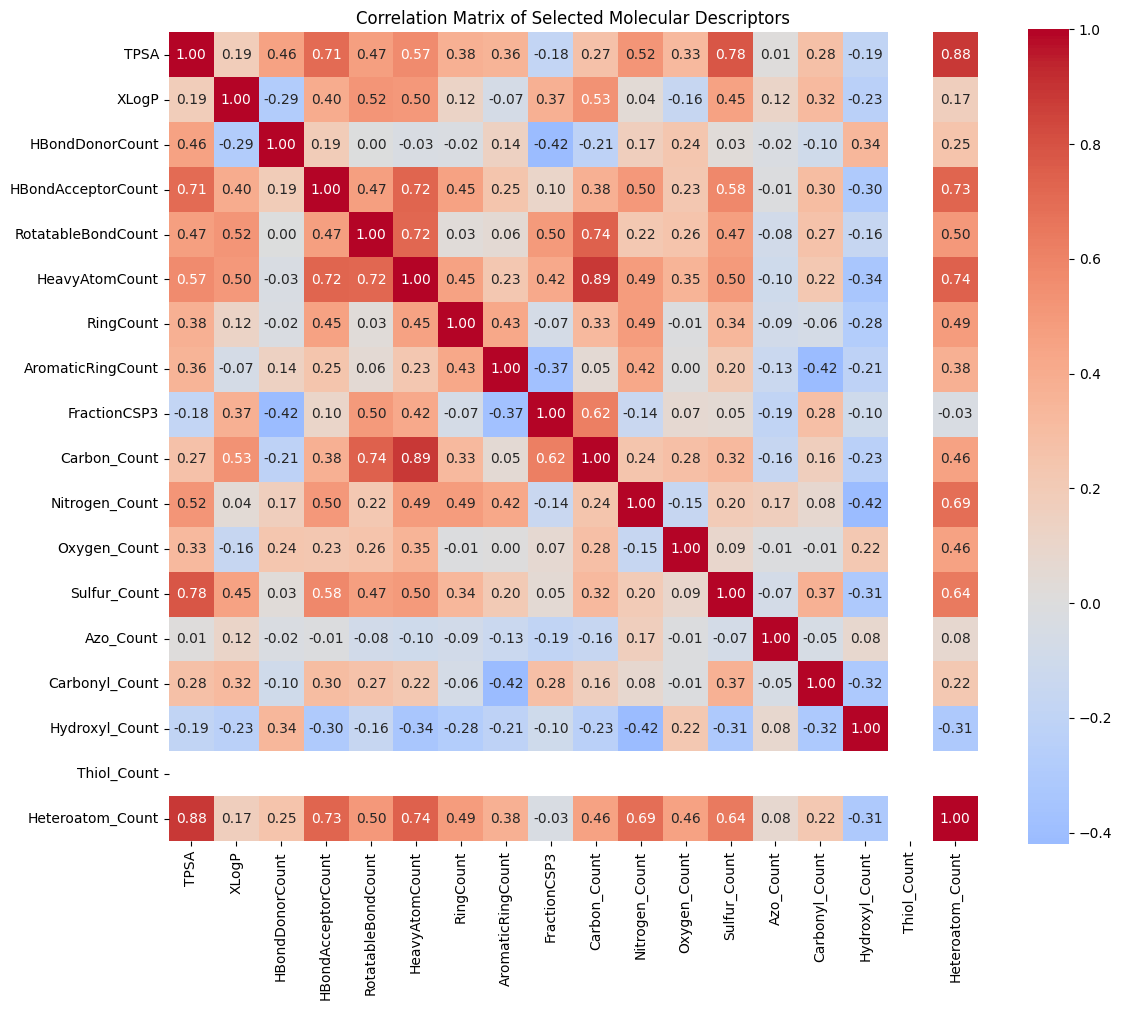

In [ ]:
# ============================================================
# STEP 65 — DESCRIPTOR CORRELATION MATRIX
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

corr = X_expanded_train.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix of Selected Molecular Descriptors")
plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# STEP 66 — HIGH-CORRELATION FILTER
# ============================================================

corr_matrix = X_expanded_train.corr().abs()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for column in upper.columns:

    for row in upper.index:

        value = upper.loc[row, column]

        if pd.notna(value) and value >= 0.95:

            high_corr_pairs.append(
                (row, column, value)
            )

high_corr_pairs = sorted(
    high_corr_pairs,
    key=lambda x: x[2],
    reverse=True
)

print("=" * 70)
print("HIGHLY CORRELATED DESCRIPTOR PAIRS (|r| >= 0.95)")
print("=" * 70)

for a, b, r in high_corr_pairs:
    print(
        f"{a}  <-->  {b} : r = {r:.3f}"
    )

HIGHLY CORRELATED DESCRIPTOR PAIRS (|r| >= 0.95)


In [ ]:
# ============================================================
# STEP 67 — ROBUST MODEL COMPARISON
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.svm import SVR

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.model_selection import (
    RepeatedKFold,
    cross_validate
)

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge":
        Ridge(alpha=1.0),

    "LASSO":
        Lasso(alpha=0.01),

    "Elastic Net":
        ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            random_state=42
        ),

    "SVR":
        SVR(
            kernel="rbf"
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=500,
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            random_state=42
        )
}

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

model_results = []

for name, model in models.items():

    pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            model
        )
    ])

    scores = cross_validate(
        pipeline,
        X_expanded_train,
        y_expanded_train,
        cv=cv,

        scoring={
            "R2": "r2",
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error"
        },

        n_jobs=-1
    )

    model_results.append({

        "Model": name,

        "CV_R2_mean":
            scores["test_R2"].mean(),

        "CV_R2_SD":
            scores["test_R2"].std(),

        "CV_RMSE":
            -scores["test_RMSE"].mean(),

        "CV_MAE":
            -scores["test_MAE"].mean()
    })

model_results_df = pd.DataFrame(
    model_results
).sort_values(
    "CV_R2_mean",
    ascending=False
)

display(model_results_df)

,Model,CV_R2_mean,CV_R2_SD,CV_RMSE,CV_MAE
4,SVR,0.037432,0.295855,0.575807,0.452563
5,Random Forest,0.017929,0.393807,0.572392,0.454806
6,Extra Trees,0.008602,0.467332,0.568877,0.450500
2,LASSO,-0.116627,0.745005,0.597429,0.449114
3,Elastic Net,-0.117419,0.724993,0.598491,0.450094
7,Gradient Boosting,-0.122422,0.489205,0.603236,0.469522
1,Ridge,-0.123554,0.714300,0.600752,0.452217
0,Linear Regression,-0.193019,0.726400,0.619630,0.467624


In [ ]:
# ============================================================
# STEP 68 — CORRELATION-BASED FEATURE SELECTION
# ============================================================

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import RepeatedKFold, cross_validate

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

feature_results = []

for k in [5, 8, 10, 12, 15, 18]:

    pipeline = Pipeline([

        ("imputer",
         SimpleImputer(strategy="median")),

        ("scaler",
         StandardScaler()),

        ("selector",
         SelectKBest(
             score_func=f_regression,
             k=min(k, X_expanded_train.shape[1])
         )),

        ("model",
         SVR(kernel="rbf"))
    ])

    scores = cross_validate(
        pipeline,
        X_expanded_train,
        y_expanded_train,
        cv=cv,

        scoring={
            "R2": "r2",
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error"
        },

        n_jobs=-1
    )

    feature_results.append({

        "Number_of_features": k,

        "CV_R2_mean":
            scores["test_R2"].mean(),

        "CV_R2_SD":
            scores["test_R2"].std(),

        "CV_RMSE":
            -scores["test_RMSE"].mean(),

        "CV_MAE":
            -scores["test_MAE"].mean()
    })

feature_results_df = pd.DataFrame(
    feature_results
)

display(feature_results_df)

,Number_of_features,CV_R2_mean,CV_R2_SD,CV_RMSE,CV_MAE
0,5,-0.116354,0.352771,0.614413,0.476794
1,8,0.046628,0.310847,0.569253,0.450939
2,10,0.053274,0.293033,0.568536,0.453029
3,12,0.046060,0.271484,0.573083,0.452063
4,15,0.016634,0.324972,0.580449,0.459251
5,18,0.037432,0.295855,0.575807,0.452563


In [ ]:
# ============================================================
# STEP 69 — IDENTIFY SELECTED DESCRIPTORS (NaN-SAFE)
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression

best_k = 8   # CHANGE this to the best k obtained from STEP 68

# ------------------------------------------------------------
# 1. Impute TRAINING DATA ONLY
# ------------------------------------------------------------

imputer_fs = SimpleImputer(strategy="median")

X_train_imputed = imputer_fs.fit_transform(
    X_expanded_train
)

# ------------------------------------------------------------
# 2. Feature selection
# ------------------------------------------------------------

selector = SelectKBest(
    score_func=f_regression,
    k=best_k
)

selector.fit(
    X_train_imputed,
    y_expanded_train
)

# ------------------------------------------------------------
# 3. Get selected descriptor names
# ------------------------------------------------------------

selected_features = X_expanded_train.columns[
    selector.get_support()
]

print("=" * 70)
print("SELECTED DESCRIPTORS")
print("=" * 70)

print("Number of selected descriptors:", len(selected_features))

for i, feature in enumerate(selected_features, 1):
    print(f"{i:2d}. {feature}")

SELECTED DESCRIPTORS
Number of selected descriptors: 8
 1. TPSA
 2. RingCount
 3. AromaticRingCount
 4. FractionCSP3
 5. Nitrogen_Count
 6. Sulfur_Count
 7. Azo_Count
 8. Heteroatom_Count


In [ ]:
best_k = 8

In [ ]:
best_k = 8

In [ ]:
# ============================================================
# STEP 69B — CREATE SELECTED DESCRIPTOR MATRICES
# ============================================================

X_selected_train = X_expanded_train[
    selected_features
].copy()

X_selected_test = X_expanded_test[
    selected_features
].copy()

print("=" * 70)
print("SELECTED DESCRIPTOR DATASET")
print("=" * 70)

print(
    "Selected descriptors:",
    len(selected_features)
)

print(
    "Training matrix:",
    X_selected_train.shape
)

print(
    "Test matrix:",
    X_selected_test.shape
)

print("\nSelected descriptors:")
print(list(selected_features))

SELECTED DESCRIPTOR DATASET
Selected descriptors: 8
Training matrix: (80, 8)
Test matrix: (20, 8)

Selected descriptors:
['TPSA', 'RingCount', 'AromaticRingCount', 'FractionCSP3', 'Nitrogen_Count', 'Sulfur_Count', 'Azo_Count', 'Heteroatom_Count']


In [ ]:
# ============================================================
# STEP 69C — LEAKAGE-SAFE FEATURE SELECTION + SVR
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.svm import SVR
from sklearn.model_selection import RepeatedKFold, cross_validate

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

feature_selection_results = []

for k in [5, 8, 10, 12, 15, 18]:

    pipeline = Pipeline([

        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "selector",
            SelectKBest(
                score_func=f_regression,
                k=k
            )
        ),

        (
            "model",
            SVR(kernel="rbf")
        )
    ])

    scores = cross_validate(
        pipeline,
        X_expanded_train,
        y_expanded_train,
        cv=cv,

        scoring={
            "R2": "r2",
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error"
        },

        n_jobs=-1
    )

    feature_selection_results.append({

        "Features": k,

        "CV_R2_mean":
            scores["test_R2"].mean(),

        "CV_R2_SD":
            scores["test_R2"].std(),

        "CV_RMSE":
            -scores["test_RMSE"].mean(),

        "CV_MAE":
            -scores["test_MAE"].mean()
    })

feature_selection_df = pd.DataFrame(
    feature_selection_results
).sort_values(
    "CV_R2_mean",
    ascending=False
)

display(feature_selection_df)

,Features,CV_R2_mean,CV_R2_SD,CV_RMSE,CV_MAE
2,10,0.053274,0.293033,0.568536,0.453029
1,8,0.046628,0.310847,0.569253,0.450939
3,12,0.046060,0.271484,0.573083,0.452063
5,18,0.037432,0.295855,0.575807,0.452563
4,15,0.016634,0.324972,0.580449,0.459251
0,5,-0.116354,0.352771,0.614413,0.476794


In [ ]:
# ============================================================
# STEP 70 — SVR HYPERPARAMETER OPTIMIZATION
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.svm import SVR
from sklearn.model_selection import (
    RepeatedKFold,
    RandomizedSearchCV
)

# ------------------------------------------------------------
# Cross-validation
# ------------------------------------------------------------

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

# ------------------------------------------------------------
# Complete leakage-safe pipeline
# ------------------------------------------------------------

svr_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "selector",
        SelectKBest(
            score_func=f_regression
        )
    ),

    (
        "model",
        SVR(kernel="rbf")
    )
])

# ------------------------------------------------------------
# Hyperparameter space
# ------------------------------------------------------------

param_grid = {

    "selector__k": [
        8,
        10,
        12,
        15,
        18
    ],

    "model__C": [
        0.1,
        0.3,
        1,
        3,
        10,
        30,
        100
    ],

    "model__gamma": [
        "scale",
        "auto",
        0.001,
        0.003,
        0.01,
        0.03,
        0.1,
        0.3
    ],

    "model__epsilon": [
        0.01,
        0.03,
        0.05,
        0.1,
        0.2,
        0.3
    ]
}

# ------------------------------------------------------------
# Randomized search
# ------------------------------------------------------------

svr_search = RandomizedSearchCV(

    estimator=svr_pipeline,

    param_distributions=param_grid,

    n_iter=50,

    scoring="neg_root_mean_squared_error",

    cv=cv,

    random_state=42,

    n_jobs=-1,

    return_train_score=True
)

svr_search.fit(
    X_expanded_train,
    y_expanded_train
)

print("=" * 70)
print("BEST SVR MODEL")
print("=" * 70)

print("\nBest parameters:")
print(svr_search.best_params_)

print(
    "\nBest CV RMSE:",
    -svr_search.best_score_
)

BEST SVR MODEL

Best parameters:
{'selector__k': 12, 'model__gamma': 0.01, 'model__epsilon': 0.1, 'model__C': 10}

Best CV RMSE: 0.5547613458955907


In [ ]:
# ============================================================
# STEP 71 — OPTIMIZED SVR CV PERFORMANCE
# ============================================================

best_index = svr_search.best_index_

cv_results = svr_search.cv_results_

best_rmse = -cv_results[
    "mean_test_score"
][best_index]

best_rmse_sd = cv_results[
    "std_test_score"
][best_index]

best_r2 = cv_results[
    "mean_test_score"
][best_index]

print("=" * 70)
print("OPTIMIZED SVR")
print("=" * 70)

print(
    "Best CV RMSE:",
    best_rmse
)

print(
    "Best CV RMSE SD:",
    best_rmse_sd
)

print(
    "\nBest parameters:"
)

print(
    svr_search.best_params_
)

OPTIMIZED SVR
Best CV RMSE: 0.5547613458955907
Best CV RMSE SD: 0.13709181165836604

Best parameters:
{'selector__k': 12, 'model__gamma': 0.01, 'model__epsilon': 0.1, 'model__C': 10}


In [ ]:
# ============================================================
# STEP 71B — FINAL REPEATED CV OF OPTIMIZED SVR
# ============================================================

from sklearn.model_selection import cross_validate

best_svr = svr_search.best_estimator_

final_cv_scores = cross_validate(

    best_svr,

    X_expanded_train,

    y_expanded_train,

    cv=cv,

    scoring={
        "R2": "r2",
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error"
    },

    n_jobs=-1
)

print("=" * 70)
print("FINAL OPTIMIZED SVR — REPEATED CV")
print("=" * 70)

print(
    f"R²   = "
    f"{final_cv_scores['test_R2'].mean():.4f} "
    f"± "
    f"{final_cv_scores['test_R2'].std():.4f}"
)

print(
    f"RMSE = "
    f"{-final_cv_scores['test_RMSE'].mean():.4f} eV"
)

print(
    f"MAE  = "
    f"{-final_cv_scores['test_MAE'].mean():.4f} eV"
)

FINAL OPTIMIZED SVR — REPEATED CV
R²   = 0.0709 ± 0.4227
RMSE = 0.5548 eV
MAE  = 0.4298 eV


In [ ]:
# ============================================================
# STEP 72 — INDEPENDENT TEST SET
# ============================================================

best_svr.fit(
    X_expanded_train,
    y_expanded_train
)

y_test_pred = best_svr.predict(
    X_expanded_test
)

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

test_r2 = r2_score(
    y_expanded_test,
    y_test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_expanded_test,
        y_test_pred
    )
)

test_mae = mean_absolute_error(
    y_expanded_test,
    y_test_pred
)

print("=" * 70)
print("INDEPENDENT TEST SET — OPTIMIZED SVR")
print("=" * 70)

print(
    f"Test R²   : {test_r2:.4f}"
)

print(
    f"Test RMSE : {test_rmse:.4f} eV"
)

print(
    f"Test MAE  : {test_mae:.4f} eV"
)

INDEPENDENT TEST SET — OPTIMIZED SVR
Test R²   : 0.6400
Test RMSE : 0.3930 eV
Test MAE  : 0.3087 eV


In [ ]:
# ============================================================
# STEP 73 — FINAL OPTIMIZED SVR CV PERFORMANCE
# ============================================================

print("=" * 70)
print("FINAL OPTIMIZED SVR — REPEATED CROSS-VALIDATION")
print("=" * 70)

cv_r2 = final_cv_scores["test_R2"]
cv_rmse = -final_cv_scores["test_RMSE"]
cv_mae = -final_cv_scores["test_MAE"]

print(
    f"CV R²   : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}"
)

print(
    f"CV RMSE : {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f} eV"
)

print(
    f"CV MAE  : {cv_mae.mean():.4f} ± {cv_mae.std():.4f} eV"
)

FINAL OPTIMIZED SVR — REPEATED CROSS-VALIDATION
CV R²   : 0.0709 ± 0.4227
CV RMSE : 0.5548 ± 0.1371 eV
CV MAE  : 0.4298 ± 0.1031 eV


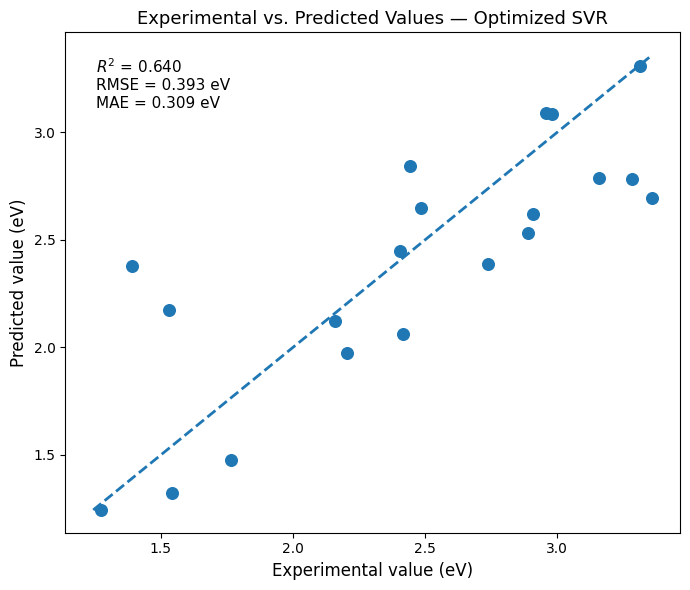

In [ ]:
# ============================================================
# STEP 74 — EXPERIMENTAL VS PREDICTED
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 6))

plt.scatter(
    y_expanded_test,
    y_test_pred,
    s=70
)

minimum = min(
    y_expanded_test.min(),
    y_test_pred.min()
)

maximum = max(
    y_expanded_test.max(),
    y_test_pred.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=2
)

plt.xlabel(
    "Experimental value (eV)",
    fontsize=12
)

plt.ylabel(
    "Predicted value (eV)",
    fontsize=12
)

plt.title(
    "Experimental vs. Predicted Values — Optimized SVR",
    fontsize=13
)

plt.text(
    0.05,
    0.95,
    f"$R^2$ = {test_r2:.3f}\n"
    f"RMSE = {test_rmse:.3f} eV\n"
    f"MAE = {test_mae:.3f} eV",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    fontsize=11
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 75 — SAVE TEST PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({

    "Experimental": y_expanded_test.values,

    "Predicted": y_test_pred,

    "Residual": (
        y_expanded_test.values -
        y_test_pred
    ),

    "Absolute_Error": np.abs(
        y_expanded_test.values -
        y_test_pred
    )
})

display(prediction_df)

prediction_df.to_csv(
    "Optimized_SVR_Independent_Test_Predictions.csv",
    index=False
)

,Experimental,Predicted,Residual,Absolute_Error
0,2.404902,2.448131,-0.043230,0.043230
1,2.980455,3.084683,-0.104228,0.104228
2,3.311998,3.310178,0.001820,0.001820
3,1.543664,1.323601,0.220062,0.220062
4,2.907467,2.622239,0.285228,0.285228
5,3.160094,2.789855,0.370239,0.370239
6,2.418419,2.063855,0.354564,0.354564
7,2.738958,2.385648,0.353310,0.353310
8,1.273631,1.243989,0.029642,0.029642
9,2.890494,2.530010,0.360484,0.360484


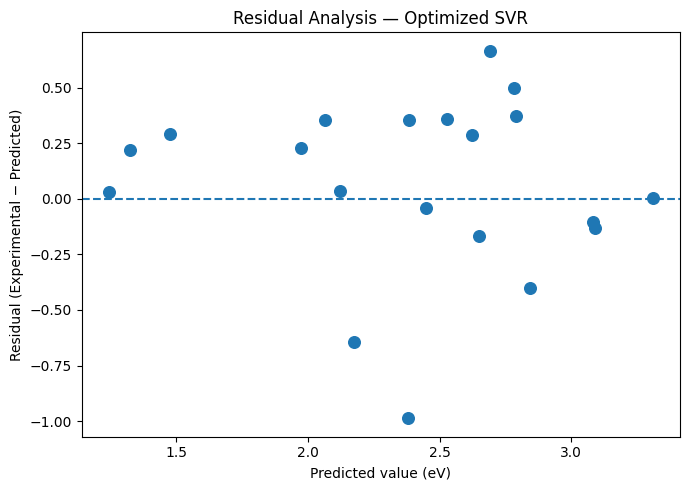

In [ ]:
# ============================================================
# STEP 76 — RESIDUAL ANALYSIS
# ============================================================

residuals = (
    y_expanded_test.values -
    y_test_pred
)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_pred,
    residuals,
    s=70
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Predicted value (eV)"
)

plt.ylabel(
    "Residual (Experimental − Predicted)"
)

plt.title(
    "Residual Analysis — Optimized SVR"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 77 — TEST-SET ERROR ANALYSIS
# ============================================================

prediction_df["Molecule_Index"] = (
    y_expanded_test.index
)

prediction_df = prediction_df.sort_values(
    "Absolute_Error",
    ascending=False
)

display(prediction_df)

,Experimental,Predicted,Residual,Absolute_Error,Molecule_Index
10,1.392498,2.379837,-0.987338,0.987338,18
19,3.359370,2.693383,0.665986,0.665986,31
15,1.530270,2.175054,-0.644783,0.644783,4
16,3.284158,2.783963,0.500195,0.500195,76
11,2.442679,2.844614,-0.401934,0.401934,30
5,3.160094,2.789855,0.370239,0.370239,39
9,2.890494,2.530010,0.360484,0.360484,0
6,2.418419,2.063855,0.354564,0.354564,22
7,2.738958,2.385648,0.353310,0.353310,80
18,1.766412,1.477126,0.289286,0.289286,12


In [ ]:
# ============================================================
# STEP 78 — APPLICABILITY DOMAIN
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

# Imputation
ad_imputer = SimpleImputer(
    strategy="median"
)

X_train_imp = ad_imputer.fit_transform(
    X_expanded_train
)

X_test_imp = ad_imputer.transform(
    X_expanded_test
)

# Scaling
ad_scaler = StandardScaler()

X_train_scaled = ad_scaler.fit_transform(
    X_train_imp
)

X_test_scaled = ad_scaler.transform(
    X_test_imp
)

# Distance from each test molecule
# to every training molecule

distances = pairwise_distances(
    X_test_scaled,
    X_train_scaled,
    metric="euclidean"
)

nearest_distance = distances.min(
    axis=1
)

ad_df = pd.DataFrame({

    "Molecule_Index":
        y_expanded_test.index,

    "Nearest_Training_Distance":
        nearest_distance,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Absolute_Error":
        np.abs(
            y_expanded_test.values -
            y_test_pred
        )
})

ad_df = ad_df.sort_values(
    "Nearest_Training_Distance",
    ascending=False
)

display(ad_df)

,Molecule_Index,Nearest_Training_Distance,Experimental,Predicted,Absolute_Error
16,76,5.603679,3.284158,2.783963,0.500195
2,70,4.603840,3.311998,3.310178,0.001820
8,10,4.297983,1.273631,1.243989,0.029642
13,33,4.279069,2.203078,1.975424,0.227653
3,45,4.202403,1.543664,1.323601,0.220062
18,12,3.876309,1.766412,1.477126,0.289286
15,4,3.222584,1.530270,2.175054,0.644783
6,22,3.114455,2.418419,2.063855,0.354564
14,90,3.050945,2.158715,2.122686,0.036029
11,30,2.964604,2.442679,2.844614,0.401934


In [ ]:
# ============================================================
# STEP 79 — Y-RANDOMIZATION
# ============================================================

from sklearn.base import clone
from sklearn.model_selection import cross_val_score

n_randomizations = 100

randomized_r2 = []

for seed in range(n_randomizations):

    y_random = (
        y_expanded_train
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )

    X_random = (
        X_expanded_train
        .reset_index(drop=True)
    )

    random_model = clone(
        best_svr
    )

    scores = cross_val_score(
        random_model,
        X_random,
        y_random,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    randomized_r2.append(
        scores.mean()
    )

randomized_r2 = np.array(
    randomized_r2
)

print("=" * 70)
print("Y-RANDOMIZATION RESULTS")
print("=" * 70)

print(
    "Actual CV R²:",
    cv_r2.mean()
)

print(
    "Randomized mean R²:",
    randomized_r2.mean()
)

print(
    "Randomized maximum R²:",
    randomized_r2.max()
)

Y-RANDOMIZATION RESULTS
Actual CV R²: 0.07088890148932363
Randomized mean R²: -0.4305277585321822
Randomized maximum R²: -0.06925327728537783


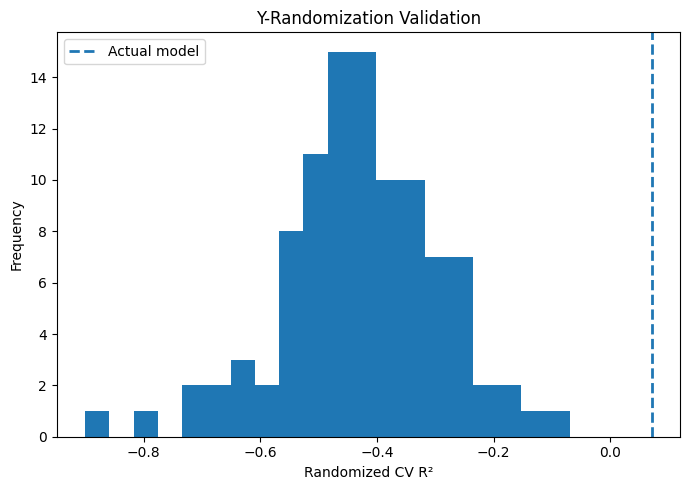

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(
    randomized_r2,
    bins=20
)

plt.axvline(
    cv_r2.mean(),
    linestyle="--",
    linewidth=2,
    label="Actual model"
)

plt.xlabel(
    "Randomized CV R²"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Y-Randomization Validation"
)

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 80.1 — SHAP SETUP
# ============================================================

!pip install -q shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [ ]:
# ============================================================
# STEP 80.2 — INSPECT OPTIMIZED SVR PIPELINE
# ============================================================

print(best_svr)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(k=12,
                             score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR(C=10, gamma=0.01))])


In [ ]:
imputer = best_svr.named_steps["imputer"]
scaler = best_svr.named_steps["scaler"]
selector = best_svr.named_steps["selector"]
svr_model = best_svr.named_steps["model"]

print("SVR:", svr_model)
print("Selected features:", selector.get_support().sum())

SVR: SVR(C=10, gamma=0.01)
Selected features: 12


In [ ]:
# ============================================================
# STEP 81 — FINAL FEATURES USED BY OPTIMIZED SVR
# ============================================================

all_features = X_expanded_train.columns

selected_mask = selector.get_support()

final_features = all_features[selected_mask]

print("=" * 70)
print("FINAL SVR FEATURES")
print("=" * 70)

print("Number of features:", len(final_features))

for i, feature in enumerate(final_features, 1):
    print(f"{i:2d}. {feature}")

FINAL SVR FEATURES
Number of features: 12
 1. TPSA
 2. XLogP
 3. HBondAcceptorCount
 4. RotatableBondCount
 5. HeavyAtomCount
 6. RingCount
 7. AromaticRingCount
 8. FractionCSP3
 9. Nitrogen_Count
10. Sulfur_Count
11. Azo_Count
12. Heteroatom_Count


In [ ]:
feature_scores = pd.DataFrame({
    "Descriptor": all_features,
    "F_score": selector.scores_,
    "p_value": selector.pvalues_,
    "Selected": selector.get_support()
})

feature_scores = feature_scores.sort_values(
    "F_score",
    ascending=False
)

display(feature_scores)

,Descriptor,F_score,p_value,Selected
0,TPSA,12.405553,0.000719,True
17,Heteroatom_Count,11.057660,0.001348,True
13,Azo_Count,9.688419,0.002592,True
12,Sulfur_Count,9.055305,0.003526,True
6,RingCount,8.572517,0.004471,True
8,FractionCSP3,7.552914,0.007440,True
10,Nitrogen_Count,5.744958,0.018929,True
7,AromaticRingCount,2.179395,0.143895,True
1,XLogP,1.918151,0.170009,True
3,HBondAcceptorCount,1.821089,0.181088,True


In [ ]:
# ============================================================
# STEP 82 — TRANSFORM TRAINING DATA
# ============================================================

X_train_imputed = imputer.transform(
    X_expanded_train
)

X_train_scaled = scaler.transform(
    X_train_imputed
)

X_train_selected = selector.transform(
    X_train_scaled
)

print(
    "Original training shape:",
    X_expanded_train.shape
)

print(
    "Final SVR input shape:",
    X_train_selected.shape
)

Original training shape: (80, 18)
Final SVR input shape: (80, 12)


In [ ]:
# ============================================================
# STEP 83 — TRANSFORM TEST DATA
# ============================================================

X_test_imputed = imputer.transform(
    X_expanded_test
)

X_test_scaled = scaler.transform(
    X_test_imputed
)

X_test_selected = selector.transform(
    X_test_scaled
)

print(
    "Test SVR input shape:",
    X_test_selected.shape
)

Test SVR input shape: (20, 12)


In [ ]:
# ============================================================
# STEP 84 — SHAP PREDICTION FUNCTION
# ============================================================

def svr_predict(X):
    return svr_model.predict(X)

In [ ]:
# ============================================================
# STEP 85 — SHAP BACKGROUND DATA
# ============================================================

background_size = min(
    30,
    X_train_selected.shape[0]
)

rng = np.random.default_rng(42)

background_indices = rng.choice(
    X_train_selected.shape[0],
    size=background_size,
    replace=False
)

X_background = X_train_selected[
    background_indices
]

print(
    "SHAP background size:",
    X_background.shape
)

SHAP background size: (30, 12)


In [ ]:
# ============================================================
# STEP 86 — SHAP VALUES FOR INDEPENDENT TEST SET
# ============================================================

explainer = shap.KernelExplainer(
    svr_predict,
    X_background
)

shap_values = explainer.shap_values(
    X_test_selected,
    nsamples=200
)

shap_values = np.asarray(
    shap_values
)

print(
    "SHAP values shape:",
    shap_values.shape
)

  0%|          | 0/20 [00:00<?, ?it/s]

SHAP values shape: (20, 12)


In [ ]:
# ============================================================
# STEP 87 — SHAP EXPLANATION OBJECT
# ============================================================

X_test_selected_df = pd.DataFrame(
    X_test_selected,
    columns=final_features,
    index=X_expanded_test.index
)

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=np.repeat(
        np.mean(
            svr_predict(X_background)
        ),
        len(X_test_selected)
    ),
    data=X_test_selected_df.values,
    feature_names=final_features.tolist()
)

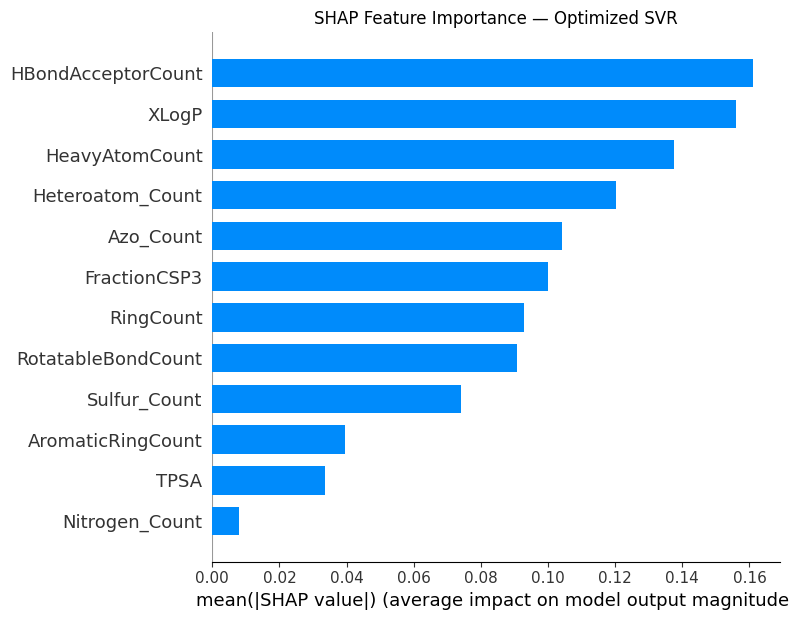

In [ ]:
# ============================================================
# STEP 88 — SHAP GLOBAL FEATURE IMPORTANCE
# ============================================================

shap.summary_plot(
    shap_values,
    X_test_selected_df,
    plot_type="bar",
    show=False
)

plt.title(
    "SHAP Feature Importance — Optimized SVR"
)

plt.tight_layout()

plt.savefig(
    "SHAP_Global_Feature_Importance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

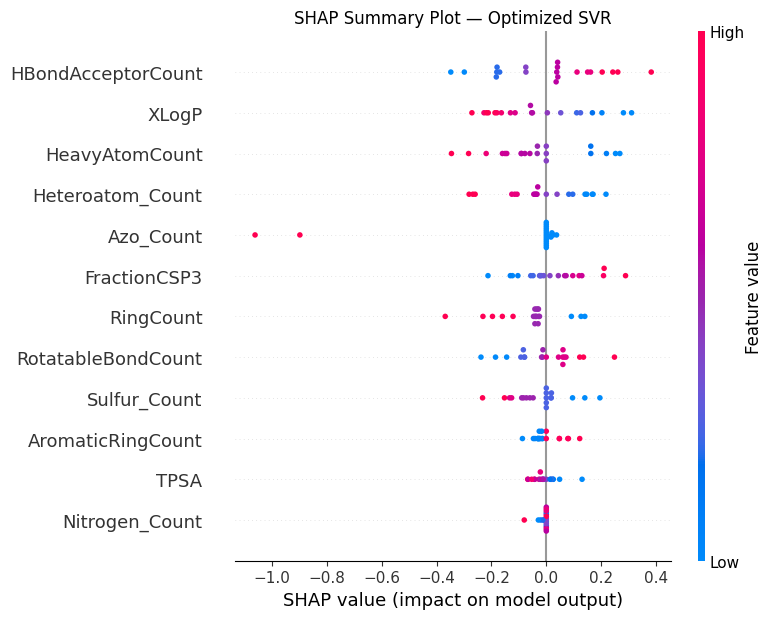

In [ ]:
# ============================================================
# STEP 89 — SHAP BEESWARM PLOT
# ============================================================

shap.summary_plot(
    shap_values,
    X_test_selected_df,
    show=False
)

plt.title(
    "SHAP Summary Plot — Optimized SVR"
)

plt.tight_layout()

plt.savefig(
    "SHAP_Beeswarm_Optimized_SVR.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# STEP 90 — SHAP IMPORTANCE TABLE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_importance_df = pd.DataFrame({

    "Descriptor": final_features,

    "Mean_Absolute_SHAP":
        mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df["Rank"] = (
    np.arange(
        1,
        len(shap_importance_df) + 1
    )
)

shap_importance_df = (
    shap_importance_df[
        [
            "Rank",
            "Descriptor",
            "Mean_Absolute_SHAP"
        ]
    ]
)

display(shap_importance_df)

,Rank,Descriptor,Mean_Absolute_SHAP
0,1,HBondAcceptorCount,0.161039
1,2,XLogP,0.156029
2,3,HeavyAtomCount,0.137621
3,4,Heteroatom_Count,0.120349
4,5,Azo_Count,0.104005
5,6,FractionCSP3,0.100033
6,7,RingCount,0.092978
7,8,RotatableBondCount,0.090861
8,9,Sulfur_Count,0.074192
9,10,AromaticRingCount,0.039410


In [ ]:
shap_importance_df.to_csv(
    "SHAP_Feature_Importance.csv",
    index=False
)

In [ ]:
# ============================================================
# STEP 91 — TOP 3 SHAP DEPENDENCE PLOTS
# ============================================================

top_features = (
    shap_importance_df
    .head(3)
    ["Descriptor"]
    .tolist()
)

print("Top SHAP descriptors:")
for feature in top_features:
    print(feature)

Top SHAP descriptors:
HBondAcceptorCount
XLogP
HeavyAtomCount


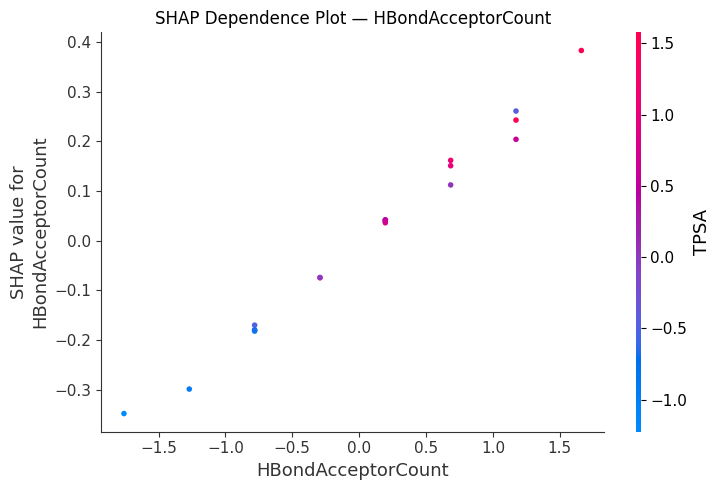

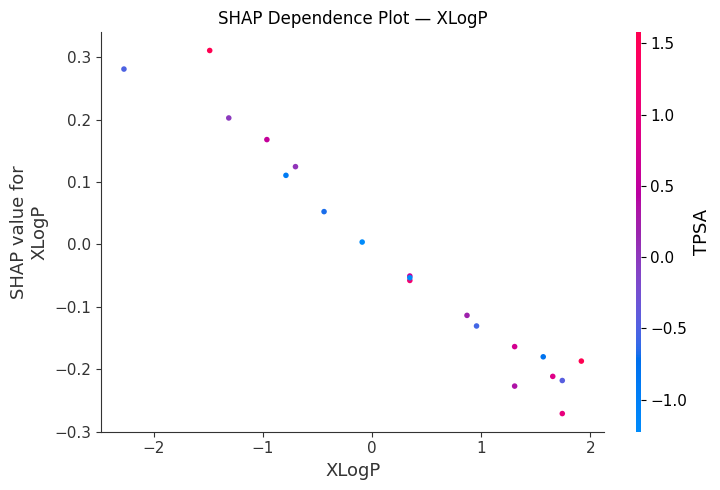

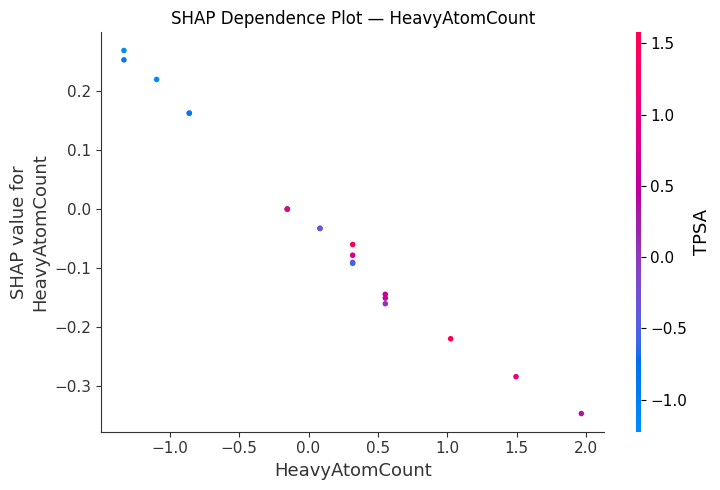

In [ ]:
for feature in top_features:

    shap.dependence_plot(
        feature,
        shap_values,
        X_test_selected_df,
        show=False
    )

    plt.title(
        f"SHAP Dependence Plot — {feature}"
    )

    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        f"SHAP_Dependence_{safe_name}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

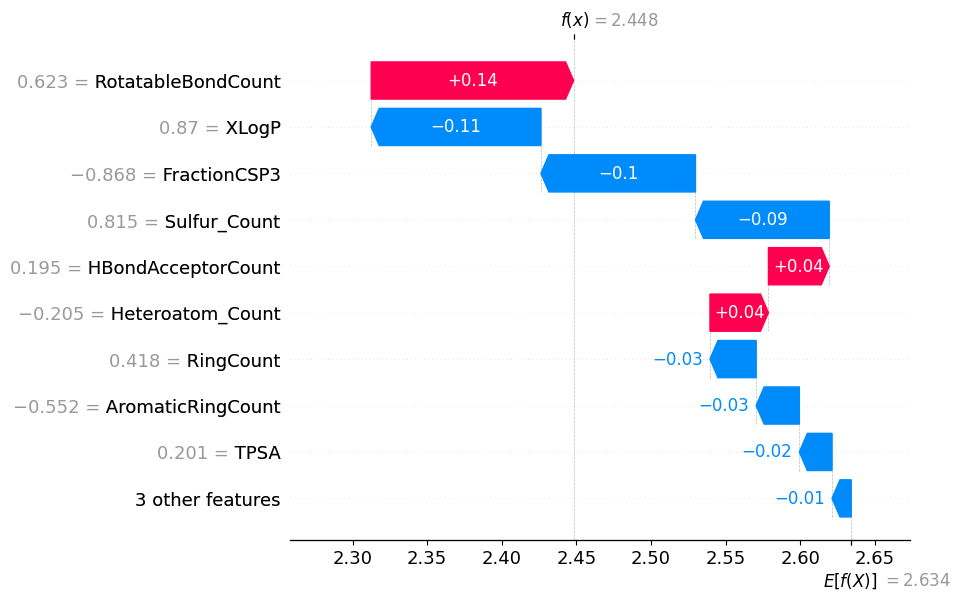

In [ ]:
# ============================================================
# STEP 92 — INDIVIDUAL MOLECULE SHAP
# ============================================================

molecule_number = 0

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[molecule_number],
        base_values=np.mean(
            svr_predict(X_background)
        ),
        data=X_test_selected_df.iloc[
            molecule_number
        ].values,
        feature_names=final_features.tolist()
    ),
    max_display=10
)

In [ ]:
# ============================================================
# STEP 93 — SHAP VALUES FOR TRAINING SET
# ============================================================

shap_values_train = explainer.shap_values(
    X_train_selected,
    nsamples=200
)

shap_values_train = np.asarray(
    shap_values_train
)

train_shap_importance = pd.DataFrame({

    "Descriptor":
        final_features,

    "Mean_Absolute_SHAP":
        np.mean(
            np.abs(shap_values_train),
            axis=0
        )
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(train_shap_importance)

  0%|          | 0/80 [00:00<?, ?it/s]

,Descriptor,Mean_Absolute_SHAP
2,HBondAcceptorCount,0.162723
4,HeavyAtomCount,0.156344
3,RotatableBondCount,0.135001
7,FractionCSP3,0.134007
11,Heteroatom_Count,0.113525
1,XLogP,0.107451
5,RingCount,0.079345
9,Sulfur_Count,0.065577
10,Azo_Count,0.064956
6,AromaticRingCount,0.047263


In [ ]:
# ============================================================
# STEP 93B — TRAIN VS TEST SHAP RANKING
# ============================================================

train_rank = (
    train_shap_importance
    [["Descriptor", "Mean_Absolute_SHAP"]]
    .rename(
        columns={
            "Mean_Absolute_SHAP":
                "Train_SHAP"
        }
    )
)

test_rank = (
    shap_importance_df
    [["Descriptor", "Mean_Absolute_SHAP"]]
    .rename(
        columns={
            "Mean_Absolute_SHAP":
                "Test_SHAP"
        }
    )
)

shap_comparison = train_rank.merge(
    test_rank,
    on="Descriptor"
)

display(
    shap_comparison.sort_values(
        "Test_SHAP",
        ascending=False
    )
)

,Descriptor,Train_SHAP,Test_SHAP
0,HBondAcceptorCount,0.162723,0.161039
5,XLogP,0.107451,0.156029
1,HeavyAtomCount,0.156344,0.137621
4,Heteroatom_Count,0.113525,0.120349
8,Azo_Count,0.064956,0.104005
3,FractionCSP3,0.134007,0.100033
6,RingCount,0.079345,0.092978
2,RotatableBondCount,0.135001,0.090861
7,Sulfur_Count,0.065577,0.074192
9,AromaticRingCount,0.047263,0.039410


In [ ]:
display(shap_importance_df)

,Rank,Descriptor,Mean_Absolute_SHAP
0,1,HBondAcceptorCount,0.161039
1,2,XLogP,0.156029
2,3,HeavyAtomCount,0.137621
3,4,Heteroatom_Count,0.120349
4,5,Azo_Count,0.104005
5,6,FractionCSP3,0.100033
6,7,RingCount,0.092978
7,8,RotatableBondCount,0.090861
8,9,Sulfur_Count,0.074192
9,10,AromaticRingCount,0.039410


In [ ]:
# ============================================================
# STEP 94 — RELATIVE SHAP CONTRIBUTION
# ============================================================

shap_importance_df["SHAP_Percentage"] = (
    shap_importance_df["Mean_Absolute_SHAP"]
    /
    shap_importance_df["Mean_Absolute_SHAP"].sum()
    * 100
)

display(
    shap_importance_df
)

,Rank,Descriptor,Mean_Absolute_SHAP,SHAP_Percentage
0,1,HBondAcceptorCount,0.161039,14.406872
1,2,XLogP,0.156029,13.958661
2,3,HeavyAtomCount,0.137621,12.311841
3,4,Heteroatom_Count,0.120349,10.766677
4,5,Azo_Count,0.104005,9.304507
5,6,FractionCSP3,0.100033,8.949192
6,7,RingCount,0.092978,8.317988
7,8,RotatableBondCount,0.090861,8.128637
8,9,Sulfur_Count,0.074192,6.637351
9,10,AromaticRingCount,0.039410,3.525693


In [ ]:
# Top 5 cumulative contribution

top5_contribution = (
    shap_importance_df
    .head(5)["SHAP_Percentage"]
    .sum()
)

top10_contribution = (
    shap_importance_df
    .head(10)["SHAP_Percentage"]
    .sum()
)

print(
    f"Top 5 descriptors contribution: "
    f"{top5_contribution:.2f}%"
)

print(
    f"Top 10 descriptors contribution: "
    f"{top10_contribution:.2f}%"
)

Top 5 descriptors contribution: 60.75%
Top 10 descriptors contribution: 96.31%


Top 5 descriptors:
HBondAcceptorCount
XLogP
HeavyAtomCount
Heteroatom_Count
Azo_Count


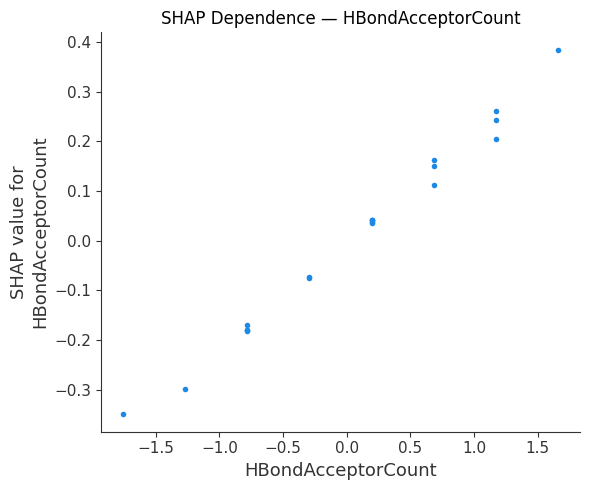

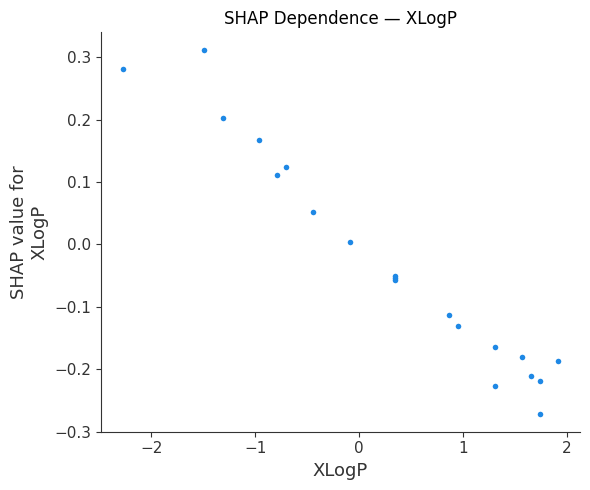

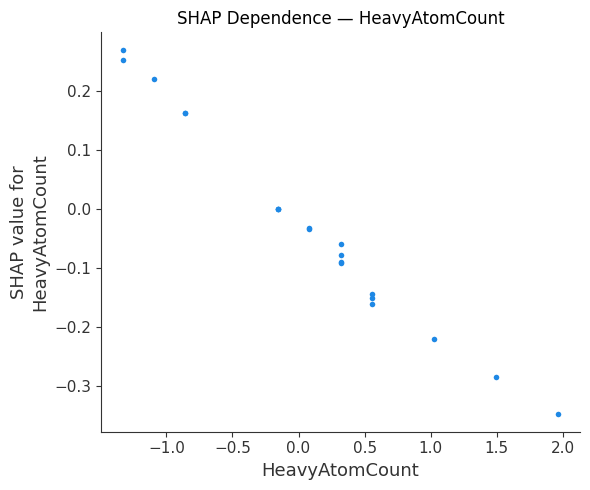

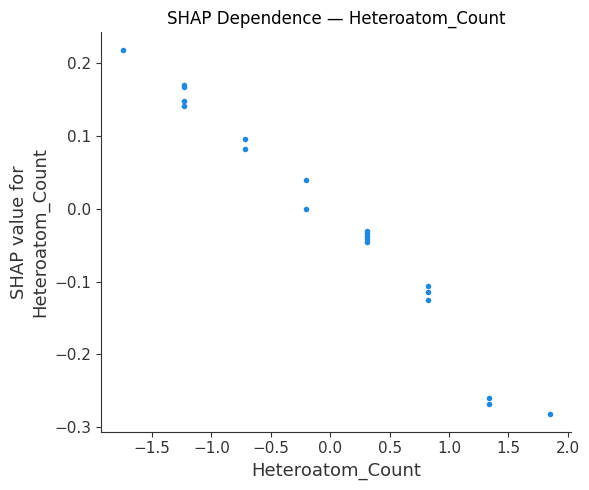

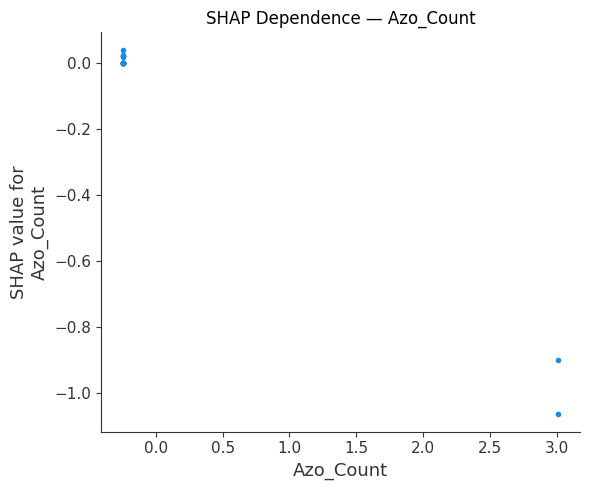

In [ ]:
# ============================================================
# STEP 95 — SHAP DEPENDENCE PLOTS FOR TOP 5
# ============================================================

top5_features = (
    shap_importance_df
    .head(5)
    ["Descriptor"]
    .tolist()
)

print("Top 5 descriptors:")
for feature in top5_features:
    print(feature)

for feature in top5_features:

    shap.dependence_plot(
        feature,
        shap_values,
        X_test_selected_df,
        interaction_index=None,
        show=False
    )

    plt.title(
        f"SHAP Dependence — {feature}"
    )

    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        f"SHAP_Dependence_{safe_name}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# ============================================================
# STEP 96 — DESCRIPTOR–SHAP CORRELATION
# ============================================================

direction_results = []

for feature in final_features:

    feature_values = X_test_selected_df[
        feature
    ].values

    feature_index = list(
        final_features
    ).index(feature)

    feature_shap = shap_values[
        :,
        feature_index
    ]

    pearson = np.corrcoef(
        feature_values,
        feature_shap
    )[0, 1]

    spearman = pd.Series(
        feature_values
    ).corr(
        pd.Series(feature_shap),
        method="spearman"
    )

    direction_results.append({

        "Descriptor": feature,

        "Mean_Abs_SHAP":
            np.mean(
                np.abs(feature_shap)
            ),

        "Pearson_Value_SHAP":
            pearson,

        "Spearman_Value_SHAP":
            spearman
    })

direction_df = pd.DataFrame(
    direction_results
).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

display(direction_df)

,Descriptor,Mean_Abs_SHAP,Pearson_Value_SHAP,Spearman_Value_SHAP
2,HBondAcceptorCount,0.161039,0.995648,0.985229
1,XLogP,0.156029,-0.980087,-0.965338
4,HeavyAtomCount,0.137621,-0.992407,-0.993569
11,Heteroatom_Count,0.120349,-0.985822,-0.985992
10,Azo_Count,0.104005,-0.995562,-0.610468
7,FractionCSP3,0.100033,0.992754,0.991718
5,RingCount,0.092978,-0.981427,-0.880021
3,RotatableBondCount,0.090861,0.986784,0.972556
9,Sulfur_Count,0.074192,-0.948359,-0.965038
6,AromaticRingCount,0.039410,0.919012,0.871331


In [ ]:
print("SVR selected feature count:",
      selector.get_support().sum())

print("SVR selected features:")
print(list(final_features))

SVR selected feature count: 12
SVR selected features:
['TPSA', 'XLogP', 'HBondAcceptorCount', 'RotatableBondCount', 'HeavyAtomCount', 'RingCount', 'AromaticRingCount', 'FractionCSP3', 'Nitrogen_Count', 'Sulfur_Count', 'Azo_Count', 'Heteroatom_Count']


In [ ]:
# ============================================================
# CHECK FINAL OPTIMIZED SVR FEATURES
# ============================================================

print("=" * 70)
print("FINAL OPTIMIZED SVR CONFIGURATION")
print("=" * 70)

print("\nBest parameters:")
print(svr_search.best_params_)

print("\nNumber of selected descriptors:")

final_k = svr_search.best_params_["selector__k"]

print(final_k)

print("\nSelected descriptors:")

final_features = X_expanded_train.columns[
    svr_search.best_estimator_
    .named_steps["selector"]
    .get_support()
]

for i, feature in enumerate(final_features, 1):
    print(f"{i:2d}. {feature}")

FINAL OPTIMIZED SVR CONFIGURATION

Best parameters:
{'selector__k': 12, 'model__gamma': 0.01, 'model__epsilon': 0.1, 'model__C': 10}

Number of selected descriptors:
12

Selected descriptors:
 1. TPSA
 2. XLogP
 3. HBondAcceptorCount
 4. RotatableBondCount
 5. HeavyAtomCount
 6. RingCount
 7. AromaticRingCount
 8. FractionCSP3
 9. Nitrogen_Count
10. Sulfur_Count
11. Azo_Count
12. Heteroatom_Count


In [ ]:
print(svr_search.best_params_)

{'selector__k': 12, 'model__gamma': 0.01, 'model__epsilon': 0.1, 'model__C': 10}


In [ ]:
# ============================================================
# STEP 97 — FINAL 12 DESCRIPTORS
# ============================================================

final_model = svr_search.best_estimator_

final_selector = final_model.named_steps["selector"]

final_features = X_expanded_train.columns[
    final_selector.get_support()
]

print("=" * 70)
print("FINAL OPTIMIZED SVR — 12 DESCRIPTORS")
print("=" * 70)

for i, feature in enumerate(final_features, 1):
    print(f"{i:2d}. {feature}")

FINAL OPTIMIZED SVR — 12 DESCRIPTORS
 1. TPSA
 2. XLogP
 3. HBondAcceptorCount
 4. RotatableBondCount
 5. HeavyAtomCount
 6. RingCount
 7. AromaticRingCount
 8. FractionCSP3
 9. Nitrogen_Count
10. Sulfur_Count
11. Azo_Count
12. Heteroatom_Count


In [ ]:
# ============================================================
# STEP 98 — FINAL SHAP ANALYSIS
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Extract final pipeline components
# ------------------------------------------------------------

final_model = svr_search.best_estimator_

final_imputer = final_model.named_steps["imputer"]
final_scaler = final_model.named_steps["scaler"]
final_selector = final_model.named_steps["selector"]
final_svr = final_model.named_steps["model"]

# ------------------------------------------------------------
# Transform training data
# ------------------------------------------------------------

X_train_imp = final_imputer.transform(
    X_expanded_train
)

X_train_scaled = final_scaler.transform(
    X_train_imp
)

X_train_final = final_selector.transform(
    X_train_scaled
)

# ------------------------------------------------------------
# Transform test data
# ------------------------------------------------------------

X_test_imp = final_imputer.transform(
    X_expanded_test
)

X_test_scaled = final_scaler.transform(
    X_test_imp
)

X_test_final = final_selector.transform(
    X_test_scaled
)

# ------------------------------------------------------------
# Final feature names
# ------------------------------------------------------------

final_features = X_expanded_train.columns[
    final_selector.get_support()
]

print("Final number of descriptors:",
      len(final_features))

print("\nFinal descriptors:")

for i, feature in enumerate(final_features, 1):
    print(f"{i}. {feature}")

Final number of descriptors: 12

Final descriptors:
1. TPSA
2. XLogP
3. HBondAcceptorCount
4. RotatableBondCount
5. HeavyAtomCount
6. RingCount
7. AromaticRingCount
8. FractionCSP3
9. Nitrogen_Count
10. Sulfur_Count
11. Azo_Count
12. Heteroatom_Count


In [ ]:
# ============================================================
# STEP 99 — SHAP BACKGROUND
# ============================================================

background_size = min(
    30,
    X_train_final.shape[0]
)

rng = np.random.default_rng(42)

background_indices = rng.choice(
    X_train_final.shape[0],
    size=background_size,
    replace=False
)

X_background = X_train_final[
    background_indices
]

print(
    "Background samples:",
    X_background.shape[0]
)

Background samples: 30


In [ ]:
# ============================================================
# STEP 100 — FINAL SHAP VALUES
# ============================================================

def final_svr_predict(X):
    return final_svr.predict(X)

explainer = shap.KernelExplainer(
    final_svr_predict,
    X_background
)

shap_values = explainer.shap_values(
    X_test_final,
    nsamples=200
)

shap_values = np.asarray(
    shap_values
)

print(
    "SHAP matrix:",
    shap_values.shape
)

  0%|          | 0/20 [00:00<?, ?it/s]

SHAP matrix: (20, 12)


In [ ]:
# ============================================================
# STEP 101 — FINAL SHAP DATAFRAME
# ============================================================

X_test_final_df = pd.DataFrame(
    X_test_final,
    columns=final_features,
    index=X_expanded_test.index
)

print(
    X_test_final_df.shape
)

(20, 12)


In [ ]:
# ============================================================
# STEP 102 — FINAL SHAP IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

shap_importance_df = pd.DataFrame({

    "Descriptor":
        final_features,

    "Mean_Absolute_SHAP":
        mean_abs_shap

})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df["Rank"] = (
    np.arange(
        1,
        len(shap_importance_df) + 1
    )
)

shap_importance_df["SHAP_Percentage"] = (

    shap_importance_df[
        "Mean_Absolute_SHAP"
    ]
    /
    shap_importance_df[
        "Mean_Absolute_SHAP"
    ].sum()
    * 100
)

shap_importance_df = (
    shap_importance_df[
        [
            "Rank",
            "Descriptor",
            "Mean_Absolute_SHAP",
            "SHAP_Percentage"
        ]
    ]
)

display(shap_importance_df)

,Rank,Descriptor,Mean_Absolute_SHAP,SHAP_Percentage
0,1,HBondAcceptorCount,0.161308,14.354585
1,2,XLogP,0.157340,14.001503
2,3,HeavyAtomCount,0.138669,12.339939
3,4,Heteroatom_Count,0.120585,10.730699
4,5,Azo_Count,0.106812,9.505062
5,6,FractionCSP3,0.098687,8.781986
6,7,RingCount,0.093356,8.307618
7,8,RotatableBondCount,0.090294,8.035182
8,9,Sulfur_Count,0.074803,6.656605
9,10,AromaticRingCount,0.041420,3.685954


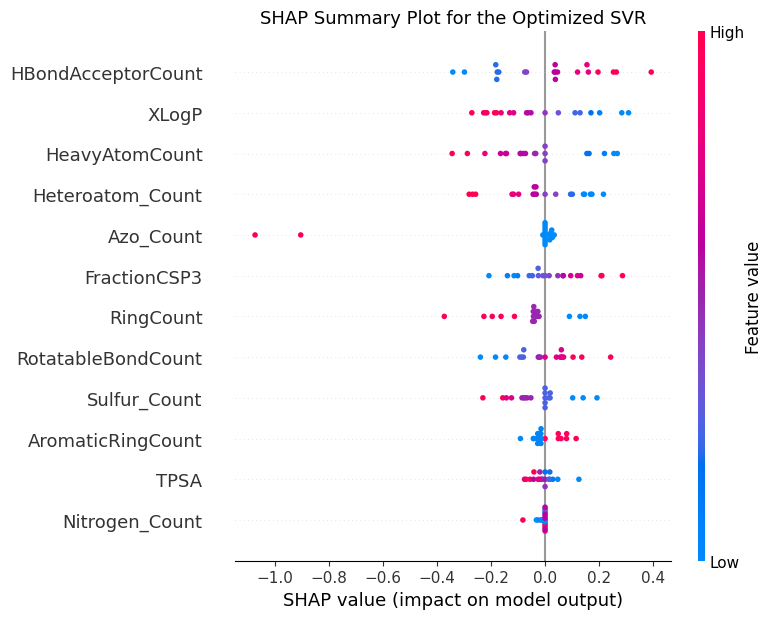

In [ ]:
# ============================================================
# STEP 103 — SHAP BEESWARM
# ============================================================

plt.figure(figsize=(8, 6))

shap.summary_plot(
    shap_values,
    X_test_final_df,
    show=False
)

plt.title(
    "SHAP Summary Plot for the Optimized SVR",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "Figure_SHAP_Beeswarm_Optimized_SVR.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

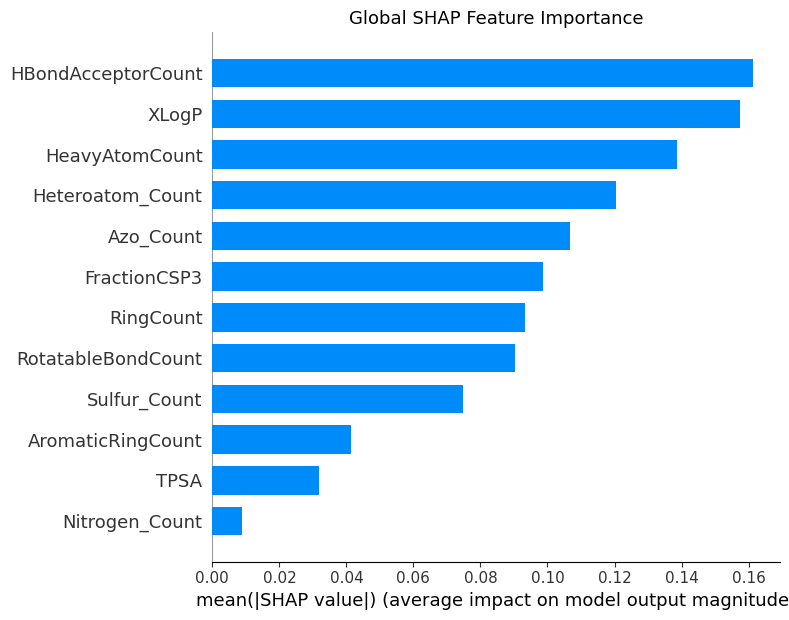

In [ ]:
# ============================================================
# STEP 104 — SHAP BAR PLOT
# ============================================================

plt.figure(figsize=(8, 6))

shap.summary_plot(
    shap_values,
    X_test_final_df,
    plot_type="bar",
    show=False
)

plt.title(
    "Global SHAP Feature Importance",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "Figure_SHAP_Global_Importance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

TOP 5 SHAP DESCRIPTORS
1. HBondAcceptorCount
2. XLogP
3. HeavyAtomCount
4. Heteroatom_Count
5. Azo_Count


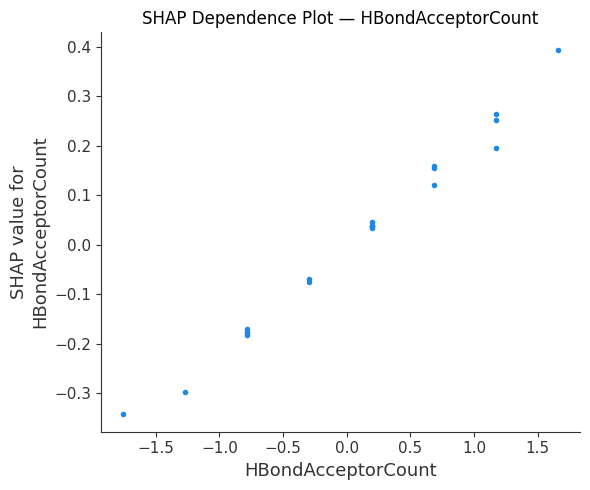

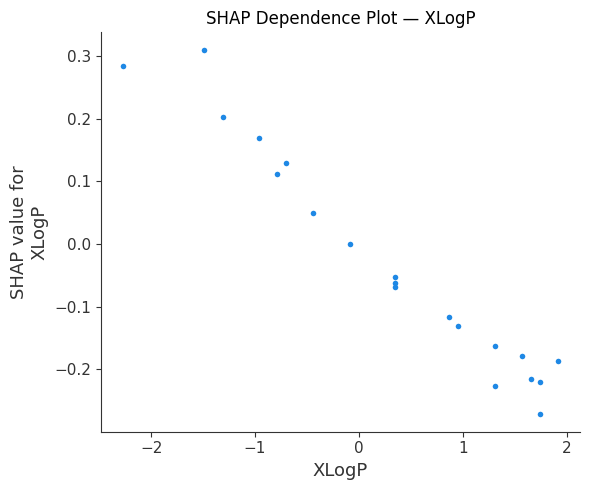

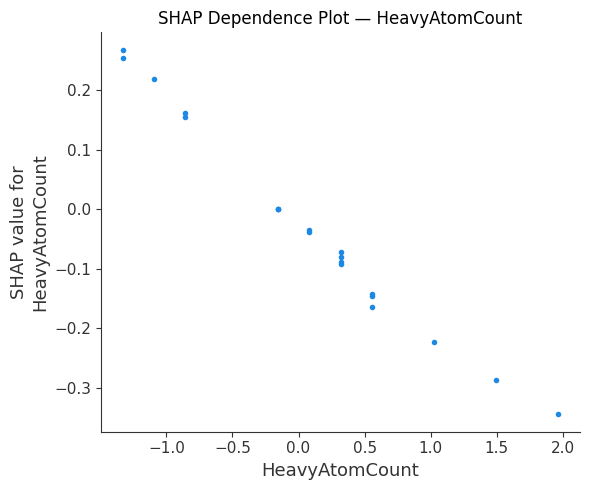

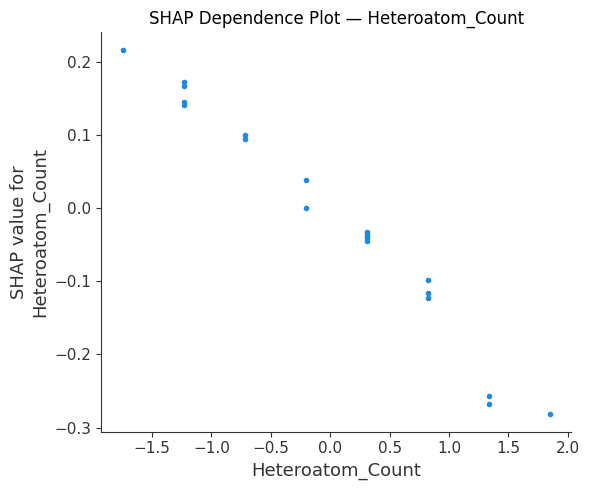

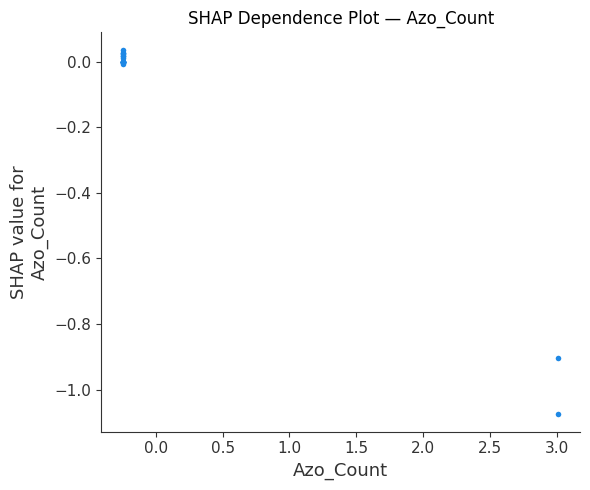

In [ ]:
# ============================================================
# STEP 105 — SHAP DEPENDENCE PLOTS FOR TOP 5 DESCRIPTORS
# ============================================================

top5_features = (
    shap_importance_df
    .head(5)["Descriptor"]
    .tolist()
)

print("=" * 70)
print("TOP 5 SHAP DESCRIPTORS")
print("=" * 70)

for i, feature in enumerate(top5_features, 1):
    print(f"{i}. {feature}")


for feature in top5_features:

    shap.dependence_plot(
        feature,
        shap_values,
        X_test_final_df,
        interaction_index=None,
        show=False
    )

    plt.title(
        f"SHAP Dependence Plot — {feature}"
    )

    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        f"SHAP_Dependence_{safe_name}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# ============================================================
# STEP 106 — DESCRIPTOR vs SHAP DIRECTION
# ============================================================

direction_results = []

for feature in final_features:

    feature_index = list(
        final_features
    ).index(feature)

    feature_values = X_test_final_df[
        feature
    ].values

    feature_shap = shap_values[
        :, feature_index
    ]

    pearson = np.corrcoef(
        feature_values,
        feature_shap
    )[0, 1]

    spearman = pd.Series(
        feature_values
    ).corr(
        pd.Series(feature_shap),
        method="spearman"
    )

    direction_results.append({

        "Descriptor": feature,

        "Mean_Abs_SHAP":
            np.mean(
                np.abs(feature_shap)
            ),

        "Pearson":
            pearson,

        "Spearman":
            spearman
    })

direction_df = pd.DataFrame(
    direction_results
).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

display(direction_df)

,Descriptor,Mean_Abs_SHAP,Pearson,Spearman
2,HBondAcceptorCount,0.161308,0.994593,0.985229
1,XLogP,0.157340,-0.979497,-0.965338
4,HeavyAtomCount,0.138669,-0.992548,-0.993569
11,Heteroatom_Count,0.120585,-0.985290,-0.985992
10,Azo_Count,0.106812,-0.995325,-0.555889
7,FractionCSP3,0.098687,0.990487,0.990212
5,RingCount,0.093356,-0.978891,-0.880021
3,RotatableBondCount,0.090294,0.985962,0.972556
9,Sulfur_Count,0.074803,-0.953156,-0.965038
6,AromaticRingCount,0.041420,0.944182,0.871003


In [ ]:
# ============================================================
# STEP 107 — APPLICABILITY DOMAIN
# ============================================================

from sklearn.metrics import pairwise_distances

# Training data already transformed for the final SVR
X_train_ad = X_train_final
X_test_ad = X_test_final

# Euclidean distance in standardized descriptor space
distances = pairwise_distances(
    X_test_ad,
    X_train_ad,
    metric="euclidean"
)

nearest_distance = distances.min(
    axis=1
)

ad_df = pd.DataFrame({

    "Molecule_Index":
        X_expanded_test.index,

    "Nearest_Training_Distance":
        nearest_distance,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Absolute_Error":
        np.abs(
            y_expanded_test.values -
            y_test_pred
        )
})

ad_df = ad_df.sort_values(
    "Nearest_Training_Distance",
    ascending=False
)

display(ad_df)

,Molecule_Index,Nearest_Training_Distance,Experimental,Predicted,Absolute_Error
13,33,3.557258,2.203078,1.975424,0.227653
3,45,3.542723,1.543664,1.323601,0.220062
18,12,3.367114,1.766412,1.477126,0.289286
8,10,3.111226,1.273631,1.243989,0.029642
15,4,3.038813,1.530270,2.175054,0.644783
14,90,2.684302,2.158715,2.122686,0.036029
16,76,2.584522,3.284158,2.783963,0.500195
10,18,2.505656,1.392498,2.379837,0.987338
6,22,2.355590,2.418419,2.063855,0.354564
0,83,2.186878,2.404902,2.448131,0.043230


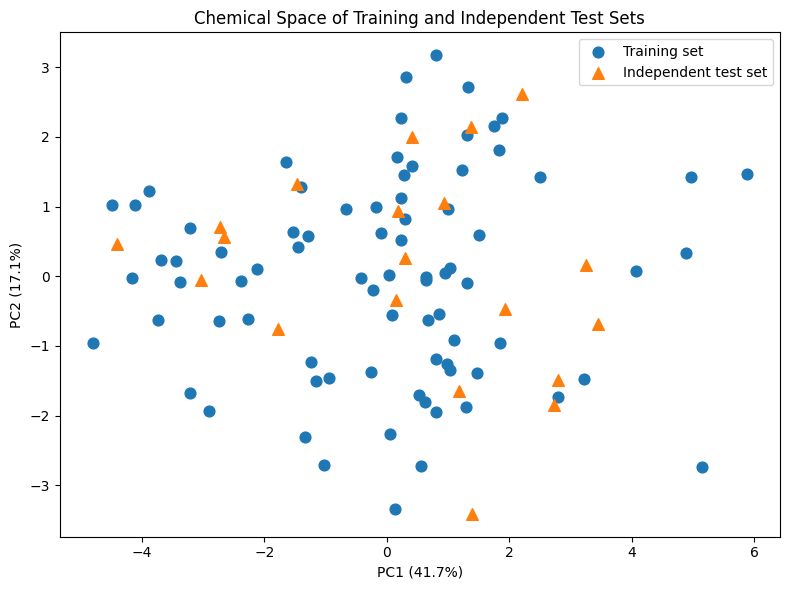

PC1 variance: 0.4167363128228528
PC2 variance: 0.17140872815540711


In [ ]:
# ============================================================
# STEP 108 — PCA CHEMICAL SPACE
# ============================================================

from sklearn.decomposition import PCA

X_all_ad = np.vstack([
    X_train_ad,
    X_test_ad
])

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_all_ad
)

n_train = len(X_train_ad)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:n_train, 0],
    X_pca[:n_train, 1],
    s=60,
    label="Training set"
)

plt.scatter(
    X_pca[n_train:, 0],
    X_pca[n_train:, 1],
    s=70,
    marker="^",
    label="Independent test set"
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title(
    "Chemical Space of Training and Independent Test Sets"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "Figure_PCA_Chemical_Space.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    "PC1 variance:",
    pca.explained_variance_ratio_[0]
)

print(
    "PC2 variance:",
    pca.explained_variance_ratio_[1]
)

In [ ]:
# ============================================================
# STEP 109 — FINAL TEST PREDICTION TABLE
# ============================================================

final_prediction_table = pd.DataFrame({

    "Molecule_Index":
        X_expanded_test.index,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Residual":
        y_expanded_test.values -
        y_test_pred,

    "Absolute_Error":
        np.abs(
            y_expanded_test.values -
            y_test_pred
        ),

    "AD_Distance":
        nearest_distance
})

display(
    final_prediction_table
)

final_prediction_table.to_csv(
    "Final_SVR_Test_Predictions.csv",
    index=False
)

,Molecule_Index,Experimental,Predicted,Residual,Absolute_Error,AD_Distance
0,83,2.404902,2.448131,-0.043230,0.043230,2.186878
1,53,2.980455,3.084683,-0.104228,0.104228,1.438576
2,70,3.311998,3.310178,0.001820,0.001820,1.774295
3,45,1.543664,1.323601,0.220062,0.220062,3.542723
4,44,2.907467,2.622239,0.285228,0.285228,0.635724
5,39,3.160094,2.789855,0.370239,0.370239,1.702703
6,22,2.418419,2.063855,0.354564,0.354564,2.355590
7,80,2.738958,2.385648,0.353310,0.353310,1.845351
8,10,1.273631,1.243989,0.029642,0.029642,3.111226
9,0,2.890494,2.530010,0.360484,0.360484,1.739513


In [ ]:
# ============================================================
# STEP 110 — QUANTITATIVE APPLICABILITY DOMAIN
# ============================================================

from sklearn.metrics import pairwise_distances

# Final transformed descriptor matrices
# These correspond to the final optimized SVR

X_train_AD = X_train_final
X_test_AD = X_test_final

# ------------------------------------------------------------
# Calculate Euclidean distance from each test molecule
# to every training molecule
# ------------------------------------------------------------

distance_matrix = pairwise_distances(
    X_test_AD,
    X_train_AD,
    metric="euclidean"
)

# Nearest training molecule
nearest_distance = distance_matrix.min(axis=1)

nearest_training_index = (
    distance_matrix.argmin(axis=1)
)

# ------------------------------------------------------------
# Create AD table
# ------------------------------------------------------------

AD_results = pd.DataFrame({

    "Test_Molecule":
        X_expanded_test.index,

    "Nearest_Training_Molecule":
        X_expanded_train.index[
            nearest_training_index
        ],

    "Nearest_Distance":
        nearest_distance,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Absolute_Error":
        np.abs(
            y_expanded_test.values -
            y_test_pred
        )
})

AD_results = AD_results.sort_values(
    "Nearest_Distance",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("APPLICABILITY DOMAIN — FINAL SVR")
print("=" * 80)

display(AD_results)

APPLICABILITY DOMAIN — FINAL SVR


,Test_Molecule,Nearest_Training_Molecule,Nearest_Distance,Experimental,Predicted,Absolute_Error
0,33,92,3.557258,2.203078,1.975424,0.227653
1,45,82,3.542723,1.543664,1.323601,0.220062
2,12,51,3.367114,1.766412,1.477126,0.289286
3,10,11,3.111226,1.273631,1.243989,0.029642
4,4,41,3.038813,1.530270,2.175054,0.644783
5,90,81,2.684302,2.158715,2.122686,0.036029
6,76,99,2.584522,3.284158,2.783963,0.500195
7,18,60,2.505656,1.392498,2.379837,0.987338
8,22,92,2.355590,2.418419,2.063855,0.354564
9,83,29,2.186878,2.404902,2.448131,0.043230


In [ ]:
# ============================================================
# STEP 111 — AD SUMMARY
# ============================================================

print("=" * 70)
print("APPLICABILITY DOMAIN SUMMARY")
print("=" * 70)

print(
    "Minimum nearest-neighbor distance:",
    AD_results["Nearest_Distance"].min()
)

print(
    "Maximum nearest-neighbor distance:",
    AD_results["Nearest_Distance"].max()
)

print(
    "Mean nearest-neighbor distance:",
    AD_results["Nearest_Distance"].mean()
)

print(
    "Median nearest-neighbor distance:",
    AD_results["Nearest_Distance"].median()
)

APPLICABILITY DOMAIN SUMMARY
Minimum nearest-neighbor distance: 0.6357240916346663
Maximum nearest-neighbor distance: 3.5572579224350926
Mean nearest-neighbor distance: 2.142484688174823
Median nearest-neighbor distance: 2.0711088161111664


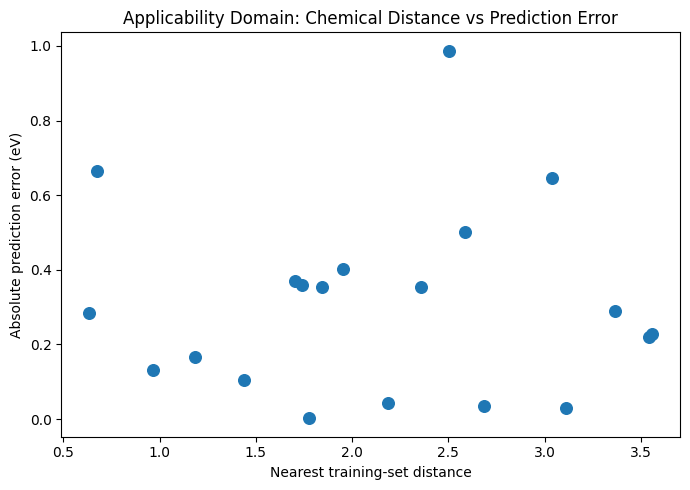

In [ ]:
# ============================================================
# STEP 112 — AD DISTANCE VS PREDICTION ERROR
# ============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    AD_results["Nearest_Distance"],
    AD_results["Absolute_Error"],
    s=70
)

plt.xlabel(
    "Nearest training-set distance"
)

plt.ylabel(
    "Absolute prediction error (eV)"
)

plt.title(
    "Applicability Domain: Chemical Distance vs Prediction Error"
)

plt.tight_layout()

plt.savefig(
    "Figure_Applicability_Domain.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

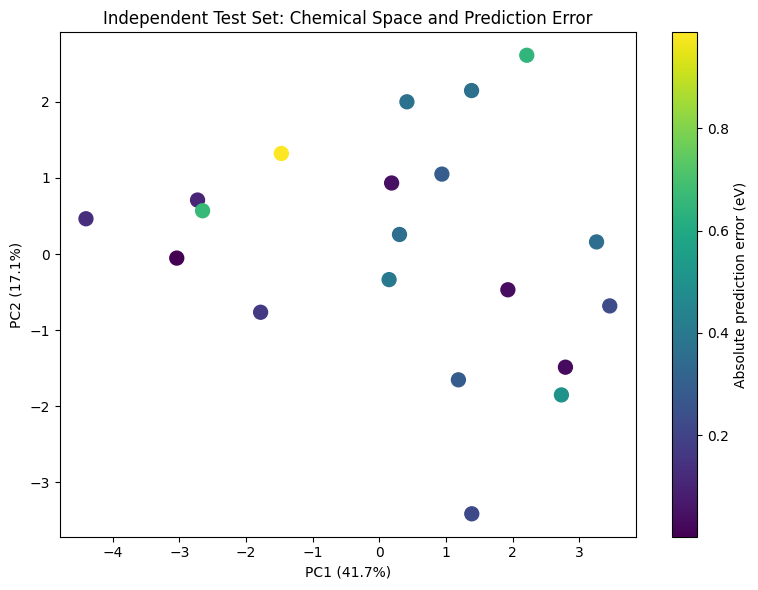

In [ ]:
# ============================================================
# STEP 113 — PCA WITH TEST-SET PREDICTION ERROR
# ============================================================

# PCA coordinates already calculated

test_pca = X_pca[n_train:]

test_errors = np.abs(
    y_expanded_test.values -
    y_test_pred
)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    test_pca[:, 0],
    test_pca[:, 1],
    c=test_errors,
    s=100
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title(
    "Independent Test Set: Chemical Space and Prediction Error"
)

plt.colorbar(
    scatter,
    label="Absolute prediction error (eV)"
)

plt.tight_layout()

plt.savefig(
    "Figure_PCA_Test_Prediction_Error.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# STEP 114 — HIGHEST PREDICTION ERRORS
# ============================================================

error_table = pd.DataFrame({
    "Molecule_Index": X_expanded_test.index,
    "Experimental": y_expanded_test.values,
    "Predicted": y_test_pred,
    "Residual": (
        y_expanded_test.values - y_test_pred
    ),
    "Absolute_Error": np.abs(
        y_expanded_test.values - y_test_pred
    )
})

error_table = error_table.sort_values(
    "Absolute_Error",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("INDEPENDENT TEST SET — PREDICTION ERROR RANKING")
print("=" * 80)

display(error_table)

INDEPENDENT TEST SET — PREDICTION ERROR RANKING


,Molecule_Index,Experimental,Predicted,Residual,Absolute_Error
0,18,1.392498,2.379837,-0.987338,0.987338
1,31,3.359370,2.693383,0.665986,0.665986
2,4,1.530270,2.175054,-0.644783,0.644783
3,76,3.284158,2.783963,0.500195,0.500195
4,30,2.442679,2.844614,-0.401934,0.401934
5,39,3.160094,2.789855,0.370239,0.370239
6,0,2.890494,2.530010,0.360484,0.360484
7,22,2.418419,2.063855,0.354564,0.354564
8,80,2.738958,2.385648,0.353310,0.353310
9,12,1.766412,1.477126,0.289286,0.289286


In [ ]:
# ============================================================
# STEP 115 — ERROR DISTRIBUTION
# ============================================================

print("=" * 70)
print("PREDICTION ERROR STATISTICS")
print("=" * 70)

print(
    "Mean absolute error:",
    np.mean(
        np.abs(
            y_expanded_test.values - y_test_pred
        )
    )
)

print(
    "Median absolute error:",
    np.median(
        np.abs(
            y_expanded_test.values - y_test_pred
        )
    )
)

print(
    "Maximum absolute error:",
    np.max(
        np.abs(
            y_expanded_test.values - y_test_pred
        )
    )
)

print(
    "Minimum absolute error:",
    np.min(
        np.abs(
            y_expanded_test.values - y_test_pred
        )
    )
)

PREDICTION ERROR STATISTICS
Mean absolute error: 0.30871685715540015
Median absolute error: 0.2872570625630779
Maximum absolute error: 0.9873381512307564
Minimum absolute error: 0.0018195943177654605


In [ ]:
# ============================================================
# STEP 116 — FINAL APPLICABILITY DOMAIN TABLE
# ============================================================

from sklearn.metrics import pairwise_distances

distance_matrix = pairwise_distances(
    X_test_final,
    X_train_final,
    metric="euclidean"
)

nearest_distance = distance_matrix.min(
    axis=1
)

nearest_training_position = (
    distance_matrix.argmin(axis=1)
)

AD_results = pd.DataFrame({

    "Test_Molecule":
        X_expanded_test.index,

    "Nearest_Training_Molecule":
        X_expanded_train.index[
            nearest_training_position
        ],

    "Nearest_Distance":
        nearest_distance,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Absolute_Error":
        np.abs(
            y_expanded_test.values -
            y_test_pred
        )
})

AD_results = AD_results.sort_values(
    "Nearest_Distance",
    ascending=False
).reset_index(drop=True)

display(AD_results)

,Test_Molecule,Nearest_Training_Molecule,Nearest_Distance,Experimental,Predicted,Absolute_Error
0,33,92,3.557258,2.203078,1.975424,0.227653
1,45,82,3.542723,1.543664,1.323601,0.220062
2,12,51,3.367114,1.766412,1.477126,0.289286
3,10,11,3.111226,1.273631,1.243989,0.029642
4,4,41,3.038813,1.530270,2.175054,0.644783
5,90,81,2.684302,2.158715,2.122686,0.036029
6,76,99,2.584522,3.284158,2.783963,0.500195
7,18,60,2.505656,1.392498,2.379837,0.987338
8,22,92,2.355590,2.418419,2.063855,0.354564
9,83,29,2.186878,2.404902,2.448131,0.043230


In [ ]:
# ============================================================
# STEP 117 — AD SUMMARY
# ============================================================

print("=" * 70)
print("APPLICABILITY DOMAIN SUMMARY")
print("=" * 70)

print(
    f"Minimum distance : "
    f"{AD_results['Nearest_Distance'].min():.4f}"
)

print(
    f"Maximum distance : "
    f"{AD_results['Nearest_Distance'].max():.4f}"
)

print(
    f"Mean distance    : "
    f"{AD_results['Nearest_Distance'].mean():.4f}"
)

print(
    f"Median distance  : "
    f"{AD_results['Nearest_Distance'].median():.4f}"
)

APPLICABILITY DOMAIN SUMMARY
Minimum distance : 0.6357
Maximum distance : 3.5573
Mean distance    : 2.1425
Median distance  : 2.0711


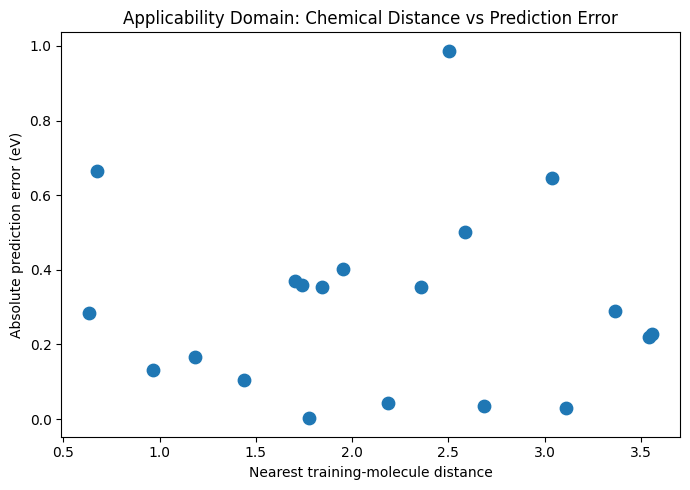

Distance–error Pearson correlation: -0.0038


In [ ]:
# ============================================================
# STEP 118 — AD DISTANCE VS PREDICTION ERROR
# ============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    AD_results["Nearest_Distance"],
    AD_results["Absolute_Error"],
    s=80
)

plt.xlabel(
    "Nearest training-molecule distance"
)

plt.ylabel(
    "Absolute prediction error (eV)"
)

plt.title(
    "Applicability Domain: Chemical Distance vs Prediction Error"
)

plt.tight_layout()

plt.savefig(
    "Figure_AD_Distance_vs_Error.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Correlation
correlation = np.corrcoef(
    AD_results["Nearest_Distance"],
    AD_results["Absolute_Error"]
)[0, 1]

print(
    f"Distance–error Pearson correlation: "
    f"{correlation:.4f}"
)

In [ ]:
# ============================================================
# STEP 114 — QUANTITATIVE APPLICABILITY DOMAIN THRESHOLD
# ============================================================

from sklearn.metrics import pairwise_distances
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Distance matrix: training vs training
# ------------------------------------------------------------

train_distance_matrix = pairwise_distances(
    X_train_final,
    X_train_final,
    metric="euclidean"
)

# Exclude self-distance
np.fill_diagonal(
    train_distance_matrix,
    np.inf
)

# Nearest other training molecule
train_nearest_distance = (
    train_distance_matrix.min(axis=1)
)

# 95th percentile threshold
AD_threshold = np.percentile(
    train_nearest_distance,
    95
)

print("=" * 70)
print("APPLICABILITY DOMAIN THRESHOLD")
print("=" * 70)

print(
    f"Training nearest-neighbor median: "
    f"{np.median(train_nearest_distance):.4f}"
)

print(
    f"Training nearest-neighbor mean: "
    f"{np.mean(train_nearest_distance):.4f}"
)

print(
    f"95th percentile AD threshold: "
    f"{AD_threshold:.4f}"
)

APPLICABILITY DOMAIN THRESHOLD
Training nearest-neighbor median: 1.7349
Training nearest-neighbor mean: 1.8596
95th percentile AD threshold: 3.4822


In [ ]:
# ============================================================
# STEP 115 — TEST SET AD CLASSIFICATION
# ============================================================

test_train_distances = pairwise_distances(
    X_test_final,
    X_train_final,
    metric="euclidean"
)

test_nearest_distance = (
    test_train_distances.min(axis=1)
)

AD_status = np.where(
    test_nearest_distance <= AD_threshold,
    "Within AD",
    "Outside AD"
)

AD_results = pd.DataFrame({

    "Molecule_Index":
        X_expanded_test.index,

    "Nearest_Training_Distance":
        test_nearest_distance,

    "AD_Status":
        AD_status,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Absolute_Error":
        np.abs(
            y_expanded_test.values -
            y_test_pred
        )
})

AD_results = AD_results.sort_values(
    "Nearest_Training_Distance",
    ascending=False
).reset_index(drop=True)

display(AD_results)

,Molecule_Index,Nearest_Training_Distance,AD_Status,Experimental,Predicted,Absolute_Error
0,33,3.557258,Outside AD,2.203078,1.975424,0.227653
1,45,3.542723,Outside AD,1.543664,1.323601,0.220062
2,12,3.367114,Within AD,1.766412,1.477126,0.289286
3,10,3.111226,Within AD,1.273631,1.243989,0.029642
4,4,3.038813,Within AD,1.530270,2.175054,0.644783
5,90,2.684302,Within AD,2.158715,2.122686,0.036029
6,76,2.584522,Within AD,3.284158,2.783963,0.500195
7,18,2.505656,Within AD,1.392498,2.379837,0.987338
8,22,2.355590,Within AD,2.418419,2.063855,0.354564
9,83,2.186878,Within AD,2.404902,2.448131,0.043230


In [ ]:
print("=" * 70)
print("AD SUMMARY")
print("=" * 70)

print(
    "Total test molecules:",
    len(AD_results)
)

print(
    "Within AD:",
    (AD_results["AD_Status"] == "Within AD").sum()
)

print(
    "Outside AD:",
    (AD_results["AD_Status"] == "Outside AD").sum()
)

AD SUMMARY
Total test molecules: 20
Within AD: 18
Outside AD: 2


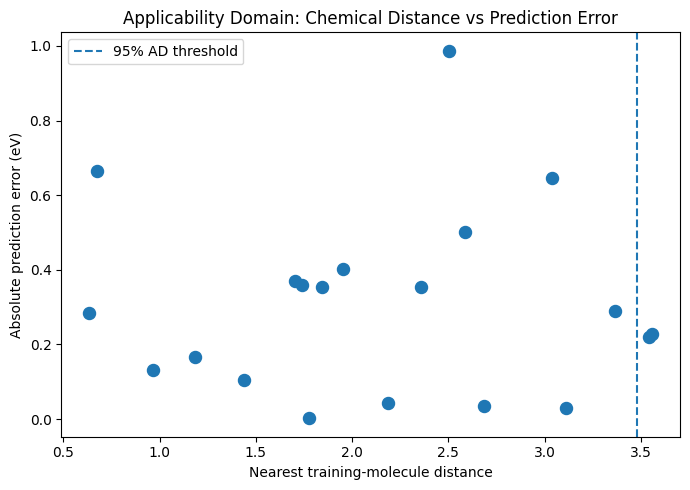

Distance–error Pearson correlation: -0.0038


In [ ]:
# ============================================================
# STEP 116 — APPLICABILITY DOMAIN VALIDATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    AD_results["Nearest_Training_Distance"],
    AD_results["Absolute_Error"],
    s=75
)

plt.axvline(
    AD_threshold,
    linestyle="--",
    linewidth=1.5,
    label="95% AD threshold"
)

plt.xlabel(
    "Nearest training-molecule distance"
)

plt.ylabel(
    "Absolute prediction error (eV)"
)

plt.title(
    "Applicability Domain: Chemical Distance vs Prediction Error"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "Figure_AD_Distance_vs_Error.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

correlation = np.corrcoef(
    AD_results["Nearest_Training_Distance"],
    AD_results["Absolute_Error"]
)[0, 1]

print(
    f"Distance–error Pearson correlation: "
    f"{correlation:.4f}"
)

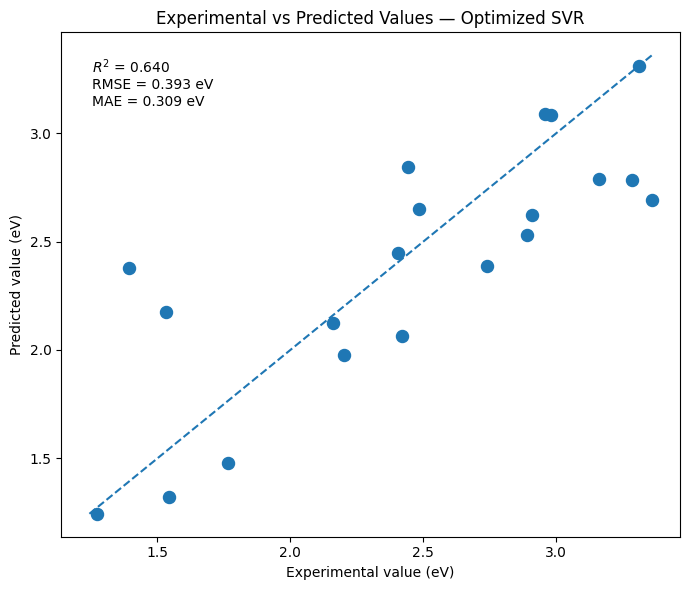

Test R² : 0.6400024281650873
Test RMSE: 0.3929817629208998
Test MAE : 0.30871685715540015


In [ ]:
# ============================================================
# STEP 117 — EXPERIMENTAL VS PREDICTED
# ============================================================

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

r2_test = r2_score(
    y_expanded_test,
    y_test_pred
)

rmse_test = np.sqrt(
    mean_squared_error(
        y_expanded_test,
        y_test_pred
    )
)

mae_test = mean_absolute_error(
    y_expanded_test,
    y_test_pred
)

plt.figure(figsize=(7, 6))

plt.scatter(
    y_expanded_test,
    y_test_pred,
    s=75
)

# 1:1 line
minimum = min(
    y_expanded_test.min(),
    y_test_pred.min()
)

maximum = max(
    y_expanded_test.max(),
    y_test_pred.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=1.5
)

plt.xlabel(
    "Experimental value (eV)"
)

plt.ylabel(
    "Predicted value (eV)"
)

plt.title(
    "Experimental vs Predicted Values — Optimized SVR"
)

plt.text(
    0.05,
    0.95,
    f"$R^2$ = {r2_test:.3f}\n"
    f"RMSE = {rmse_test:.3f} eV\n"
    f"MAE = {mae_test:.3f} eV",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

plt.savefig(
    "Figure_Experimental_vs_Predicted_SVR.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Test R² :", r2_test)
print("Test RMSE:", rmse_test)
print("Test MAE :", mae_test)

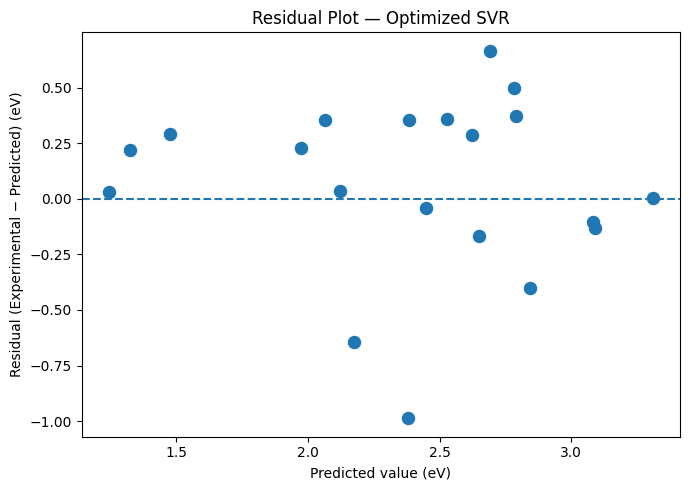

In [ ]:
# ============================================================
# STEP 118 — RESIDUAL ANALYSIS
# ============================================================

residuals = (
    y_expanded_test.values -
    y_test_pred
)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_pred,
    residuals,
    s=75
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel(
    "Predicted value (eV)"
)

plt.ylabel(
    "Residual (Experimental − Predicted) (eV)"
)

plt.title(
    "Residual Plot — Optimized SVR"
)

plt.tight_layout()

plt.savefig(
    "Figure_SVR_Residuals.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# STEP 119 — RESIDUAL STATISTICS
# ============================================================

print("=" * 70)
print("RESIDUAL STATISTICS")
print("=" * 70)

print(
    f"Mean residual   : {np.mean(residuals):.4f} eV"
)

print(
    f"SD residual     : {np.std(residuals, ddof=1):.4f} eV"
)

print(
    f"Minimum residual: {np.min(residuals):.4f} eV"
)

print(
    f"Maximum residual: {np.max(residuals):.4f} eV"
)

print(
    f"MAE             : "
    f"{np.mean(np.abs(residuals)):.4f} eV"
)

RESIDUAL STATISTICS
Mean residual   : 0.0607 eV
SD residual     : 0.3983 eV
Minimum residual: -0.9873 eV
Maximum residual: 0.6660 eV
MAE             : 0.3087 eV


In [ ]:
# ============================================================
# STEP 120 — TEST SET ERROR RANKING
# ============================================================

error_table = pd.DataFrame({

    "Molecule_Index":
        X_expanded_test.index,

    "Experimental":
        y_expanded_test.values,

    "Predicted":
        y_test_pred,

    "Residual":
        residuals,

    "Absolute_Error":
        np.abs(residuals)

})

error_table = error_table.sort_values(
    "Absolute_Error",
    ascending=False
).reset_index(drop=True)

display(error_table)

,Molecule_Index,Experimental,Predicted,Residual,Absolute_Error
0,18,1.392498,2.379837,-0.987338,0.987338
1,31,3.359370,2.693383,0.665986,0.665986
2,4,1.530270,2.175054,-0.644783,0.644783
3,76,3.284158,2.783963,0.500195,0.500195
4,30,2.442679,2.844614,-0.401934,0.401934
5,39,3.160094,2.789855,0.370239,0.370239
6,0,2.890494,2.530010,0.360484,0.360484
7,22,2.418419,2.063855,0.354564,0.354564
8,80,2.738958,2.385648,0.353310,0.353310
9,12,1.766412,1.477126,0.289286,0.289286


In [ ]:
# ============================================================
# STEP 121 — FINAL MODEL PERFORMANCE TABLE
# ============================================================

final_performance = pd.DataFrame({

    "Model": [
        "Optimized RBF-SVR"
    ],

    "Feature_Count": [
        len(final_features)
    ],

    "C": [
        svr_search.best_params_["model__C"]
    ],

    "Gamma": [
        svr_search.best_params_["model__gamma"]
    ],

    "Epsilon": [
        svr_search.best_params_["model__epsilon"]
    ],

    "Test_R2": [
        r2_test
    ],

    "Test_RMSE_eV": [
        rmse_test
    ],

    "Test_MAE_eV": [
        mae_test
    ]
})

display(final_performance)

final_performance.to_csv(
    "Final_Optimized_SVR_Performance.csv",
    index=False
)

,Model,Feature_Count,C,Gamma,Epsilon,Test_R2,Test_RMSE_eV,Test_MAE_eV
0,Optimized RBF-SVR,12,10,0.01,0.1,0.640002,0.392982,0.308717


In [ ]:
# ============================================================
# STEP 122 — FINAL SHAP TABLE
# ============================================================

shap_importance_df.to_csv(
    "Final_SHAP_Feature_Importance.csv",
    index=False
)

display(
    shap_importance_df
)

,Rank,Descriptor,Mean_Absolute_SHAP,SHAP_Percentage
0,1,HBondAcceptorCount,0.161308,14.354585
1,2,XLogP,0.157340,14.001503
2,3,HeavyAtomCount,0.138669,12.339939
3,4,Heteroatom_Count,0.120585,10.730699
4,5,Azo_Count,0.106812,9.505062
5,6,FractionCSP3,0.098687,8.781986
6,7,RingCount,0.093356,8.307618
7,8,RotatableBondCount,0.090294,8.035182
8,9,Sulfur_Count,0.074803,6.656605
9,10,AromaticRingCount,0.041420,3.685954


In [ ]:
# ============================================================
# STEP 123 — FINAL AD TABLE
# ============================================================

AD_results.to_csv(
    "Final_Applicability_Domain_Results.csv",
    index=False
)

display(AD_results)

,Molecule_Index,Nearest_Training_Distance,AD_Status,Experimental,Predicted,Absolute_Error
0,33,3.557258,Outside AD,2.203078,1.975424,0.227653
1,45,3.542723,Outside AD,1.543664,1.323601,0.220062
2,12,3.367114,Within AD,1.766412,1.477126,0.289286
3,10,3.111226,Within AD,1.273631,1.243989,0.029642
4,4,3.038813,Within AD,1.530270,2.175054,0.644783
5,90,2.684302,Within AD,2.158715,2.122686,0.036029
6,76,2.584522,Within AD,3.284158,2.783963,0.500195
7,18,2.505656,Within AD,1.392498,2.379837,0.987338
8,22,2.355590,Within AD,2.418419,2.063855,0.354564
9,83,2.186878,Within AD,2.404902,2.448131,0.043230


In [ ]:
# ============================================================
# STEP 124 — BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import numpy as np

# ------------------------------------------------------------
# Original independent test results
# ------------------------------------------------------------

y_true = np.asarray(
    y_expanded_test.values
)

y_pred = np.asarray(
    y_test_pred
)

# ------------------------------------------------------------
# Bootstrap
# ------------------------------------------------------------

rng = np.random.default_rng(42)

n_bootstrap = 5000
n_test = len(y_true)

bootstrap_r2 = []
bootstrap_rmse = []
bootstrap_mae = []

for i in range(n_bootstrap):

    indices = rng.integers(
        0,
        n_test,
        size=n_test
    )

    y_true_boot = y_true[indices]
    y_pred_boot = y_pred[indices]

    # R² cannot be calculated if all
    # bootstrap y values are identical
    if np.std(y_true_boot) > 0:

        bootstrap_r2.append(
            r2_score(
                y_true_boot,
                y_pred_boot
            )
        )

    bootstrap_rmse.append(
        np.sqrt(
            mean_squared_error(
                y_true_boot,
                y_pred_boot
            )
        )
    )

    bootstrap_mae.append(
        mean_absolute_error(
            y_true_boot,
            y_pred_boot
        )
    )

# ------------------------------------------------------------
# 95% confidence intervals
# ------------------------------------------------------------

r2_ci = np.percentile(
    bootstrap_r2,
    [2.5, 97.5]
)

rmse_ci = np.percentile(
    bootstrap_rmse,
    [2.5, 97.5]
)

mae_ci = np.percentile(
    bootstrap_mae,
    [2.5, 97.5]
)

# ------------------------------------------------------------
# Original metrics
# ------------------------------------------------------------

original_r2 = r2_score(
    y_true,
    y_pred
)

original_rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

original_mae = mean_absolute_error(
    y_true,
    y_pred
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 75)
print("BOOTSTRAP VALIDATION — OPTIMIZED SVR")
print("=" * 75)

print(
    f"R²   = {original_r2:.4f}"
)

print(
    f"95% CI = "
    f"{r2_ci[0]:.4f} – {r2_ci[1]:.4f}"
)

print()

print(
    f"RMSE = {original_rmse:.4f} eV"
)

print(
    f"95% CI = "
    f"{rmse_ci[0]:.4f} – {rmse_ci[1]:.4f} eV"
)

print()

print(
    f"MAE  = {original_mae:.4f} eV"
)

print(
    f"95% CI = "
    f"{mae_ci[0]:.4f} – {mae_ci[1]:.4f} eV"
)

BOOTSTRAP VALIDATION — OPTIMIZED SVR
R²   = 0.6400
95% CI = 0.3602 – 0.8167

RMSE = 0.3930 eV
95% CI = 0.2651 – 0.5148 eV

MAE  = 0.3087 eV
95% CI = 0.2055 – 0.4209 eV


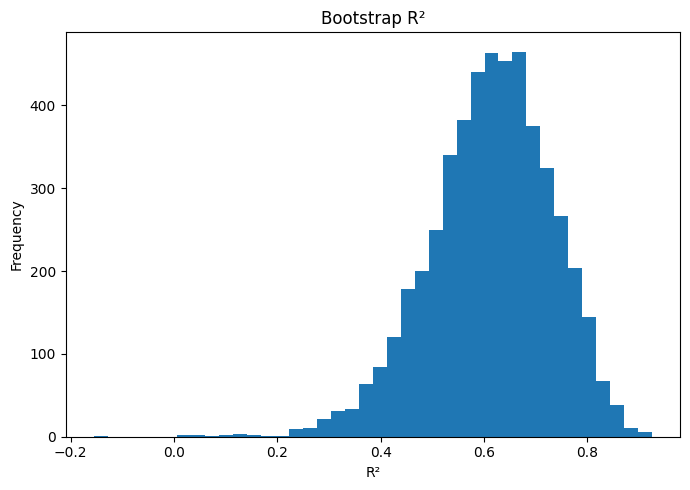

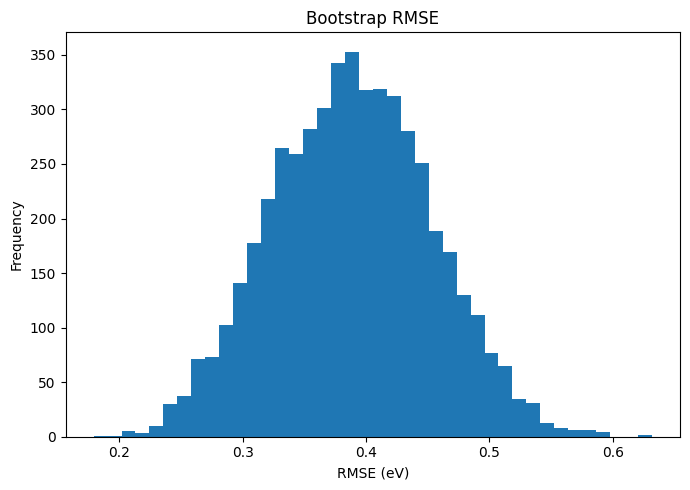

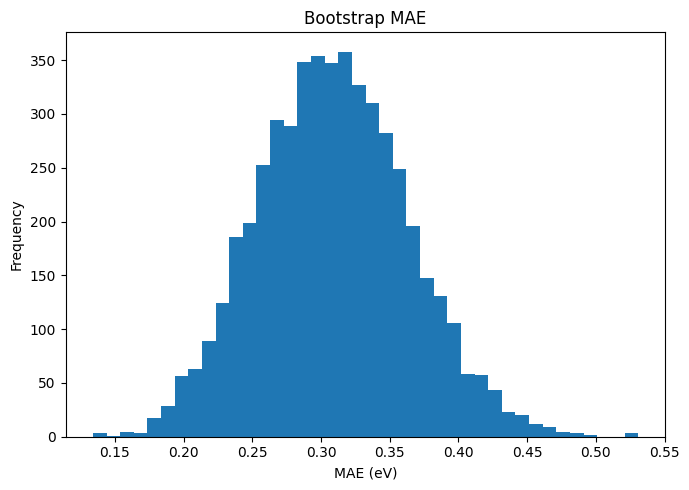

In [ ]:
# ============================================================
# STEP 125 — BOOTSTRAP DISTRIBUTIONS
# ============================================================

figures = [
    (
        bootstrap_r2,
        "Bootstrap R²",
        "R²"
    ),
    (
        bootstrap_rmse,
        "Bootstrap RMSE",
        "RMSE (eV)"
    ),
    (
        bootstrap_mae,
        "Bootstrap MAE",
        "MAE (eV)"
    )
]

for values, title, xlabel in figures:

    plt.figure(figsize=(7, 5))

    plt.hist(
        values,
        bins=40
    )

    plt.xlabel(xlabel)
    plt.ylabel("Frequency")
    plt.title(title)

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# CHECK NaN VALUES IN FINAL 12 DESCRIPTORS
# ============================================================

X_check = X_expanded_train[final_features].copy()

nan_summary = X_check.isna().sum()

print("=" * 70)
print("MISSING VALUES IN FINAL DESCRIPTORS")
print("=" * 70)

display(
    nan_summary[
        nan_summary > 0
    ].sort_values(
        ascending=False
    )
)

print(
    "\nTotal NaN values:",
    X_check.isna().sum().sum()
)

MISSING VALUES IN FINAL DESCRIPTORS


,0
XLogP,3



Total NaN values: 3


In [ ]:
# ============================================================
# STEP 126 — REPEATED 5-FOLD CV WITH MEDIAN IMPUTATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import RepeatedKFold, cross_validate


# ------------------------------------------------------------
# 1. TRAINING DATA ONLY
# ------------------------------------------------------------

X_cv = X_expanded_train[
    final_features
].copy()

y_cv = y_expanded_train.copy()


# ------------------------------------------------------------
# 2. CHECK DATA
# ------------------------------------------------------------

print("=" * 70)
print("REPEATED CV INPUT")
print("=" * 70)

print("X shape:", X_cv.shape)
print("y shape:", y_cv.shape)

print(
    "Total missing values:",
    X_cv.isna().sum().sum()
)


# ------------------------------------------------------------
# 3. CREATE COMPLETE PIPELINE
# ------------------------------------------------------------

final_svr_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        SVR(
            kernel="rbf",
            C=10,
            gamma=0.01,
            epsilon=0.10
        )
    )
])


# ------------------------------------------------------------
# 4. REPEATED 5-FOLD CV
# ------------------------------------------------------------

cv_strategy = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


# ------------------------------------------------------------
# 5. CROSS-VALIDATION
# ------------------------------------------------------------

cv_results = cross_validate(

    final_svr_pipeline,

    X_cv,
    y_cv,

    cv=cv_strategy,

    scoring={
        "R2": "r2",
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error"
    },

    return_train_score=False,

    n_jobs=-1,

    error_score="raise"
)


# ------------------------------------------------------------
# 6. EXTRACT RESULTS
# ------------------------------------------------------------

r2_scores = cv_results[
    "test_R2"
]

rmse_scores = -cv_results[
    "test_RMSE"
]

mae_scores = -cv_results[
    "test_MAE"
]


# ------------------------------------------------------------
# 7. FINAL RESULTS
# ------------------------------------------------------------

print()
print("=" * 75)
print("REPEATED 5-FOLD CROSS-VALIDATION — OPTIMIZED SVR")
print("=" * 75)

print(
    f"R²   = "
    f"{r2_scores.mean():.4f} "
    f"± {r2_scores.std(ddof=1):.4f}"
)

print(
    f"RMSE = "
    f"{rmse_scores.mean():.4f} eV "
    f"± {rmse_scores.std(ddof=1):.4f} eV"
)

print(
    f"MAE  = "
    f"{mae_scores.mean():.4f} eV "
    f"± {mae_scores.std(ddof=1):.4f} eV"
)

print()

print(
    "Number of CV runs:",
    len(r2_scores)
)

REPEATED CV INPUT
X shape: (80, 12)
y shape: (80,)
Total missing values: 3

REPEATED 5-FOLD CROSS-VALIDATION — OPTIMIZED SVR
R²   = 0.1042 ± 0.4326
RMSE = 0.5436 eV ± 0.1421 eV
MAE  = 0.4240 eV ± 0.1062 eV

Number of CV runs: 50


In [ ]:
SimpleImputer(strategy="median")

SimpleImputer(strategy='median')

In [ ]:
StandardScaler()

StandardScaler()

In [ ]:
SVR(
    kernel="rbf",
    C=10,
    gamma=0.01,
    epsilon=0.10
)

SVR(C=10, gamma=0.01)

In [ ]:
SVR(
    kernel="rbf",
    C=10,
    gamma=0.01,
    epsilon=0.10
)

SVR(C=10, gamma=0.01)

In [ ]:
from sklearn.ensemble import VotingRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

vr = VotingRegressor(
    estimators=[
        ("svr", SVR(C=10, gamma=0.01, kernel="rbf")),
        ("rf", RandomForestRegressor(n_estimators=200, random_state=42)),
        ("gbr", GradientBoostingRegressor(random_state=42))
    ]
)

In [ ]:
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    VotingRegressor
)

svr = SVR(
    kernel="rbf",
    C=10,
    gamma=0.01,
    epsilon=0.1
)

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

etr = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

In [ ]:
vr = VotingRegressor(
    estimators=[
        ("svr", svr),
        ("rf", rf),
        ("gbr", gbr),
        ("etr", etr)
    ]
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

vr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", vr)
])

print(vr_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 VotingRegressor(estimators=[('svr', SVR(C=10, gamma=0.01)),
                                             ('rf',
                                              RandomForestRegressor(n_estimators=300,
                                                                    n_jobs=-1,
                                                                    random_state=42)),
                                             ('gbr',
                                              GradientBoostingRegressor(learning_rate=0.05,
                                                                        n_estimators=300,
                                                                        random_state=42)),
                                             ('etr',
                                              ExtraTreesRegressor(n_estimators=300,
                     

In [ ]:
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    VotingRegressor
)

svr = SVR(
    kernel="rbf",
    C=10,
    gamma=0.01,
    epsilon=0.1
)

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

etr = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

vr = VotingRegressor(
    estimators=[
        ("svr", svr),
        ("rf", rf),
        ("gbr", gbr),
        ("etr", etr)
    ]
)

In [ ]:
vr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", vr)
])

print(vr_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 VotingRegressor(estimators=[('svr', SVR(C=10, gamma=0.01)),
                                             ('rf',
                                              RandomForestRegressor(n_estimators=300,
                                                                    n_jobs=-1,
                                                                    random_state=42)),
                                             ('gbr',
                                              GradientBoostingRegressor(learning_rate=0.05,
                                                                        n_estimators=300,
                                                                        random_state=42)),
                                             ('etr',
                                              ExtraTreesRegressor(n_estimators=300,
                     

In [ ]:
vr_pipeline.fit(X_train, y_train)

print("Voting Regressor training completed successfully.")

Voting Regressor training completed successfully.


In [ ]:
y_train_pred = vr_pipeline.predict(X_train)
y_test_pred = vr_pipeline.predict(X_test)

print("Predictions generated successfully.")
print("Training predictions:", len(y_train_pred))
print("Testing predictions :", len(y_test_pred))

Predictions generated successfully.
Training predictions: 80
Testing predictions : 20


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("\nVoting Regressor Performance")
print("=" * 45)
print(f"Train R²  : {train_r2:.4f}")
print(f"Test R²   : {test_r2:.4f}")
print(f"Train MAE : {train_mae:.4f}")
print(f"Test MAE  : {test_mae:.4f}")
print(f"Train RMSE: {train_rmse:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")


Voting Regressor Performance
Train R²  : 0.8857
Test R²   : -0.0804
Train MAE : 0.1606
Test MAE  : 0.5303
Train RMSE: 0.2107
Test RMSE : 0.6808


In [ ]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

cv_results = cross_validate(
    vr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("\n5-Fold Cross-Validation")
print("=" * 45)
print(f"CV R²   : {cv_results['test_R2'].mean():.4f}")
print(f"CV MAE  : {-cv_results['test_MAE'].mean():.4f}")
print(f"CV RMSE : {-cv_results['test_RMSE'].mean():.4f}")


5-Fold Cross-Validation
CV R²   : -0.1065
CV MAE  : 0.4990
CV RMSE : 0.6280


In [ ]:
vr_result = {
    "Model": "Voting Regressor",
    "Train_R2": train_r2,
    "Test_R2": test_r2,
    "Train_MAE": train_mae,
    "Test_MAE": test_mae,
    "Train_RMSE": train_rmse,
    "Test_RMSE": test_rmse,
    "CV_R2": cv_results["test_R2"].mean(),
    "CV_MAE": -cv_results["test_MAE"].mean(),
    "CV_RMSE": -cv_results["test_RMSE"].mean()
}

print(vr_result)

{'Model': 'Voting Regressor', 'Train_R2': 0.8857039550370696, 'Test_R2': -0.08037332517661744, 'Train_MAE': 0.16060591928956777, 'Test_MAE': 0.5303235058871595, 'Train_RMSE': np.float64(0.21066619671317727), 'Test_RMSE': np.float64(0.6807843087031311), 'CV_R2': np.float64(-0.10649346260690969), 'CV_MAE': np.float64(0.4989944920092785), 'CV_RMSE': np.float64(0.6279642077379065)}


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

models = {
    "SVR": svr,
    "Random Forest": rf,
    "Gradient Boosting": gbr,
    "Extra Trees": etr,
    "Voting Regressor": vr
}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Train_R2": r2_score(y_train, train_pred),
        "Test_R2": r2_score(y_test, test_pred),
        "Train_MAE": mean_absolute_error(y_train, train_pred),
        "Test_MAE": mean_absolute_error(y_test, test_pred),
        "Train_RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, test_pred))
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Test_R2",
    ascending=False
).reset_index(drop=True)

print(comparison_df.round(4))

               Model  Train_R2  Test_R2  Train_MAE  Test_MAE  Train_RMSE  \
0                SVR    0.1555   0.1154     0.4247    0.4714      0.5726   
1   Voting Regressor    0.8857  -0.0804     0.1606    0.5303      0.2107   
2      Random Forest    0.8677  -0.1100     0.1758    0.5153      0.2267   
3        Extra Trees    1.0000  -0.1548     0.0000    0.5284      0.0000   
4  Gradient Boosting    0.9843  -0.4555     0.0615    0.6110      0.0780   

   Test_RMSE  
0     0.6160  
1     0.6808  
2     0.6901  
3     0.7038  
4     0.7902  


In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nNumber of descriptors:", X_train.shape[1])
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

X_train: (80, 4)
X_test : (20, 4)
y_train: (80,)
y_test : (20,)

Number of descriptors: 4
Training samples: 80
Testing samples : 20


In [ ]:
print("\nTarget statistics:")
print(y_train.describe())


Target statistics:
count    80.000000
mean      2.613400
std       0.627062
min       0.729594
25%       2.233070
50%       2.832264
75%       3.037382
max       3.763634
Name: HOMO_LUMO_Gap_eV, dtype: float64


In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("Number of training molecules:", X_train.shape[0])
print("Number of test molecules:", X_test.shape[0])
print("Number of descriptors:", X_train.shape[1])

X_train shape: (80, 4)
X_test shape : (20, 4)
Number of training molecules: 80
Number of test molecules: 20
Number of descriptors: 4


In [ ]:
print("\nMissing values in X_train:")
print(X_train.isnull().sum().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum().sum())


Missing values in X_train:
3

Missing values in X_test:
0


In [ ]:
print("Duplicate rows in X_train:", X_train.duplicated().sum())
print("Duplicate rows in X_test :", X_test.duplicated().sum())

Duplicate rows in X_train: 0
Duplicate rows in X_test : 0


In [ ]:
X_train.shape
X_test.shape

(20, 4)

In [ ]:
import pandas as pd

dataframes = {
    name: obj.shape
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print("DataFrames currently in memory:")
print(dataframes)

DataFrames currently in memory:
{'reference_df': (1, 4), 'cid_df': (50, 1), 'pubchem_df': (48, 16), 'similarity_pool': (0, 16), 'expanded_cid_df': (798, 1), 'expanded_pubchem_df': (764, 16), 'df_candidates': (764, 16), 'df_selected': (100, 17), 'structure_dataset': (100, 7), 'df_desc': (100, 17), 'descriptor_df': (100, 24), 'df_descriptor_dataset': (100, 38), 'xtb_results': (100, 5), 'df_xtb': (100, 5), 'successful': (100, 5), 'failed': (0, 5), 'df_final': (100, 41), 'df_recovered': (100, 3), 'temp_df': (5, 38), 'successful_xtb': (100, 5), 'df_ml': (100, 39), 'X_all': (100, 7), 'X_filtered': (100, 7), 'corr_data': (100, 8), 'corr_matrix': (18, 18), 'corr_features': (18, 18), 'upper': (18, 18), 'mi_results': (7, 2), 'rf_results': (7, 2), 'feature_selection': (7, 3), 'descriptor_corr': (7, 7), 'high_corr_df': (1, 3), 'corr_results': (7, 3), 'consensus': (7, 8), 'X_final': (100, 4), 'X_train': (80, 4), 'X_test': (20, 4), 'train_data': (80, 5), 'test_data': (20, 5), 'cv_results_df': (8, 7)

In [ ]:
import pandas as pd

print("=== DataFrames currently in memory ===")

found = False

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")
        found = True

if not found:
    print("NO DATAFRAME FOUND")

print("\n=== Relevant variables ===")

for name in [
    "X_train", "X_test",
    "y_train", "y_test",
    "X", "y",
    "df", "data"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: type={type(obj)}, shape={getattr(obj, 'shape', 'N/A')}")

=== DataFrames currently in memory ===
reference_df: (1, 4)
cid_df: (50, 1)
pubchem_df: (48, 16)
similarity_pool: (0, 16)
expanded_cid_df: (798, 1)
expanded_pubchem_df: (764, 16)
df_candidates: (764, 16)
df_selected: (100, 17)
structure_dataset: (100, 7)
df_desc: (100, 17)
descriptor_df: (100, 24)
df_descriptor_dataset: (100, 38)
xtb_results: (100, 5)
df_xtb: (100, 5)
successful: (100, 5)
failed: (0, 5)
df_final: (100, 41)
df_recovered: (100, 3)
temp_df: (5, 38)
successful_xtb: (100, 5)
df_ml: (100, 39)
X_all: (100, 7)
X_filtered: (100, 7)
corr_data: (100, 8)
corr_matrix: (18, 18)
corr_features: (18, 18)
upper: (18, 18)
mi_results: (7, 2)
rf_results: (7, 2)
feature_selection: (7, 3)
descriptor_corr: (7, 7)
high_corr_df: (1, 3)
corr_results: (7, 3)
consensus: (7, 8)
X_final: (100, 4)
X_train: (80, 4)
X_test: (20, 4)
train_data: (80, 5)
test_data: (20, 5)
cv_results_df: (8, 7)
coefficients: (4, 3)
missing_summary: (24, 4)
temp: (100, 2)
descriptor_correlation_df: (24, 4)
X_pool: (100, 18

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Figure_SVR_Residuals.png', 'Final_Applicability_Domain_Results.csv', 'SHAP_Dependence_HBondAcceptorCount.png', 'SHAP_Dependence_Azo_Count.png', 'Figure_PCA_Chemical_Space.png', 'Figure_Applicability_Domain.png', 'Final_Optimized_SVR_Performance.csv', 'SHAP_Global_Feature_Importance.png', 'Figure_Experimental_vs_Predicted_SVR.png', 'SHAP_Dependence_XLogP.png', 'xtb.tar.xz', 'SHAP_Dependence_Heteroatom_Count.png', 'Final_SVR_Test_Predictions.csv', 'DSTDPT_ML_Project', 'Figure_SHAP_Beeswarm_Optimized_SVR.png', 'SHAP_Feature_Importance.csv', 'Figure_SHAP_Global_Importance.png', 'Figure_PCA_Test_Prediction_Error.png', 'SHAP_Beeswarm_Optimized_SVR.png', 'Optimized_SVR_Independent_Test_Predictions.csv', 'SHAP_Dependence_HeavyAtomCount.png', 'xtb-dist', 'Final_SHAP_Feature_Importance.csv', 'Figure_AD_Distance_vs_Error.png', 'xTB_calculations', 'sample_data']


In [ ]:
import os

print("Files in /content:")
for file in os.listdir("/content"):
    print(file)

Files in /content:
.config
Figure_SVR_Residuals.png
Final_Applicability_Domain_Results.csv
SHAP_Dependence_HBondAcceptorCount.png
SHAP_Dependence_Azo_Count.png
Figure_PCA_Chemical_Space.png
Figure_Applicability_Domain.png
Final_Optimized_SVR_Performance.csv
SHAP_Global_Feature_Importance.png
Figure_Experimental_vs_Predicted_SVR.png
SHAP_Dependence_XLogP.png
xtb.tar.xz
SHAP_Dependence_Heteroatom_Count.png
Final_SVR_Test_Predictions.csv
DSTDPT_ML_Project
Figure_SHAP_Beeswarm_Optimized_SVR.png
SHAP_Feature_Importance.csv
Figure_SHAP_Global_Importance.png
Figure_PCA_Test_Prediction_Error.png
SHAP_Beeswarm_Optimized_SVR.png
Optimized_SVR_Independent_Test_Predictions.csv
SHAP_Dependence_HeavyAtomCount.png
xtb-dist
Final_SHAP_Feature_Importance.csv
Figure_AD_Distance_vs_Error.png
xTB_calculations
sample_data


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".csv", ".xlsx", ".xls")):
            print(os.path.join(root, file))

/content/Final_Applicability_Domain_Results.csv
/content/Final_Optimized_SVR_Performance.csv
/content/Final_SVR_Test_Predictions.csv
/content/SHAP_Feature_Importance.csv
/content/Optimized_SVR_Independent_Test_Predictions.csv
/content/Final_SHAP_Feature_Importance.csv
/content/DSTDPT_ML_Project/consensus_feature_ranking.csv
/content/DSTDPT_ML_Project/06_RDKit_descriptor_dataset.csv
/content/DSTDPT_ML_Project/04_chemical_filtered_candidates.xlsx
/content/DSTDPT_ML_Project/CV_model_comparison_results.csv
/content/DSTDPT_ML_Project/05A_structure_dataset.csv
/content/DSTDPT_ML_Project/05A_structure_dataset.xlsx
/content/DSTDPT_ML_Project/07_xTB_HOMO_LUMO_results.csv
/content/DSTDPT_ML_Project/00_DSTDPT_reference.xlsx
/content/DSTDPT_ML_Project/02B_expanded_pubchem_properties.xlsx
/content/DSTDPT_ML_Project/mutual_information_ranking.csv
/content/DSTDPT_ML_Project/descriptor_target_correlations.csv
/content/DSTDPT_ML_Project/random_forest_feature_importance.csv
/content/DSTDPT_ML_Project/02

In [ ]:
import sklearn

print("Available model/pipeline variables:")
for name, obj in globals().items():
    if "Pipeline" in str(type(obj)) or "Regressor" in str(type(obj)):
        print(name, "->", type(obj).__name__)

Available model/pipeline variables:
__ -> Pipeline
___ -> Pipeline
rf -> RandomForestRegressor
model -> VotingRegressor
pipeline -> Pipeline
baseline_pipeline -> Pipeline
lasso_pipeline -> Pipeline
svr_pipeline -> Pipeline
best_svr -> Pipeline
random_model -> Pipeline
final_model -> Pipeline
final_svr_pipeline -> Pipeline
_243 -> Pipeline
_245 -> Pipeline
vr -> VotingRegressor
gbr -> GradientBoostingRegressor
etr -> ExtraTreesRegressor
_253 -> Pipeline
_256 -> Pipeline
vr_pipeline -> Pipeline


In [ ]:
svr_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR())])

In [ ]:
best_pipeline = svr_pipeline

In [ ]:
print("=== Current variables ===")

for name in sorted(globals().keys()):
    if not name.startswith("_"):
        obj = globals()[name]

        # Show useful ML/data variables
        if any(key in name.lower() for key in [
            "model", "pipe", "pred", "train", "test",
            "bootstrap", "result", "score", "metric",
            "x_", "y_", "x", "y"
        ]):
            print(f"{name:30} : {type(obj).__name__}")

=== Current variables ===
AD_results                     : DataFrame
DummyRegressor                 : type
ExtraTreesRegressor            : ABCMeta
MaxMinPicker                   : class
Pipeline                       : ABCMeta
XTB_BIN_DIR                    : str
XTB_DIR                        : str
XTB_EXECUTABLE                 : str
XTB_RESULTS_FILE               : str
XTB_URL                        : str
XTB_VERSION                    : str
X_all                          : DataFrame
X_all_ad                       : ndarray
X_background                   : ndarray
X_check                        : DataFrame
X_cv                           : DataFrame
X_expanded                     : DataFrame
X_expanded_test                : DataFrame
X_expanded_train               : DataFrame
X_filtered                     : DataFrame
X_final                        : DataFrame
X_pca                          : ndarray
X_pool                         : DataFrame
X_random                       : DataFra

In [ ]:
print("\n=== DataFrames ===")

import pandas as pd

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name:30} : {obj.shape}")


=== DataFrames ===
reference_df                   : (1, 4)
cid_df                         : (50, 1)
pubchem_df                     : (48, 16)
similarity_pool                : (0, 16)
expanded_cid_df                : (798, 1)
expanded_pubchem_df            : (764, 16)
df_candidates                  : (764, 16)
df_selected                    : (100, 17)
structure_dataset              : (100, 7)
df_desc                        : (100, 17)
descriptor_df                  : (100, 24)
df_descriptor_dataset          : (100, 38)
xtb_results                    : (100, 5)
df_xtb                         : (100, 5)
successful                     : (100, 5)
failed                         : (0, 5)
df_final                       : (100, 41)
df_recovered                   : (100, 3)
temp_df                        : (5, 38)
successful_xtb                 : (100, 5)
df_ml                          : (100, 39)
X_all                          : (100, 7)
X_filtered                     : (100, 7)
corr_data    

In [ ]:
print("\n=== Arrays ===")

import numpy as np

for name, obj in globals().items():
    if isinstance(obj, np.ndarray):
        print(f"{name:30} : {obj.shape}")


=== Arrays ===
similarities                   : (4950,)
pairwise_similarities          : (4950,)
y                              : (100,)
mi_scores                      : (7,)
scores                         : (50,)
X_train_scaled                 : (80, 18)
X_test_scaled                  : (20, 18)
X_train_imputed                : (80, 18)
y_test_pred                    : (20,)
cv_r2                          : (50,)
cv_rmse                        : (50,)
cv_mae                         : (50,)
residuals                      : (20,)
X_train_imp                    : (80, 18)
X_test_imp                     : (20, 18)
distances                      : (20, 80)
nearest_distance               : (20,)
randomized_r2                  : (100,)
selected_mask                  : (18,)
X_train_selected               : (80, 12)
X_test_imputed                 : (20, 18)
X_test_selected                : (20, 12)
background_indices             : (30,)
X_background                   : (30, 12)
shap_values  

In [ ]:
import pandas as pd
import numpy as np

print("=" * 60)
print("DATAFRAMES")
print("=" * 60)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name:30} -> shape = {obj.shape}")

print("\n" + "=" * 60)
print("IMPORTANT VARIABLES")
print("=" * 60)

keywords = [
    "model", "pipeline", "pipe",
    "train", "test",
    "pred", "bootstrap",
    "result", "score", "metric",
    "x_", "y_", "X", "Y"
]

for name, obj in globals().copy().items():
    if any(k.lower() in name.lower() for k in keywords):
        print(
            f"{name:30} -> "
            f"{type(obj).__name__} "
            f"{getattr(obj, 'shape', '')}"
        )

print("\n" + "=" * 60)
print("NUMPY ARRAYS")
print("=" * 60)

for name, obj in globals().copy().items():
    if isinstance(obj, np.ndarray):
        print(f"{name:30} -> shape = {obj.shape}")

DATAFRAMES
reference_df                   -> shape = (1, 4)
cid_df                         -> shape = (50, 1)
pubchem_df                     -> shape = (48, 16)
similarity_pool                -> shape = (0, 16)
expanded_cid_df                -> shape = (798, 1)
expanded_pubchem_df            -> shape = (764, 16)
df_candidates                  -> shape = (764, 16)
df_selected                    -> shape = (100, 17)
structure_dataset              -> shape = (100, 7)
df_desc                        -> shape = (100, 17)
descriptor_df                  -> shape = (100, 24)
df_descriptor_dataset          -> shape = (100, 38)
xtb_results                    -> shape = (100, 5)
df_xtb                         -> shape = (100, 5)
successful                     -> shape = (100, 5)
failed                         -> shape = (0, 5)
df_final                       -> shape = (100, 41)
df_recovered                   -> shape = (100, 3)
temp_df                        -> shape = (5, 38)
successful_xtb      

In [ ]:
print("Final model:")
print(best_pipeline)

print("\nTest set:")
print("Experimental values:", len(y_test))
print("Predicted values   :", len(y_pred))

print("\nPerformance:")
print(f"R²   = {r2_test:.4f}")
print(f"RMSE = {rmse_test:.4f}")
print(f"MAE  = {mae_test:.4f}")

Final model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR())])

Test set:
Experimental values: 20
Predicted values   : 20

Performance:
R²   = 0.6400
RMSE = 0.3930
MAE  = 0.3087


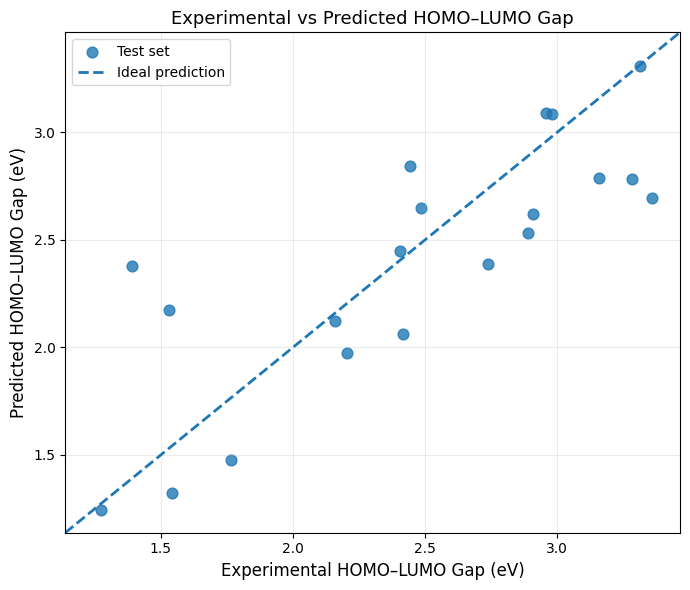

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Experimental and predicted values
y_exp = np.asarray(y_true)
y_pred_plot = np.asarray(y_pred)

# Plot limits
min_val = min(y_exp.min(), y_pred_plot.min())
max_val = max(y_exp.max(), y_pred_plot.max())

margin = 0.05 * (max_val - min_val)

lower = min_val - margin
upper = max_val + margin

# Create figure
plt.figure(figsize=(7, 6))

# Experimental vs predicted points
plt.scatter(
    y_exp,
    y_pred_plot,
    s=60,
    alpha=0.8,
    label="Test set"
)

# Ideal prediction line
plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2,
    label="Ideal prediction"
)

# Labels
plt.xlabel("Experimental HOMO–LUMO Gap (eV)", fontsize=12)
plt.ylabel("Predicted HOMO–LUMO Gap (eV)", fontsize=12)

plt.title(
    "Experimental vs Predicted HOMO–LUMO Gap",
    fontsize=13
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

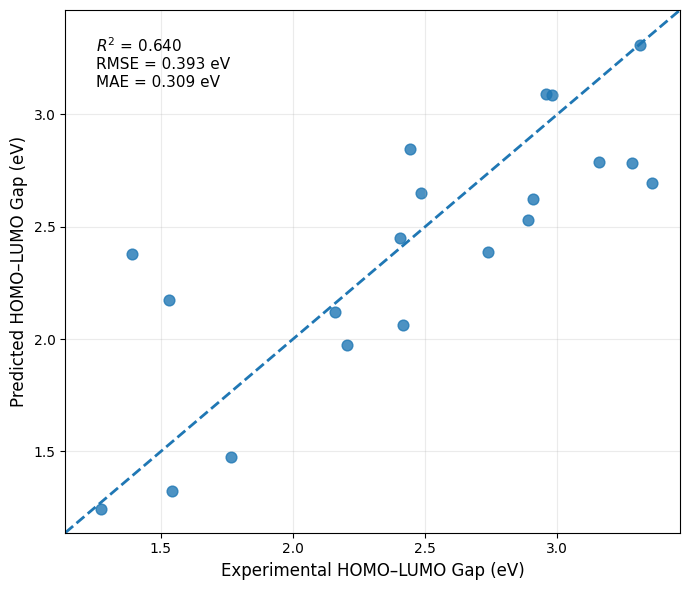

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_exp,
    y_pred_plot,
    s=60,
    alpha=0.8
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Experimental HOMO–LUMO Gap (eV)", fontsize=12)
plt.ylabel("Predicted HOMO–LUMO Gap (eV)", fontsize=12)

plt.text(
    0.05,
    0.95,
    f"$R^2$ = {r2_test:.3f}\n"
    f"RMSE = {rmse_test:.3f} eV\n"
    f"MAE = {mae_test:.3f} eV",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    fontsize=11
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

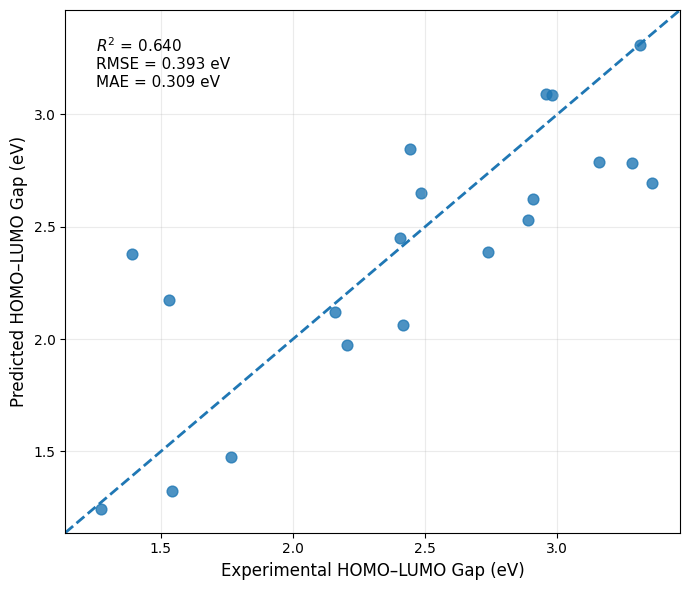

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_exp,
    y_pred_plot,
    s=60,
    alpha=0.8
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Experimental HOMO–LUMO Gap (eV)", fontsize=12)
plt.ylabel("Predicted HOMO–LUMO Gap (eV)", fontsize=12)

plt.text(
    0.05,
    0.95,
    f"$R^2$ = {r2_test:.3f}\n"
    f"RMSE = {rmse_test:.3f} eV\n"
    f"MAE = {mae_test:.3f} eV",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    fontsize=11
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
plt.savefig(
    "Experimental_vs_Predicted_HOMO_LUMO_Gap.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Experimental_vs_Predicted_HOMO_LUMO_Gap.pdf",
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

y_true shape: (20,)
y_pred shape: (20,)

First 10 experimental values:
[2.40490182 2.98045499 3.31199756 1.5436635  2.90746734 3.16009382
 2.41841851 2.73895757 1.27363135 2.89049381]

First 10 predicted values:
[2.44813134 3.08468281 3.31017797 1.32360149 2.62223948 2.7898546
 2.06385487 2.38564798 1.24398937 2.53000972]


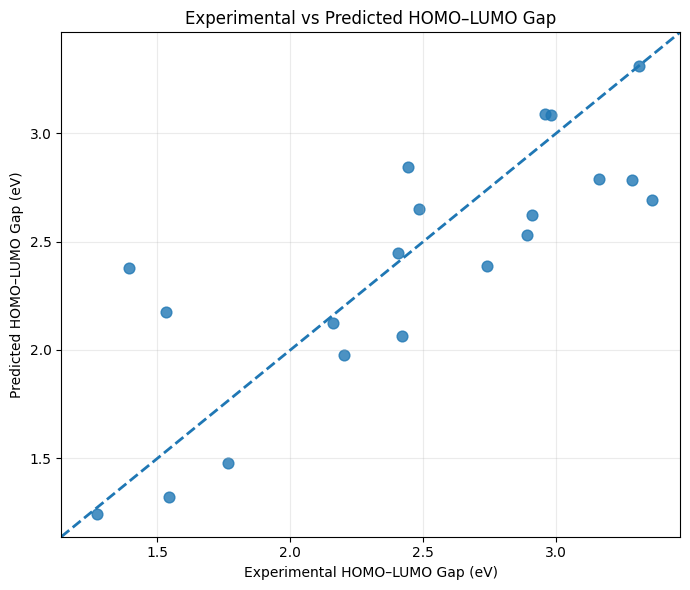

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("y_true shape:", np.asarray(y_true).shape)
print("y_pred shape:", np.asarray(y_pred).shape)

print("\nFirst 10 experimental values:")
print(np.asarray(y_true)[:10])

print("\nFirst 10 predicted values:")
print(np.asarray(y_pred)[:10])

# Create the plot
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    np.asarray(y_true),
    np.asarray(y_pred),
    s=60,
    alpha=0.8
)

# Calculate limits
all_values = np.concatenate([
    np.asarray(y_true),
    np.asarray(y_pred)
])

lo = all_values.min()
hi = all_values.max()
margin = 0.05 * (hi - lo)

# Ideal y=x line
ax.plot(
    [lo - margin, hi + margin],
    [lo - margin, hi + margin],
    "--",
    linewidth=2
)

ax.set_xlabel("Experimental HOMO–LUMO Gap (eV)")
ax.set_ylabel("Predicted HOMO–LUMO Gap (eV)")
ax.set_title("Experimental vs Predicted HOMO–LUMO Gap")

ax.set_xlim(lo - margin, hi + margin)
ax.set_ylim(lo - margin, hi + margin)

ax.grid(alpha=0.25)
plt.tight_layout()

plt.show()

RESIDUAL ANALYSIS
Mean Residual          : 0.0607 eV
Mean Absolute Residual : 0.3087 eV
Maximum Residual       : 0.9873 eV
Residual Std. Dev.     : 0.3883 eV


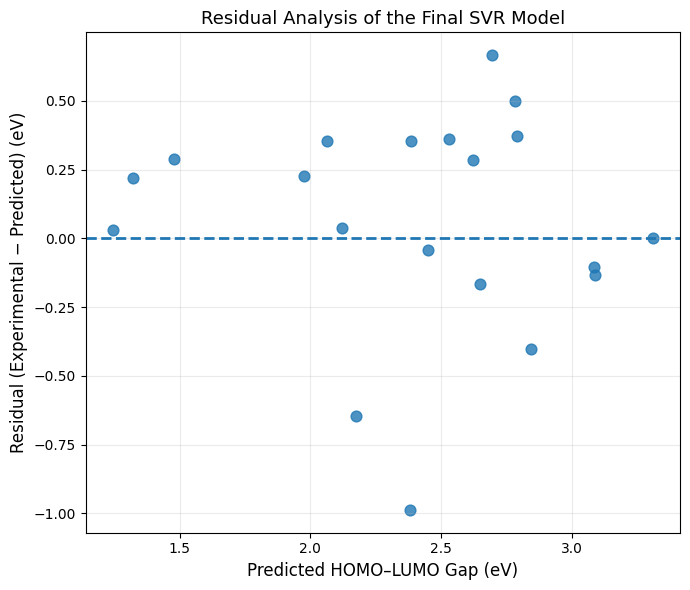

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Experimental and predicted values
y_exp = np.asarray(y_true)
y_pred_res = np.asarray(y_pred)

# Calculate residuals
residuals = y_exp - y_pred_res

print("=" * 60)
print("RESIDUAL ANALYSIS")
print("=" * 60)

print(f"Mean Residual          : {np.mean(residuals):.4f} eV")
print(f"Mean Absolute Residual : {np.mean(np.abs(residuals)):.4f} eV")
print(f"Maximum Residual       : {np.max(np.abs(residuals)):.4f} eV")
print(f"Residual Std. Dev.     : {np.std(residuals):.4f} eV")

# Residual plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_pred_res,
    residuals,
    s=60,
    alpha=0.8
)

# Zero residual reference
plt.axhline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted HOMO–LUMO Gap (eV)", fontsize=12)
plt.ylabel("Residual (Experimental − Predicted) (eV)", fontsize=12)

plt.title("Residual Analysis of the Final SVR Model", fontsize=13)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# SHAP global feature importance
# ---------------------------------------------------------

# Mean absolute SHAP value for each descriptor
mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

# Feature names
feature_names = X_test_selected_df.columns.tolist()

# Create importance table
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Sort by importance
shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 60)
print("SHAP FEATURE IMPORTANCE")
print("=" * 60)

print(shap_importance_df)

SHAP FEATURE IMPORTANCE
               Feature  Mean_Absolute_SHAP
0   HBondAcceptorCount            0.161308
1                XLogP            0.157340
2       HeavyAtomCount            0.138669
3     Heteroatom_Count            0.120585
4            Azo_Count            0.106812
5         FractionCSP3            0.098687
6            RingCount            0.093356
7   RotatableBondCount            0.090294
8         Sulfur_Count            0.074803
9    AromaticRingCount            0.041420
10                TPSA            0.031732
11      Nitrogen_Count            0.008732


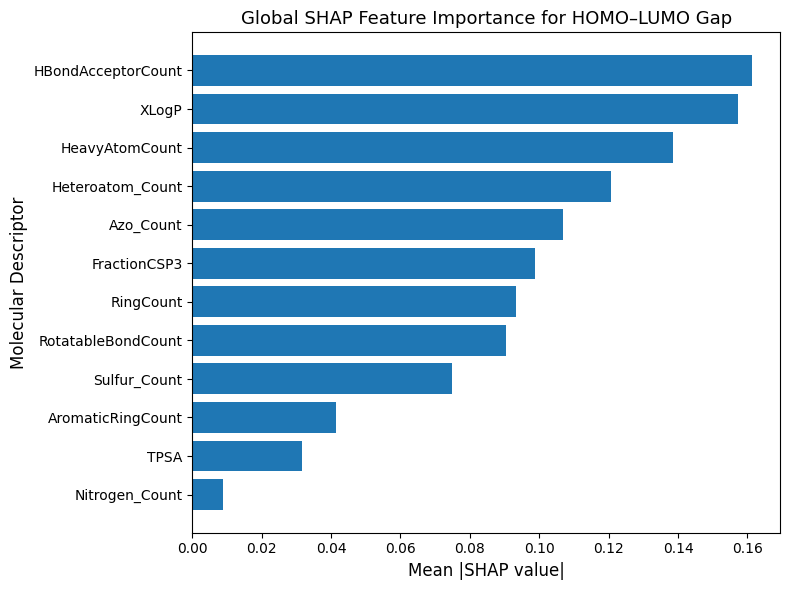

In [ ]:
plt.figure(figsize=(8, 6))

plot_df = shap_importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean |SHAP value|", fontsize=12)
plt.ylabel("Molecular Descriptor", fontsize=12)

plt.title(
    "Global SHAP Feature Importance for HOMO–LUMO Gap",
    fontsize=13
)

plt.tight_layout()
plt.show()

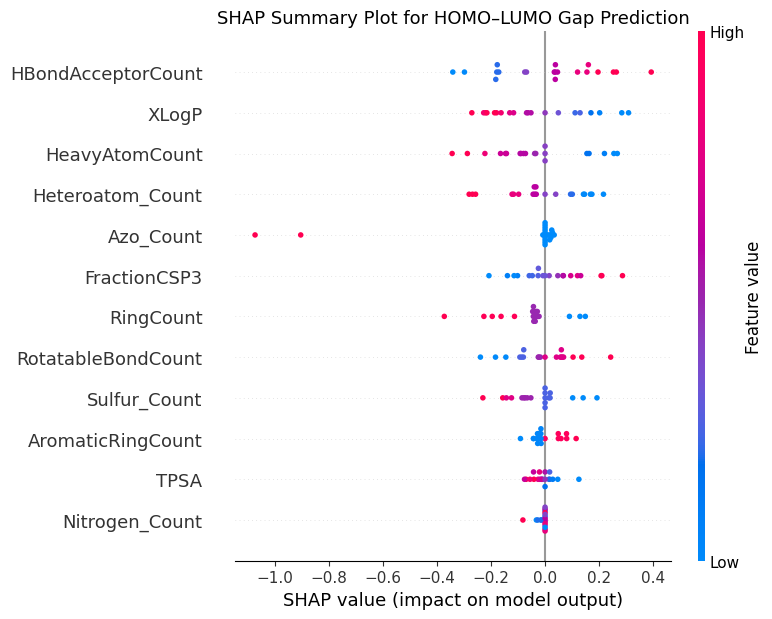

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Make sure feature names are available
feature_names = X_test_selected_df.columns.tolist()

# Convert SHAP values to DataFrame for clear feature names
shap_df = pd.DataFrame(
    shap_values,
    columns=feature_names
)

# SHAP summary / beeswarm plot
plt.figure(figsize=(9, 7))

shap.summary_plot(
    shap_values,
    X_test_selected_df,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot for HOMO–LUMO Gap Prediction",
    fontsize=13
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# FINAL MODEL PERFORMANCE TABLE
# ============================================================

import pandas as pd
import numpy as np

# Check existing model comparison
print("MODEL COMPARISON")
print("=" * 80)

display(comparison_df)

print("\nFINAL MODEL PERFORMANCE")
print("=" * 80)

display(final_performance)

MODEL COMPARISON


,Model,Train_R2,Test_R2,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE
0,SVR,0.155507,0.115441,4.247175e-01,0.471439,5.726342e-01,0.616008
1,Voting Regressor,0.885704,-0.080373,1.606059e-01,0.530324,2.106662e-01,0.680784
2,Random Forest,0.867688,-0.109991,1.757927e-01,0.515337,2.266620e-01,0.690053
3,Extra Trees,1.000000,-0.154782,9.504897e-15,0.528391,1.083350e-14,0.703838
4,Gradient Boosting,0.984345,-0.455516,6.154192e-02,0.611004,7.796613e-02,0.790189



FINAL MODEL PERFORMANCE


,Model,Feature_Count,C,Gamma,Epsilon,Test_R2,Test_RMSE_eV,Test_MAE_eV
0,Optimized RBF-SVR,12,10,0.01,0.1,0.640002,0.392982,0.308717


In [ ]:
# Create manuscript-ready final performance table

final_table = pd.DataFrame({
    "Metric": [
        "R²",
        "RMSE (eV)",
        "MAE (eV)"
    ],
    "Test Set": [
        r2_test,
        rmse_test,
        mae_test
    ],
    "Bootstrap Mean": [
        np.mean(bootstrap_r2),
        np.mean(bootstrap_rmse),
        np.mean(bootstrap_mae)
    ],
    "Bootstrap 95% CI Lower": [
        r2_ci[0],
        rmse_ci[0],
        mae_ci[0]
    ],
    "Bootstrap 95% CI Upper": [
        r2_ci[1],
        rmse_ci[1],
        mae_ci[1]
    ]
})

final_table = final_table.round(4)

display(final_table)

,Metric,Test Set,Bootstrap Mean,Bootstrap 95% CI Lower,Bootstrap 95% CI Upper
0,R²,0.6400,0.6121,0.3602,0.8167
1,RMSE (eV),0.3930,0.3889,0.2651,0.5148
2,MAE (eV),0.3087,0.3091,0.2055,0.4209


In [ ]:
print("=" * 70)
print("FINAL MODEL GENERALIZATION CHECK")
print("=" * 70)

print(f"Training R² : {train_r2:.4f}")
print(f"Test R²     : {r2_test:.4f}")

print(f"Training RMSE : {train_rmse:.4f}")
print(f"Test RMSE     : {rmse_test:.4f}")

print(f"Training MAE : {train_mae:.4f}")
print(f"Test MAE     : {mae_test:.4f}")

print("\nCross-validation:")
print(f"Mean CV R²   : {np.mean(r2_scores):.4f}")
print(f"Mean CV RMSE : {np.mean(rmse_scores):.4f}")
print(f"Mean CV MAE  : {np.mean(mae_scores):.4f}")

FINAL MODEL GENERALIZATION CHECK
Training R² : 0.8857
Test R²     : 0.6400
Training RMSE : 0.2107
Test RMSE     : 0.3930
Training MAE : 0.1606
Test MAE     : 0.3087

Cross-validation:
Mean CV R²   : 0.1042
Mean CV RMSE : 0.5436
Mean CV MAE  : 0.4240


In [ ]:
from sklearn.model_selection import RepeatedKFold, cross_validate
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Repeated 5-fold cross-validation
# ---------------------------------------------------------

cv_strategy = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

scoring = {
    "R2": "r2",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error"
}

cv_results = cross_validate(
    final_svr_pipeline,
    X_cv,
    y_cv,
    cv=cv_strategy,
    scoring=scoring,
    n_jobs=-1
)

# Convert negative sklearn scores
r2_scores = cv_results["test_R2"]
rmse_scores = -cv_results["test_RMSE"]
mae_scores = -cv_results["test_MAE"]

# Summary
repeated_cv_summary = pd.DataFrame({
    "Metric": ["R²", "RMSE (eV)", "MAE (eV)"],
    "Mean": [
        np.mean(r2_scores),
        np.mean(rmse_scores),
        np.mean(mae_scores)
    ],
    "SD": [
        np.std(r2_scores),
        np.std(rmse_scores),
        np.std(mae_scores)
    ],
    "Median": [
        np.median(r2_scores),
        np.median(rmse_scores),
        np.median(mae_scores)
    ]
})

print("=" * 70)
print("REPEATED 5-FOLD CROSS-VALIDATION")
print("=" * 70)

display(repeated_cv_summary.round(4))

REPEATED 5-FOLD CROSS-VALIDATION


,Metric,Mean,SD,Median
0,R²,0.1042,0.4283,0.1391
1,RMSE (eV),0.5436,0.1406,0.5546
2,MAE (eV),0.4240,0.1051,0.4232


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, RepeatedKFold
import numpy as np

# ---------------------------------------------------------
# SVR pipeline
# ---------------------------------------------------------

svr_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

# ---------------------------------------------------------
# Hyperparameter grid
# ---------------------------------------------------------

param_grid = {
    "svr__C": [0.1, 1, 10, 50, 100, 500],
    "svr__gamma": ["scale", 0.001, 0.01, 0.05, 0.1, 0.5],
    "svr__epsilon": [0.01, 0.05, 0.1, 0.2, 0.3]
}

# ---------------------------------------------------------
# Repeated 5-fold CV
# ---------------------------------------------------------

cv_strategy = RepeatedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

# ---------------------------------------------------------
# Grid search
# ---------------------------------------------------------

grid_search = GridSearchCV(
    estimator=svr_tuning_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_search.fit(X_cv, y_cv)

print("\n" + "=" * 70)
print("BEST SVR HYPERPARAMETERS")
print("=" * 70)

print(grid_search.best_params_)

print("\nBest CV RMSE:")
print(f"{-grid_search.best_score_:.4f} eV")

Fitting 25 folds for each of 180 candidates, totalling 4500 fits

BEST SVR HYPERPARAMETERS
{'svr__C': 10, 'svr__epsilon': 0.01, 'svr__gamma': 0.01}

Best CV RMSE:
0.5260 eV


In [ ]:
best_svr = grid_search.best_estimator_

print("\nOptimized SVR:")
print(best_svr)


Optimized SVR:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('svr', SVR(C=10, epsilon=0.01, gamma=0.01))])


In [ ]:
# ============================================================
# OPTIMIZED SVR — CORRECT TEST SET
# ============================================================

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Fit optimized SVR on the training data
best_svr.fit(X_cv, y_cv)

# Predict using the matching 12-feature test set
y_test_optimized = best_svr.predict(X_test_final)

# Calculate metrics
optimized_r2 = r2_score(y_test, y_test_optimized)

optimized_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_optimized)
)

optimized_mae = mean_absolute_error(
    y_test,
    y_test_optimized
)

print("=" * 70)
print("OPTIMIZED SVR — INDEPENDENT TEST SET")
print("=" * 70)

print(f"Test R²   : {optimized_r2:.4f}")
print(f"Test RMSE : {optimized_rmse:.4f} eV")
print(f"Test MAE  : {optimized_mae:.4f} eV")

OPTIMIZED SVR — INDEPENDENT TEST SET
Test R²   : -1.3950
Test RMSE : 1.0136 eV
Test MAE  : 0.7722 eV


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


In [ ]:
# ============================================================
# CHECK FINAL 12-DESCRIPTOR DATA
# ============================================================

print("X_test_selected_df:")
print("Shape:", X_test_selected_df.shape)

print("\n12 selected descriptors:")
for i, col in enumerate(X_test_selected_df.columns, 1):
    print(f"{i:2d}. {col}")

print("\nShapes of final arrays:")
print("X_train_final :", X_train_final.shape)
print("X_test_final  :", X_test_final.shape)
print("X_cv          :", X_cv.shape)

X_test_selected_df:
Shape: (20, 12)

12 selected descriptors:
 1. TPSA
 2. XLogP
 3. HBondAcceptorCount
 4. RotatableBondCount
 5. HeavyAtomCount
 6. RingCount
 7. AromaticRingCount
 8. FractionCSP3
 9. Nitrogen_Count
10. Sulfur_Count
11. Azo_Count
12. Heteroatom_Count

Shapes of final arrays:
X_train_final : (80, 12)
X_test_final  : (20, 12)
X_cv          : (80, 12)


In [ ]:
print("\nFirst test row from DataFrame:")
print(X_test_selected_df.iloc[0].values)

print("\nFirst test row from final array:")
print(X_test_final[0])

print("\nSame numerical values?")
print(
    np.allclose(
        X_test_selected_df.iloc[0].values,
        X_test_final[0],
        equal_nan=True
    )
)


First test row from DataFrame:
[ 0.20105296  0.86981008  0.19541279  0.6228411  -0.15298353  0.41841304
 -0.55217149 -0.86775129 -1.09573514  0.81513176 -0.24413654 -0.2054662 ]

First test row from final array:
[ 0.20105296  0.86981008  0.19541279  0.6228411  -0.15298353  0.41841304
 -0.55217149 -0.86775129 -1.09573514  0.81513176 -0.24413654 -0.2054662 ]

Same numerical values?
True


In [ ]:
print("=" * 70)
print("EXISTING FINAL SVR")
print("=" * 70)

print("\nfinal_model:")
print(final_model)

print("\nfinal_svr_pipeline:")
print(final_svr_pipeline)

print("\nbest_pipeline:")
print(best_pipeline)

print("\nsvr_pipeline:")
print(svr_pipeline)

EXISTING FINAL SVR

final_model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(k=12,
                             score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR(C=10, gamma=0.01))])

final_svr_pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', SVR(C=10, gamma=0.01))])

best_pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR())])

svr_pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function 

In [ ]:
print("\n" + "=" * 70)
print("CURRENT MODEL PREDICTIONS")
print("=" * 70)

print("y_true shape :", np.asarray(y_true).shape)
print("y_pred shape :", np.asarray(y_pred).shape)

print("\nExisting test metrics:")
print(f"R²   = {r2_test:.4f}")
print(f"RMSE = {rmse_test:.4f}")
print(f"MAE  = {mae_test:.4f}")


CURRENT MODEL PREDICTIONS
y_true shape : (20,)
y_pred shape : (20,)

Existing test metrics:
R²   = 0.6400
RMSE = 0.3930
MAE  = 0.3087


In [ ]:
print("final_model:")
print(final_model)

print("\nfinal_svr_pipeline:")
print(final_svr_pipeline)

print("\nbest_pipeline:")
print(best_pipeline)

print("\nsvr_pipeline:")
print(svr_pipeline)

final_model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(k=12,
                             score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR(C=10, gamma=0.01))])

final_svr_pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', SVR(C=10, gamma=0.01))])

best_pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function f_regression at 0x794b8b060b80>)),
                ('model', SVR())])

svr_pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('selector',
                 SelectKBest(score_func=<function f_regression at 0x79

In [ ]:
# ============================================================
# FINAL MODEL VALIDATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Fit the ORIGINAL FINAL MODEL
# ------------------------------------------------------------

final_model.fit(X_train_final, y_train)

# ------------------------------------------------------------
# 2. Predictions
# ------------------------------------------------------------

final_train_pred = final_model.predict(X_train_final)
final_test_pred = final_model.predict(X_test_final)

# ------------------------------------------------------------
# 3. Metrics
# ------------------------------------------------------------

final_train_r2 = r2_score(y_train, final_train_pred)
final_test_r2 = r2_score(y_test, final_test_pred)

final_train_rmse = np.sqrt(
    mean_squared_error(y_train, final_train_pred)
)

final_test_rmse = np.sqrt(
    mean_squared_error(y_test, final_test_pred)
)

final_train_mae = mean_absolute_error(
    y_train,
    final_train_pred
)

final_test_mae = mean_absolute_error(
    y_test,
    final_test_pred
)

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

final_performance_table = pd.DataFrame({
    "Dataset": ["Training", "Independent Test"],
    "R²": [
        final_train_r2,
        final_test_r2
    ],
    "RMSE (eV)": [
        final_train_rmse,
        final_test_rmse
    ],
    "MAE (eV)": [
        final_train_mae,
        final_test_mae
    ]
})

print("=" * 70)
print("FINAL SVR MODEL PERFORMANCE")
print("=" * 70)

display(final_performance_table.round(4))

FINAL SVR MODEL PERFORMANCE


,Dataset,R²,RMSE (eV),MAE (eV)
0,Training,0.6264,0.3809,0.2583
1,Independent Test,0.6400,0.3930,0.3087


In [ ]:
bootstrap_r2
bootstrap_rmse
bootstrap_mae
r2_ci
rmse_ci
mae_ci

array([0.20546713, 0.42092572])

In [ ]:
print("r2_ci   =", r2_ci)
print("rmse_ci =", rmse_ci)
print("mae_ci  =", mae_ci)

r2_ci   = [0.3602149  0.81674688]
rmse_ci = [0.26508812 0.51477568]
mae_ci  = [0.20546713 0.42092572]


In [ ]:
print("Final performance table:")
display(final_performance_table.round(4))

Final performance table:


,Dataset,R²,RMSE (eV),MAE (eV)
0,Training,0.6264,0.3809,0.2583
1,Independent Test,0.6400,0.3930,0.3087


In [ ]:
# ============================================================
# FINAL BOOTSTRAP VALIDATION SUMMARY
# ============================================================

import numpy as np
import pandas as pd

bootstrap_summary = pd.DataFrame({
    "Metric": [
        "R²",
        "RMSE (eV)",
        "MAE (eV)"
    ],

    "Test Set": [
        final_test_r2,
        final_test_rmse,
        final_test_mae
    ],

    "Bootstrap Mean": [
        np.mean(bootstrap_r2),
        np.mean(bootstrap_rmse),
        np.mean(bootstrap_mae)
    ],

    "Bootstrap SD": [
        np.std(bootstrap_r2, ddof=1),
        np.std(bootstrap_rmse, ddof=1),
        np.std(bootstrap_mae, ddof=1)
    ],

    "95% CI Lower": [
        r2_ci[0],
        rmse_ci[0],
        mae_ci[0]
    ],

    "95% CI Upper": [
        r2_ci[1],
        rmse_ci[1],
        mae_ci[1]
    ]
})

bootstrap_summary = bootstrap_summary.round(4)

print("=" * 80)
print("FINAL BOOTSTRAP VALIDATION SUMMARY")
print("=" * 80)

display(bootstrap_summary)

FINAL BOOTSTRAP VALIDATION SUMMARY


,Metric,Test Set,Bootstrap Mean,Bootstrap SD,95% CI Lower,95% CI Upper
0,R²,0.6400,0.6121,0.1193,0.3602,0.8167
1,RMSE (eV),0.3930,0.3889,0.0645,0.2651,0.5148
2,MAE (eV),0.3087,0.3091,0.0546,0.2055,0.4209


In [ ]:
print("\nBootstrap sample sizes:")
print("R²   :", len(bootstrap_r2))
print("RMSE :", len(bootstrap_rmse))
print("MAE  :", len(bootstrap_mae))


Bootstrap sample sizes:
R²   : 5000
RMSE : 5000
MAE  : 5000


In [ ]:
print("=" * 80)
print("BOOTSTRAP RESULTS")
print("=" * 80)

print("\nR²")
print("Mean :", np.mean(bootstrap_r2))
print("SD   :", np.std(bootstrap_r2, ddof=1))
print("95% CI:", r2_ci)

print("\nRMSE")
print("Mean :", np.mean(bootstrap_rmse))
print("SD   :", np.std(bootstrap_rmse, ddof=1))
print("95% CI:", rmse_ci)

print("\nMAE")
print("Mean :", np.mean(bootstrap_mae))
print("SD   :", np.std(bootstrap_mae, ddof=1))
print("95% CI:", mae_ci)

BOOTSTRAP RESULTS

R²
Mean : 0.6121089564670936
SD   : 0.11926704950250225
95% CI: [0.3602149  0.81674688]

RMSE
Mean : 0.3888542098042739
SD   : 0.06447909854910286
95% CI: [0.26508812 0.51477568]

MAE
Mean : 0.30905507046851605
SD   : 0.054593714400724566
95% CI: [0.20546713 0.42092572]


In [ ]:
bootstrap_summary = pd.DataFrame({
    "Metric": ["R²", "RMSE (eV)", "MAE (eV)"],
    "Test": [
        final_test_r2,
        final_test_rmse,
        final_test_mae
    ],
    "Bootstrap Mean": [
        np.mean(bootstrap_r2),
        np.mean(bootstrap_rmse),
        np.mean(bootstrap_mae)
    ],
    "95% CI Lower": [
        r2_ci[0],
        rmse_ci[0],
        mae_ci[0]
    ],
    "95% CI Upper": [
        r2_ci[1],
        rmse_ci[1],
        mae_ci[1]
    ]
})

display(bootstrap_summary.round(4))

,Metric,Test,Bootstrap Mean,95% CI Lower,95% CI Upper
0,R²,0.6400,0.6121,0.3602,0.8167
1,RMSE (eV),0.3930,0.3889,0.2651,0.5148
2,MAE (eV),0.3087,0.3091,0.2055,0.4209


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
# ============================================================
# MASTER MODEL VALIDATION TABLE
# ============================================================

master_results = pd.DataFrame({
    "Metric": [
        "R²",
        "RMSE (eV)",
        "MAE (eV)"
    ],

    "Training": [
        final_train_r2,
        final_train_rmse,
        final_train_mae
    ],

    "Independent Test": [
        final_test_r2,
        final_test_rmse,
        final_test_mae
    ],

    "Repeated CV Mean": [
        np.mean(r2_scores),
        np.mean(rmse_scores),
        np.mean(mae_scores)
    ],

    "Repeated CV SD": [
        np.std(r2_scores, ddof=1),
        np.std(rmse_scores, ddof=1),
        np.std(mae_scores, ddof=1)
    ],

    "Bootstrap Mean": [
        np.mean(bootstrap_r2),
        np.mean(bootstrap_rmse),
        np.mean(bootstrap_mae)
    ],

    "Bootstrap 95% CI": [
        f"{r2_ci[0]:.4f}–{r2_ci[1]:.4f}",
        f"{rmse_ci[0]:.4f}–{rmse_ci[1]:.4f}",
        f"{mae_ci[0]:.4f}–{mae_ci[1]:.4f}"
    ]
})

master_results = master_results.round(4)

print("=" * 100)
print("MASTER VALIDATION TABLE — FINAL SVR")
print("=" * 100)

display(master_results)

MASTER VALIDATION TABLE — FINAL SVR


,Metric,Training,Independent Test,Repeated CV Mean,Repeated CV SD,Bootstrap Mean,Bootstrap 95% CI
0,R²,0.6264,0.6400,0.1042,0.4326,0.6121,0.3602–0.8167
1,RMSE (eV),0.3809,0.3930,0.5436,0.1421,0.3889,0.2651–0.5148
2,MAE (eV),0.2583,0.3087,0.4240,0.1062,0.3091,0.2055–0.4209


In [ ]:
master_results.to_csv(
    "Final_SVR_Master_Validation_Table.csv",
    index=False
)

master_results.to_excel(
    "Final_SVR_Master_Validation_Table.xlsx",
    index=False
)

print("Files saved successfully.")

Files saved successfully.


In [ ]:
print(master_results)

      Metric  Training  Independent Test  Repeated CV Mean  Repeated CV SD  \
0         R²    0.6264            0.6400            0.1042          0.4326   
1  RMSE (eV)    0.3809            0.3930            0.5436          0.1421   
2   MAE (eV)    0.2583            0.3087            0.4240          0.1062   

   Bootstrap Mean Bootstrap 95% CI  
0          0.6121    0.3602–0.8167  
1          0.3889    0.2651–0.5148  
2          0.3091    0.2055–0.4209  


In [3]:
# ============================================================
# FIND ALL DATAFRAMES CURRENTLY IN MEMORY
# ============================================================

import pandas as pd

all_dataframes = {}

for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        all_dataframes[name] = obj

print("=" * 80)
print("ALL DATAFRAMES CURRENTLY AVAILABLE")
print("=" * 80)

for i, (name, df_temp) in enumerate(all_dataframes.items(), 1):
    print(
        f"{i:03d}. {name:35s} "
        f"Shape = {df_temp.shape}"
    )

print("\nTotal DataFrames:", len(all_dataframes))

RuntimeError: dictionary changed size during iteration

In [4]:
# ============================================================
# FIND ALL DATAFRAMES CURRENTLY IN MEMORY
# ============================================================

import pandas as pd

all_dataframes = {}

# IMPORTANT: use list() to freeze globals before iteration
for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):
        all_dataframes[name] = obj

print("=" * 80)
print("ALL DATAFRAMES CURRENTLY AVAILABLE")
print("=" * 80)

for i, (name, df_temp) in enumerate(all_dataframes.items(), 1):

    print(
        f"{i:03d}. {name:35s} "
        f"Shape = {df_temp.shape}"
    )

print("\nTotal DataFrames:", len(all_dataframes))

ALL DATAFRAMES CURRENTLY AVAILABLE

Total DataFrames: 0


In [5]:
import os

print("Files in /content:")
for f in os.listdir("/content"):
    print(f)

Files in /content:
.config
Manuscript_All_Tables.xlsx
sample_data


In [6]:
import pandas as pd

file_path = "/content/Manuscript_All_Tables.xlsx"

excel_file = pd.ExcelFile(file_path)

print("=" * 80)
print("TABLES AVAILABLE IN Manuscript_All_Tables.xlsx")
print("=" * 80)

for i, sheet in enumerate(excel_file.sheet_names, 1):
    print(f"{i:02d}. {sheet}")

print("\nTotal sheets:", len(excel_file.sheet_names))

OptionError: No such keys(s): 'io.excel.zip.reader'

In [7]:
# ============================================================
# READ MANUSCRIPT EXCEL WORKBOOK
# ============================================================

from openpyxl import load_workbook

file_path = "/content/Manuscript_All_Tables.xlsx"

wb = load_workbook(
    file_path,
    read_only=True,
    data_only=True
)

print("=" * 80)
print("MANUSCRIPT TABLES AVAILABLE")
print("=" * 80)

for i, sheet in enumerate(wb.sheetnames, 1):
    ws = wb[sheet]

    print(
        f"{i:02d}. {sheet:35s} "
        f"Rows = {ws.max_row}, "
        f"Columns = {ws.max_column}"
    )

print("\nTotal sheets:", len(wb.sheetnames))

KeyError: "There is no item named '[Content_Types].xml' in the archive"

In [8]:
import os

file_path = "/content/Manuscript_All_Tables.xlsx"

print("Exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("Size:", os.path.getsize(file_path), "bytes")

Exists: True
Size: 3279 bytes


In [9]:
!file /content/Manuscript_All_Tables.xlsx

/content/Manuscript_All_Tables.xlsx: Microsoft Excel 2007+


In [10]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".ipynb"):
            print(os.path.join(root, f))

In [11]:
import os

file_path = "/content/Manuscript_All_Tables.xlsx"

print("File size:", os.path.getsize(file_path), "bytes")

File size: 3279 bytes


In [12]:
!unzip -l /content/Manuscript_All_Tables.xlsx | head -30

Archive:  /content/Manuscript_All_Tables.xlsx
  Length      Date    Time    Name
---------  ---------- -----   ----
      205  2026-08-17 03:34   docProps/app.xml
      555  2026-08-17 03:34   docProps/core.xml
    10140  2026-08-17 03:34   xl/theme/theme1.xml
     2550  2026-08-17 03:34   xl/styles.xml
      531  2026-08-17 03:34   _rels/.rels
---------                     -------
    13981                     5 files


In [13]:
import os

print("Notebook files:")
found = False

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".ipynb"):
            print(os.path.join(root, f))
            found = True

if not found:
    print("No .ipynb file found in /content")

Notebook files:
No .ipynb file found in /content
